# Signal from Liquidations: memory-safe EDA pipeline (Polars + DuckDB + NumPy)


1. The raw parquet files are never loaded whole: DuckDB streams them once into per-day shards.
2. Every later step holds **one UTC day** in RAM; across days only 1-second grids and small accumulators survive.
3. Compute in float64/int64 (µs); row-level outputs stored as float32. Checkpoints let a restart resume.

Profiles: `LIQ_PROFILE=fast|balanced|lowmem` trades wall time against peak RAM; the stage timings and peak RSS are saved to `runtime_profile.csv`.

Stages: A shard -> B audit (Q1) -> C return statistics -> D liquidations/cascades (Q3) -> E markout (Q2) -> F turnover (Q4).

## Background used throughout (from the original EDA notebook)
**Maker / taker mapping.** The trade `side` is the *taker's* action. If the taker buys, we (the hypothetical maker) sold; if the taker sells, we bought. The maker earns a rebate of +0.5 bps and loses when the price moves against the inventory it just took on (adverse selection / toxic flow).

**Markout (maker PnL, bps).** `pnl = -taker_sign * (mid(t+tau) - price) / price * 1e4 + 0.5`, `tau` in {30, 120, 300} s, `mid` = forward-filled Binance BBO mid at or before `t+tau`; weight `w = min(price * amount, 100,000)`. Example: taker buys at 90,000, 30 s later the mid is 90,180 -> the maker sold too cheaply: -20 bps + 0.5.

**How the datasets work together.** Binance and Bybit liquidations -> causal rolling features before each Binance trade (sell/buy liquidation notional in the last 1 s / 5 s / 30 s, event counts, buy-vs-sell imbalance, Binance and Bybit both active; Bybit usable only from `timestamp + 200 ms`) -> predict whether the trade is toxic -> keep or filter it -> score with the future Binance BBO mid. The constraint: kept clipped turnover >= 500,000 USD per day, so the filter cannot simply reject everything.

**Liquidations and cascades.** With leverage L a move of 1/L against the position wipes out the collateral, and the exchange closes the position by force (a `sell` liquidation closes a long and pushes the price down; a `buy` liquidation closes a short and pushes it up). A *cascade* is the feedback loop: forced orders move the price, which triggers further liquidations on the same side. Detection here uses time-clustering (stage D) and, as a simple baseline from the original EDA, same-side bursts of >= 3 events and >= 100,000 USD with no gap above 1 s (stage D6).

**What this notebook adds from the original EDA** (stage markers in the headings): B0 raw per-file profile of all eight files, B6 liquidation price sanity against a fresh quote, D6 baseline cascade definition with side/size/duration tables, F0 turnover guardrail, and R a reconciliation table that compares the numbers reported in the EDA with this full-data run.

In [1]:
import os, sys, gc, glob, json, math, time, shutil, tarfile, pickle, warnings, datetime as dt
from pathlib import Path
import numpy as np
import polars as pl
import duckdb
import pyarrow.parquet as pq
from scipy import stats as sps

warnings.filterwarnings("ignore")
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(220)

ON_KAGGLE = Path("/kaggle").exists()
def _pick(env, kaggle, local): return Path(os.environ.get(env, kaggle if ON_KAGGLE else local))
WORK = _pick("LIQ_WORK", "/kaggle/working", "./out")
TMP = _pick("LIQ_TMP", "/kaggle/temp", "./tmp")          # large + disposable: shards and row-level markouts
for p in (WORK, TMP): p.mkdir(parents=True, exist_ok=True)
FIGS = WORK / "figs"; FIGS.mkdir(exist_ok=True)
CK = WORK / "ckpt"; CK.mkdir(exist_ok=True)

# Execution-time / RAM trade-off. Pick with env LIQ_PROFILE (fast | balanced | lowmem); any explicit LIQ_* variable still overrides it.
PROFILES = {"fast": dict(DUCK_MEM="8GB", THREADS=4, TRADE_CHUNK=4_000_000, FIT_N=60_000),          # ~16 GB RAM machine, minimum wall time
            "balanced": dict(DUCK_MEM="5GB", THREADS=4, TRADE_CHUNK=2_000_000, FIT_N=120_000),       # Kaggle CPU (4 cores, ~29 GB) default
            "lowmem": dict(DUCK_MEM="2GB", THREADS=2, TRADE_CHUNK=500_000, FIT_N=50_000)}            # <= 8 GB RAM
PROFILE_NAME = os.environ.get("LIQ_PROFILE", "balanced"); PRF = PROFILES[PROFILE_NAME]
_T0 = time.time(); _TL = [time.time()]; STAGE_LOG = []
def mark(name):
    """record wall time and peak RSS of the stage that just finished (written to runtime_profile.csv at the end)"""
    import resource
    pk = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e6 if sys.platform != "darwin" else 1e9); now = time.time()
    STAGE_LOG.append(dict(stage=name, seconds=round(now - _TL[0], 1), peak_rss_gb=round(pk, 2))); _TL[0] = now; print(f"[stage {name}] {STAGE_LOG[-1]['seconds']}s peak_rss={pk:.2f}GB", flush=True)

CFG = dict(
    SYMS=["btcusdt", "ethusdt"], TAUS=[30, 120, 300],
    BYBIT_SHIFT_US=200_000,                    # spec: Bybit usable no earlier than +200 ms
    REBATE_BPS=0.5, W_CLIP=100_000.0, MIN_TURNOVER=500_000.0,
    TRAIN=("2025-12-01", "2026-01-31"), VAL=("2026-02-01", "2026-02-28"),
    GAP_S=5, STALE_S=5, BAD_LIQ_BPS=300,
    CASCADE_G_CANDIDATES=[1, 2, 5, 10, 30, 60], CASCADE_KMIN=5, CASCADE_ONESIDED=0.6, CASCADE_POIS_LOGP=-13.8,
    CASCADE_POST_S=60, STATE_WINDOWS_S=[10, 60], STATE_Q=0.95,
    TRADE_CHUNK=int(os.environ.get("LIQ_TRADE_CHUNK", PRF["TRADE_CHUNK"])), FIT_N=int(os.environ.get("LIQ_FIT_N", PRF["FIT_N"])),
    DUCK_MEM=os.environ.get("LIQ_DUCK_MEM", PRF["DUCK_MEM"]), THREADS=int(os.environ.get("LIQ_THREADS", PRF["THREADS"])),
)
US = 1_000_000; DAY_US = 86_400 * US
PAD_US = (max(CFG["TAUS"]) + 5) * US
SYMS, TAUS = CFG["SYMS"], CFG["TAUS"]

def date_of_day(d): return dt.date(1970, 1, 1) + dt.timedelta(days=int(d))
def day_of_date(s): return (dt.date.fromisoformat(s) - dt.date(1970, 1, 1)).days
def split_of_day(d):
    if day_of_date(CFG["TRAIN"][0]) <= d <= day_of_date(CFG["TRAIN"][1]): return "train"
    if day_of_date(CFG["VAL"][0]) <= d <= day_of_date(CFG["VAL"][1]): return "val"
    return "other"
def log(*a): print(time.strftime("%H:%M:%S"), *a, flush=True)
def mem_gb():
    import psutil; return psutil.Process().memory_info().rss / 1e9

## A1. Locate the data (Kaggle auto-extracted folder **or** the raw 5.78 GB tar)

In [2]:
def extract_tar(tar_path, dest):
    dest.mkdir(parents=True, exist_ok=True)
    with tarfile.open(tar_path, "r|*") as tf:               # streaming: never loads the tar in RAM
        for m in tf:
            if m.isfile() and m.name.endswith(".parquet"): tf.extract(m, dest)
    return dest

def find_data_root():
    env = os.environ.get("LIQ_DATA")
    if env: return Path(env)
    hits = glob.glob("/kaggle/input/**/liquidation_task/data", recursive=True)
    if hits: return Path(hits[0])
    tars = glob.glob("/kaggle/input/**/*.tar*", recursive=True)
    if tars:
        log("extracting", tars[0]); dest = extract_tar(tars[0], TMP / "raw")
        h = glob.glob(str(dest / "**/data"), recursive=True); return Path(h[0]) if h else dest
    raise FileNotFoundError("No data found: set LIQ_DATA=/path/to/liquidation_task/data")

ROOT = find_data_root()
def P(kind, sym):
    return {"trades": ROOT / "binance_trades" / f"perp_{sym}.parquet", "bbo": ROOT / "binance_booktickers" / f"perp_{sym}.parquet",
            "liq_bn": ROOT / "binance_liquidations" / f"perp_{sym}.parquet", "liq_by": ROOT / "bybit_liquidations" / f"{sym}.parquet"}[kind]
log("data root:", ROOT)

08:34:15 data root: /kaggle/input/datasets/sumalya32/kft-mrkdwn/liquidation_task/data


## A2. Inventory from parquet **metadata only** + categorical checks

In [3]:
def inventory():
    rows = []
    for p in sorted(ROOT.rglob("*.parquet")):
        pf = pq.ParquetFile(p); md = pf.metadata; names = pf.schema_arrow.names; i = names.index("timestamp"); mins, maxs = [], []
        for g in range(md.num_row_groups):
            st = md.row_group(g).column(i).statistics
            if st is not None and st.has_min_max: mins.append(st.min); maxs.append(st.max)
        rows.append(dict(file=str(p.relative_to(ROOT)), rows=md.num_rows, row_groups=md.num_row_groups, mb=round(p.stat().st_size / 1e6, 1),
                         ts_min=min(mins) if mins else None, ts_max=max(maxs) if maxs else None,
                         rowgroups_ordered=all(mins[k + 1] >= maxs[k] for k in range(len(mins) - 1)) if mins else None, columns=",".join(names)))
    return pl.DataFrame(rows)
INV = inventory(); print(INV.drop("columns"))
assert INV["ts_min"].min() > 1.4e15 and INV["ts_max"].max() < 2.1e15, "timestamps are not int64 microseconds!"
def _rng(sym):
    r = INV.filter(pl.col("file").str.contains(f"booktickers/perp_{sym}"))
    return int(r["ts_min"][0]), int(r["ts_max"][0])
BBO_RANGE = {s: _rng(s) for s in SYMS}          # spec: trades with t+tau outside [first, last] BBO ts are excluded
print({s: (date_of_day(a // DAY_US), date_of_day(b // DAY_US)) for s, (a, b) in BBO_RANGE.items()})

def duck(threads=None):
    con = duckdb.connect(); con.execute(f"SET memory_limit='{CFG['DUCK_MEM']}'"); con.execute(f"SET threads={threads or CFG['THREADS']}")
    (TMP / "duck").mkdir(exist_ok=True); con.execute(f"SET temp_directory='{TMP / 'duck'}'"); return con

con = duck()
for sym in SYMS:
    for k in ("trades", "liq_bn", "liq_by"):
        print(k, sym, "side:", con.execute(f"SELECT side, count(*) FROM read_parquet('{P(k, sym)}') GROUP BY 1 ORDER BY 2 DESC").fetchall(),
              "| ticker:", con.execute(f"SELECT ticker, count(*) FROM read_parquet('{P(k, sym)}') GROUP BY 1").fetchall())
con.close()

shape: (8, 7)
┌─────────────────────────────────┬───────────┬────────────┬────────┬──────────────────┬──────────────────┬───────────────────┐
│ file                            ┆ rows      ┆ row_groups ┆ mb     ┆ ts_min           ┆ ts_max           ┆ rowgroups_ordered │
│ ---                             ┆ ---       ┆ ---        ┆ ---    ┆ ---              ┆ ---              ┆ ---               │
│ str                             ┆ i64       ┆ i64        ┆ f64    ┆ i64              ┆ i64              ┆ bool              │
╞═════════════════════════════════╪═══════════╪════════════╪════════╪══════════════════╪══════════════════╪═══════════════════╡
│ binance_booktickers/perp_btcus… ┆ 99169477  ┆ 155        ┆ 796.6  ┆ 1764547202075000 ┆ 1772323199949000 ┆ true              │
│ binance_booktickers/perp_ethus… ┆ 107797036 ┆ 163        ┆ 1249.3 ┆ 1764547200683000 ┆ 1772323199829000 ┆ true              │
│ binance_liquidations/perp_btcu… ┆ 114255    ┆ 90         ┆ 1.4    ┆ 1764547206091000 ┆ 1

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

trades btcusdt side: [('sell', 201538407), ('buy', 200364106)] | ticker: [('perp:btcusdt', 401902513)]
liq_bn btcusdt side: [('sell', 64209), ('buy', 50046)] | ticker: [('perp:btcusdt', 114255)]
liq_by btcusdt side: [('sell', 153798), ('buy', 74857)] | ticker: [('btcusdt', 228655)]


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

trades ethusdt side: [('sell', 353473661), ('buy', 352406724)] | ticker: [('perp:ethusdt', 705880385)]
liq_bn ethusdt side: [('sell', 73474), ('buy', 58295)] | ticker: [('perp:ethusdt', 131769)]
liq_by ethusdt side: [('sell', 112667), ('buy', 47547)] | ticker: [('ethusdt', 160214)]


## A3. One streaming pass: raw parquet -> per-day shards
DuckDB's partitioned writer may shuffle rows inside a partition, so `file_row_number` (`frn`) is stored and the exact feed
order is restored on read. Any timestamp reversal left after that is a property of the raw data and is reported.

In [4]:
def shard_all(force=False):
    con = duck(threads=2)   # 2 threads: measured in the pilot (about 8 min for all four files, peak RSS about the DuckDB cap)
    for sym in SYMS:
        for kind in ("trades", "bbo"):
            out = TMP / "shards" / kind / sym
            if out.exists() and any(out.rglob("*.parquet")) and not force: continue
            shutil.rmtree(out, ignore_errors=True); out.mkdir(parents=True)
            sel = ("timestamp, CASE WHEN side='buy' THEN 1 WHEN side='sell' THEN -1 ELSE 0 END::TINYINT AS s, price, amount" if kind == "trades"
                   else "timestamp, bid_price, bid_amount, ask_price, ask_amount")
            t0 = time.time()
            con.execute(f"""COPY (SELECT file_row_number::BIGINT AS frn, {sel}, (timestamp // {DAY_US})::INTEGER AS day
                                  FROM read_parquet('{P(kind, sym)}', file_row_number=true))
                            TO '{out}' (FORMAT PARQUET, PARTITION_BY (day), COMPRESSION ZSTD, ROW_GROUP_SIZE 500000, OVERWRITE_OR_IGNORE)""")
            log(f"sharded {kind}:{sym} in {time.time() - t0:.0f}s")
    con.close()
shard_all()

def shard_index(kind, sym):
    return {int(d.name.split("=")[1]): sorted(str(f) for f in d.glob("*.parquet")) for d in sorted((TMP / "shards" / kind / sym).glob("day=*"))}
SHARDS = {(k, s): shard_index(k, s) for k in ("trades", "bbo") for s in SYMS}
DAYS = {s: sorted(set(SHARDS[("bbo", s)]) | set(SHARDS[("trades", s)])) for s in SYMS}
D0 = min(min(v) for v in DAYS.values()); D1 = max(max(v) for v in DAYS.values()); NDAYS_RANGE = D1 - D0 + 1
print("days:", {s: len(v) for s, v in DAYS.items()}, "| span", date_of_day(D0), "->", date_of_day(D1))

UNSORTED = []
def read_day(kind, sym, day, cols=None):
    files = SHARDS[(kind, sym)].get(day)
    if not files: return None
    df = pl.concat([pl.read_parquet(f) for f in files]) if len(files) > 1 else pl.read_parquet(files[0])
    df = df.sort("frn").drop("frn")
    if not df["timestamp"].is_sorted():
        UNSORTED.append((kind, sym, day, int((df["timestamp"].diff().drop_nulls() < 0).sum()))); df = df.sort("timestamp", maintain_order=True)
    return df.select(cols) if cols else df
mark("A shard+inventory")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

08:36:26 sharded trades:btcusdt in 114s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

08:37:24 sharded bbo:btcusdt in 58s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

08:42:30 sharded trades:ethusdt in 307s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

08:43:31 sharded bbo:ethusdt in 60s
days: {'btcusdt': 90, 'ethusdt': 90} | span 2025-12-01 -> 2026-02-28
[stage A shard+inventory] 557.4s peak_rss=2.17GB


## B0. Raw per-file profile of all eight files (streaming, Polars)
For every raw file, in Arrow batches of 2 M rows (RAM ~ one batch): rows, nulls, non-finite and non-positive values, empty / crossed / locked quotes (BBO), backward timestamp steps (count, median and maximum size in ms), repeated timestamps, gaps above 1 s, and the longest gap with its start and end. This covers the **liquidation** files too, which the per-day audit (B1-B5) does not. The Bybit shift of +200 ms is much larger than the backward steps, so a stable sort removes their effect. Set `LIQ_RAW_PROFILE=0` to skip (about 2-4 minutes on the full data).

In [5]:
def profile_file(name, path, gap_s=1.0, batch_rows=2_000_000):
    """EDA.ipynb `profile_parquet`, re-implemented with Arrow batches -> Polars. State carried across batches: last timestamp only."""
    pf = pq.ParquetFile(path); cols = pf.schema_arrow.names
    num = [c for c in cols if c not in ("timestamp", "ticker", "side")]; has_q = {"bid_price", "ask_price"} <= set(cols)
    r = dict(file=name, rows=pf.metadata.num_rows, nulls=0, non_finite=0, non_positive=0, empty_bbo=0, crossed_bbo=0, locked_bbo=0,
             out_of_order=0, same_timestamp=0, gaps_over_1s=0, max_gap_s=0.0, gap_start=None, gap_end=None)
    back_ms, prev, gap_us = [], None, int(gap_s * US)
    for rb in pf.iter_batches(batch_size=batch_rows, columns=cols):
        df = pl.from_arrow(rb)
        r["nulls"] += int(sum(df.null_count().row(0)))
        r["non_finite"] += int(df.select([(~pl.col(c).cast(pl.Float64).is_finite()).sum() for c in num]).sum_horizontal()[0])
        r["non_positive"] += int(df.select([(pl.col(c) <= 0).sum() for c in num]).sum_horizontal()[0])
        if has_q:
            r["empty_bbo"] += int(df.select(((pl.col("bid_price") <= 0) | (pl.col("ask_price") <= 0)).sum()).item())
            fin = pl.col("bid_price").is_finite() & pl.col("ask_price").is_finite()
            r["crossed_bbo"] += int(df.select(((pl.col("bid_price") > pl.col("ask_price")) & fin).sum()).item())
            r["locked_bbo"] += int(df.select(((pl.col("bid_price") == pl.col("ask_price")) & fin).sum()).item())
        ts = df["timestamp"]; last = ts[-1]
        if prev is not None: ts = pl.concat([pl.Series("timestamp", [prev], dtype=ts.dtype), ts])
        d = ts.diff().drop_nulls(); prev = last
        if d.len() == 0: continue
        neg = d.filter(d < 0); r["out_of_order"] += neg.len()
        if len(back_ms) < 2_000_000: back_ms.extend((-neg / 1000.0).to_list())
        r["same_timestamp"] += int((d == 0).sum()); r["gaps_over_1s"] += int((d > gap_us).sum())
        if d.max() > r["max_gap_s"] * US:
            i = int(d.arg_max()); end = int(ts[i + 1]); r["max_gap_s"] = float(d[i]) / US
            r["gap_start"] = dt.datetime.fromtimestamp((end - int(d[i])) / US, dt.timezone.utc).replace(tzinfo=None).isoformat(sep=" ")
            r["gap_end"] = dt.datetime.fromtimestamp(end / US, dt.timezone.utc).replace(tzinfo=None).isoformat(sep=" ")
    r["median_backstep_ms"] = float(np.median(back_ms)) if back_ms else 0.0; r["max_backstep_ms"] = float(max(back_ms)) if back_ms else 0.0
    r["order_reading"] = ("ordered" if r["out_of_order"] == 0 else f"{r['out_of_order']} backward steps (max {r['max_backstep_ms']:.0f} ms): stable-sort; far below the 200 ms Bybit shift" if name.startswith("liq_by")
                          else f"{r['out_of_order']} backward steps (max {r['max_backstep_ms']:.0f} ms): stable-sort")
    r["gap_reading"] = ("sparse event stream: a long gap only means no forced liquidations (market feature)" if name.startswith("liq") else "see B3: Poisson and cross-stream test decides market feature vs feed outage")
    return r

RAWPROF_CSV = CK / "raw_file_profile.csv"
if os.environ.get("LIQ_RAW_PROFILE", "1") == "1":
    if RAWPROF_CSV.exists(): RAWPROF = pl.read_csv(RAWPROF_CSV)
    else:
        RAWPROF = pl.DataFrame([profile_file(f"{k}_{s}", P(k, s)) for s in SYMS for k in ("trades", "bbo", "liq_bn", "liq_by")]); RAWPROF.write_csv(RAWPROF_CSV)
    RAWPROF.write_csv(WORK / "raw_file_profile.csv")
    print(RAWPROF.select("file", "rows", "nulls", "non_finite", "non_positive", "empty_bbo", "crossed_bbo", "locked_bbo", "out_of_order", "median_backstep_ms", "max_backstep_ms", "same_timestamp", "gaps_over_1s", "max_gap_s", "gap_start", "gap_end"))
    print(RAWPROF.select("file", "order_reading"))
else:
    RAWPROF = None; print("raw per-file profile skipped (LIQ_RAW_PROFILE=0)")
mark("B0 raw profile")

shape: (8, 16)
┌──────────────┬───────────┬───────┬────────────┬──────────────┬───────────┬─────────────┬────────────┬──────────────┬──────────────┬──────────────┬──────────────┬──────────────┬───────────┬──────────────┬──────────────┐
│ file         ┆ rows      ┆ nulls ┆ non_finite ┆ non_positive ┆ empty_bbo ┆ crossed_bbo ┆ locked_bbo ┆ out_of_order ┆ median_backs ┆ max_backstep ┆ same_timesta ┆ gaps_over_1s ┆ max_gap_s ┆ gap_start    ┆ gap_end      │
│ ---          ┆ ---       ┆ ---   ┆ ---        ┆ ---          ┆ ---       ┆ ---         ┆ ---        ┆ ---          ┆ tep_ms       ┆ _ms          ┆ mp           ┆ ---          ┆ ---       ┆ ---          ┆ ---          │
│ str          ┆ i64       ┆ i64   ┆ i64        ┆ i64          ┆ i64       ┆ i64         ┆ i64        ┆ i64          ┆ ---          ┆ ---          ┆ ---          ┆ i64          ┆ f64       ┆ str          ┆ str          │
│              ┆           ┆       ┆            ┆              ┆           ┆             ┆           

# B. Data-quality audit (Q1): NaNs, empty books, gaps, anomalies, "market feature or data issue?"
One pass, one day in RAM at a time. Verdict logic (explicit and testable):
* **Structural impossibilities** (crossed/locked/zero-size/NaN/non-positive quotes) = data issue by construction.
* **Gaps**: Poisson test vs the hour-of-week rate, plus cross-stream/cross-symbol checks (trades flowing while quotes are
  silent is impossible; all streams and both symbols silent = collector outage).
* **Spikes / wide spreads / jumps**: anomaly rate per quote in the 5 % most volatile minutes vs the rest.
  Lift near 1 => unrelated to market state (data issue); lift >> 1 => stress related (market feature).

In [6]:
def ctx_concat(Q, prev, which):
    ts, mid = [Q[f"ts_{which}"]], [Q[f"mid_{which}"]]
    if prev is not None and len(prev[f"ts_{which}"]): ts.insert(0, prev[f"ts_{which}"][-1:]); mid.insert(0, prev[f"mid_{which}"][-1:])
    return np.concatenate(ts), np.concatenate(mid)

def load_quotes(sym, day):
    df = read_day("bbo", sym, day)
    if df is None: return None
    nulls = int(sum(df.null_count().row(0)))
    ts, bid, ask = df["timestamp"].to_numpy(), df["bid_price"].to_numpy(), df["ask_price"].to_numpy()
    ba, aa = df["bid_amount"].to_numpy(), df["ask_amount"].to_numpy(); del df
    fin = np.isfinite(bid) & np.isfinite(ask); pos = fin & (bid > 0) & (ask > 0)
    valid = pos & (bid < ask) & (ba > 0) & (aa > 0)
    Q = dict(day=day, n=len(ts), ts_cl=ts[valid], mid_cl=0.5 * (bid[valid] + ask[valid]))
    d0 = day * DAY_US; spr = (ask[valid] - bid[valid]) / Q["mid_cl"] * 1e4
    med = float(np.median(spr)) if len(spr) else np.nan; wide = spr > 5 * med
    _m = Q["mid_cl"]; lr = (_m[1:] / _m[:-1] - 1.0) * 1e4; a_, b_ = lr[:-1], lr[1:]
    spike = (np.abs(a_) > 10) & (np.abs(b_) > 10) & (a_ * b_ < 0) & (np.abs(a_ + b_) < 0.3 * np.maximum(np.abs(a_), np.abs(b_)))
    dd = np.diff(ts); dup = (dd == 0) & (bid[1:] == bid[:-1]) & (ask[1:] == ask[:-1]) & (ba[1:] == ba[:-1]) & (aa[1:] == aa[:-1])
    q = lambda x, p: float(np.quantile(x, p)) if len(x) else np.nan
    with np.errstate(invalid="ignore"):
        Q["stats"] = dict(sym=sym, day=day, n=len(ts), nulls=nulls, nan_px=int((np.isnan(bid) | np.isnan(ask)).sum()),
            nonpos_px=int((fin & ((bid <= 0) | (ask <= 0))).sum()), zero_size=int((pos & ~((ba > 0) & (aa > 0))).sum()),
            crossed=int((pos & (bid > ask)).sum()), locked=int((pos & (bid == ask)).sum()), invalid_total=int((~valid).sum()),
            ts_ties=int((dd == 0).sum()), adj_exact_dups=int(dup.sum()), spread_p50=med, spread_p99=q(spr, .99), spread_max=float(spr.max()) if len(spr) else np.nan,
            wide_5x=int(wide.sum()), jump_gt10bps=int((np.abs(lr) > 10).sum()), jump_gt50bps=int((np.abs(lr) > 50).sum()), spikes=int(spike.sum()),
            max_jump_bps=float(np.abs(lr).max()) if len(lr) else np.nan)
    m = lambda t: np.bincount(np.clip((t - d0) // (60 * US), 0, 1439).astype(np.int64), minlength=1440)
    Q["minute"] = dict(n_q=m(ts), n_inval=m(ts[~valid]), n_wide=m(Q["ts_cl"][wide]), n_jump=m(Q["ts_cl"][1:][np.abs(lr) > 10]), n_spike=m(Q["ts_cl"][1:-1][spike]))
    Q["counts_1s"] = np.bincount(np.clip((ts - d0) // US, 0, 86399).astype(np.int64), minlength=86400).astype(np.uint32)
    hb = np.searchsorted(Q["ts_cl"], d0 + np.arange(25) * 3600 * US)
    Q["hour_spread"] = np.array([np.median(spr[hb[h]:hb[h + 1]]) if hb[h + 1] > hb[h] else np.nan for h in range(24)]); Q["hour_nq"] = np.diff(hb)
    return Q

def grid_from_quotes(Q, prev):
    """1-second grid: last CLEAN mid at/before each second (carried across midnight) and its age in seconds."""
    ts, mid = ctx_concat(Q, prev, "cl"); g = Q["day"] * DAY_US + np.arange(86400, dtype=np.int64) * US
    i = np.searchsorted(ts, g, "right") - 1; ok = i >= 0; ii = np.where(ok, i, 0)
    return np.where(ok, mid[ii], np.nan), np.where(ok, np.minimum((g - ts[ii]) // US, 65535), 65535).astype(np.uint16)

def audit_trades_day(sym, day, Q, prev):
    df = read_day("trades", sym, day)
    if df is None: return None
    nulls = int(sum(df.null_count().row(0)))
    ts, s, px, am = df["timestamp"].to_numpy(), df["s"].to_numpy(), df["price"].to_numpy(), df["amount"].to_numpy(); del df
    ok = np.isfinite(px) & np.isfinite(am) & (px > 0) & (am > 0); notional = np.where(ok, px * am, 0.0); w = np.minimum(notional, CFG["W_CLIP"])
    dd = np.diff(ts); dup = (dd == 0) & (px[1:] == px[:-1]) & (am[1:] == am[:-1]) & (s[1:] == s[:-1])
    dev = np.full(len(ts), np.nan)
    if Q is not None:
        cts, cmid = ctx_concat(Q, prev, "cl"); i = np.searchsorted(cts, ts, "right") - 1; has = i >= 0
        dev = np.where(has, (px - cmid[np.maximum(i, 0)]) / cmid[np.maximum(i, 0)] * 1e4, np.nan)
    ad = np.abs(dev); buy, sell = (s == 1) & np.isfinite(dev), (s == -1) & np.isfinite(dev); d0 = day * DAY_US
    nq = lambda x, p: float(np.nanquantile(x, p)) if np.isfinite(x).any() else np.nan
    st = dict(sym=sym, day=day, n=len(ts), nulls=nulls, nonpos_px=int((~ok).sum()), bad_side=int((s == 0).sum()), ts_ties=int((dd == 0).sum()), adj_exact_dups=int(dup.sum()),
              notional_p50=float(np.median(notional[ok])) if ok.any() else np.nan, notional_p99=float(np.quantile(notional[ok], .99)) if ok.any() else np.nan,
              notional_max=float(notional.max()) if len(ts) else np.nan, clipped_share_trades=float((notional > CFG["W_CLIP"]).mean()) if len(ts) else np.nan,
              turnover_clipped=float(w.sum()), turnover_raw=float(notional.sum()), dev_abs_p50=nq(ad, .5), dev_abs_p999=nq(ad, .999),
              dev_gt20bps=int((ad > 20).sum()), dev_gt100bps=int((ad > 100).sum()),
              buy_at_or_above_mid=float((dev[buy] >= 0).mean()) if buy.any() else np.nan, sell_at_or_below_mid=float((dev[sell] <= 0).mean()) if sell.any() else np.nan)
    counts = np.bincount(np.clip((ts - d0) // US, 0, 86399).astype(np.int64), minlength=86400).astype(np.uint32)
    mn = np.bincount(np.clip((ts - d0) // (60 * US), 0, 1439).astype(np.int64), minlength=1440)
    r = (px[ok][1:] / px[ok][:-1] - 1.0) if ok.sum() > 2 else np.array([])
    rs = dict(n=len(r), sx=float(r.sum()), sxx=float((r * r).sum()), sxy=float((r[1:] * r[:-1]).sum()) if len(r) > 1 else 0.0)
    return dict(stats=st, counts_1s=counts, minute_n=mn, tick_ret=rs)

In [7]:
def pass1(sym, force=False):
    ck = CK / f"pass1_{sym}.pkl"
    if ck.exists() and not force: return pickle.load(open(ck, "rb"))
    R = dict(bbo=[], trd=[], minute=[], hour=[], q_counts={}, t_counts={}, grid_mid={}, grid_age={}, tick=[]); prev = None
    for k, d in enumerate(DAYS[sym]):
        t0 = time.time(); Q = load_quotes(sym, d); absret = np.full(1440, np.nan)
        if Q is not None:
            R["bbo"].append(Q["stats"]); R["q_counts"][d] = Q["counts_1s"]; gm, ga = grid_from_quotes(Q, prev); R["grid_mid"][d], R["grid_age"][d] = gm, ga
            g60 = gm[::60]; absret[1:] = np.abs(np.diff(g60)) / g60[1:] * 1e4
        T = audit_trades_day(sym, d, Q, prev)
        if T is not None: R["trd"].append(T["stats"]); R["t_counts"][d] = T["counts_1s"]; R["tick"].append((d, T["tick_ret"]))
        if Q is not None:
            R["minute"].append(pl.DataFrame(dict(sym=sym, day=d, minute=np.arange(1440), absret_bps=absret, n_tr=T["minute_n"] if T else np.zeros(1440, int), **Q["minute"])))
            R["hour"].append(pl.DataFrame(dict(sym=sym, day=d, hour=np.arange(24), spread_med_bps=Q["hour_spread"], n_q=Q["hour_nq"])))
            prev = dict(ts_cl=Q["ts_cl"][-1:].copy(), mid_cl=Q["mid_cl"][-1:].copy())
        del Q, T; gc.collect(); log(f"[pass1 {sym}] {date_of_day(d)} ({k + 1}/{len(DAYS[sym])}) {time.time() - t0:.1f}s rss={mem_gb():.2f}GB")
    pickle.dump(R, open(ck, "wb"), protocol=4); return R
P1 = {s: pass1(s) for s in SYMS}

08:45:38 [pass1 btcusdt] 2025-12-01 (1/90) 2.9s rss=1.85GB
08:45:40 [pass1 btcusdt] 2025-12-02 (2/90) 2.0s rss=1.88GB
08:45:42 [pass1 btcusdt] 2025-12-03 (3/90) 2.0s rss=1.89GB
08:45:43 [pass1 btcusdt] 2025-12-04 (4/90) 1.6s rss=1.90GB
08:45:45 [pass1 btcusdt] 2025-12-05 (5/90) 1.8s rss=1.90GB
08:45:46 [pass1 btcusdt] 2025-12-06 (6/90) 0.8s rss=1.97GB
08:45:47 [pass1 btcusdt] 2025-12-07 (7/90) 1.2s rss=2.07GB
08:45:49 [pass1 btcusdt] 2025-12-08 (8/90) 1.4s rss=2.08GB
08:45:50 [pass1 btcusdt] 2025-12-09 (9/90) 1.7s rss=2.09GB
08:45:52 [pass1 btcusdt] 2025-12-10 (10/90) 1.7s rss=2.15GB
08:45:54 [pass1 btcusdt] 2025-12-11 (11/90) 1.8s rss=2.16GB
08:45:55 [pass1 btcusdt] 2025-12-12 (12/90) 1.3s rss=2.16GB
08:45:56 [pass1 btcusdt] 2025-12-13 (13/90) 0.6s rss=2.15GB
08:45:57 [pass1 btcusdt] 2025-12-14 (14/90) 0.9s rss=2.16GB
08:45:58 [pass1 btcusdt] 2025-12-15 (15/90) 1.8s rss=2.17GB
08:46:00 [pass1 btcusdt] 2025-12-16 (16/90) 1.5s rss=2.17GB
08:46:02 [pass1 btcusdt] 2025-12-17 (17/90) 2.1s 

## B1. Global 1-second series (tiny: ~7.8 M points per stream for 90 days)

In [8]:
def assemble(dct, dtype, fill, n=86400):
    out = np.full(NDAYS_RANGE * n, fill, dtype=dtype)
    for d, a in dct.items(): out[(d - D0) * n:(d - D0 + 1) * n] = a
    return out
T0_GRID = D0 * DAY_US
GRID = {s: dict(mid=assemble(P1[s]["grid_mid"], np.float64, np.nan), age=assemble(P1[s]["grid_age"], np.uint16, 65535)) for s in SYMS}
CNT = {s: dict(bbo=assemble(P1[s]["q_counts"], np.uint32, 0), trd=assemble(P1[s]["t_counts"], np.uint32, 0)) for s in SYMS}
def mid_at(sym, t_us, max_age_s=None):
    k = np.clip((t_us - T0_GRID) // US, 0, len(GRID[sym]["mid"]) - 1).astype(np.int64); m = GRID[sym]["mid"][k].copy()
    if max_age_s is not None: m[GRID[sym]["age"][k] > max_age_s] = np.nan
    return m

## B2. NaN / empty-book / structural anomalies

In [9]:
BBO_A = pl.DataFrame([r for s in SYMS for r in P1[s]["bbo"]]); TRD_A = pl.DataFrame([r for s in SYMS for r in P1[s]["trd"]])
BBO_A.write_csv(WORK / "audit_bbo_by_day.csv"); TRD_A.write_csv(WORK / "audit_trades_by_day.csv")
cols = ["n", "nulls", "nan_px", "nonpos_px", "zero_size", "crossed", "locked", "invalid_total", "ts_ties", "adj_exact_dups", "wide_5x", "jump_gt10bps", "jump_gt50bps", "spikes"]
bbo_sum = BBO_A.group_by("sym").agg([pl.col(c).sum() for c in cols] + [pl.col("spread_p50").median().alias("spread_p50_med"), pl.col("spread_p99").max().alias("spread_p99_max"), pl.col("max_jump_bps").max()]).sort("sym")
print("BBO quality (totals):"); print(bbo_sum)
print("BBO invalid share of rows:", {r["sym"]: f'{r["invalid_total"] / r["n"]:.2e}' for r in bbo_sum.iter_rows(named=True)})
tcols = ["n", "nulls", "nonpos_px", "bad_side", "ts_ties", "adj_exact_dups", "dev_gt20bps", "dev_gt100bps"]
print("\nTrades quality:"); print(TRD_A.group_by("sym").agg([pl.col(c).sum() for c in tcols] + [pl.col("buy_at_or_above_mid").mean(), pl.col("sell_at_or_below_mid").mean(), pl.col("clipped_share_trades").mean(), pl.col("dev_abs_p999").max()]).sort("sym"))
print("Side check: taker BUYS should print at/above mid and SELLS at/below (>0.8 expected). About 0.5 = wrong side flag or timing.")
print("Days whose SOURCE timestamps go backwards (kind, sym, day, n_reversals):", UNSORTED[:10])
print("\nPer-day rows (look for days far below the median):")
print(BBO_A.select("sym", "day", "n").join(TRD_A.select("sym", "day", pl.col("n").alias("n_trades")), on=["sym", "day"], how="full", coalesce=True).sort("sym", "day").head(12))

BBO quality (totals):
shape: (2, 18)
┌─────────┬───────────┬───────┬────────┬───────────┬───────────┬─────────┬────────┬───────────────┬─────────┬───────────────┬─────────┬──────────────┬──────────────┬────────┬───────────────┬──────────────┬──────────────┐
│ sym     ┆ n         ┆ nulls ┆ nan_px ┆ nonpos_px ┆ zero_size ┆ crossed ┆ locked ┆ invalid_total ┆ ts_ties ┆ adj_exact_dup ┆ wide_5x ┆ jump_gt10bps ┆ jump_gt50bps ┆ spikes ┆ spread_p50_me ┆ spread_p99_m ┆ max_jump_bps │
│ ---     ┆ ---       ┆ ---   ┆ ---    ┆ ---       ┆ ---       ┆ ---     ┆ ---    ┆ ---           ┆ ---     ┆ s             ┆ ---     ┆ ---          ┆ ---          ┆ ---    ┆ d             ┆ ax           ┆ ---          │
│ str     ┆ i64       ┆ i64   ┆ i64    ┆ i64       ┆ i64       ┆ i64     ┆ i64    ┆ i64           ┆ i64     ┆ ---           ┆ i64     ┆ i64          ┆ i64          ┆ i64    ┆ ---           ┆ ---          ┆ f64          │
│         ┆           ┆       ┆        ┆           ┆           ┆         ┆     

## B3. Time gaps: Poisson test + cross-stream / cross-symbol classification

In [10]:
def silence_runs(c, thr):
    z = np.concatenate([[0], (c == 0).astype(np.int8), [0]]); d = np.diff(z); st, en = np.where(d == 1)[0], np.where(d == -1)[0]; k = (en - st) >= thr
    return st[k], en[k]
def hour_of_week_rate(c, mask):
    how = ((np.arange(len(c)) // 3600) + (D0 + 3) % 7 * 24) % 168; ok = ~mask       # epoch day 0 was a Thursday
    return np.where(np.bincount(how[ok], minlength=168) > 0, np.bincount(how[ok], weights=c[ok], minlength=168) / np.maximum(np.bincount(how[ok], minlength=168), 1), 0.0), how
GAP_LOGP = -20.7
gap_rows = []
for s in SYMS:
    o = SYMS[1] if s == SYMS[0] else SYMS[0]
    csum = {k: np.concatenate([[0], np.cumsum(v, dtype=np.int64)]) for k, v in {"bbo": CNT[s]["bbo"], "trd": CNT[s]["trd"], "o_bbo": CNT[o]["bbo"], "o_trd": CNT[o]["trd"]}.items()}
    for stream in ("bbo", "trd"):
        c = CNT[s][stream]; st, en = silence_runs(c, CFG["GAP_S"]); mask = np.zeros(len(c), bool)
        for a, b in zip(st, en): mask[a:b] = True
        lam, how = hour_of_week_rate(c, mask)
        for a, b in zip(st, en):
            g = b - a; lam_run = float(lam[how[a:b]].mean()); logp = -lam_run * g
            tr_in, bb_in = int(csum["trd"][b] - csum["trd"][a]), int(csum["bbo"][b] - csum["bbo"][a]); o_in = int(csum["o_bbo"][b] - csum["o_bbo"][a]) + int(csum["o_trd"][b] - csum["o_trd"][a])
            if stream == "bbo":
                v = ("DATA ISSUE: quotes missing while trades flow" if tr_in > 0 else "DATA ISSUE: collector/feed outage (both symbols silent)" if o_in == 0 else
                     "likely DATA ISSUE: statistically implausible quiet" if logp < GAP_LOGP else "market feature: quiet period")
            else:
                v = ("DATA ISSUE: collector/feed outage (all streams silent)" if (bb_in == 0 and o_in == 0) else "likely DATA ISSUE: trade feed silent while quotes update" if logp < GAP_LOGP else "market feature: quiet period")
            gap_rows.append(dict(sym=s, stream=stream, start=dt.datetime.fromtimestamp((T0_GRID // US) + int(a), dt.timezone.utc).replace(tzinfo=None), dur_s=int(g), exp_rate_per_s=lam_run, ln_p_quiet=logp,
                                 n_trades_inside=tr_in, n_quotes_inside=bb_in, other_symbol_events=o_in, verdict=v))
GAPS = pl.DataFrame(gap_rows) if gap_rows else pl.DataFrame(schema=dict(sym=pl.String, stream=pl.String, dur_s=pl.Int64, verdict=pl.String))
GAPS.write_csv(WORK / "gaps_classified.csv")
print(f"silence runs >= {CFG['GAP_S']}s:"); print(GAPS.group_by("sym", "stream", "verdict").agg(pl.len().alias("n_gaps"), pl.col("dur_s").sum().alias("total_s"), pl.col("dur_s").max().alias("longest_s")).sort("sym", "stream", "verdict"))
print("Longest gaps:"); print(GAPS.sort("dur_s", descending=True).head(10).select("sym", "stream", "start", "dur_s", "ln_p_quiet", "n_trades_inside", "n_quotes_inside", "verdict"))

silence runs >= 5s:
shape: (10, 6)
┌─────────┬────────┬─────────────────────────────────┬────────┬─────────┬───────────┐
│ sym     ┆ stream ┆ verdict                         ┆ n_gaps ┆ total_s ┆ longest_s │
│ ---     ┆ ---    ┆ ---                             ┆ ---    ┆ ---     ┆ ---       │
│ str     ┆ str    ┆ str                             ┆ u32    ┆ i64     ┆ i64       │
╞═════════╪════════╪═════════════════════════════════╪════════╪═════════╪═══════════╡
│ btcusdt ┆ bbo    ┆ DATA ISSUE: collector/feed out… ┆ 2      ┆ 53      ┆ 45        │
│ btcusdt ┆ bbo    ┆ DATA ISSUE: quotes missing whi… ┆ 9      ┆ 678     ┆ 198       │
│ btcusdt ┆ bbo    ┆ likely DATA ISSUE: statistical… ┆ 1      ┆ 13      ┆ 13        │
│ btcusdt ┆ trd    ┆ DATA ISSUE: collector/feed out… ┆ 2      ┆ 53      ┆ 45        │
│ btcusdt ┆ trd    ┆ likely DATA ISSUE: trade feed … ┆ 793    ┆ 4513    ┆ 38        │
│ ethusdt ┆ bbo    ┆ DATA ISSUE: collector/feed out… ┆ 2      ┆ 54      ┆ 45        │
│ ethusdt ┆ bbo    

## B4. Anomaly vs market state

In [11]:
MIN = pl.concat([r for s in SYMS for r in P1[s]["minute"]])
def lift_table(MIN):
    rows = []
    for s in SYMS:
        m = MIN.filter((pl.col("sym") == s) & pl.col("absret_bps").is_not_null() & pl.col("absret_bps").is_not_nan())
        thr = float(m["absret_bps"].quantile(0.95)); hi, lo = m.filter(pl.col("absret_bps") >= thr), m.filter(pl.col("absret_bps") < thr)
        for a in ["n_inval", "n_wide", "n_jump", "n_spike"]:
            rh = hi[a].sum() / max(hi["n_q"].sum(), 1); rl = lo[a].sum() / max(lo["n_q"].sum(), 1)
            rho = sps.spearmanr((m[a] / m["n_q"].clip(lower_bound=1)).to_numpy(), m["absret_bps"].to_numpy())[0] if m[a].sum() > 20 else np.nan
            rows.append(dict(sym=s, anomaly=a, total=int(m[a].sum()), rate_hi_vol=float(rh), rate_normal=float(rl), lift=float(rh / rl) if rl > 0 else np.nan, spearman_rate_vs_absret=float(rho),
                             reading=("unrelated to market state -> DATA ISSUE" if (np.isfinite(rho) and abs(rho) < 0.05 and (rl == 0 or rh / rl < 2)) else "tied to volatility -> MARKET FEATURE (or stress-induced noise)" if m[a].sum() > 20 else "too few to judge")))
    return pl.DataFrame(rows)
LIFT = lift_table(MIN); print(LIFT); LIFT.write_csv(WORK / "anomaly_vs_volatility.csv")

shape: (8, 8)
┌─────────┬─────────┬────────┬─────────────┬─────────────┬───────────┬─────────────────────────┬─────────────────────────────────┐
│ sym     ┆ anomaly ┆ total  ┆ rate_hi_vol ┆ rate_normal ┆ lift      ┆ spearman_rate_vs_absret ┆ reading                         │
│ ---     ┆ ---     ┆ ---    ┆ ---         ┆ ---         ┆ ---       ┆ ---                     ┆ ---                             │
│ str     ┆ str     ┆ i64    ┆ f64         ┆ f64         ┆ f64       ┆ f64                     ┆ str                             │
╞═════════╪═════════╪════════╪═════════════╪═════════════╪═══════════╪═════════════════════════╪═════════════════════════════════╡
│ btcusdt ┆ n_inval ┆ 0      ┆ 0.0         ┆ 0.0         ┆ NaN       ┆ NaN                     ┆ too few to judge                │
│ btcusdt ┆ n_wide  ┆ 570741 ┆ 0.024453    ┆ 0.00438     ┆ 5.582691  ┆ 0.38177                 ┆ tied to volatility -> MARKET F… │
│ btcusdt ┆ n_jump  ┆ 863    ┆ 0.000045    ┆ 0.000006    ┆ 7.444769  

## B5. Verdict table

In [12]:
def verdict_table():
    rows = []; tot_q = {r["sym"]: r["n"] for r in bbo_sum.iter_rows(named=True)}
    for r in bbo_sum.iter_rows(named=True):
        for k, why in [("nulls", "null in a quote field"), ("nan_px", "NaN price"), ("nonpos_px", "price <= 0"), ("zero_size", "empty side (size <= 0)"), ("crossed", "bid > ask"), ("locked", "bid == ask")]:
            rows.append(dict(sym=r["sym"], item=k, count=r[k], share=r[k] / tot_q[r["sym"]], verdict="DATA ISSUE" if r[k] else "none", reason=f"{why}: impossible for a continuous-matching top of book"))
    for s in SYMS:
        g = GAPS.filter(pl.col("sym") == s)
        for v in (g["verdict"].unique().to_list() if g.height else []):
            gv = g.filter(pl.col("verdict") == v); rows.append(dict(sym=s, item="gap", count=gv.height, share=float(gv["dur_s"].sum() / (NDAYS_RANGE * 86400)), verdict=v, reason="Poisson/cross-stream test (B3)"))
    for r in LIFT.iter_rows(named=True):
        rows.append(dict(sym=r["sym"], item=r["anomaly"], count=r["total"], share=np.nan, verdict=r["reading"], reason=f"lift={r['lift']:.2f}, spearman={r['spearman_rate_vs_absret']:.3f}"))
    return pl.DataFrame(rows)
VERDICT = verdict_table(); VERDICT.write_csv(WORK / "verdict_market_vs_data.csv"); print(VERDICT)
mark("B audit")

shape: (30, 6)
┌─────────┬───────────┬────────┬──────────┬─────────────────────────────────┬─────────────────────────────────┐
│ sym     ┆ item      ┆ count  ┆ share    ┆ verdict                         ┆ reason                          │
│ ---     ┆ ---       ┆ ---    ┆ ---      ┆ ---                             ┆ ---                             │
│ str     ┆ str       ┆ i64    ┆ f64      ┆ str                             ┆ str                             │
╞═════════╪═══════════╪════════╪══════════╪═════════════════════════════════╪═════════════════════════════════╡
│ btcusdt ┆ nulls     ┆ 0      ┆ 0.0      ┆ none                            ┆ null in a quote field: impossi… │
│ btcusdt ┆ nan_px    ┆ 0      ┆ 0.0      ┆ none                            ┆ NaN price: impossible for a co… │
│ btcusdt ┆ nonpos_px ┆ 0      ┆ 0.0      ┆ none                            ┆ price <= 0: impossible for a c… │
│ btcusdt ┆ zero_size ┆ 0      ┆ 0.0      ┆ none                            ┆ empty side 

# C. Return statistics
Returns are measured on a **regular 1-second mid grid** (last clean quote, stale quotes -> NaN) so quiet and active periods are
weighted by clock time (all returns are **simple returns** R = P_t/P_{t-h} - 1, in bps) and no return spans midnight or a gap. Longer horizons are non-overlapping sub-samples of the same grid.

In [13]:
import matplotlib
try:
    get_ipython(); IN_NB = True
except NameError:
    IN_NB = False; matplotlib.use("Agg")
import matplotlib.pyplot as plt
def show(fig, name):
    fig.savefig(FIGS / name, dpi=110, bbox_inches="tight"); plt.show() if IN_NB else plt.close(fig)

HORIZONS = [1, 5, 10, 30, 60, 300]
def mid_matrix(sym):
    mid = GRID[sym]["mid"].copy(); mid[GRID[sym]["age"] > CFG["STALE_S"]] = np.nan; return mid.reshape(NDAYS_RANGE, 86400)
MM = {s: mid_matrix(s) for s in SYMS}
def ret_matrix(sym, h):
    X = MM[sym][:, ::h]; return (X[:, 1:] / X[:, :-1] - 1.0) * 1e4          # SIMPLE return P_t/P_{t-h} - 1, in bps

def acf_2d(r, nlags):
    rc = r - np.nanmean(r); var = np.nanmean(rc ** 2); out = []
    for k in range(1, nlags + 1):
        a, b = rc[:, :-k], rc[:, k:]; ok = np.isfinite(a) & np.isfinite(b); out.append((a[ok] * b[ok]).sum() / max(ok.sum(), 1) / var if var > 0 else np.nan)
    return np.array(out)
def hill(x_abs, frac):
    x = np.sort(x_abs[x_abs > 0])[::-1]; k = max(int(len(x) * frac), 20)
    return float(k / np.sum(np.log(x[:k] / x[k]))) if len(x) > k + 1 else np.nan

def ret_stats(sym, h):
    R = ret_matrix(sym, h); x = R[np.isfinite(R)]
    if len(x) < 100: return None
    n = len(x); a1, a1s, a2 = acf_2d(R, 10), acf_2d(np.abs(R), 10), acf_2d(R ** 2, 10)
    lb = lambda a: float(n * (n + 2) * np.sum(a ** 2 / (n - np.arange(1, len(a) + 1))))
    return dict(sym=sym, h_s=h, n=n, mean_bps=float(x.mean()), std_bps=float(x.std()), vol_ann_pct=float(x.std() / 1e4 * np.sqrt(365 * 86400 / h) * 100),
                skew=float(sps.skew(x)), ex_kurt=float(sps.kurtosis(x)), jb_p=float(sps.jarque_bera(x).pvalue), min_bps=float(x.min()), q001=float(np.quantile(x, .001)),
                q999=float(np.quantile(x, .999)), max_bps=float(x.max()), hill_alpha_1pct=hill(np.abs(x), .01), acf1=float(a1[0]), acf1_abs=float(a1s[0]), acf10_abs=float(a1s[9]),
                ljung_box10_r_p=float(sps.chi2.sf(lb(a1), 10)), ljung_box10_r2_p=float(sps.chi2.sf(lb(a2), 10)))
RS = pl.DataFrame([r for s in SYMS for h in HORIZONS if (r := ret_stats(s, h)) is not None]); RS.write_csv(WORK / "return_stats.csv")
print("Return statistics (bps). ex_kurt >> 0 = fat tails; hill_alpha < 4 = infinite kurtosis; acf1_abs > 0 = volatility clustering")
print(RS.select("sym", "h_s", "n", "mean_bps", "std_bps", "vol_ann_pct", "skew", "ex_kurt", "jb_p", "hill_alpha_1pct", "acf1", "acf1_abs", "acf10_abs", "ljung_box10_r2_p"))

Return statistics (bps). ex_kurt >> 0 = fat tails; hill_alpha < 4 = infinite kurtosis; acf1_abs > 0 = volatility clustering
shape: (12, 14)
┌─────────┬─────┬─────────┬───────────┬───────────┬─────────────┬───────────┬────────────┬──────┬─────────────────┬───────────┬──────────┬───────────┬──────────────────┐
│ sym     ┆ h_s ┆ n       ┆ mean_bps  ┆ std_bps   ┆ vol_ann_pct ┆ skew      ┆ ex_kurt    ┆ jb_p ┆ hill_alpha_1pct ┆ acf1      ┆ acf1_abs ┆ acf10_abs ┆ ljung_box10_r2_p │
│ ---     ┆ --- ┆ ---     ┆ ---       ┆ ---       ┆ ---         ┆ ---       ┆ ---        ┆ ---  ┆ ---             ┆ ---       ┆ ---      ┆ ---       ┆ ---              │
│ str     ┆ i64 ┆ i64     ┆ f64       ┆ f64       ┆ f64         ┆ f64       ┆ f64        ┆ f64  ┆ f64             ┆ f64       ┆ f64      ┆ f64       ┆ f64              │
╞═════════╪═════╪═════════╪═══════════╪═══════════╪═════════════╪═══════════╪════════════╪══════╪═════════════════╪═══════════╪══════════╪═══════════╪══════════════════╡
│ btcusdt 

In [14]:
rows = []
for s in SYMS:
    v1 = float(RS.filter((pl.col("sym") == s) & (pl.col("h_s") == 1))["std_bps"][0]) ** 2
    for h in HORIZONS[1:]:
        st = RS.filter((pl.col("sym") == s) & (pl.col("h_s") == h))
        if st.height: rows.append(dict(sym=s, h_s=h, variance_ratio_vs_1s=float(st["std_bps"][0]) ** 2 / (h * v1)))
print("Variance ratio VR(h)=Var(r_h)/(h Var(r_1s)): 1 random walk, <1 mean reversion/noise, >1 momentum"); print(pl.DataFrame(rows))
if len(SYMS) == 2:
    cr = []
    for h in HORIZONS:
        a, b = ret_matrix(SYMS[0], h).ravel(), ret_matrix(SYMS[1], h).ravel(); ok = np.isfinite(a) & np.isfinite(b); cr.append(dict(h_s=h, corr=float(np.corrcoef(a[ok], b[ok])[0, 1]), n=int(ok.sum())))
    print("\nCross-asset correlation by horizon (rises with horizon = Epps effect)"); print(pl.DataFrame(cr))
tick = []
for s in SYMS:
    n = sum(t["n"] for _, t in P1[s]["tick"]); sx = sum(t["sx"] for _, t in P1[s]["tick"]); sxx = sum(t["sxx"] for _, t in P1[s]["tick"]); sxy = sum(t["sxy"] for _, t in P1[s]["tick"]); mu = sx / max(n, 1)
    tick.append(dict(sym=s, n=n, lag1_autocorr_trade_by_trade=(sxy / n - mu ** 2) / (sxx / n - mu ** 2) if n else np.nan))
print("\nTrade-by-trade lag-1 autocorrelation (negative = bid-ask bounce)"); print(pl.DataFrame(tick))

Variance ratio VR(h)=Var(r_h)/(h Var(r_1s)): 1 random walk, <1 mean reversion/noise, >1 momentum
shape: (10, 3)
┌─────────┬─────┬──────────────────────┐
│ sym     ┆ h_s ┆ variance_ratio_vs_1s │
│ ---     ┆ --- ┆ ---                  │
│ str     ┆ i64 ┆ f64                  │
╞═════════╪═════╪══════════════════════╡
│ btcusdt ┆ 5   ┆ 1.179627             │
│ btcusdt ┆ 10  ┆ 1.24706              │
│ btcusdt ┆ 30  ┆ 1.281548             │
│ btcusdt ┆ 60  ┆ 1.305912             │
│ btcusdt ┆ 300 ┆ 1.235616             │
│ ethusdt ┆ 5   ┆ 1.110822             │
│ ethusdt ┆ 10  ┆ 1.13659              │
│ ethusdt ┆ 30  ┆ 1.119042             │
│ ethusdt ┆ 60  ┆ 1.12471              │
│ ethusdt ┆ 300 ┆ 1.034241             │
└─────────┴─────┴──────────────────────┘

Cross-asset correlation by horizon (rises with horizon = Epps effect)
shape: (6, 3)
┌─────┬──────────┬─────────┐
│ h_s ┆ corr     ┆ n       │
│ --- ┆ ---      ┆ ---     │
│ i64 ┆ f64      ┆ i64     │
╞═════╪══════════╪═════════╡
│ 

btcusdt: daily vol % mean=2.20 min=0.44 max=6.77
ethusdt: daily vol % mean=3.24 min=0.71 max=9.50


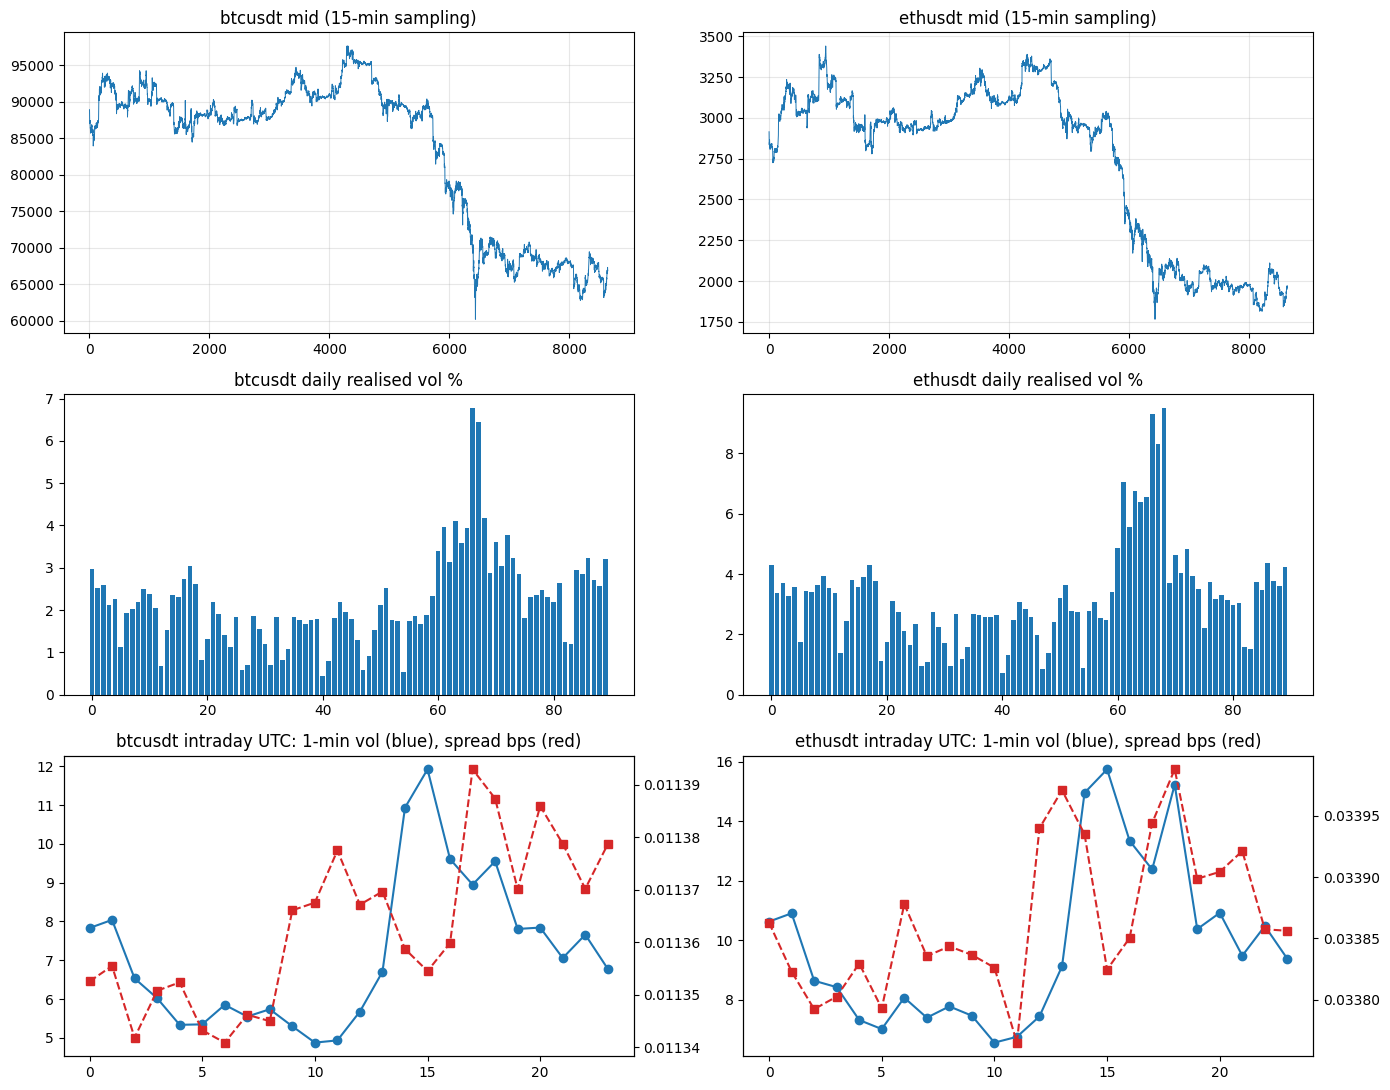

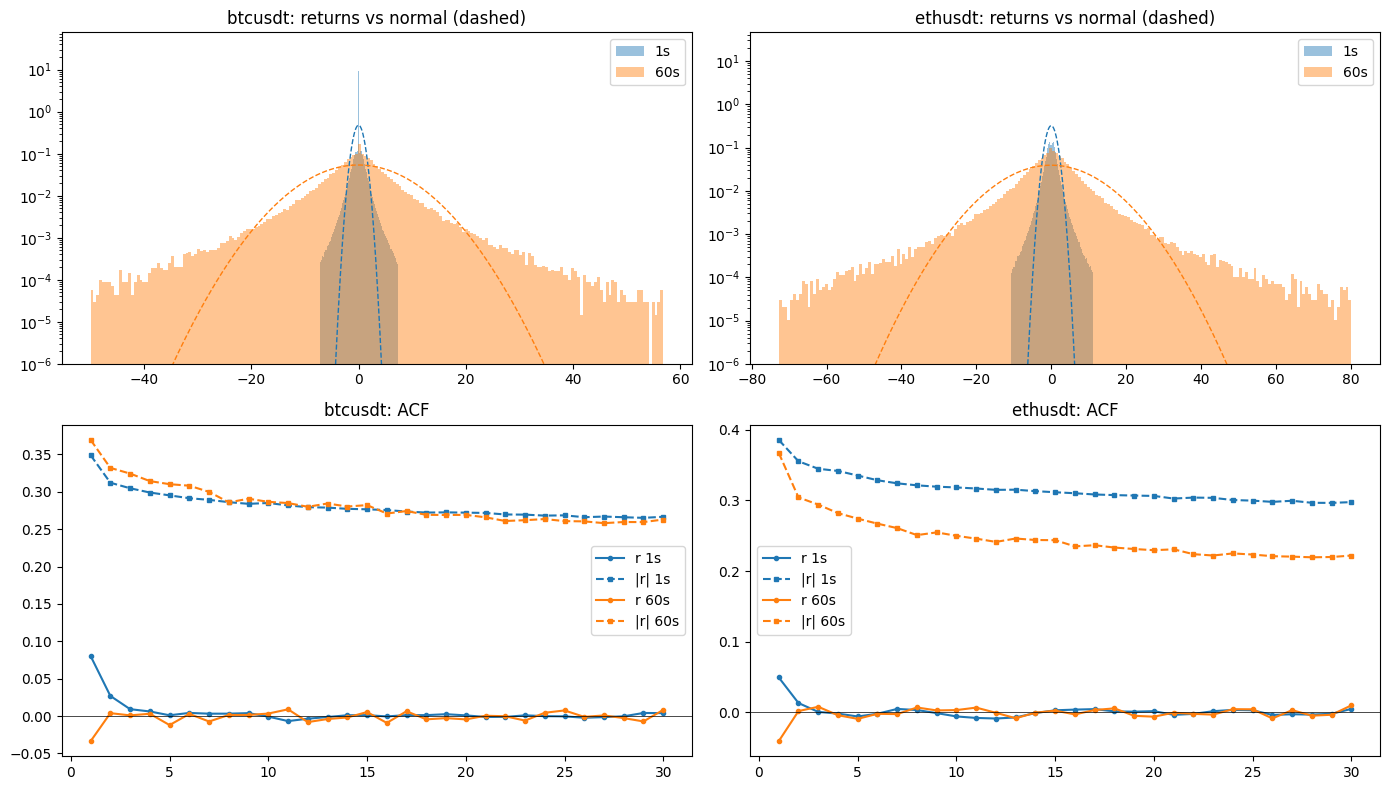

[stage C return stats] 35.8s peak_rss=8.73GB


In [15]:
def daily_rv(sym):
    R = ret_matrix(sym, 1); cnt = np.isfinite(R).sum(1); rv = np.nansum(R ** 2, axis=1)
    return np.where(cnt / 86399 > 0.5, np.sqrt(rv / np.maximum(cnt, 1) * 86400) / 1e4 * 100, np.nan)
def hourly_vol(sym):
    R = ret_matrix(sym, 60); R = np.concatenate([np.full((R.shape[0], 1), np.nan), R], axis=1)[:, :1440].reshape(R.shape[0], 24, 60)
    return np.nanstd(R.transpose(1, 0, 2).reshape(24, -1), axis=1)
DRV = {s: daily_rv(s) for s in SYMS}; HV = {s: hourly_vol(s) for s in SYMS}
HS = pl.concat([r for s in SYMS for r in P1[s]["hour"]]).group_by("sym", "hour").agg(pl.col("spread_med_bps").median()).sort("sym", "hour")
for s in SYMS:
    d = DRV[s][np.isfinite(DRV[s])]; print(f"{s}: daily vol % mean={d.mean():.2f} min={d.min():.2f} max={d.max():.2f}")

fig, ax = plt.subplots(3, len(SYMS), figsize=(7 * len(SYMS), 11)); ax = np.atleast_2d(ax).reshape(3, len(SYMS))
for j, s in enumerate(SYMS):
    ax[0, j].plot(GRID[s]["mid"][::900], lw=.7); ax[0, j].set_title(f"{s} mid (15-min sampling)"); ax[0, j].grid(alpha=.3)
    ax[1, j].bar(np.arange(len(DRV[s])), DRV[s]); ax[1, j].set_title(f"{s} daily realised vol %")
    ax[2, j].plot(range(24), HV[s], "o-"); ax2 = ax[2, j].twinx(); h = HS.filter(pl.col("sym") == s); ax2.plot(h["hour"], h["spread_med_bps"], "s--", c="C3"); ax[2, j].set_title(f"{s} intraday UTC: 1-min vol (blue), spread bps (red)")
fig.tight_layout(); show(fig, "c_paths_vol_intraday.png")

fig, ax = plt.subplots(2, len(SYMS), figsize=(7 * len(SYMS), 8)); ax = np.atleast_2d(ax).reshape(2, len(SYMS))
for j, s in enumerate(SYMS):
    for h, c in ((1, "C0"), (60, "C1")):
        x = ret_matrix(s, h).ravel(); x = x[np.isfinite(x)]; lo, hi = np.quantile(x, [.0005, .9995])
        ax[0, j].hist(x, bins=np.linspace(lo, hi, 200), density=True, alpha=.45, color=c, label=f"{h}s"); gx = np.linspace(lo, hi, 400); ax[0, j].plot(gx, sps.norm.pdf(gx, x.mean(), x.std()), c=c, ls="--", lw=1)
        R = ret_matrix(s, h); ax[1, j].plot(range(1, 31), acf_2d(R, 30), "o-", c=c, ms=3, label=f"r {h}s"); ax[1, j].plot(range(1, 31), acf_2d(np.abs(R), 30), "s--", c=c, ms=3, label=f"|r| {h}s")
    ax[0, j].set_yscale("log"); ax[0, j].set_ylim(1e-6); ax[0, j].set_title(f"{s}: returns vs normal (dashed)"); ax[0, j].legend(); ax[1, j].axhline(0, c="k", lw=.5); ax[1, j].set_title(f"{s}: ACF"); ax[1, j].legend()
fig.tight_layout(); show(fig, "c_distribution_acf.png")
mark("C return stats")

# D. Liquidations and cascades (Q3)
Bybit timestamps are shifted +200 ms **once, here**. Notional = amount * prevailing mid (robust to corrupt liquidation prices);
rows > 300 bps from the mid are flagged `bad` and excluded from clustering.
Detection ladder: (1) gap clustering with G chosen against an hour-preserving **Poisson null**, (2) significance and one-sidedness filters,
(3) Hawkes self-excitation (share of events that are *triggered*), (4) price-impact check (continuation vs reversal).

In [16]:
from numba import njit
from scipy.optimize import minimize

def load_liq(sym):
    c = ["timestamp", "side", "price", "amount"]
    b = pl.read_parquet(P("liq_bn", sym), columns=c).with_columns(pl.lit(1, dtype=pl.Int8).alias("exch"))
    y = pl.read_parquet(P("liq_by", sym), columns=c).with_columns((pl.col("timestamp") + CFG["BYBIT_SHIFT_US"]).alias("timestamp"), pl.lit(2, dtype=pl.Int8).alias("exch"))
    L = pl.concat([b, y]).sort("timestamp", maintain_order=True)
    ts, px, am = L["timestamp"].to_numpy(), L["price"].to_numpy(), L["amount"].to_numpy(); sd = L["side"].to_numpy()
    s = np.where(sd == "buy", 1, np.where(sd == "sell", -1, 0)).astype(np.int8)
    mid = mid_at(sym, ts, max_age_s=60); dev = (px / mid - 1) * 1e4
    bad = ~np.isfinite(px) | (px <= 0) | ~np.isfinite(am) | (am <= 0) | (s == 0) | (np.isfinite(dev) & (np.abs(dev) > CFG["BAD_LIQ_BPS"]))
    return pl.DataFrame(dict(timestamp=ts, exch=L["exch"].to_numpy(), s=s, price=px, amount=am, mid=mid, dev_bps=dev,
                             notional=am * np.where(np.isfinite(mid), mid, px), bad=bad, no_mid=~np.isfinite(mid)))
LIQ = {s: load_liq(s) for s in SYMS}

In [17]:
for s in SYMS:
    L = LIQ[s]; print(f"\n===== {s}: {L.height:,} liquidation rows =====")
    print(L.group_by("exch", "s").agg(pl.len().alias("n"), pl.col("bad").sum().alias("n_bad"), pl.col("no_mid").sum().alias("n_no_mid"), pl.col("notional").sum().alias("tot_usd"),
          pl.col("notional").median().alias("p50"), pl.col("notional").quantile(.99).alias("p99"), pl.col("notional").max().alias("max"), pl.col("dev_bps").abs().median().alias("|dev|_p50")).sort("exch", "s"))
    ts = L.filter(~pl.col("bad"))["timestamp"].to_numpy(); ia = np.diff(ts) / US
    print("inter-arrival (s) q1/50/90/99:", np.round(np.quantile(ia, [.01, .5, .9, .99]), 3), "| share <1s:", round(float((ia < 1).mean()), 3),
          "(Poisson same rate:", round(1 - math.exp(-len(ts) / max((ts[-1] - ts[0]) / US, 1)), 3), ")")
    d = L.with_columns((pl.col("timestamp") // DAY_US).alias("day")).group_by("day").agg(pl.len().alias("n"))
    print("daily count min/median/max:", int(d["n"].min()), int(d["n"].median()), int(d["n"].max()), "| days with none:", NDAYS_RANGE - d.height)


===== btcusdt: 342,910 liquidation rows =====
shape: (4, 10)
┌──────┬─────┬────────┬───────┬──────────┬──────────┬─────────────┬──────────────┬──────────┬───────────┐
│ exch ┆ s   ┆ n      ┆ n_bad ┆ n_no_mid ┆ tot_usd  ┆ p50         ┆ p99          ┆ max      ┆ |dev|_p50 │
│ ---  ┆ --- ┆ ---    ┆ ---   ┆ ---      ┆ ---      ┆ ---         ┆ ---          ┆ ---      ┆ ---       │
│ i8   ┆ i8  ┆ u32    ┆ u32   ┆ u32      ┆ f64      ┆ f64         ┆ f64          ┆ f64      ┆ f64       │
╞══════╪═════╪════════╪═══════╪══════════╪══════════╪═════════════╪══════════════╪══════════╪═══════════╡
│ 1    ┆ -1  ┆ 64209  ┆ 9     ┆ 0        ┆ 7.3347e8 ┆ 1029.4134   ┆ 164192.8988  ┆ 1.5228e7 ┆ 38.633974 │
│ 1    ┆ 1   ┆ 50046  ┆ 2     ┆ 1        ┆ 5.5958e8 ┆ 1234.662075 ┆ 162306.5114  ┆ 1.2131e7 ┆ 39.432893 │
│ 2    ┆ -1  ┆ 153798 ┆ 0     ┆ 0        ┆ 1.9231e9 ┆ 1112.31225  ┆ 192238.1505  ┆ 3.1958e6 ┆ 48.442592 │
│ 2    ┆ 1   ┆ 74857  ┆ 1     ┆ 0        ┆ 9.9453e8 ┆ 1133.0958   ┆ 215315.70065 ┆ 3.4283e

## D2. Choose G against a Poisson null

In [18]:
def gap_clusters(ts, G_us): return np.concatenate([[0], np.cumsum(np.diff(ts) > G_us)]).astype(np.int64)
def cluster_table(L, G_s):
    ts = L["timestamp"].to_numpy(); cid = gap_clusters(ts, int(G_s * US))
    return (L.with_columns(pl.Series("cid", cid), (pl.col("s") * pl.col("notional")).alias("sn"), (pl.col("exch") == 1).cast(pl.Int32).alias("is_bn")).group_by("cid", maintain_order=True)
             .agg(pl.col("timestamp").min().alias("t0"), pl.col("timestamp").max().alias("t1"), pl.len().alias("n"), pl.col("notional").sum().alias("notional"), pl.col("sn").sum().alias("net"), pl.col("is_bn").sum().alias("n_binance"))
             .with_columns(((pl.col("t1") - pl.col("t0")) / US).alias("dur_s"), (pl.col("net").abs() / pl.col("notional")).alias("one_sided"), pl.col("net").sign().cast(pl.Int8).alias("dir"), (pl.col("n") - pl.col("n_binance")).alias("n_bybit")))
def poisson_null(ts, G_s, kmin, nsim=25, seed=0):
    rng = np.random.default_rng(seed); cell = (ts - T0_GRID) // (3600 * US); nc = int(cell.max()) + 1; cnt = np.bincount(cell, minlength=nc); out = []
    for _ in range(nsim):
        idx = np.repeat(np.arange(nc), rng.poisson(cnt)); t = np.sort(T0_GRID + idx * 3600 * US + rng.integers(0, 3600 * US, len(idx)))
        sizes = np.bincount(gap_clusters(t, int(G_s * US))); big = sizes >= kmin; out.append((len(sizes), int(big.sum()), int(sizes[big].sum())))
    return np.array(out)
def choose_G(sym):
    L = LIQ[sym].filter(~pl.col("bad")); ts = L["timestamp"].to_numpy(); rows = []
    for G in CFG["CASCADE_G_CANDIDATES"]:
        ct = cluster_table(L, G); big = ct.filter(pl.col("n") >= CFG["CASCADE_KMIN"]); nl = poisson_null(ts, G, CFG["CASCADE_KMIN"]); ev = int(big["n"].sum())
        rows.append(dict(sym=sym, G_s=G, clusters=ct.height, clusters_ge_kmin=big.height, null_clusters_ge_kmin=float(nl[:, 1].mean()), events_in_big=ev, null_events_in_big=float(nl[:, 2].mean()),
                         share_events_in_big=ev / len(ts), z_excess=float((ev - nl[:, 2].mean()) / max(nl[:, 2].std(), 1.0)), longest_cluster_s=float(ct["dur_s"].max()), largest_cluster_n=int(ct["n"].max())))
    T = pl.DataFrame(rows).with_columns(
        (pl.col("null_events_in_big") <= 0.1 * pl.col("events_in_big")).alias("null_ok"),
        (pl.col("clusters_ge_kmin") / pl.col("clusters_ge_kmin").shift(-1) - 1).abs().alias("rel_change_to_next"))
    # plateau rule: smallest G whose significant-cluster count no longer changes (<=10%) when G grows, with the Poisson null still negligible.
    # (Maximising the z-score alone favours tiny G, where the null is exactly 0 but real cascades are fragmented.)
    ok = T.filter(pl.col("null_ok") & (pl.col("rel_change_to_next") <= 0.10))
    G = int(ok["G_s"].min()) if ok.height else int(T.sort(["z_excess", "G_s"], descending=[True, False])["G_s"][0])
    return T, G
GSEL, GTAB = {}, []
for s in SYMS: t, g = choose_G(s); GTAB.append(t); GSEL[s] = g
GTAB = pl.concat(GTAB); GTAB.write_csv(WORK / "cascade_gap_selection.csv"); print(GTAB); print("selected G (s):", GSEL, "(a huge longest_cluster_s means G chains separate episodes)")

shape: (12, 13)
┌─────────┬─────┬──────────┬──────────────────┬───────────────────────┬───────────────┬────────────────────┬─────────────────────┬────────────┬───────────────────┬───────────────────┬─────────┬────────────────────┐
│ sym     ┆ G_s ┆ clusters ┆ clusters_ge_kmin ┆ null_clusters_ge_kmin ┆ events_in_big ┆ null_events_in_big ┆ share_events_in_big ┆ z_excess   ┆ longest_cluster_s ┆ largest_cluster_n ┆ null_ok ┆ rel_change_to_next │
│ ---     ┆ --- ┆ ---      ┆ ---              ┆ ---                   ┆ ---           ┆ ---                ┆ ---                 ┆ ---        ┆ ---               ┆ ---               ┆ ---     ┆ ---                │
│ str     ┆ i64 ┆ i64      ┆ i64              ┆ f64                   ┆ i64           ┆ f64                ┆ f64                 ┆ f64        ┆ f64               ┆ i64               ┆ bool    ┆ f64                │
╞═════════╪═════╪══════════╪══════════════════╪═══════════════════════╪═══════════════╪════════════════════╪════════════════

## D3. Cascade table with significance, direction and price impact

In [19]:
def cascade_table(sym, G):
    L = LIQ[sym].filter(~pl.col("bad")); ct = cluster_table(L, G); ts = L["timestamp"].to_numpy(); off = (D0 + 3) % 7 * 24
    how = ((((ts - T0_GRID) // US) // 3600 + off) % 168).astype(np.int64); spw = np.bincount((((np.arange(NDAYS_RANGE * 86400) // 3600) + off) % 168), minlength=168)
    rate = np.bincount(how, minlength=168) / np.maximum(spw, 1); t0 = ct["t0"].to_numpy(); h0 = ((((t0 - T0_GRID) // US) // 3600 + off) % 168).astype(np.int64)
    logp = sps.poisson.logsf(ct["n"].to_numpy() - 1, np.maximum(rate[h0] * np.maximum(ct["dur_s"].to_numpy(), G), 1e-9))
    ct = ct.with_columns(pl.Series("ln_p_poisson", logp)).filter((pl.col("n") >= CFG["CASCADE_KMIN"]) & (pl.col("one_sided") >= CFG["CASCADE_ONESIDED"]) & (pl.col("ln_p_poisson") < CFG["CASCADE_POIS_LOGP"]))
    t0, t1, dr = ct["t0"].to_numpy(), ct["t1"].to_numpy(), ct["dir"].to_numpy().astype(float); m_pre, m_end = mid_at(sym, t0 - US), mid_at(sym, t1)
    imp = {"ret_during_bps": dr * (m_end / m_pre - 1) * 1e4, "ret_post60_bps": dr * (mid_at(sym, t1 + 60 * US) / m_end - 1) * 1e4, "ret_post300_bps": dr * (mid_at(sym, t1 + 300 * US) / m_end - 1) * 1e4}
    return ct.with_columns([pl.Series(k, v) for k, v in imp.items()]).with_columns(pl.from_epoch("t0", "us").alias("start_utc"))
CASC = {s: cascade_table(s, GSEL[s]) for s in SYMS}
for s in SYMS:
    C = CASC[s]; C.write_csv(WORK / f"cascades_{s}.csv"); print(f"\n===== {s}: {C.height} cascades (G={GSEL[s]}s) =====")
    if C.height:
        print(C.select(pl.col("n").median().alias("n_med"), pl.col("n").max().alias("n_max"), pl.col("dur_s").median().alias("dur_med_s"), pl.col("notional").median().alias("usd_med"), pl.col("notional").max().alias("usd_max"), (pl.col("n_bybit") / pl.col("n")).mean().alias("bybit_share")))
        print("price impact signed in cascade direction (+ continuation, - reversal):")
        print(C.select([pl.col(c).mean().alias(c + "_mean") for c in ["ret_during_bps", "ret_post60_bps", "ret_post300_bps"]] + [pl.col(c).median().alias(c + "_med") for c in ["ret_during_bps", "ret_post60_bps", "ret_post300_bps"]]))
        print(C.sort("notional", descending=True).head(5).select("start_utc", "dir", "n", "n_bybit", "dur_s", "notional", "one_sided", "ret_during_bps", "ret_post300_bps"))


===== btcusdt: 10330 cascades (G=1s) =====
shape: (1, 6)
┌───────┬───────┬───────────┬──────────────┬──────────┬─────────────┐
│ n_med ┆ n_max ┆ dur_med_s ┆ usd_med      ┆ usd_max  ┆ bybit_share │
│ ---   ┆ ---   ┆ ---       ┆ ---          ┆ ---      ┆ ---         │
│ f64   ┆ u32   ┆ f64       ┆ f64          ┆ f64      ┆ f64         │
╞═══════╪═══════╪═══════════╪══════════════╪══════════╪═════════════╡
│ 9.0   ┆ 1692  ┆ 1.987     ┆ 63131.951775 ┆ 4.6300e7 ┆ 0.791738    │
└───────┴───────┴───────────┴──────────────┴──────────┴─────────────┘
price impact signed in cascade direction (+ continuation, - reversal):
shape: (1, 6)
┌─────────────────────┬─────────────────────┬──────────────────────┬────────────────────┬────────────────────┬─────────────────────┐
│ ret_during_bps_mean ┆ ret_post60_bps_mean ┆ ret_post300_bps_mean ┆ ret_during_bps_med ┆ ret_post60_bps_med ┆ ret_post300_bps_med │
│ ---                 ┆ ---                 ┆ ---                  ┆ ---                ┆ ---        

## D4. Hawkes self-excitation

In [20]:
@njit(cache=True)
def _hawkes_A(t, beta):
    n = len(t); A = np.empty(n); a = 0.0
    for i in range(n):
        if i > 0: a = math.exp(-beta * (t[i] - t[i - 1])) * (1.0 + a)
        A[i] = a
    return A
def _nll(th, t, T):
    mu, al, be = np.exp(th); A = _hawkes_A(t, be); return -(np.log(mu + al * A).sum() - mu * T - (al / be) * (1 - np.exp(-be * (T - t))).sum())
def fit_hawkes(t, T):
    best = None
    for b0 in (0.05, 0.5, 5.0):
        r = minimize(_nll, np.log([0.3 * len(t) / T, 0.7 * b0, b0]), args=(t, T), method="Nelder-Mead", options=dict(maxiter=500, xatol=1e-4, fatol=1e-4))
        if best is None or r.fun < best.fun: best = r
    return tuple(np.exp(best.x))
HK = {}
for s in SYMS:
    ts = LIQ[s].filter(~pl.col("bad"))["timestamp"].to_numpy(); t = (ts - ts[0]) / US; T = float(t[-1] + 1)
    mu, al, be = fit_hawkes(t, T); A = _hawkes_A(t, be); ptrig = al * A / (mu + al * A); HK[s] = dict(mu=mu, alpha=al, beta=be, branching=al / be, half_life_s=math.log(2) / be)
    print(f"{s}: Hawkes mu={mu:.5f}/s alpha={al:.3f} beta={be:.3f}/s | branching n={al / be:.3f} | half-life={math.log(2) / be:.2f}s | events with P(triggered)>0.5: {float((ptrig > .5).mean()):.1%}")
    C = CASC[s]
    if C.height:
        j = np.searchsorted(C["t0"].to_numpy(), ts, "right") - 1; inside = (j >= 0) & (ts <= C["t1"].to_numpy()[np.maximum(j, 0)])
        print(f"    inside detected cascades: {float((ptrig[inside] > .5).mean()):.1%} triggered vs outside: {float((ptrig[~inside] > .5).mean()):.1%}")

btcusdt: Hawkes mu=0.00806/s alpha=0.916 beta=1.121/s | branching n=0.817 | half-life=0.62s | events with P(triggered)>0.5: 82.6%
    inside detected cascades: 98.2% triggered vs outside: 55.0%
ethusdt: Hawkes mu=0.00848/s alpha=0.582 beta=0.752/s | branching n=0.774 | half-life=0.92s | events with P(triggered)>0.5: 78.6%
    inside detected cascades: 98.6% triggered vs outside: 58.1%


## D5. Causal state thresholds (train days only)
State at trade time `t` uses only events strictly before `t`. `with` = taker direction equals liquidation direction.

btcusdt state thresholds USD: {10: 218633, 60: 388474}
ethusdt state thresholds USD: {10: 154524, 60: 281842}


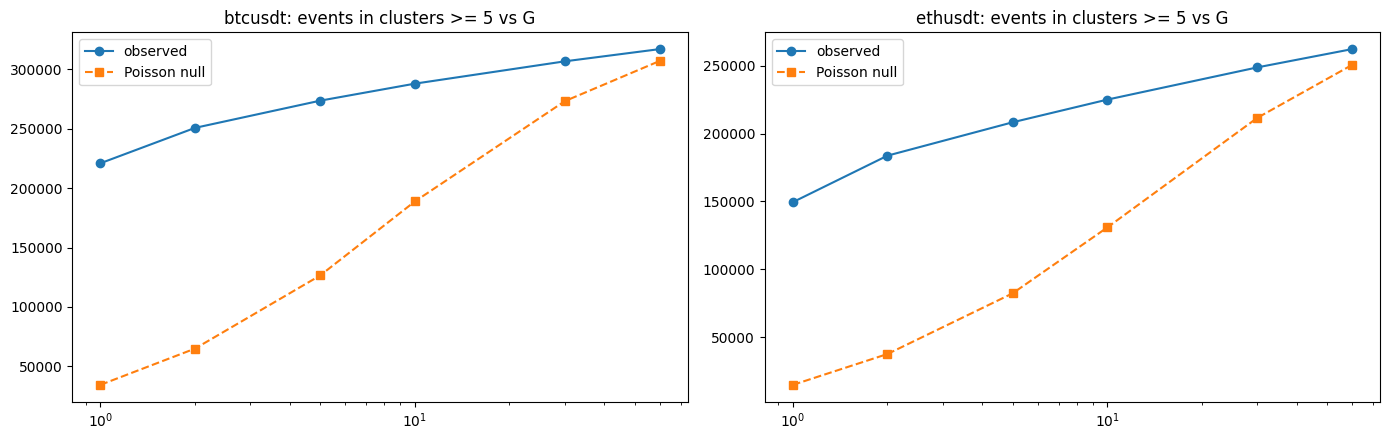

[stage D liquidations/cascades] 23.8s peak_rss=8.73GB


In [21]:
def roll_net(q, ev_ts, cs, W_us): return cs[np.searchsorted(ev_ts, q, "left")] - cs[np.searchsorted(ev_ts, q - W_us, "left")]
EV, THR = {}, {}
for s in SYMS:
    L = LIQ[s].filter(~pl.col("bad")); ts = L["timestamp"].to_numpy(); sn = (L["s"].to_numpy() * L["notional"].to_numpy()).astype(np.float64); cs = np.concatenate([[0.0], np.cumsum(sn)]); EV[s] = (ts, cs)
    dtr = [d for d in DAYS[s] if split_of_day(d) == "train"] or DAYS[s]; g = np.concatenate([np.arange(d * DAY_US, (d + 1) * DAY_US, 5 * US) for d in dtr]); THR[s] = {}
    for W in CFG["STATE_WINDOWS_S"]:
        a = np.abs(roll_net(g, ts, cs, W * US)); a = a[a > 0]; THR[s][W] = float(np.quantile(a, CFG["STATE_Q"])) if len(a) else np.inf
    print(s, "state thresholds USD:", {k: round(v) for k, v in THR[s].items()})

fig, ax = plt.subplots(1, len(SYMS), figsize=(7 * len(SYMS), 4.5)); ax = np.atleast_1d(ax)
for j, s in enumerate(SYMS):
    t = GTAB.filter(pl.col("sym") == s); ax[j].plot(t["G_s"], t["events_in_big"], "o-", label="observed"); ax[j].plot(t["G_s"], t["null_events_in_big"], "s--", label="Poisson null")
    ax[j].set_xscale("log"); ax[j].set_title(f"{s}: events in clusters >= {CFG['CASCADE_KMIN']} vs G"); ax[j].legend()
fig.tight_layout(); show(fig, "d_cluster_vs_null.png")
mark("D liquidations/cascades")

## D6. Liquidation price sanity and the baseline cascade definition (from the original EDA)
**D6a - price sanity.** Each liquidation price is compared with the last clean mid that is at most 1 s old (second-resolution grid); rows more than 10 % away are listed. The pipeline already excludes rows more than 300 bps from the 60 s mid (`bad`), so this table shows how many of the extreme prints that rule catches. Binance prices are the *liquidation order* price, so moderate deviations can be a price-definition effect, not corruption.

**D6b - baseline cascades.** Same-side bursts: consecutive liquidations of one side with no gap above 1 s form a cluster; a cluster with >= 3 events and >= 100,000 USD (`amount * price`) is a candidate cascade. The thresholds are an EDA convention, not a statistical test, so they are compared with the Poisson-validated cascades of D2-D3 and a small sensitivity grid is shown. `n_bad` counts rows that the price rule above would exclude: a cluster built partly from corrupt prices has an inflated notional.

Liquidation price vs fresh mid (age <= 1 s), flag |distance| > 10 %:
shape: (4, 7)
┌─────────┬──────────┬────────┬──────────────────┬──────────────────┬─────────────────────────────────┬─────────────────────┐
│ sym     ┆ exchange ┆ rows   ┆ with_fresh_quote ┆ flagged_gt_10pct ┆ pipeline_bad_gt_300bps_or_inva… ┆ flagged_but_not_bad │
│ ---     ┆ ---      ┆ ---    ┆ ---              ┆ ---              ┆ ---                             ┆ ---                 │
│ str     ┆ str      ┆ i64    ┆ i64              ┆ i64              ┆ i64                             ┆ i64                 │
╞═════════╪══════════╪════════╪══════════════════╪══════════════════╪═════════════════════════════════╪═════════════════════╡
│ btcusdt ┆ binance  ┆ 114255 ┆ 114253           ┆ 2                ┆ 11                              ┆ 0                   │
│ btcusdt ┆ bybit    ┆ 228655 ┆ 228654           ┆ 0                ┆ 1                               ┆ 0                   │
│ ethusdt ┆ binance  ┆ 131769 ┆ 131

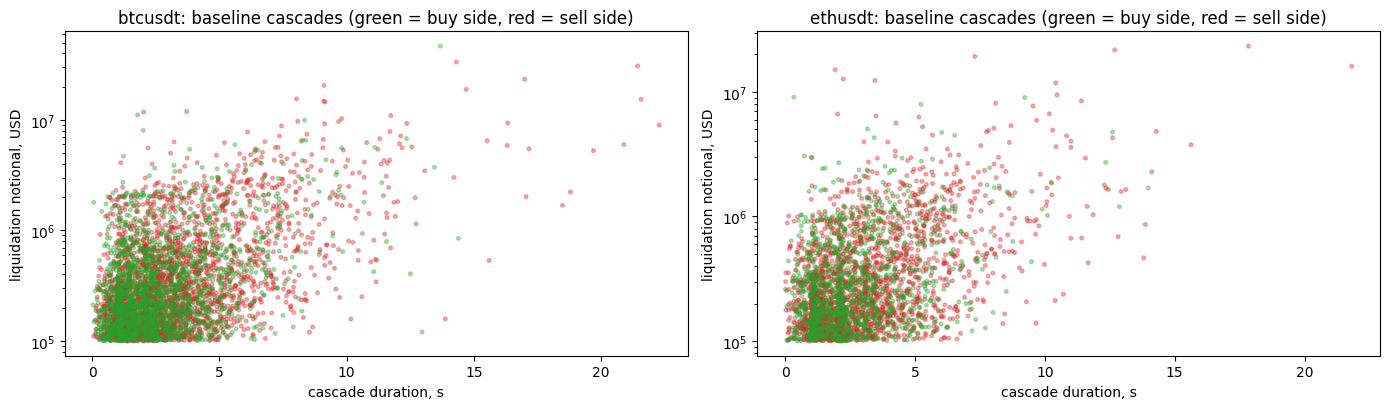

[stage D6 baseline cascades + price sanity] 1.7s peak_rss=8.73GB


In [22]:
# ---- D6a. Liquidation price vs a FRESH quote (EDA `flag_liq_price_outliers`: quote age <= 1 s, distance > 10 %) ----
FRESH_LIQ_S, DIST_LIM_BPS = 1, 1_000
def liq_price_sanity():
    PR_ROWS, PR_DETAIL = [], []
    for s in SYMS:
        L = LIQ[s]; ts = L["timestamp"].to_numpy(); px = L["price"].to_numpy(); ex = L["exch"].to_numpy(); bad = L["bad"].to_numpy()
        mid1 = mid_at(s, ts, max_age_s=FRESH_LIQ_S); dist = (px / mid1 - 1) * 1e4; fresh = np.isfinite(mid1); out = fresh & (np.abs(dist) > DIST_LIM_BPS)
        for e, nm in ((1, "binance"), (2, "bybit")):
            m = ex == e
            PR_ROWS.append(dict(sym=s, exchange=nm, rows=int(m.sum()), with_fresh_quote=int((m & fresh).sum()), flagged_gt_10pct=int((m & out).sum()),
                                pipeline_bad_gt_300bps_or_invalid=int((m & bad).sum()), flagged_but_not_bad=int((m & out & ~bad).sum())))
        for i in np.argsort(-np.abs(np.where(out, dist, 0)))[:min(int(out.sum()), 12)]:
            PR_DETAIL.append(dict(sym=s, exchange="binance" if ex[i] == 1 else "bybit", utc=dt.datetime.fromtimestamp(ts[i] / US, dt.timezone.utc).replace(tzinfo=None), side="buy" if L["s"][int(i)] > 0 else "sell",
                                  price=float(px[i]), amount=float(L["amount"][int(i)]), mid=float(mid1[i]), distance_pct=float(dist[i] / 100), pipeline_bad=bool(bad[i])))
    return PR_ROWS, PR_DETAIL
PR_ROWS, PR_DETAIL = liq_price_sanity()
PRICE_SANITY = pl.DataFrame(PR_ROWS); PRICE_SANITY.write_csv(WORK / "liq_price_sanity.csv")
print(f"Liquidation price vs fresh mid (age <= {FRESH_LIQ_S} s), flag |distance| > {DIST_LIM_BPS / 100:.0f} %:"); print(PRICE_SANITY)
if PR_DETAIL: print("Most extreme flagged rows:"); print(pl.DataFrame(PR_DETAIL))

# ---- D6b. Baseline cascade definition: per-side 1 s clusters, >= 3 events and >= 100k USD ----
EDA_G_S, EDA_MIN_EVENTS, EDA_MIN_USD = 1.0, 3, 100_000.0
def eda_clusters(sym, G_s=EDA_G_S):
    L = (LIQ[sym].filter(pl.col("s") != 0).with_columns((pl.col("price") * pl.col("amount")).alias("notional_px"), (pl.col("exch") == 1).cast(pl.Int32).alias("is_bn"))
         .sort(["s", "timestamp"], maintain_order=True))
    new = ((pl.col("timestamp").diff() > int(G_s * US)) | (pl.col("s") != pl.col("s").shift(1))).fill_null(True)
    L = L.with_columns(new.cast(pl.Int64).cum_sum().alias("cid"))
    return (L.group_by("cid", maintain_order=True).agg(pl.col("s").first().alias("s"), pl.col("timestamp").min().alias("t0"), pl.col("timestamp").max().alias("t1"), pl.len().alias("n"),
                pl.col("notional_px").sum().alias("notional"), pl.col("is_bn").sum().alias("n_binance"), pl.col("bad").cast(pl.Int32).sum().alias("n_bad"))
              .with_columns(((pl.col("t1") - pl.col("t0")) / US).alias("dur_s"), (pl.col("n") - pl.col("n_binance")).alias("n_bybit")))
EDA_CT = {s: eda_clusters(s) for s in SYMS}
def eda_cascades(ct, kmin=EDA_MIN_EVENTS, usd=EDA_MIN_USD): return ct.filter((pl.col("n") >= kmin) & (pl.col("notional") >= usd))
def overlap_share(a, b):
    """share of cascades in `a` (t0, t1, side) that overlap a same-side cascade in `b` (per-side clusters are disjoint and ordered, so one searchsorted per row is exact)."""
    hit = 0
    for sd in (1, -1):
        x = a.filter(pl.col("s") == sd); y = b.filter(pl.col("s") == sd).sort("t0")
        if x.height == 0 or y.height == 0: continue
        y0, y1 = y["t0"].to_numpy(), y["t1"].to_numpy(); j = np.searchsorted(y0, x["t1"].to_numpy(), "right") - 1; ok = j >= 0
        hit += int((y1[np.where(ok, j, 0)][ok] >= x["t0"].to_numpy()[ok]).sum())
    return hit / max(a.height, 1)
OV_ROWS, SIDE_ROWS, Q_ROWS, SENS_ROWS, EDA_CAS = [], [], [], [], {}
for s in SYMS:
    ct = EDA_CT[s]; cas = eda_cascades(ct); EDA_CAS[s] = cas; cas.sort("notional", descending=True).with_columns(pl.from_epoch("t0", "us").alias("start_utc")).write_csv(WORK / f"eda_cascades_{s}.csv")
    ev, usd = int(ct["n"].sum()), float(ct["notional"].sum()); V = CASC[s].select(pl.col("t0"), pl.col("t1"), pl.col("dir").cast(pl.Int8).alias("s"))
    OV_ROWS.append(dict(sym=s, observed_events=ev, same_side_clusters=ct.height, candidate_cascades=cas.height, share_clusters_that_are_cascades=cas.height / ct.height,
                        share_events_in_cascades=float(cas["n"].sum() / ev), share_notional_in_cascades=float(cas["notional"].sum() / usd), cascades_with_bad_rows=int((cas["n_bad"] > 0).sum()),
                        largest_cascade_usd=float(cas["notional"].max()) if cas.height else np.nan, validated_cascades_D3=V.height, validated_overlapping_baseline=overlap_share(V, cas),
                        baseline_overlapping_validated=overlap_share(cas.select("t0", "t1", "s"), V)))
    for sd, g in cas.group_by("s"): SIDE_ROWS.append(dict(sym=s, side="buy (shorts liquidated, upward)" if sd[0] > 0 else "sell (longs liquidated, downward)", cascades=g.height, events=int(g["n"].sum()), notional_usd=float(g["notional"].sum())))
    for q in (.5, .9, .99, .999): Q_ROWS.append(dict(sym=s, quantile=q, events_per_cluster=float(ct["n"].quantile(q)), notional_usd=float(ct["notional"].quantile(q)), duration_s=float(ct["dur_s"].quantile(q))))
    for kmin in (3, 5, 10):
        for usd_min in (50_000.0, 100_000.0, 250_000.0, 1_000_000.0): c = eda_cascades(ct, kmin, usd_min); SENS_ROWS.append(dict(sym=s, min_events=kmin, min_usd=usd_min, cascades=c.height, share_events=float(c["n"].sum() / ev)))
EDA_OV, EDA_SIDE, EDA_Q, EDA_SENS = pl.DataFrame(OV_ROWS), pl.DataFrame(SIDE_ROWS), pl.DataFrame(Q_ROWS), pl.DataFrame(SENS_ROWS)
for nm, T in (("eda_cascade_overview", EDA_OV), ("eda_cascades_side_summary", EDA_SIDE), ("eda_cluster_quantiles", EDA_Q), ("eda_cascade_sensitivity", EDA_SENS)): T.write_csv(WORK / f"{nm}.csv")
print("Baseline cascades (per-side 1 s clusters, >= 3 events, >= 100k USD):"); print(EDA_OV)
print("\nBy side:"); print(EDA_SIDE); print("\nCluster size / notional / duration quantiles (most clusters are tiny; cascades are the right tail):"); print(EDA_Q)
print("\nSensitivity to the arbitrary thresholds:"); print(EDA_SENS.pivot(on="min_usd", index=["sym", "min_events"], values="cascades"))
for s in SYMS:
    print(f"\nLargest baseline cascades, {s}:"); print(EDA_CAS[s].sort("notional", descending=True).head(8).with_columns(pl.from_epoch("t0", "us").alias("start_utc")).select("start_utc", "s", "dur_s", "n", "n_binance", "n_bybit", "notional", "n_bad"))
fig, ax = plt.subplots(1, len(SYMS), figsize=(7 * len(SYMS), 4.2)); ax = np.atleast_1d(ax)
for j, s in enumerate(SYMS):
    c = EDA_CAS[s]; ax[j].scatter(c["dur_s"], c["notional"], s=7, alpha=.35, c=np.where(c["s"].to_numpy() > 0, "C2", "C3")); ax[j].set_yscale("log")
    ax[j].set_xlabel("cascade duration, s"); ax[j].set_ylabel("liquidation notional, USD"); ax[j].set_title(f"{s}: baseline cascades (green = buy side, red = sell side)")
fig.tight_layout(); show(fig, "d6_eda_cascade_scatter.png")
mark("D6 baseline cascades + price sanity")

# E. Markout analysis (Q2), three horizons, day by day
`pnl_i(tau) = -s_i * (m_i(tau) - p_i) / p_i * 1e4 + 0.5` with `m_i(tau)` = last observed Binance BBO mid at `t_i + tau`
(forward-fill from **full-resolution** quotes, not the 1 s grid); trades with `t_i + tau` outside the BBO range are excluded; `w_i = min(notional, 1e5)`.
Per day: trades are processed in chunks, row-level float32 markouts are stored (needed later for ML), and only small aggregates are kept:
group sums (day x hour x side x liquidation state) and fine weighted histograms (0.05 bps) for exact-to-bin quantiles and tail attribution.

In [23]:
STORE_ROWS = os.environ.get("LIQ_STORE_ROWS", "0") == "1"   # row-level markouts are optional (large, slow); aggregates + histograms answer Q2
HIST_EDGES = np.linspace(-300, 300, 12001)          # bps, 0.05 bps bins; values beyond are clipped into the edge bins
FRESH_US = CFG["STALE_S"] * US

def raw_mid(sym, day):
    """Spec mid from FULL-RES quotes: (bid+ask)/2 for finite positive quotes (crossed rows kept, as the spec does not drop them)."""
    df = read_day("bbo", sym, day, ["timestamp", "bid_price", "ask_price"])
    if df is None: return np.array([], np.int64), np.array([], np.float64)
    ts, b, a = df["timestamp"].to_numpy(), df["bid_price"].to_numpy(), df["ask_price"].to_numpy(); ok = np.isfinite(b) & np.isfinite(a) & (b > 0) & (a > 0)
    return ts[ok], 0.5 * (b[ok] + a[ok])

def state_codes(sym, ts, s):
    out = {}
    for W in CFG["STATE_WINDOWS_S"]:
        net = roll_net(ts, EV[sym][0], EV[sym][1], W * US); thr = THR[sym][W]
        out[f"st{W}"] = np.where(np.abs(net) < thr, 0, np.where(s * np.sign(net) > 0, 1, 2)).astype(np.int8)   # 0 none, 1 with cascade, 2 against
        out[f"lv{W}"] = np.where(np.abs(net) < thr, 0, np.where(np.abs(net) < 2 * thr, 1, np.where(np.abs(net) < 5 * thr, 2, 3))).astype(np.int8)   # pressure tier: 1 = 1-2x, 2 = 2-5x, 3 = >=5x the train 95th-percentile threshold
    return out

def markout_symbol(sym, force=False):
    ck = CK / f"markout2_{sym}.pkl"   # v2: cells carry the pressure tier (lv10, lv60)
    if ck.exists() and not force: return pickle.load(open(ck, "rb"))
    rows_dir = TMP / "rows" / sym; rows_dir.mkdir(parents=True, exist_ok=True)
    AGG, HIST = [], {}; bmax = BBO_RANGE[sym][1]
    days = DAYS[sym]; cur = raw_mid(sym, days[0]); prev_tail = (np.array([], np.int64), np.array([]))
    for k, d in enumerate(days):
        t0 = time.time(); nxt = raw_mid(sym, d + 1) if (d + 1) in SHARDS[("bbo", sym)] else (np.array([], np.int64), np.array([]))
        hk = np.searchsorted(nxt[0], (d + 1) * DAY_US + PAD_US, "left")
        cts = np.concatenate([prev_tail[0], cur[0], nxt[0][:hk]]); cmid = np.concatenate([prev_tail[1], cur[1], nxt[1][:hk]])
        tr = read_day("trades", sym, d)
        if tr is not None and tr.height:
            ts_all, s_all, px_all, am_all = tr["timestamp"].to_numpy(), tr["s"].to_numpy(), tr["price"].to_numpy(), tr["amount"].to_numpy(); del tr
            chunks = []
            for a in range(0, len(ts_all), CFG["TRADE_CHUNK"]):
                sl = slice(a, a + CFG["TRADE_CHUNK"]); ts, s, px, am = ts_all[sl], s_all[sl].astype(np.int8), px_all[sl], am_all[sl]
                good = np.isfinite(px) & np.isfinite(am) & (px > 0) & (am > 0) & (s != 0)
                w = np.where(good, np.minimum(px * am, CFG["W_CLIP"]), 0.0); cols = dict(timestamp=ts, s=s, w=w.astype(np.float32), hour=((ts % DAY_US) // (3600 * US)).astype(np.int8))
                cols.update(state_codes(sym, ts, s))
                for tau in TAUS:
                    tt = ts + tau * US; i = np.searchsorted(cts, tt, "right") - 1; ok = good & (i >= 0) & (tt <= bmax); ii = np.where(ok, i, 0)
                    m = cmid[ii] if len(cmid) else np.full(len(ts), np.nan)
                    pnl = np.where(ok, -s * (m - px) / px * 1e4 + CFG["REBATE_BPS"], np.nan); age = np.where(ok, tt - cts[ii] if len(cts) else 0, -1)
                    cols[f"pnl_{tau}"] = pnl.astype(np.float32); cols[f"fresh_{tau}"] = ok & (age <= FRESH_US)
                chunks.append(pl.DataFrame(cols))
            D = pl.concat(chunks); del chunks, ts_all, s_all, px_all, am_all
            if STORE_ROWS: D.select("timestamp", "s", "w", "st10", "st60", *[f"pnl_{t}" for t in TAUS]).write_parquet(rows_dir / f"{d}.parquet", compression="zstd")
            aggs = [pl.len().alias("n_all"), pl.col("w").cast(pl.Float64).sum().alias("w_all")]
            for tau in TAUS:
                ok = pl.col(f"pnl_{tau}").is_not_null() & pl.col(f"pnl_{tau}").is_not_nan(); p = pl.col(f"pnl_{tau}").cast(pl.Float64); w = pl.col("w").cast(pl.Float64); fr = ok & pl.col(f"fresh_{tau}")
                aggs += [ok.sum().alias(f"n_{tau}"), w.filter(ok).sum().alias(f"w_{tau}"), (w * p).filter(ok).sum().alias(f"wp_{tau}"), p.filter(ok).sum().alias(f"p_{tau}"), (p * p).filter(ok).sum().alias(f"pp_{tau}"),
                         fr.sum().alias(f"nf_{tau}"), w.filter(fr).sum().alias(f"wf_{tau}"), (w * p).filter(fr).sum().alias(f"wpf_{tau}")]
            g = D.group_by("hour", "s", "st10", "st60", "lv10", "lv60").agg(aggs).with_columns(pl.lit(sym).alias("sym"), pl.lit(d).alias("day"), pl.lit(split_of_day(d)).alias("split"))
            AGG.append(g)
            for tau in TAUS:
                p = D[f"pnl_{tau}"].to_numpy(); w = D["w"].to_numpy().astype(np.float64); ok = np.isfinite(p)
                if ok.any():
                    pc = np.clip(p[ok].astype(np.float64), HIST_EDGES[0], HIST_EDGES[-1] - 1e-9); idx = np.searchsorted(HIST_EDGES, pc, "right") - 1; nb = len(HIST_EDGES) - 1
                    h = HIST.setdefault((tau, split_of_day(d)), dict(c=np.zeros(nb), w=np.zeros(nb), wp=np.zeros(nb), mn=np.inf, mx=-np.inf))
                    h["c"] += np.bincount(idx, minlength=nb); h["w"] += np.bincount(idx, weights=w[ok], minlength=nb); h["wp"] += np.bincount(idx, weights=w[ok] * p[ok], minlength=nb)
                    h["mn"], h["mx"] = min(h["mn"], float(p[ok].min())), max(h["mx"], float(p[ok].max()))
            del D
        prev_tail = (cur[0][-1:], cur[1][-1:]); cur = nxt; gc.collect()
        log(f"[markout {sym}] {date_of_day(d)} ({k + 1}/{len(days)}) {time.time() - t0:.1f}s rss={mem_gb():.2f}GB")
    R = dict(agg=pl.concat(AGG) if AGG else None, hist=HIST); pickle.dump(R, open(ck, "wb"), protocol=4); return R

MO = {s: markout_symbol(s) for s in SYMS}
AGG = pl.concat([MO[s]["agg"] for s in SYMS])

08:53:26 [markout btcusdt] 2025-12-01 (1/90) 5.5s rss=7.97GB
08:53:31 [markout btcusdt] 2025-12-02 (2/90) 4.3s rss=7.89GB
08:53:35 [markout btcusdt] 2025-12-03 (3/90) 4.5s rss=7.91GB
08:53:39 [markout btcusdt] 2025-12-04 (4/90) 3.4s rss=7.87GB
08:53:42 [markout btcusdt] 2025-12-05 (5/90) 3.7s rss=7.91GB
08:53:44 [markout btcusdt] 2025-12-06 (6/90) 1.4s rss=7.81GB
08:53:47 [markout btcusdt] 2025-12-07 (7/90) 2.7s rss=7.88GB
08:53:50 [markout btcusdt] 2025-12-08 (8/90) 3.3s rss=7.95GB
08:53:54 [markout btcusdt] 2025-12-09 (9/90) 3.7s rss=7.90GB
08:53:57 [markout btcusdt] 2025-12-10 (10/90) 3.5s rss=7.79GB
08:54:01 [markout btcusdt] 2025-12-11 (11/90) 4.0s rss=7.87GB
08:54:04 [markout btcusdt] 2025-12-12 (12/90) 3.1s rss=7.91GB
08:54:05 [markout btcusdt] 2025-12-13 (13/90) 1.0s rss=7.72GB
08:54:07 [markout btcusdt] 2025-12-14 (14/90) 2.1s rss=7.78GB
08:54:11 [markout btcusdt] 2025-12-15 (15/90) 4.1s rss=7.96GB
08:54:15 [markout btcusdt] 2025-12-16 (16/90) 3.4s rss=7.88GB
08:54:19 [markout

## E1. Average and total markout per horizon

In [24]:
def summarise(A, by=None):
    by = by or []; aggs = []
    for tau in TAUS:
        aggs += [pl.col(f"n_{tau}").sum(), pl.col(f"w_{tau}").sum(), pl.col(f"wp_{tau}").sum(), pl.col(f"p_{tau}").sum(), pl.col(f"pp_{tau}").sum(), pl.col(f"nf_{tau}").sum(), pl.col(f"wf_{tau}").sum(), pl.col(f"wpf_{tau}").sum()]
    S = (A.group_by(by).agg(aggs + [pl.col("n_all").sum(), pl.col("w_all").sum()]) if by else A.select(aggs + [pl.col("n_all").sum(), pl.col("w_all").sum()]))
    out = []
    for tau in TAUS:
        out.append(S.select(*by, pl.lit(tau).alias("tau"), pl.col(f"n_{tau}").alias("n"), (pl.col(f"p_{tau}") / pl.col(f"n_{tau}")).alias("mean_bps"),
                            ((pl.col(f"pp_{tau}") / pl.col(f"n_{tau}") - (pl.col(f"p_{tau}") / pl.col(f"n_{tau}")) ** 2).clip(lower_bound=0).sqrt()).alias("std_bps"),
                            (pl.col(f"wp_{tau}") / pl.col(f"w_{tau}")).alias("wmean_bps"), (pl.col(f"wp_{tau}") / pl.col(f"w_{tau}") - CFG["REBATE_BPS"]).alias("wmean_gross_of_rebate_bps"),
                            (pl.col(f"wp_{tau}") / 1e4).alias("total_pnl_usd"), pl.col(f"w_{tau}").alias("turnover_usd"), (pl.col(f"wpf_{tau}") / pl.col(f"wf_{tau}")).alias("wmean_fresh_bps"),
                            (1 - pl.col(f"nf_{tau}") / pl.col(f"n_{tau}")).alias("share_stale_at_tau")))
    return pl.concat(out)
OV = summarise(AGG, ["sym"]); OVC = summarise(AGG.with_columns(pl.lit("both").alias("sym")), ["sym"]); OVS = pl.concat([OV, OVC]).sort("sym", "tau")
OVS.write_csv(WORK / "markout_overall.csv"); print("Markout in bps (positive = maker earns). wmean = clipped-notional weighted (the competition metric); total_pnl_usd = sum(w*pnl)/1e4"); print(OVS)
print("\nBy split"); print(summarise(AGG, ["sym", "split"]).sort("sym", "split", "tau"))
print("\nBy taker side (s=+1 taker buy / maker sold)"); print(summarise(AGG, ["sym", "s"]).sort("sym", "s", "tau").select("sym", "s", "tau", "n", "mean_bps", "wmean_bps", "total_pnl_usd"))

Markout in bps (positive = maker earns). wmean = clipped-notional weighted (the competition metric); total_pnl_usd = sum(w*pnl)/1e4
shape: (9, 11)
┌─────────┬─────┬────────────┬───────────┬───────────┬───────────┬───────────────────────────┬───────────────┬──────────────┬─────────────────┬────────────────────┐
│ sym     ┆ tau ┆ n          ┆ mean_bps  ┆ std_bps   ┆ wmean_bps ┆ wmean_gross_of_rebate_bps ┆ total_pnl_usd ┆ turnover_usd ┆ wmean_fresh_bps ┆ share_stale_at_tau │
│ ---     ┆ --- ┆ ---        ┆ ---       ┆ ---       ┆ ---       ┆ ---                       ┆ ---           ┆ ---          ┆ ---             ┆ ---                │
│ str     ┆ i32 ┆ u32        ┆ f64       ┆ f64       ┆ f64       ┆ f64                       ┆ f64           ┆ f64          ┆ f64             ┆ f64                │
╞═════════╪═════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════════════════════╪═══════════════╪══════════════╪═════════════════╪════════════════════╡
│ both    ┆ 30  ┆ 1107779630

## E2. Distribution (from fine weighted histograms) and tail attribution

In [25]:
def hist_merge(sym, tau, splits=("train", "val", "other")):
    hs = [MO[sym]["hist"][(tau, sp)] for sp in splits if (tau, sp) in MO[sym]["hist"]]
    return dict(c=sum(h["c"] for h in hs), w=sum(h["w"] for h in hs), wp=sum(h["wp"] for h in hs), mn=min(h["mn"] for h in hs), mx=max(h["mx"] for h in hs))
def hq(h, qs, key="c"):
    cdf = np.cumsum(h[key]) / h[key].sum(); mid = 0.5 * (HIST_EDGES[:-1] + HIST_EDGES[1:]); return [float(mid[min(np.searchsorted(cdf, q), len(mid) - 1)]) for q in qs]
QS = [.001, .01, .05, .25, .5, .75, .95, .99, .999]; rows = []
for sym in SYMS:
    for tau in TAUS:
        h = hist_merge(sym, tau); rows.append(dict(sym=sym, tau=tau, kind="unweighted", **{f"q{q}": v for q, v in zip(QS, hq(h, QS, "c"))}, min=h["mn"], max=h["mx"]))
        rows.append(dict(sym=sym, tau=tau, kind="weighted", **{f"q{q}": v for q, v in zip(QS, hq(h, QS, "w"))}, min=h["mn"], max=h["mx"]))
DIST = pl.DataFrame(rows); DIST.write_csv(WORK / "markout_distribution.csv"); print("Markout quantiles (bps):"); print(DIST)

rows = []
for sym in SYMS:
    for tau in TAUS:
        h = hist_merge(sym, tau); tot = h["wp"].sum(); mid = 0.5 * (HIST_EDGES[:-1] + HIST_EDGES[1:]); cdf = np.cumsum(h["c"]) / h["c"].sum()
        for name, lo_q, hi_q in (("worst 0.1%", 0, .001), ("worst 1%", 0, .01), ("best 1%", .99, 1), ("best 0.1%", .999, 1)):
            sel = (cdf > lo_q) & (cdf <= hi_q) if lo_q > 0 else (cdf <= hi_q)
            rows.append(dict(sym=sym, tau=tau, tail=name, share_of_trades=float(h["c"][sel].sum() / h["c"].sum()), pnl_usd=float(h["wp"][sel].sum() / 1e4), share_of_total_pnl=float(h["wp"][sel].sum() / tot) if tot else np.nan,
                             mean_bps=float(h["wp"][sel].sum() / h["w"][sel].sum()) if h["w"][sel].sum() else np.nan))
TAIL = pl.DataFrame(rows); TAIL.write_csv(WORK / "markout_tails.csv"); print("\nTail attribution (bin-resolution): how much of the total PnL do the extreme trades carry?"); print(TAIL)

Markout quantiles (bps):
shape: (12, 14)
┌─────────┬─────┬────────────┬──────────┬──────────┬─────────┬─────────┬────────┬────────┬────────┬─────────┬─────────┬─────────────┬────────────┐
│ sym     ┆ tau ┆ kind       ┆ q0.001   ┆ q0.01    ┆ q0.05   ┆ q0.25   ┆ q0.5   ┆ q0.75  ┆ q0.95  ┆ q0.99   ┆ q0.999  ┆ min         ┆ max        │
│ ---     ┆ --- ┆ ---        ┆ ---      ┆ ---      ┆ ---     ┆ ---     ┆ ---    ┆ ---    ┆ ---    ┆ ---     ┆ ---     ┆ ---         ┆ ---        │
│ str     ┆ i64 ┆ str        ┆ f64      ┆ f64      ┆ f64     ┆ f64     ┆ f64    ┆ f64    ┆ f64    ┆ f64     ┆ f64     ┆ f64         ┆ f64        │
╞═════════╪═════╪════════════╪══════════╪══════════╪═════════╪═════════╪════════╪════════╪════════╪═════════╪═════════╪═════════════╪════════════╡
│ btcusdt ┆ 30  ┆ unweighted ┆ -62.825  ┆ -29.425  ┆ -14.725 ┆ -3.975  ┆ -0.075 ┆ 3.575  ┆ 13.975 ┆ 28.025  ┆ 60.125  ┆ -204.916519 ┆ 204.499725 │
│ btcusdt ┆ 30  ┆ weighted   ┆ -69.075  ┆ -31.025  ┆ -14.825 ┆ -3.925  ┆ 0.02

## E3. Stability: by day, hour of day, weekend; liquidation-state conditioning

Daily weighted-mean markout: is it consistent or driven by a few days?
shape: (6, 9)
┌─────────┬─────┬──────┬─────────────────┬────────────────┬───────────┬─────────────────────┬────────────────┬───────────────┐
│ sym     ┆ tau ┆ days ┆ mean_daily_wbps ┆ std_daily_wbps ┆ t_stat    ┆ share_days_positive ┆ worst_day_wbps ┆ best_day_wbps │
│ ---     ┆ --- ┆ ---  ┆ ---             ┆ ---            ┆ ---       ┆ ---                 ┆ ---            ┆ ---           │
│ str     ┆ i64 ┆ i64  ┆ f64             ┆ f64            ┆ f64       ┆ f64                 ┆ f64            ┆ f64           │
╞═════════╪═════╪══════╪═════════════════╪════════════════╪═══════════╪═════════════════════╪════════════════╪═══════════════╡
│ btcusdt ┆ 30  ┆ 90   ┆ -0.109294       ┆ 0.193257       ┆ -5.365138 ┆ 0.322222            ┆ -0.840817      ┆ 0.386518      │
│ btcusdt ┆ 120 ┆ 90   ┆ -0.050488       ┆ 0.37513        ┆ -1.27682  ┆ 0.4                 ┆ -0.888286      ┆ 2.19142       │
│ btcusdt ┆ 300 ┆ 90   ┆ 0

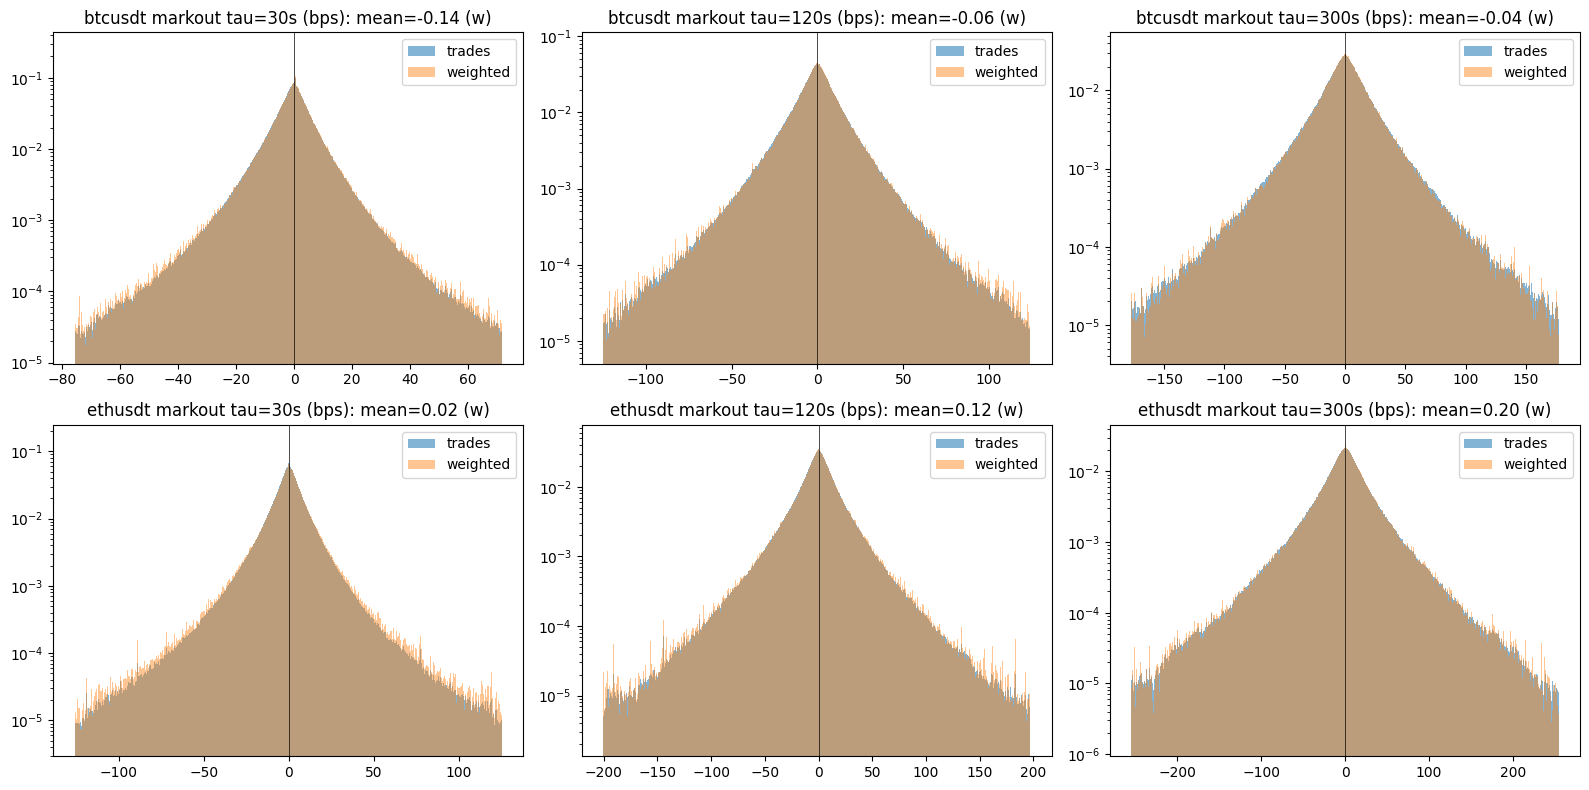

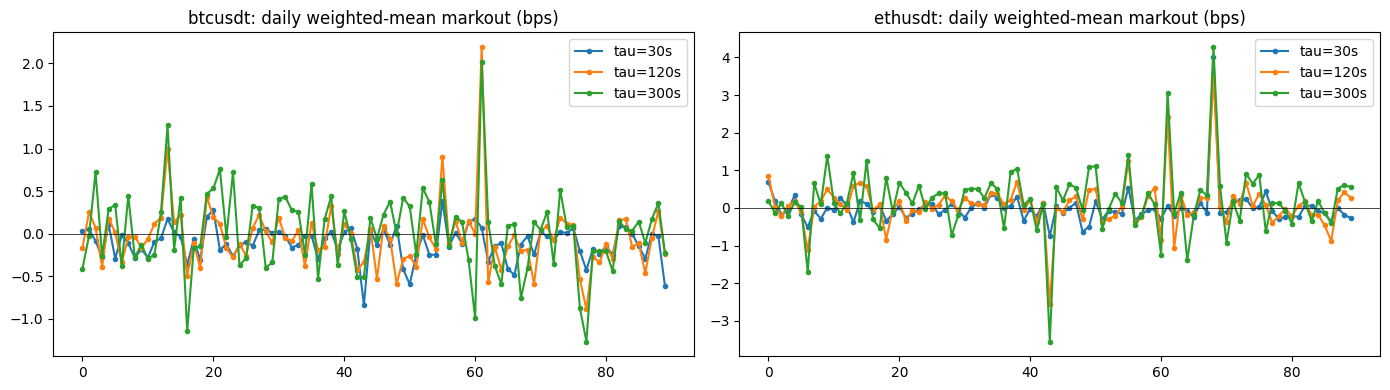

[stage E markouts] 1162.1s peak_rss=11.41GB


In [26]:
DAILY = AGG.group_by("sym", "day").agg([pl.col(f"{c}_{t}").sum() for t in TAUS for c in ("wp", "w", "n")]).sort("sym", "day")
rows = []
for sym in SYMS:
    D = DAILY.filter(pl.col("sym") == sym)
    for tau in TAUS:
        x = (D[f"wp_{tau}"] / D[f"w_{tau}"]).drop_nans().drop_nulls().to_numpy()
        rows.append(dict(sym=sym, tau=tau, days=len(x), mean_daily_wbps=float(x.mean()), std_daily_wbps=float(x.std(ddof=1)) if len(x) > 1 else np.nan, t_stat=float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 else np.nan,
                         share_days_positive=float((x > 0).mean()), worst_day_wbps=float(x.min()), best_day_wbps=float(x.max())))
DAYSTAB = pl.DataFrame(rows); print("Daily weighted-mean markout: is it consistent or driven by a few days?"); print(DAYSTAB)
WE = AGG.with_columns((((pl.col("day") + 3) % 7) >= 5).alias("weekend")); print("\nWeekend vs weekday"); print(summarise(WE, ["sym", "weekend"]).sort("sym", "weekend", "tau").select("sym", "weekend", "tau", "n", "mean_bps", "wmean_bps"))
HOUR = summarise(AGG, ["sym", "hour"]).sort("sym", "hour", "tau")

print("\nLiquidation state (W=60s): none / with-cascade (taker follows the liquidation) / against")
for W in CFG["STATE_WINDOWS_S"]:
    S = summarise(AGG, ["sym", f"st{W}"]).sort("sym", f"st{W}", "tau").with_columns(pl.col(f"st{W}").replace_strict({0: "none", 1: "with", 2: "against"}).alias("state"))
    tot = AGG.group_by("sym").agg(pl.col("w_all").sum().alias("w_total")); S = S.join(tot, on="sym").with_columns((pl.col("turnover_usd") / pl.col("w_total")).alias("share_of_valid_turnover_vs_all"))
    print(f"W={W}s, threshold USD={ {s: round(THR[s][W]) for s in SYMS} }"); print(S.select("sym", "state", "tau", "n", "wmean_bps", "mean_bps", "total_pnl_usd", "turnover_usd", "share_of_valid_turnover_vs_all"))
    S.write_csv(WORK / f"markout_by_state_w{W}.csv")

fig, ax = plt.subplots(len(SYMS), 3, figsize=(16, 4 * len(SYMS))); ax = np.atleast_2d(ax)
for j, sym in enumerate(SYMS):
    for i, tau in enumerate(TAUS):
        h = hist_merge(sym, tau); mid = 0.5 * (HIST_EDGES[:-1] + HIST_EDGES[1:]); lo, hi = hq(h, [.0005, .9995]); sel = (mid >= lo) & (mid <= hi)
        ax[j, i].bar(mid[sel], (h["c"][sel] / h["c"].sum() / 0.05), width=0.05, color="C0", alpha=.55, label="trades"); ax[j, i].bar(mid[sel], (h["w"][sel] / h["w"].sum() / 0.05), width=0.05, color="C1", alpha=.45, label="weighted")
        ax[j, i].set_yscale("log"); ax[j, i].axvline(0, c="k", lw=.5); ax[j, i].set_title(f"{sym} markout tau={tau}s (bps): mean={float(h['wp'].sum() / h['w'].sum()):.2f} (w)"); ax[j, i].legend()
fig.tight_layout(); show(fig, "e_markout_distribution.png")
fig, ax = plt.subplots(1, len(SYMS), figsize=(7 * len(SYMS), 4)); ax = np.atleast_1d(ax)
for j, sym in enumerate(SYMS):
    D = DAILY.filter(pl.col("sym") == sym)
    for tau, c in zip(TAUS, ("C0", "C1", "C2")): ax[j].plot(D["day"] - D0, D[f"wp_{tau}"] / D[f"w_{tau}"], "o-", ms=3, c=c, label=f"tau={tau}s")
    ax[j].axhline(0, c="k", lw=.5); ax[j].set_title(f"{sym}: daily weighted-mean markout (bps)"); ax[j].legend()
fig.tight_layout(); show(fig, "e_markout_daily.png")
mark("E markouts")

# G. Statistical financial time-series analysis on **simple returns**
Everything below uses the simple return `R = P_t / P_{t-h} - 1` (shown in bps) of the clean 1-second mid grid, never log returns.
* G1 distribution, percentiles/quintiles, stationarity (ADF + KPSS) · G2 ACF correlogram · G3 tail risk (Hill, POT, block maxima, time blocks)
* G4 joint distribution + copulas (BTC vs ETH) · G5 momentum / mean-reversion / lead-lag / statistical-arbitrage tests at tau = 30, 120, 300 s
Each block prints an **interpretation** (rule-based on the numbers, so it also reads correctly on your real data) collected in `interpretation_stats.txt`.
* **G2b return workflow: returns -> AR(11) -> residual tests -> seasonality -> GARCH-t / HAR-RV -> out-of-sample benchmarks** (new, runs before the tail work)

In [27]:
try: import statsmodels
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "statsmodels"], check=False)
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import genpareto, genextreme, norm, kendalltau, spearmanr, multivariate_t, multivariate_normal, binom, rankdata, t as tdist
from scipy.optimize import minimize_scalar

BAR_S = 60                    # bar length for the distribution / dependence / tail work (shorter bars = more microstructure noise)
TAKER_FEE_BPS = 4.5           # ASSUMPTION for cost tests (Binance USD-M taker, no VIP); change to your fee tier
INTERP = []
def say(m): INTERP.append(m); print("  >>", m)
SPLIT_ROW = np.array([split_of_day(D0 + i) for i in range(NDAYS_RANGE)])
QS_ALL = [.001, .01, .05, .20, .40, .50, .60, .80, .95, .99, .999]
RB = {}
for s in SYMS:
    R = ret_matrix(s, BAR_S); nd, nb = R.shape; day = np.repeat(np.arange(nd), nb); hr = np.tile((np.arange(nb) * BAR_S) // 3600, nd); f = R.ravel(); ok = np.isfinite(f)
    X = MM[s][:, ::BAR_S].ravel()
    RB[s] = dict(R=R, r=f[ok], day=day[ok], hour=np.minimum(hr[ok], 23), split=SPLIT_ROW[day[ok]], px=X[np.isfinite(X)])
print({s: len(RB[s]["r"]) for s in SYMS}, f"simple-return observations at {BAR_S}s bars")

{'btcusdt': 129489, 'ethusdt': 129486} simple-return observations at 60s bars


## G1. Distribution, percentiles / quintiles and stationarity
*Reading guide.* Prices should be **non-stationary** (ADF cannot reject a unit root, KPSS rejects stationarity); simple returns should be **stationary** (ADF rejects, KPSS does not).
Fat tails show as excess kurtosis >> 0 and extreme percentiles far outside the normal quantiles; the quintile table shows how much of the variance the extreme 20 % of bars carry.

/tmp/ipykernel_16/3872515251.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  try: k = kpss(x, regression="c", nlags="auto")[1]
/tmp/ipykernel_16/3872515251.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  try: k = kpss(x, regression="c", nlags="auto")[1]
/tmp/ipykernel_16/3872515251.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  try: k = kpss(x, regression="c", nlags="auto")[1]
/tmp/ipykernel_16/3872515251.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  try: k = kpss(x, regression="c", nlags

Simple returns, 60s bars, bps
shape: (2, 18)
┌─────────┬────────┬───────────┬───────────┬──────────┬───────────┬──────┬────────────┬────────────┬────────────┬───────────┬───────────┬─────┬──────────┬──────────┬───────────┬───────────┬───────────┐
│ sym     ┆ n      ┆ mean_bps  ┆ std_bps   ┆ skew     ┆ ex_kurt   ┆ jb_p ┆ p0.1       ┆ p1         ┆ p5         ┆ p20       ┆ p40       ┆ p50 ┆ p60      ┆ p80      ┆ p95       ┆ p99       ┆ p99.9     │
│ ---     ┆ ---    ┆ ---       ┆ ---       ┆ ---      ┆ ---       ┆ ---  ┆ ---        ┆ ---        ┆ ---        ┆ ---       ┆ ---       ┆ --- ┆ ---      ┆ ---      ┆ ---       ┆ ---       ┆ ---       │
│ str     ┆ i64    ┆ f64       ┆ f64       ┆ f64      ┆ f64       ┆ f64  ┆ f64        ┆ f64        ┆ f64        ┆ f64       ┆ f64       ┆ f64 ┆ f64      ┆ f64      ┆ f64       ┆ f64       ┆ f64       │
╞═════════╪════════╪═══════════╪═══════════╪══════════╪═══════════╪══════╪════════════╪════════════╪════════════╪═══════════╪═══════════╪═════╪════

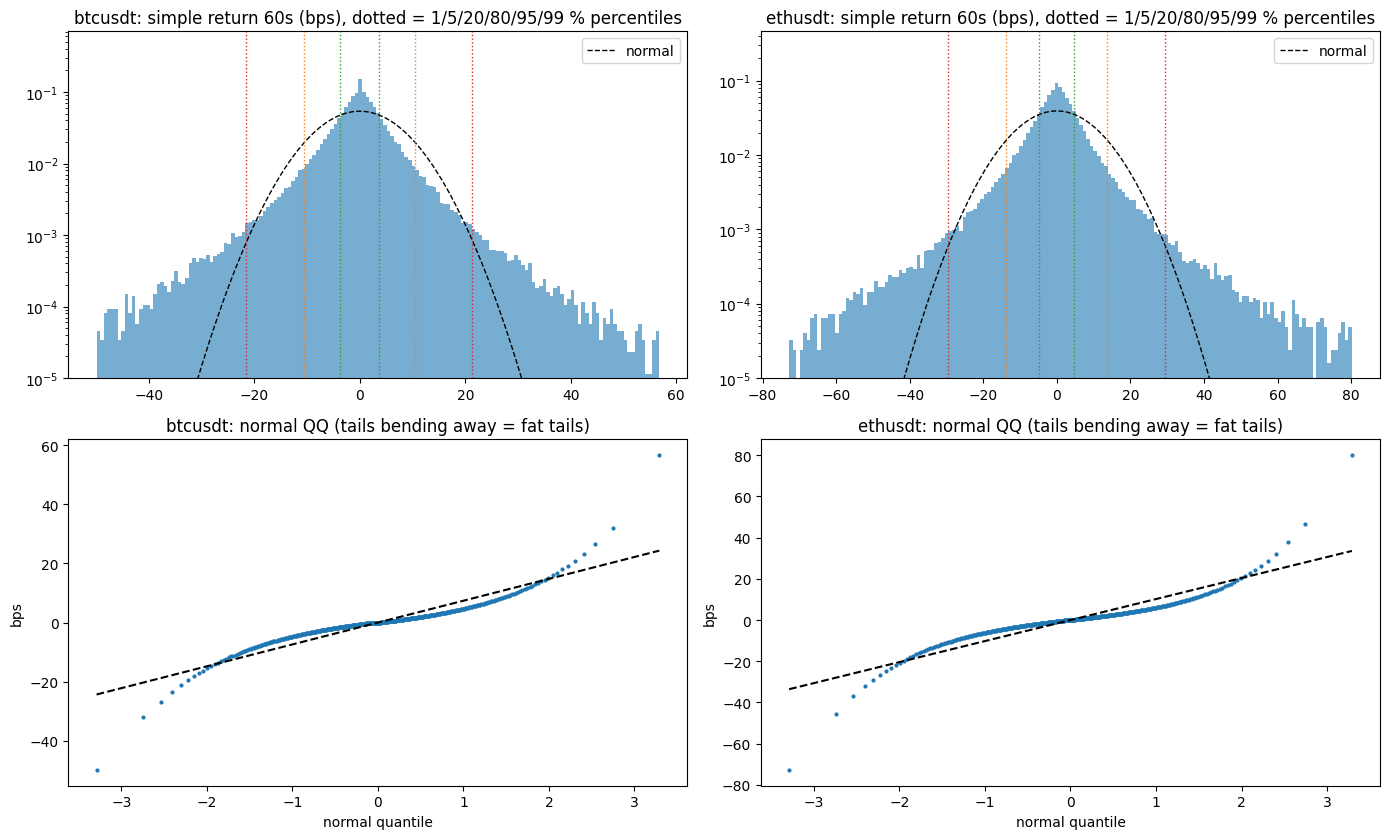

In [28]:
def adf_kpss(x, maxlag=20):
    try: a = adfuller(x, maxlag=maxlag, autolag="BIC")[1]
    except Exception: a = np.nan
    try: k = kpss(x, regression="c", nlags="auto")[1]
    except Exception: k = np.nan
    return a, k
rows, qrows, qin = [], [], []
for s in SYMS:
    x = RB[s]["r"]; n = len(x); mu, sd = x.mean(), x.std(); q = np.quantile(x, QS_ALL)
    rows.append(dict(sym=s, n=n, mean_bps=mu, std_bps=sd, skew=float(sps.skew(x)), ex_kurt=float(sps.kurtosis(x)), jb_p=float(sps.jarque_bera(x).pvalue), **{f"p{int(v*1000)/10:g}": float(a) for v, a in zip(QS_ALL, q)}))
    qrows.append(dict(sym=s, **{f"normal_p{int(v*1000)/10:g}": float(mu + sd * norm.ppf(v)) for v in QS_ALL}))
    ap, kp = adf_kpss(RB[s]["px"]); ar, kr = adf_kpss(x)
    qin.append(dict(sym=s, series="price level", adf_p=ap, kpss_p=kp, verdict="non-stationary (unit root)" if (ap > .05 and kp < .05) else ("stationary" if (ap < .05 and kp > .05) else "inconclusive")))
    qin.append(dict(sym=s, series="simple return", adf_p=ar, kpss_p=kr, verdict="stationary" if (ar < .05 and kr > .05) else ("non-stationary" if (ar > .05 and kr < .05) else "inconclusive (large n: KPSS over-rejects)")))
    e = np.quantile(x, [.2, .4, .6, .8]); b = np.digitize(x, e); tot = (x ** 2).sum()
    qrows[-1].update({f"var_share_Q{i+1}": float((x[b == i] ** 2).sum() / tot) for i in range(5)}); qrows[-1].update({f"mean_bps_Q{i+1}": float(x[b == i].mean()) for i in range(5)})
G1 = pl.DataFrame(rows); G1Q = pl.DataFrame(qrows); STAT = pl.DataFrame(qin)
G1.write_csv(WORK / "g1_return_percentiles.csv"); G1Q.write_csv(WORK / "g1_quintiles_vs_normal.csv"); STAT.write_csv(WORK / "g1_stationarity_adf_kpss.csv")
print(f"Simple returns, {BAR_S}s bars, bps"); print(G1); print("\nQuintile contributions and normal-implied percentiles"); print(G1Q); print("\nStationarity"); print(STAT)
for s in SYMS:
    g = G1.filter(pl.col("sym") == s).row(0, named=True); gq = G1Q.filter(pl.col("sym") == s).row(0, named=True)
    say(f"{s}: excess kurtosis {g['ex_kurt']:.1f}, skew {g['skew']:.2f}; 0.1 % percentile {g['p0.1']:.1f} bps vs normal {gq['normal_p0.1']:.1f} bps -> "
        + ("fat-tailed: Gaussian risk numbers understate extremes." if g["ex_kurt"] > 3 else "close to Gaussian at this bar size.")
        + f" The two outer quintiles carry {(gq['var_share_Q1'] + gq['var_share_Q5']) * 100:.0f} % of total squared return (a normal would give about 87 %; a larger share means variance is concentrated in rare big moves).")
    v = STAT.filter(pl.col("sym") == s); say(f"{s}: price level is {v['verdict'][0]}; simple returns are {v['verdict'][1]} (ADF p={v['adf_p'][1]:.3g}, KPSS p={v['kpss_p'][1]:.3g}) -> model returns, not prices; a mean-reversion edge in prices needs a cointegrated spread (G5).")

fig, ax = plt.subplots(2, len(SYMS), figsize=(7 * len(SYMS), 8.5)); ax = np.atleast_2d(ax).reshape(2, len(SYMS))
for j, s in enumerate(SYMS):
    x = RB[s]["r"]; lo, hi = np.quantile(x, [.0005, .9995]); ax[0, j].hist(x, bins=np.linspace(lo, hi, 160), density=True, color="C0", alpha=.6); gx = np.linspace(lo, hi, 300); ax[0, j].plot(gx, norm.pdf(gx, x.mean(), x.std()), "k--", lw=1, label="normal")
    for v, c in zip([.01, .05, .20, .80, .95, .99], ["C3", "C1", "C2", "C2", "C1", "C3"]): ax[0, j].axvline(np.quantile(x, v), c=c, lw=1, ls=":")
    ax[0, j].set_yscale("log"); ax[0, j].set_ylim(1e-5); ax[0, j].set_title(f"{s}: simple return {BAR_S}s (bps), dotted = 1/5/20/80/95/99 % percentiles"); ax[0, j].legend()
    p = np.linspace(.0005, .9995, 400); ax[1, j].plot(norm.ppf(p), np.quantile(x, p), "o", ms=2); a = norm.ppf([.0005, .9995]); ax[1, j].plot(a, x.mean() + x.std() * a, "k--"); ax[1, j].set_title(f"{s}: normal QQ (tails bending away = fat tails)"); ax[1, j].set_xlabel("normal quantile"); ax[1, j].set_ylabel("bps")
fig.tight_layout(); show(fig, "g1_distribution_percentiles.png")

## G2. ACF correlogram (returns, absolute returns, squared returns)
Bands are ±1.96/√n. `r` outside the band = predictability of direction (momentum if positive, bounce / mean reversion if negative);
`|r|` and `r²` outside the band = volatility clustering (size of moves is predictable even when direction is not).

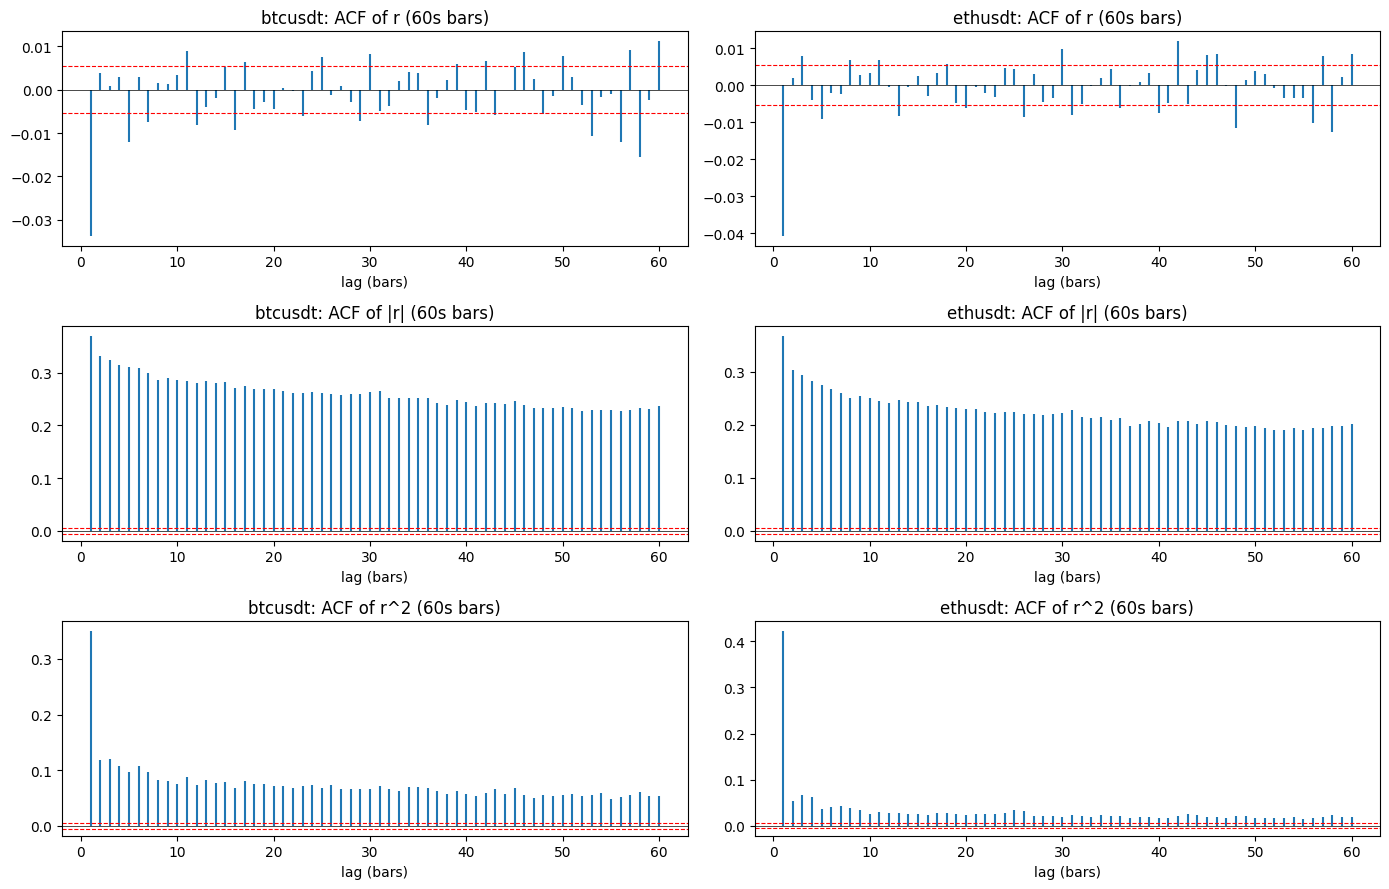

shape: (10, 5)
┌─────────┬────────────────────────────┬────────────┬────────────┬────────────┐
│ sym     ┆ series                     ┆ lag1       ┆ n_sig_lags ┆ max_abs    │
│ ---     ┆ ---                        ┆ ---        ┆ ---        ┆ ---        │
│ str     ┆ str                        ┆ f64        ┆ i64        ┆ f64        │
╞═════════╪════════════════════════════╪════════════╪════════════╪════════════╡
│ btcusdt ┆ r                          ┆ -0.033729  ┆ 23         ┆ 0.033729   │
│ btcusdt ┆ |r|                        ┆ 0.369454   ┆ 60         ┆ 0.369454   │
│ btcusdt ┆ r^2                        ┆ 0.350079   ┆ 60         ┆ 0.350079   │
│ btcusdt ┆ Ljung-Box p (r) lag10/60   ┆ 9.5174e-34 ┆ -1         ┆ 1.4388e-50 │
│ btcusdt ┆ Ljung-Box p (r^2) lag10/60 ┆ 0.0        ┆ -1         ┆ 0.0        │
│ ethusdt ┆ r                          ┆ -0.04078   ┆ 21         ┆ 0.04078    │
│ ethusdt ┆ |r|                        ┆ 0.367275   ┆ 60         ┆ 0.367275   │
│ ethusdt ┆ r^2          

In [29]:
NL = 60
fig, ax = plt.subplots(3, len(SYMS), figsize=(7 * len(SYMS), 9)); ax = np.atleast_2d(ax).reshape(3, len(SYMS)); ACFR = []
for j, s in enumerate(SYMS):
    R = RB[s]["R"]; n = len(RB[s]["r"]); band = 1.96 / np.sqrt(n)
    for i, (nm, M) in enumerate((("r", R), ("|r|", np.abs(R)), ("r^2", R ** 2))):
        a = acf_2d(M, NL); ax[i, j].vlines(np.arange(1, NL + 1), 0, a, color="C0"); ax[i, j].axhline(band, c="r", ls="--", lw=.8); ax[i, j].axhline(-band, c="r", ls="--", lw=.8); ax[i, j].axhline(0, c="k", lw=.5)
        ax[i, j].set_title(f"{s}: ACF of {nm} ({BAR_S}s bars)"); ax[i, j].set_xlabel("lag (bars)"); ACFR.append(dict(sym=s, series=nm, lag1=a[0], n_sig_lags=int((np.abs(a) > band).sum()), max_abs=float(np.abs(a).max())))
    lbp = acorr_ljungbox(RB[s]["r"], lags=[10, NL], return_df=True)["lb_pvalue"].values; lbq = acorr_ljungbox(RB[s]["r"] ** 2, lags=[10, NL], return_df=True)["lb_pvalue"].values
    ACFR.append(dict(sym=s, series="Ljung-Box p (r) lag10/60", lag1=float(lbp[0]), n_sig_lags=-1, max_abs=float(lbp[1]))); ACFR.append(dict(sym=s, series="Ljung-Box p (r^2) lag10/60", lag1=float(lbq[0]), n_sig_lags=-1, max_abs=float(lbq[1])))
fig.tight_layout(); show(fig, "g2_acf_correlogram.png"); ACFT = pl.DataFrame(ACFR); ACFT.write_csv(WORK / "g2_acf_summary.csv"); print(ACFT)
for s in SYMS:
    t = ACFT.filter(pl.col("sym") == s); r1 = t.filter(pl.col("series") == "r")["lag1"][0]; ar1 = t.filter(pl.col("series") == "|r|")["lag1"][0]; ns = t.filter(pl.col("series") == "|r|")["n_sig_lags"][0]
    say(f"{s}: lag-1 ACF of r = {r1:+.3f} -> " + ("negative: bounce / mean reversion at this horizon." if r1 < -0.02 else "positive: short-horizon momentum." if r1 > 0.02 else "no linear directional memory (efficient at this horizon)."))
    say(f"{s}: ACF of |r| lag1 = {ar1:.2f}, {ns}/{NL} lags significant -> " + ("strong volatility clustering: use a GARCH-type or regime-conditioned risk model; size positions by recent volatility." if ar1 > 0.1 else "weak volatility clustering."))

## G2b. Return workflow before any variance model: returns -> AR(11) -> residuals -> seasonality -> GARCH / HAR -> benchmarks
The order matters. (1) the return checks above (ADF/KPSS, ACF, Ljung-Box) say whether there is any linear structure to model;
(2) an **AR(p)** model removes it (order by AIC/BIC, then AR(11) as the working model, fitted on **train days only**, judged on validation days);
(3) the **residuals** are tested: if they are white in level but not in squares/absolute value, the remaining structure is *variance*, not mean;
(4) intraday seasonality (30-minute bins, weekday/weekend) is removed from the residuals so a GARCH is not just learning the clock;
(5) GARCH-t / GJR-t / EGARCH-t and a HAR-RV regression on **three time frames (5 min, 1 h, 1 day)** model the variance;
(6) every model is benchmarked out of sample against a constant variance and EWMA, with a Diebold-Mariano test and a VaR back-test;
(7) the **standardised residuals** are what the tail work (Hill / POT) should use.
Lags never cross a day boundary or a data gap, so no regressor mixes two separate sessions. RAM: only `days x 1440` matrices (about 1 MB each).

In [30]:
try: from arch import arch_model
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arch"], check=False)
    from arch import arch_model
import statsmodels.api as sm
from scipy.signal import lfilter
from numba import njit
from scipy.stats import chi2, binom

AR_P, AR_MAX, ARCH_LAGS = 11, 30, 20
NB_ = RB[SYMS[0]]["R"].shape[1]; ND_ = RB[SYMS[0]]["R"].shape[0]
TRD = np.array([x == "train" for x in SPLIT_ROW]); VAD = np.array([x == "val" for x in SPLIT_ROW])
WKD = np.array([date_of_day(D0 + i).weekday() >= 5 for i in range(ND_)])
BIN_BARS = max(1800 // BAR_S, 1); NBIN = NB_ // BIN_BARS + (NB_ % BIN_BARS > 0)

def lag_design(M, p, extra=None):
    """M: days x bars (NaN = missing). Returns target y, lag matrix X (n x p) and the (day, bar) of each target; lags stay inside the day."""
    nd, nb = M.shape; Y = M[:, p:]; cols = [M[:, p - k:nb - k] for k in range(1, p + 1)]
    if extra is not None: cols += [extra[:, p - k:nb - k] for k in range(1, p + 1)]
    ok = np.isfinite(Y)
    for c in cols: ok &= np.isfinite(c)
    di, bi = np.nonzero(ok); return Y[ok], np.column_stack([c[ok] for c in cols]), di, bi + p
def ols_fit(y, X): Z = np.column_stack([np.ones(len(y)), X]); b = np.linalg.lstsq(Z, y, rcond=None)[0]; return b, Z
def r2_oos(y, pred, bench): return 1 - np.sum((y - pred) ** 2) / np.sum((y - bench) ** 2)

def lb_matrix(E, m):
    """classical Ljung-Box and a heteroskedasticity-robust version (each lag scaled by its own fourth-moment), on a days x bars matrix"""
    E = E - np.nanmean(E); n = int(np.isfinite(E).sum()); a = acf_2d(E, m); Q = n * (n + 2) * np.sum(a ** 2 / (n - np.arange(1, m + 1))); qr = 0.0
    for k in range(1, m + 1):
        x, y = E[:, :-k], E[:, k:]; ok = np.isfinite(x) & np.isfinite(y); pr = x[ok] * y[ok]
        qr += pr.sum() ** 2 / max(ok.sum(), 1) / max((pr ** 2).mean(), 1e-300) if ok.sum() else 0.0
    return float(chi2.sf(Q, m)), float(chi2.sf(qr, m))
def arch_lm(E, m):
    y, X, _, _ = lag_design(E ** 2, m); b, Z = ols_fit(y, X); r2 = 1 - np.sum((y - Z @ b) ** 2) / np.sum((y - y.mean()) ** 2); return float(chi2.sf(len(y) * r2, m))
def resid_diag(E, tag, sym):
    rows = []
    for nm, M in (("e", E), ("e^2", E ** 2), ("|e|", np.abs(E))):
        p_lb, p_rob = lb_matrix(M, 10)
        rows.append(dict(sym=sym, stage=tag, series=nm, lb10_p=p_lb, lb10_robust_p=p_rob if nm == "e" else np.nan))
    rows[0]["arch_lm_p"] = arch_lm(E, ARCH_LAGS); return rows

def dm_test(d, lag=30):
    d = d - 0; n = len(d); dc = d - d.mean(); v = dc @ dc / n
    for k in range(1, lag + 1): v += 2 * (1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / n
    t = d.mean() / np.sqrt(max(v, 1e-300) / n); return float(t), float(2 * norm.sf(abs(t)))
def kupiec(x, n, p):
    if n == 0: return np.nan
    ph = min(max(x / n, 1e-12), 1 - 1e-12); ll0 = (n - x) * np.log(1 - p) + x * np.log(p); ll1 = (n - x) * np.log(1 - ph) + x * np.log(ph); return float(chi2.sf(-2 * (ll0 - ll1), 1))

@njit(cache=True)
def _garch_h(u, w, a, b, g, h0):
    """frozen-parameter GJR(1,1) variance; a missing u (NaN) is replaced by its expectation (so the filter keeps running across gaps). g=0 gives GARCH."""
    n = len(u); h = np.empty(n); h[0] = h0
    for t in range(1, n):
        x = u[t - 1]
        if np.isnan(x): h[t] = w + (a + 0.5 * g + b) * h[t - 1]
        else: h[t] = w + (a + (g if x < 0 else 0.0)) * x * x + b * h[t - 1]
    return h
def ewma_h(u, lam):
    q = np.where(np.isnan(u), np.nan, u ** 2); h = np.empty(len(u)); h[0] = 1.0
    for t in range(1, len(u)): h[t] = lam * h[t - 1] + (1 - lam) * (h[t - 1] if np.isnan(q[t - 1]) else q[t - 1])
    return h
def gauss_loss(u, h): ok = np.isfinite(u) & (h > 0); return u[ok] ** 2 / h[ok] + np.log(h[ok]), ok

AR_OUT, ORD_OUT, COEF_OUT, DIAG_OUT, SEAS_OUT, VOL_OUT, STD_OUT, HARC_OUT, XA_OUT, GP_OUT = [], [], [], [], [], [], [], [], [], []
E_MAT, U_MAT, H_MAT, Z_MAT, SEAS = {}, {}, {}, {}, {}
RAW = {s: RB[s]["R"] for s in SYMS}
for s in SYMS:
    R = RAW[s]; dmu = np.nanmean(R[TRD])
    # ---- step 2: AR order by AIC/BIC on the common train sample, then AR(11) -------------------------------------------------------
    y, X, di, bi = lag_design(R, AR_MAX); tr = TRD[di]; yt, Xt = y[tr], X[tr]; n = len(yt)
    for p in range(0, AR_MAX + 1):
        if p == 0: rss = np.sum((yt - yt.mean()) ** 2)
        else: b, Z = ols_fit(yt, Xt[:, :p]); rss = np.sum((yt - Z @ b) ** 2)
        ORD_OUT.append(dict(sym=s, p=p, n=n, aic=n * np.log(rss / n) + 2 * (p + 1), bic=n * np.log(rss / n) + (p + 1) * np.log(n)))
    O = [r for r in ORD_OUT if r["sym"] == s]; p_aic = min(O, key=lambda r: r["aic"])["p"]; p_bic = min(O, key=lambda r: r["bic"])["p"]
    y, X, di, bi = lag_design(R, AR_P); tr, va = TRD[di], VAD[di]; Z = np.column_stack([np.ones(len(y)), X])
    res = sm.OLS(y[tr], Z[tr]).fit(cov_type="HAC", cov_kwds=dict(maxlags=ARCH_LAGS)); b = np.asarray(res.params)
    for k in range(AR_P + 1): COEF_OUT.append(dict(sym=s, term="const" if k == 0 else f"lag{k}", coef=float(res.params[k]), hac_se=float(res.bse[k]), t=float(res.tvalues[k])))
    try: wald_p = float(res.wald_test(np.eye(AR_P + 1)[1:], scalar=True).pvalue)
    except Exception: wald_p = np.nan
    pred = Z @ b; yv, pv = y[va], pred[va]; hit_n = int((pv != 0).sum()); hits = int(((np.sign(pv) == np.sign(yv)) & (pv != 0)).sum())
    pnl = np.sign(pv) * yv
    AR_OUT.append(dict(sym=s, bars=BAR_S, p_aic=p_aic, p_bic=p_bic, ar_p=AR_P, n_train=int(tr.sum()), n_val=int(va.sum()), r2_in=float(res.rsquared), r2_oos=float(r2_oos(yv, pv, y[tr].mean())),
                       wald_all_lags_p=wald_p, hit_rate_val=hits / max(hit_n, 1), hit_p=float(binom.sf(hits - 1, hit_n, .5)) if hit_n else np.nan, mean_abs_pred_bps=float(np.abs(pv).mean()),
                       gross_bps_per_bar_val=float(pnl.mean()), taker_roundtrip_bps=2 * TAKER_FEE_BPS, std_ret_bps=float(R[np.isfinite(R)].std())))
    E = np.full(R.shape, np.nan); E[di, bi] = y - pred; E_MAT[s] = E
    DIAG_OUT += resid_diag(E, "AR(11) residual", s)
    # ---- step 3b: does the other asset add information (VAR-style Granger test, 11 lags)? ------------------------------------------
    o = [x for x in SYMS if x != s]
    if o:
        y2, X2, di2, bi2 = lag_design(R, AR_P, extra=RAW[o[0]]); tr2, va2 = TRD[di2], VAD[di2]; Z2 = np.column_stack([np.ones(len(y2)), X2])
        r_u = sm.OLS(y2[tr2], Z2[tr2]).fit(cov_type="HAC", cov_kwds=dict(maxlags=ARCH_LAGS)); Rm = np.zeros((AR_P, Z2.shape[1])); Rm[np.arange(AR_P), 1 + AR_P + np.arange(AR_P)] = 1
        try: gp = float(r_u.wald_test(Rm, scalar=True).pvalue)
        except Exception: gp = np.nan
        r2a = r2_oos(y2[va2], Z2[va2] @ np.asarray(r_u.params), y2[tr2].mean())
        XA_OUT.append(dict(sym=s, other=o[0], granger_p=gp, lag1_other_coef=float(r_u.params[1 + AR_P]), lag1_other_t=float(r_u.tvalues[1 + AR_P]), r2_oos_own_only=AR_OUT[-1]["r2_oos"], r2_oos_with_other=float(r2a)))
    # ---- step 4: intraday + weekend seasonality from train residuals (squares capped at the 99.9% quantile for the estimate only) ----
    e2 = E ** 2; cap = np.nanquantile(e2[TRD], .999); e2c = np.minimum(e2, cap); binidx = np.minimum(np.arange(NB_) // BIN_BARS, NBIN - 1)
    S = np.full((2, NBIN), np.nan); pooled = np.nanmean(e2c[TRD])
    for w in (0, 1):
        for bn in range(NBIN):
            blk = e2c[TRD & (WKD == bool(w))][:, binidx == bn]; S[w, bn] = np.nanmean(blk) if np.isfinite(blk).sum() > 200 else pooled
    S = S / np.nanmean(e2c[TRD] / S[WKD[TRD].astype(int)][:, binidx]); SEAS[s] = S
    scale = np.sqrt(S[WKD.astype(int)][:, binidx]); U = E / scale; U_MAT[s] = U
    for w in (0, 1):
        for bn in range(NBIN): SEAS_OUT.append(dict(sym=s, weekend=w, bin30=bn, scale_bps=float(np.sqrt(S[w, bn] * pooled))))
    DIAG_OUT += resid_diag(U, "after seasonality", s)
    # ---- step 5a: one-minute variance models, train fit, frozen parameters out of sample --------------------------------------------
    ut = U[TRD]; ut = ut[np.isfinite(ut)]; uf = U.ravel(); trf = np.repeat(TRD, NB_); vaf = np.repeat(VAD, NB_); fin = np.isfinite(uf)
    P = {}; MODELS = {}
    for kind, spec in (("GARCH", dict(vol="GARCH", p=1, q=1)), ("GJR", dict(vol="GARCH", p=1, o=1, q=1)), ("EGARCH", dict(vol="EGARCH", p=1, o=1, q=1))):
        r = arch_model(ut, mean="Zero", dist="t", rescale=False, **spec).fit(disp="off", options={"maxiter": 600}); pr = r.params; P[kind] = r
        nu = float(pr["nu"]); alpha = float(pr["alpha[1]"]); beta = float(pr["beta[1]"]); gam = float(pr["gamma[1]"]) if "gamma[1]" in pr.index else 0.0
        pers = alpha + beta + (gam / 2 if kind == "GJR" else 0.0) if kind != "EGARCH" else beta
        VOL_OUT.append(dict(sym=s, model=kind, section="fit_train", omega=float(pr["omega"]), alpha=alpha, beta=beta, gamma=gam, nu=nu, persistence=pers, half_life_bars=(np.log(.5) / np.log(pers) if 0 < pers < 1 else np.nan),
                            loglik=float(r.loglikelihood), aic=float(r.aic), bic=float(r.bic), n=len(ut)))
    HM = {}
    for kind in ("GARCH", "GJR"):
        pr = P[kind].params; g = float(pr["gamma[1]"]) if kind == "GJR" else 0.0; HM[kind] = _garch_h(uf, float(pr["omega"]), float(pr["alpha[1]"]), float(pr["beta[1]"]), g, 1.0)
    lams = [.80, .85, .90, .94, .96, .97, .98, .99, .995]; lt = []
    for lam in lams: l, ok = gauss_loss(uf[trf], ewma_h(uf, lam)[trf]); lt.append(l.mean())
    lam_best = lams[int(np.argmin(lt))]; HM["EWMA_tuned"] = ewma_h(uf, lam_best); HM["EWMA_0.94"] = ewma_h(uf, .94); HM["const"] = np.ones_like(uf)
    LV = {k: gauss_loss(uf[vaf], h[vaf])[0] for k, h in HM.items()}; okv = gauss_loss(uf[vaf], HM["const"][vaf])[1]
    for k in HM:
        base = LV["EWMA_0.94"]; t_, p_ = dm_test(LV[k] - base) if k != "EWMA_0.94" else (np.nan, np.nan)
        VOL_OUT.append(dict(sym=s, model=k, section="oos_1min", gauss_loss=float(LV[k].mean()), loss_vs_const=float(LV[k].mean() - LV["const"].mean()), dm_t_vs_ewma094=t_, dm_p_vs_ewma094=p_, lam=lam_best if k == "EWMA_tuned" else np.nan, n=int(len(LV[k]))))
    H_MAT[s] = HM["GARCH"].reshape(U.shape); Z = uf / np.sqrt(HM["GARCH"]); Z_MAT[s] = Z.reshape(U.shape)
    # VaR back-test on validation days: t-GARCH versus Gaussian EWMA 0.94 (exception rate should equal the nominal level)
    nu = float(P["GARCH"].params["nu"]); zv = uf[vaf][okv]
    for pl_ in ((.01, .05) if len(zv) else ()):
        for k, h, qf in (("GARCH-t", HM["GARCH"], tdist.ppf(pl_, nu) * np.sqrt((nu - 2) / nu)), ("EWMA-normal", HM["EWMA_0.94"], norm.ppf(pl_)), ("const-normal", HM["const"], norm.ppf(pl_))):
            hv = h[vaf][okv]; x = int((zv < qf * np.sqrt(hv)).sum()); VOL_OUT.append(dict(sym=s, model=k, section=f"var_{int(pl_ * 100)}pct", exc_rate=x / len(zv), nominal=pl_, kupiec_p=kupiec(x, len(zv), pl_), n=len(zv)))
    # standardised residuals: what is left after mean + seasonality + variance
    zz = Z_MAT[s]; DIAG_OUT += resid_diag(zz, "standardised by GARCH-t", s)
    zf = zz[np.isfinite(zz)]; zn, zp = -zf[zf < 0], zf[zf > 0]
    STD_OUT.append(dict(sym=s, nu_garch=nu, ex_kurt_raw=float(sps.kurtosis(RAW[s][np.isfinite(RAW[s])])), ex_kurt_after_ar=float(sps.kurtosis(E[np.isfinite(E)])), ex_kurt_std=float(sps.kurtosis(zf)),
                        hill_alpha_raw_loss=float(hill(np.abs(RAW[s][RAW[s] < 0]), .05)), hill_alpha_std_loss=float(hill(zn, .05)), hill_alpha_std_gain=float(hill(zp, .05)), ewma_lambda=lam_best, season_dm_note="scale fitted on train"))
    # ---- step 5b/6: five-minute variance forecast, HAR-RV on three time frames versus GARCH-type / EWMA / constant --------------------
    k5 = 300 // BAR_S; n5 = NB_ // k5; r2m = (R[:, :n5 * k5] ** 2).reshape(ND_, n5, k5); cnt = np.isfinite(r2m).sum(2)
    RV = np.where(cnt >= max(k5 - 1, 1), np.nansum(r2m, 2) * k5 / np.maximum(cnt, 1), np.nan); b5 = np.minimum(np.arange(n5) * k5 // BIN_BARS, NBIN - 1)
    cap5 = np.nanquantile(RV[TRD], .999); S5 = np.full((2, NBIN), np.nan); p5 = np.nanmean(np.minimum(RV, cap5)[TRD])
    for w in (0, 1):
        for bn in range(NBIN):
            blk = np.minimum(RV, cap5)[TRD & (WKD == bool(w))][:, b5 == bn]; S5[w, bn] = np.nanmean(blk) if np.isfinite(blk).sum() > 100 else p5
    V = (RV / S5[WKD.astype(int)][:, b5]).ravel(); T5 = np.repeat(TRD, n5); V5 = np.repeat(VAD, n5); vm = np.nanmean(V[T5])
    def roll(v, w):
        c = np.cumsum(np.where(np.isnan(v), 0, v)); n_ = np.cumsum(~np.isnan(v)); c0 = np.concatenate([np.zeros(w), c[:-w]]); n0 = np.concatenate([np.zeros(w), n_[:-w]]); return (c - c0) / np.maximum(n_ - n0, 1)
    H1h, H1d = 12, 288; x1 = V; x2 = roll(V, H1h); x3 = roll(V, H1d); tgt = np.concatenate([V[1:], [np.nan]]); tmask = np.concatenate([T5[1:], [False]]) & np.isfinite(tgt) & np.isfinite(x1)
    vmask = np.concatenate([V5[1:], [False]]) & np.isfinite(tgt) & np.isfinite(x1); XH = np.column_stack([np.ones(len(V)), x1, x2, x3]); XH[~np.isfinite(XH)] = np.nan; tmask &= np.isfinite(XH).all(1); vmask &= np.isfinite(XH).all(1)
    hr = sm.OLS(tgt[tmask], XH[tmask]).fit(cov_type="HAC", cov_kwds=dict(maxlags=H1h)); fh = np.maximum(XH @ np.asarray(hr.params), 0.05)
    for nm, c_, se, t_ in zip(["const", "RV_5min", "RV_1hour", "RV_1day"], hr.params, hr.bse, hr.tvalues): HARC_OUT.append(dict(sym=s, term=nm, coef=float(c_), hac_se=float(se), t=float(t_), r2_in=float(hr.rsquared), n_train=int(tmask.sum())))
    # GARCH-type multi-step forecast of the next five-minute bar: needs the variance at the first minute of that bar
    first_next = np.minimum((np.arange(n5) + 1) * k5, NB_ - 1)
    def h5(HMk, w, a, b, g):
        h1 = HMk.reshape(ND_, NB_)[:, first_next]; phi = min(a + b + g / 2, 0.9999); unc = w / (1 - phi) if (a + b + g / 2) < 0.9999 else 1.0; f = sum(unc + phi ** j * (h1 - unc) for j in range(k5)) / k5; f = np.concatenate([np.full((ND_, 1), np.nan), f[:, :-1]], axis=1); return f.ravel()
    FC = {"HAR-RV (5min,1h,1d)": fh, "const": np.full(len(V), vm)}
    for kind in ("GARCH", "GJR"):
        pr = P[kind].params; FC[f"{kind}-t"] = h5(HM[kind], float(pr["omega"]), float(pr["alpha[1]"]), float(pr["beta[1]"]), float(pr["gamma[1]"]) if kind == "GJR" else 0.0)
    ew = HM["EWMA_tuned"].reshape(ND_, NB_)[:, first_next]; FC["EWMA(tuned)"] = np.concatenate([np.full((ND_, 1), np.nan), ew[:, :-1]], axis=1).ravel()
    # align: forecast for bar t+1 made at end of bar t -> shift by one bar for the GARCH-type rows (already built "for this bar"); HAR row predicts t+1 from t, so shift it to "this bar" as well
    FC["HAR-RV (5min,1h,1d)"] = np.concatenate([[np.nan], fh[:-1]])
    mt = np.isfinite(V) & T5; mv = np.isfinite(V) & V5; base = "HAR-RV (5min,1h,1d)"; cmn = mv.copy(); SC = {}
    for k, f in FC.items():
        f = np.asarray(f, float); FC[k] = f; okt = mt & np.isfinite(f) & (f > 0); SC[k] = 1.0 if k in (base, "const") else np.nanmean(V[okt]) / np.nanmean(f[okt])   # one scale fitted on train for 1-minute-scale models
        cmn &= np.isfinite(f) & (f > 0)
    QLV = {}
    for k, f in FC.items(): r_ = np.maximum(V[cmn], 1e-6) / (SC[k] * f[cmn]); QLV[k] = r_ - np.log(r_) - 1
    for k in QLV:
        t_, p_ = dm_test(QLV[k] - QLV[base]) if k != base else (np.nan, np.nan)
        VOL_OUT.append(dict(sym=s, model=k, section="oos_5min_next_bar", qlike=float(QLV[k].mean()), dm_t_vs_har=t_, dm_p_vs_har=p_, n=int(cmn.sum()), har_r2_in=float(hr.rsquared) if k == base else np.nan))
    del r2m, RV; gc.collect()

# ---- tables ---------------------------------------------------------------------------------------------------------------------
G2A = pl.DataFrame(AR_OUT); G2O = pl.DataFrame(ORD_OUT); G2C = pl.DataFrame(COEF_OUT); G2D = pl.DataFrame(DIAG_OUT, infer_schema_length=None); G2S = pl.DataFrame(SEAS_OUT)
G2V = pl.DataFrame(VOL_OUT, infer_schema_length=None); G2T = pl.DataFrame(STD_OUT); G2H = pl.DataFrame(HARC_OUT)
for nm, d in (("g2b_ar_summary", G2A), ("g2b_ar_order", G2O), ("g2b_ar_coef", G2C), ("g2b_residual_diagnostics", G2D), ("g2b_seasonality", G2S), ("g2b_variance_models", G2V), ("g2b_std_residuals", G2T), ("g2b_har_coef", G2H)): d.write_csv(WORK / f"{nm}.csv")
if XA_OUT: GX = pl.DataFrame(XA_OUT); GX.write_csv(WORK / "g2b_cross_asset_ar.csv")
print(f"STEP 2  AR(p) on simple returns, {BAR_S}s bars (train {int(TRD.sum())} d, validation {int(VAD.sum())} d)"); print(G2A)
print("\nSTEP 3  residual diagnostics (p-values; small p = structure left)"); print(G2D)
print("\nSTEP 5-6 variance models"); print(G2V)
if XA_OUT: print("\nCross-asset (Granger-style) test"); print(GX)
print("\nStandardised residuals"); print(G2T)

# ---- interpretation (rule based on the numbers) ------------------------------------------------------------------------------------
for s in SYMS:
    a = G2A.filter(pl.col("sym") == s).row(0, named=True)
    say(f"{s} AR: AIC picks p={a['p_aic']}, BIC picks p={a['p_bic']}; AR({AR_P}) in-sample R^2 = {a['r2_in'] * 100:.3f} %, validation R^2 = {a['r2_oos'] * 100:.3f} % (joint Wald p = {a['wald_all_lags_p']:.2g}). "
        + ("The mean is close to unpredictable: the linear structure is tiny, so AR(11) is a clean-up step, not an alpha source." if a["r2_oos"] < 0.01 else "A non-trivial linear component remains on validation days; test it net of costs."))
    say(f"{s} AR trade check: sign-of-forecast hit rate {a['hit_rate_val'] * 100:.2f} % on validation (p vs 50 % = {a['hit_p']:.2g}); gross {a['gross_bps_per_bar_val']:.3f} bps per bar against a {a['taker_roundtrip_bps']:.1f} bps taker round trip -> "
        + ("not tradable after costs." if a["gross_bps_per_bar_val"] < a["taker_roundtrip_bps"] else "worth testing with realistic fills."))
    d = G2D.filter(pl.col("sym") == s); g = lambda st, se, c: d.filter((pl.col("stage") == st) & (pl.col("series") == se))[c][0]
    say(f"{s} residuals: after AR({AR_P}) the Ljung-Box p on e is {g('AR(11) residual', 'e', 'lb10_p'):.2g} (robust {g('AR(11) residual', 'e', 'lb10_robust_p'):.2g}) but p on e^2 is {g('AR(11) residual', 'e^2', 'lb10_p'):.2g} and ARCH-LM p {g('AR(11) residual', 'e', 'arch_lm_p'):.2g} "
        + ("-> the mean is white yet the variance clusters: model the variance (GARCH / HAR), not more AR lags." if g('AR(11) residual', 'e^2', 'lb10_p') < .05 else "-> no variance clustering left at this bar size."))
    say(f"{s} after seasonality + GARCH-t: Ljung-Box p on z^2 = {g('standardised by GARCH-t', 'e^2', 'lb10_p'):.2g}, ARCH-LM p = {g('standardised by GARCH-t', 'e', 'arch_lm_p'):.2g} "
        + ("(clustering removed)." if g('standardised by GARCH-t', 'e^2', 'lb10_p') > .05 else "(some clustering remains, typical at very large n; check the size of the ACF, not only the p-value)."))
    v = G2V.filter((pl.col("sym") == s) & (pl.col("section") == "fit_train") & (pl.col("model") == "GARCH")).row(0, named=True); t = G2T.filter(pl.col("sym") == s).row(0, named=True)
    say(f"{s} GARCH-t: persistence {v['persistence']:.3f} (shock half-life {v['half_life_bars']:.0f} bars), nu = {v['nu']:.1f}; excess kurtosis falls {t['ex_kurt_raw']:.1f} -> {t['ex_kurt_after_ar']:.1f} (after AR) -> {t['ex_kurt_std']:.1f} (standardised); Hill index of losses {t['hill_alpha_raw_loss']:.2f} -> {t['hill_alpha_std_loss']:.2f}.")
    o1 = G2V.filter((pl.col("sym") == s) & (pl.col("section") == "oos_1min")); bm = o1.sort("gauss_loss").row(0, named=True)
    say(f"{s} 1-minute out-of-sample variance loss: best is {bm['model']}; improvement over a constant variance {-bm['loss_vs_const']:.4f} nats/obs." )
    o5 = G2V.filter((pl.col("sym") == s) & (pl.col("section") == "oos_5min_next_bar")).sort("qlike"); b5_ = o5.row(0, named=True)
    say(f"{s} 5-minute next-bar variance (QLIKE, lower better): ranking " + " < ".join(f"{r['model']} {r['qlike']:.3f}" for r in o5.iter_rows(named=True)) + f". Winner: {b5_['model']}.")
if XA_OUT:
    for r in GX.iter_rows(named=True): say(f"{r['sym']}: adding 11 lags of {r['other']} -> Granger p = {r['granger_p']:.2g}, validation R^2 {r['r2_oos_own_only'] * 100:.3f} % -> {r['r2_oos_with_other'] * 100:.3f} % ({'cross-asset lead-lag exists but check cost' if r['granger_p'] < .01 else 'no cross-asset predictability at this bar size'}).")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 14.0 MB/s eta 0:00:00
STEP 2  AR(p) on simple returns, 60s bars (train 62 d, validation 28 d)
shape: (2, 16)
┌─────────┬──────┬───────┬───────┬──────┬─────────┬───────┬──────────┬───────────┬─────────────────┬──────────────┬────────────┬───────────────────┬───────────────────────┬─────────────────────┬─────────────┐
│ sym     ┆ bars ┆ p_aic ┆ p_bic ┆ ar_p ┆ n_train ┆ n_val ┆ r2_in    ┆ r2_oos    ┆ wald_all_lags_p ┆ hit_rate_val ┆ hit_p      ┆ mean_abs_pred_bps ┆ gross_bps_per_bar_val ┆ taker_roundtrip_bps ┆ std_ret_bps │
│ ---     ┆ ---  ┆ ---   ┆ ---   ┆ ---  ┆ ---     ┆ ---   ┆ ---      ┆ ---       ┆ ---             ┆ ---          ┆ ---        ┆ ---               ┆ ---                   ┆ ---                 ┆ ---         │
│ str     ┆ i64  ┆ i64   ┆ i64   ┆ i64  ┆ i64     ┆ i64   ┆ f64      ┆ f64       ┆ f64             ┆ f64          ┆ f64        ┆ f64               ┆ f64                   ┆ f64                 ┆ f64       

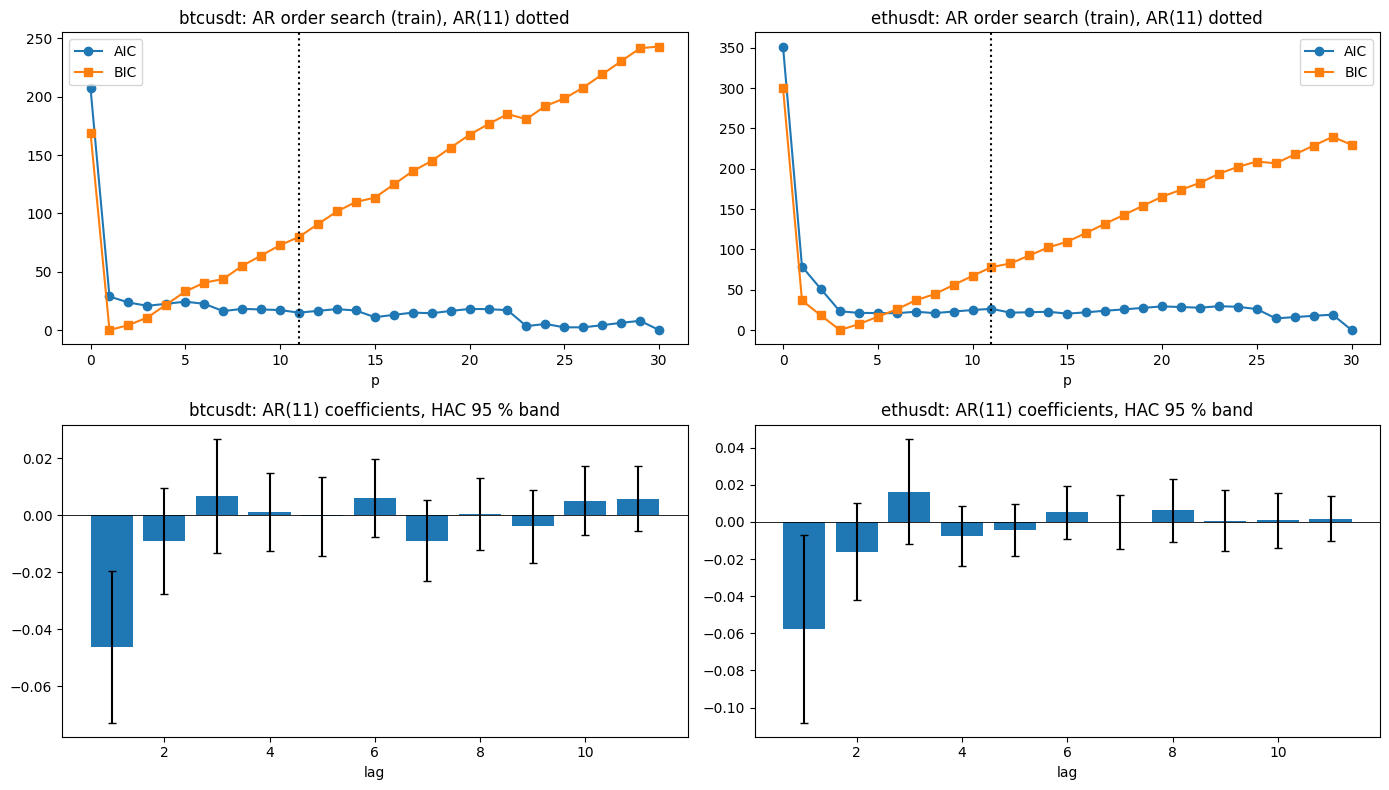

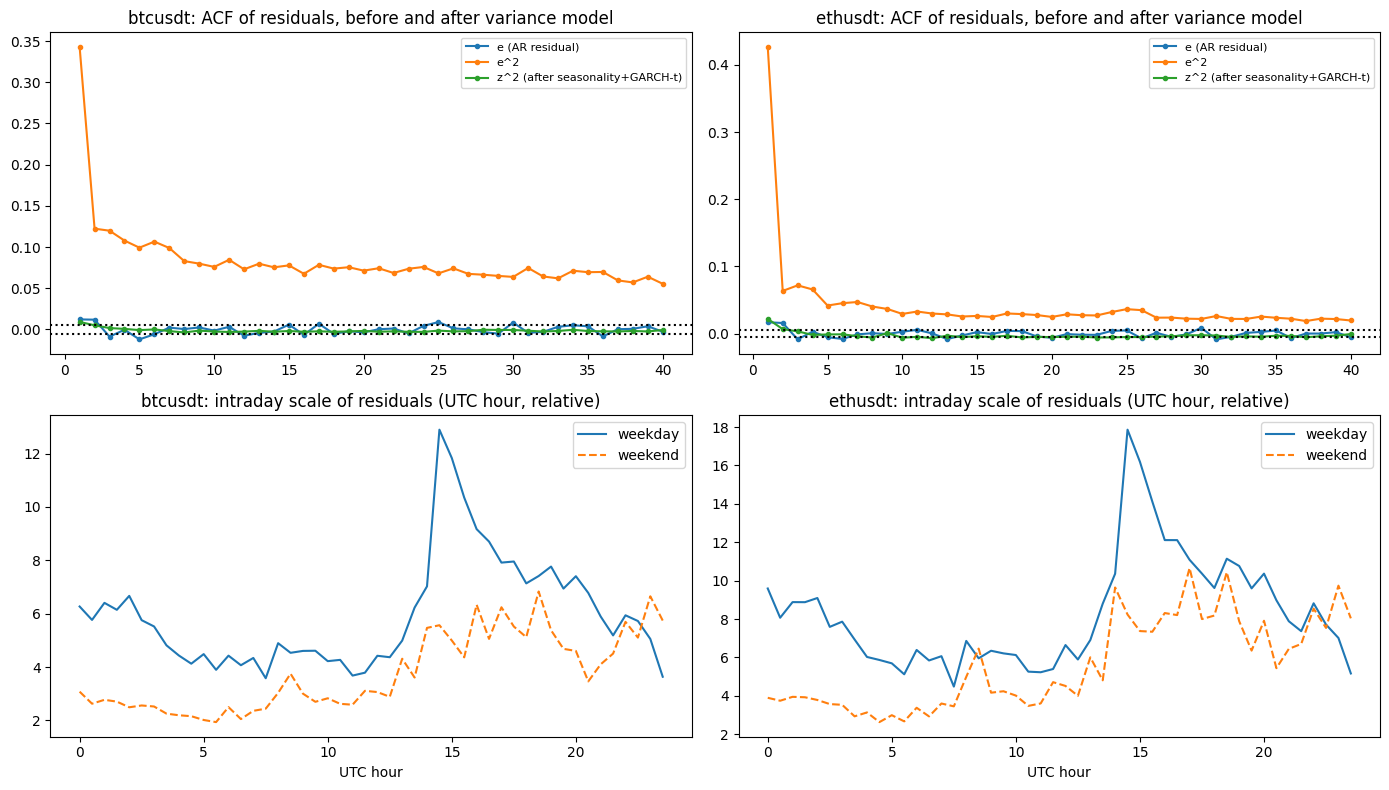

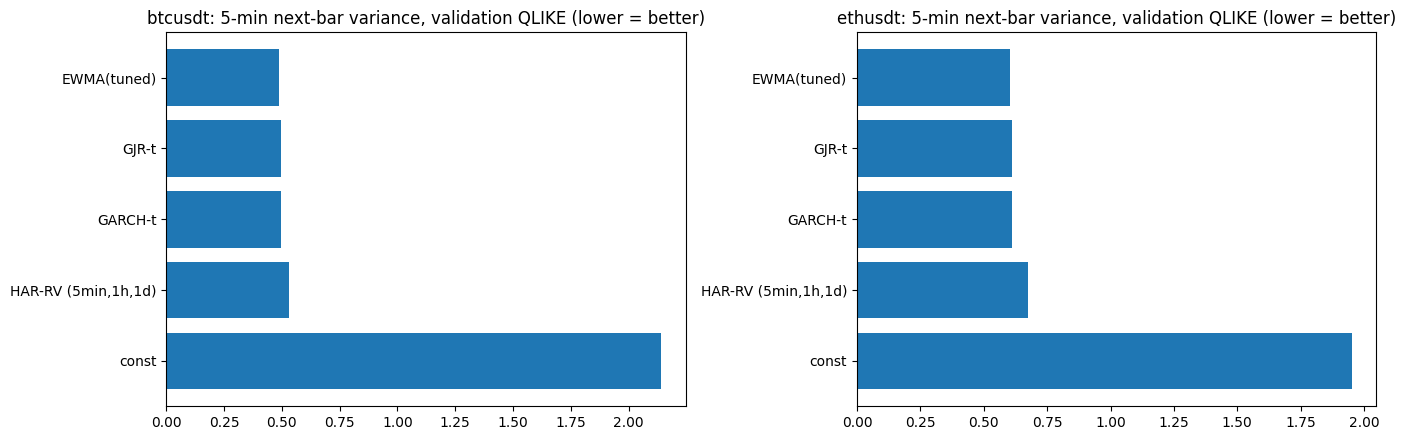

[stage G2b returns->AR->residuals->variance] 69.0s peak_rss=11.41GB


In [31]:
# ---- figures ----------------------------------------------------------------------------------------------------------------------
nS = len(SYMS); fig, ax = plt.subplots(2, nS, figsize=(7 * nS, 8)); ax = np.atleast_2d(ax).reshape(2, nS)
for j, s in enumerate(SYMS):
    O = G2O.filter(pl.col("sym") == s); ax[0, j].plot(O["p"], O["aic"] - O["aic"].min(), "o-", label="AIC"); ax[0, j].plot(O["p"], O["bic"] - O["bic"].min(), "s-", label="BIC"); ax[0, j].axvline(AR_P, c="k", ls=":"); ax[0, j].set_title(f"{s}: AR order search (train), AR({AR_P}) dotted"); ax[0, j].legend(); ax[0, j].set_xlabel("p")
    C = G2C.filter((pl.col("sym") == s) & (pl.col("term") != "const")); ax[1, j].bar(range(1, AR_P + 1), C["coef"], yerr=1.96 * C["hac_se"], capsize=3); ax[1, j].axhline(0, c="k", lw=.6); ax[1, j].set_title(f"{s}: AR({AR_P}) coefficients, HAC 95 % band"); ax[1, j].set_xlabel("lag")
fig.tight_layout(); show(fig, "g2b_ar_order_coef.png")
fig, ax = plt.subplots(2, nS, figsize=(7 * nS, 8)); ax = np.atleast_2d(ax).reshape(2, nS); L_ = 40
for j, s in enumerate(SYMS):
    n_ = int(np.isfinite(E_MAT[s]).sum()); band = 1.96 / np.sqrt(n_)
    for lab, M in (("e (AR residual)", E_MAT[s]), ("e^2", E_MAT[s] ** 2), ("z^2 (after seasonality+GARCH-t)", Z_MAT[s] ** 2)): ax[0, j].plot(range(1, L_ + 1), acf_2d(M, L_), "o-", ms=3, label=lab)
    ax[0, j].axhline(band, c="k", ls=":"); ax[0, j].axhline(-band, c="k", ls=":"); ax[0, j].set_title(f"{s}: ACF of residuals, before and after variance model"); ax[0, j].legend(fontsize=8)
    for w, ls_ in ((0, "-"), (1, "--")): ax[1, j].plot(np.arange(NBIN) * 0.5, np.sqrt(SEAS[s][w]), ls_, label="weekend" if w else "weekday")
    ax[1, j].set_title(f"{s}: intraday scale of residuals (UTC hour, relative)"); ax[1, j].legend(); ax[1, j].set_xlabel("UTC hour")
fig.tight_layout(); show(fig, "g2b_residual_acf_seasonality.png")
fig, ax = plt.subplots(1, nS, figsize=(7 * nS, 4.5)); ax = np.atleast_1d(ax)
for j, s in enumerate(SYMS):
    o5 = G2V.filter((pl.col("sym") == s) & (pl.col("section") == "oos_5min_next_bar")).sort("qlike"); ax[j].barh(o5["model"], o5["qlike"], color="C0"); ax[j].invert_yaxis(); ax[j].set_title(f"{s}: 5-min next-bar variance, validation QLIKE (lower = better)")
fig.tight_layout(); show(fig, "g2b_variance_benchmark.png")
mark("G2b returns->AR->residuals->variance")


## G3. Tail risk: Hill estimator, Peaks-over-Threshold (GPD), block maxima (GEV) and time blocks
* **Hill**: tail index α of `P(X>x) ~ x^-α` (α<2: infinite variance, α<4: infinite kurtosis). The plateau of the Hill plot gives k.
* **POT**: exceedances above a high percentile `u` follow a generalised Pareto law with shape ξ (ξ>0 heavy tail, ξ≈1/α). `u` is chosen as the **lowest percentile whose GPD fit is not rejected (KS p>0.10)** with a stable ξ; clustered exceedances are also **declustered** (runs of 30 bars).
* **Block maxima**: GEV fit to the worst move per hour / day / week, return levels = "move expected once every T blocks".
* **Time blocks**: how tail events concentrate in clock hours and weekday vs weekend.

Tail risk (positive numbers = size of loss / gain in bps)
shape: (16, 20)
┌─────────┬──────────┬──────┬────────┬────────┬───────────┬───────┬───────────┬──────────┬───────────┬──────────┬──────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ sym     ┆ horizon  ┆ tail ┆ n      ┆ hill_k ┆ hill_alph ┆ pot_q ┆ pot_u_bps ┆ pot_xi   ┆ pot_xi_se ┆ pot_ks_p ┆ n_exceed ┆ VaR0.99_p ┆ ES0.99_po ┆ VaR0.99_e ┆ VaR0.99_n ┆ VaR0.999_ ┆ ES0.999_p ┆ VaR0.999_ ┆ VaR0.999_ │
│ ---     ┆ ---      ┆ ---  ┆ ---    ┆ ---    ┆ a         ┆ ---   ┆ ---       ┆ ---      ┆ ---       ┆ ---      ┆ ---      ┆ ot        ┆ t         ┆ mp        ┆ ormal     ┆ pot       ┆ ot        ┆ emp       ┆ normal    │
│ str     ┆ str      ┆ str  ┆ i64    ┆ i64    ┆ ---       ┆ f64   ┆ f64       ┆ f64      ┆ f64       ┆ f64      ┆ i64      ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│         ┆          ┆      ┆        ┆    

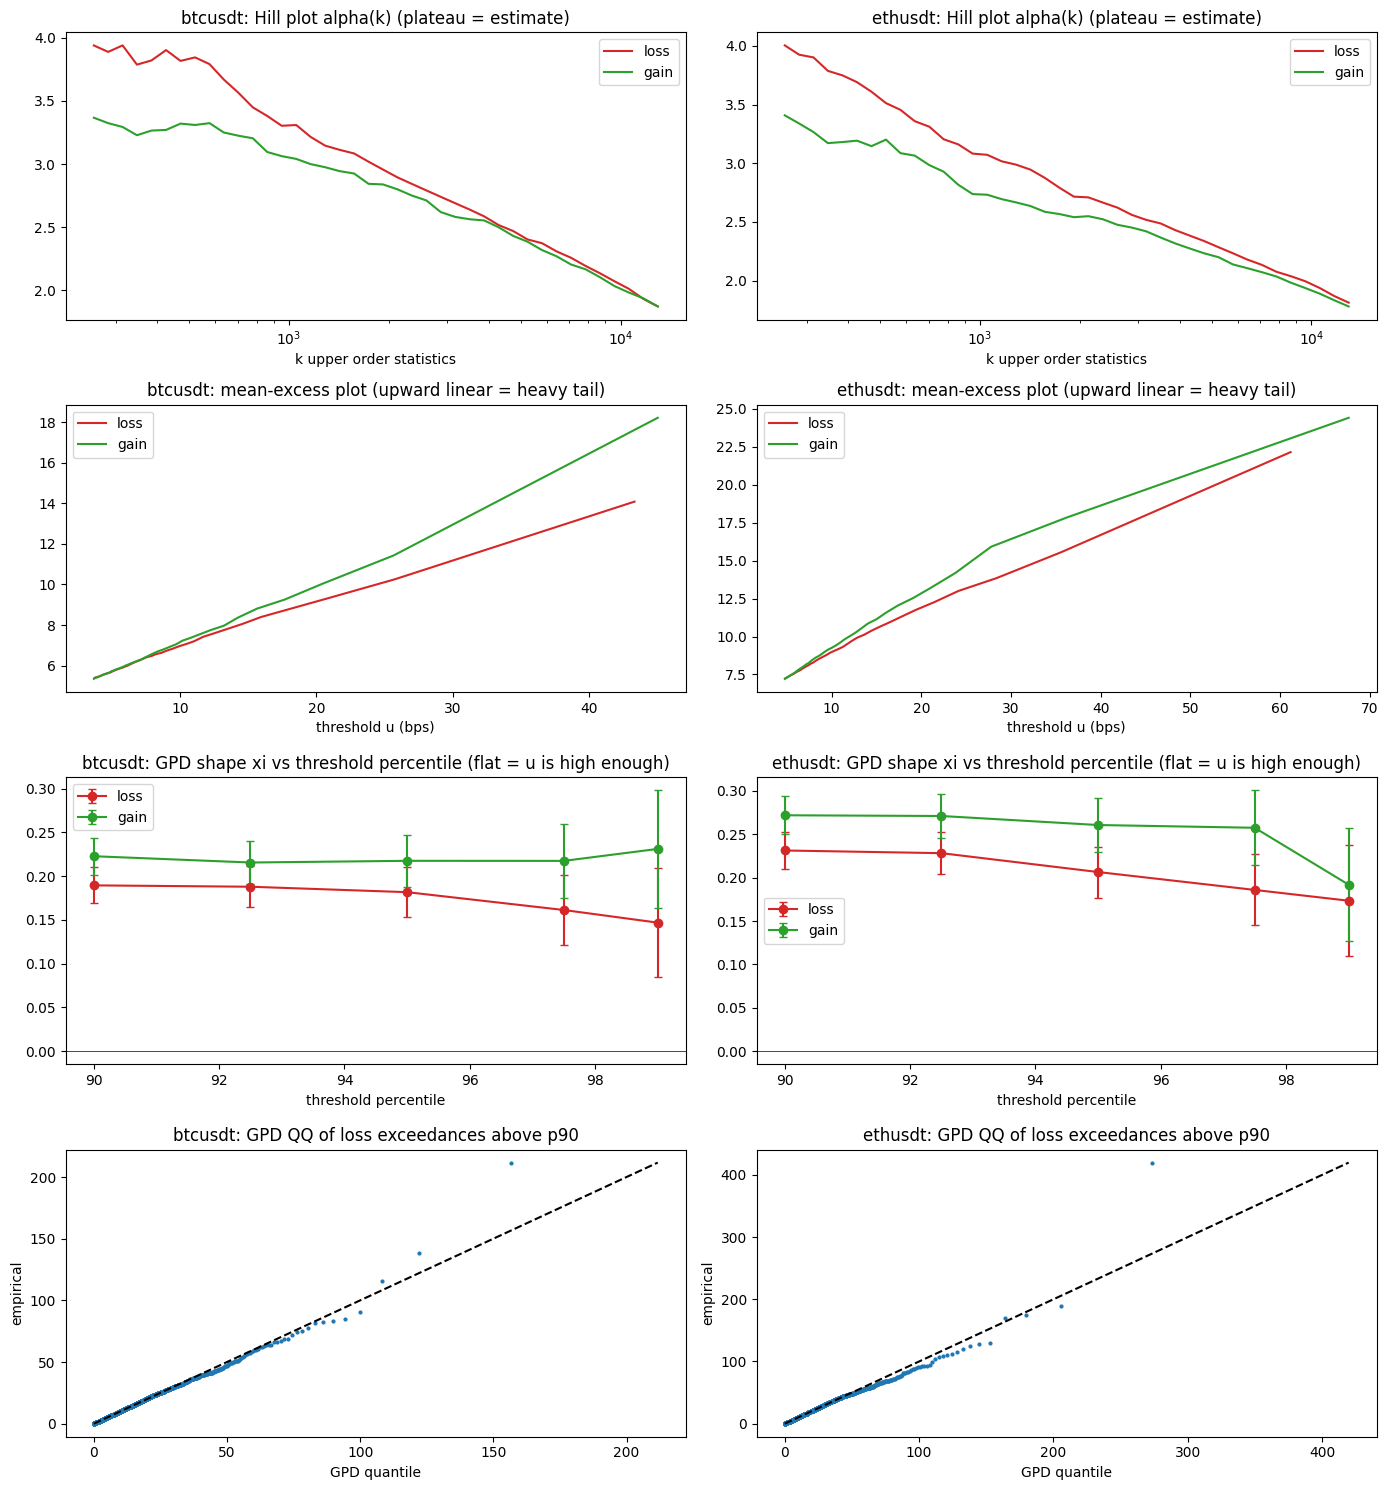

In [32]:
def hill_curve(y, ks):
    z = np.sort(y[y > 0])[::-1]; lz = np.log(z); cs = np.cumsum(lz); ks = np.array([k for k in ks if 5 <= k < len(z)]); return ks, np.array([1.0 / (cs[k - 1] / k - lz[k]) for k in ks])
def hill_choose(y):
    n = len(y); ks = np.unique(np.geomspace(max(20, int(.002 * n)), max(40, int(.10 * n)), 40).astype(int)); ks, a = hill_curve(y, ks)
    if len(a) < 9: return ks, a, (int(ks[len(ks) // 2]) if len(ks) else 20), (float(np.median(a)) if len(a) else np.nan)
    cv = [np.std(a[i - 3:i + 4]) / abs(np.mean(a[i - 3:i + 4])) for i in range(3, len(a) - 3)]; i = 3 + int(np.argmin(cv)); return ks, a, int(ks[i]), float(a[i])
def pot_fit(y, q, gap=None):
    u = float(np.quantile(y, q)); ex = y[y > u] - u
    if gap:
        idx = np.flatnonzero(y > u); grp = np.split(idx, np.flatnonzero(np.diff(idx) > gap) + 1); ex = np.array([y[g].max() for g in grp]) - u
    c, _, sc = genpareto.fit(ex, floc=0); ks = sps.kstest(ex, "genpareto", args=(c, 0, sc)).pvalue
    return dict(q=q, u=u, nu=len(ex), n=len(y), xi=float(c), sigma=float(sc), ks_p=float(ks), xi_se=float((1 + c) / np.sqrt(len(ex))), mean_excess=float(ex.mean()))
def pot_risk(f, p):
    xi, sg, u, nu, n = f["xi"], f["sigma"], f["u"], f["nu"], f["n"]; r = (n / nu) * (1 - p)
    var = u + sg / xi * (r ** (-xi) - 1) if abs(xi) > 1e-6 else u - sg * np.log(r); es = (var + sg - xi * u) / (1 - xi) if xi < 1 else np.nan; return float(var), float(es)
POT_Q = [.90, .925, .95, .975, .99]
def choose_u(y):
    fits = []
    for q in POT_Q:
        try: fits.append(pot_fit(y, q))
        except Exception: pass
    good = [f for f in fits if f["ks_p"] > .10]; return fits, (good[0] if good else (next((f for f in fits if f["q"] == .95), fits[0]) if fits else None))
def tail_summary(sym, tail, y, label):
    ks, a, kstar, alpha = hill_choose(y); fits, f = choose_u(y)
    if f is None: return None, None
    row = dict(sym=sym, horizon=label, tail=tail, n=len(y), hill_k=kstar, hill_alpha=alpha, pot_q=f["q"], pot_u_bps=f["u"], pot_xi=f["xi"], pot_xi_se=f["xi_se"], pot_ks_p=f["ks_p"], n_exceed=f["nu"])
    mu, sd = float(np.mean(y)), float(np.std(y))
    for p in (.99, .999):
        v, e = pot_risk(f, p); row[f"VaR{p}_pot"] = v; row[f"ES{p}_pot"] = e; row[f"VaR{p}_emp"] = float(np.quantile(y, p)); row[f"VaR{p}_normal"] = mu + sd * norm.ppf(p)
    return row, (ks, a, fits, f)
TR, TD = [], {}
for s in SYMS:
    for tail, sgn in (("loss", -1.0), ("gain", 1.0)):
        r, d = tail_summary(s, tail, sgn * RB[s]["r"], f"{BAR_S}s")
        if r: TR.append(r); TD[(s, tail)] = d
    for tau in TAUS:
        x = ret_matrix(s, tau).ravel(); x = x[np.isfinite(x)]
        for tail, sgn in (("loss", -1.0), ("gain", 1.0)):
            try: r, _ = tail_summary(s, tail, sgn * x, f"tau={tau}s")
            except Exception: r = None
            if r: TR.append(r)
TAILT = pl.DataFrame(TR); TAILT.write_csv(WORK / "g3_tail_risk_hill_pot.csv"); print("Tail risk (positive numbers = size of loss / gain in bps)"); print(TAILT)
for r in TR:
    if r["horizon"] != f"{BAR_S}s": continue
    kind = "infinite variance" if r["hill_alpha"] < 2 else "infinite kurtosis" if r["hill_alpha"] < 4 else "finite 4th moment"
    say(f"{r['sym']} {r['tail']} tail ({r['horizon']}): Hill alpha={r['hill_alpha']:.2f} ({kind}); POT u=p{r['pot_q']*100:g} ({r['pot_u_bps']:.1f} bps), xi={r['pot_xi']:.2f}±{r['pot_xi_se']:.2f} (1/alpha={1/r['hill_alpha']:.2f}); "
        f"99.9 % VaR={r['VaR0.999_pot']:.1f} bps, ES={r['ES0.999_pot']:.1f} bps vs normal VaR {r['VaR0.999_normal']:.1f} bps -> Gaussian understates it by x{r['VaR0.999_pot'] / max(r['VaR0.999_normal'], 1e-9):.1f}.")
    ls = [x for x in TR if x["sym"] == r["sym"] and x["tail"] == r["tail"]]
    if len(ls) > 1: say(f"{r['sym']} {r['tail']}: tail shape xi across horizons " + ", ".join(f"{x['horizon']}={x['pot_xi']:.2f}" for x in ls) + " (xi falling with horizon = aggregational Gaussianity; flat = persistent heavy tails).")

fig, ax = plt.subplots(4, len(SYMS), figsize=(7 * len(SYMS), 15)); ax = np.atleast_2d(ax).reshape(4, len(SYMS))
for j, s in enumerate(SYMS):
    for tail, c in (("loss", "C3"), ("gain", "C2")):
        if (s, tail) not in TD: continue
        ks, a, fits, f = TD[(s, tail)]; ax[0, j].plot(ks, a, c=c, label=tail); ax[2, j].errorbar([x["q"] * 100 for x in fits], [x["xi"] for x in fits], yerr=[1.96 * x["xi_se"] for x in fits], fmt="o-", c=c, capsize=3, label=tail)
        y = (-1 if tail == "loss" else 1) * RB[s]["r"]; us = np.quantile(y, np.linspace(.80, .999, 40)); ax[1, j].plot(us, [(y[y > u] - u).mean() for u in us], c=c, label=tail)
    ax[0, j].set_xscale("log"); ax[0, j].set_title(f"{s}: Hill plot alpha(k) (plateau = estimate)"); ax[0, j].legend(); ax[0, j].set_xlabel("k upper order statistics")
    ax[1, j].set_title(f"{s}: mean-excess plot (upward linear = heavy tail)"); ax[1, j].set_xlabel("threshold u (bps)"); ax[1, j].legend()
    ax[2, j].set_title(f"{s}: GPD shape xi vs threshold percentile (flat = u is high enough)"); ax[2, j].set_xlabel("threshold percentile"); ax[2, j].axhline(0, c="k", lw=.5); ax[2, j].legend()
    if (s, "loss") in TD:
        f = TD[(s, "loss")][3]; y = -RB[s]["r"]; ex = np.sort(y[y > f["u"]] - f["u"]); pp = (np.arange(1, len(ex) + 1) - .5) / len(ex); ax[3, j].plot(genpareto.ppf(pp, f["xi"], 0, f["sigma"]), ex, "o", ms=2); m = ex.max(); ax[3, j].plot([0, m], [0, m], "k--"); ax[3, j].set_title(f"{s}: GPD QQ of loss exceedances above p{f['q']*100:g}"); ax[3, j].set_xlabel("GPD quantile"); ax[3, j].set_ylabel("empirical")
fig.tight_layout(); show(fig, "g3_tail_hill_pot.png")

GEV block maxima (xi>0 Frechet heavy tail; weekly/daily fits have few blocks -> wide uncertainty)
shape: (20, 11)
┌─────────┬───────┬──────┬──────────┬──────────┬───────────┬───────────┬──────────┬──────────────────────┬──────────────────┬────────────────────┐
│ sym     ┆ block ┆ tail ┆ n_blocks ┆ xi       ┆ loc       ┆ scale     ┆ ks_p     ┆ return_period_blocks ┆ return_level_bps ┆ worst_observed_bps │
│ ---     ┆ ---   ┆ ---  ┆ ---      ┆ ---      ┆ ---       ┆ ---       ┆ ---      ┆ ---                  ┆ ---              ┆ ---                │
│ str     ┆ str   ┆ str  ┆ i64      ┆ f64      ┆ f64       ┆ f64       ┆ f64      ┆ i64                  ┆ f64              ┆ f64                │
╞═════════╪═══════╪══════╪══════════╪══════════╪═══════════╪═══════════╪══════════╪══════════════════════╪══════════════════╪════════════════════╡
│ btcusdt ┆ hour  ┆ loss ┆ 2160     ┆ 0.294812 ┆ 10.441237 ┆ 6.233199  ┆ 0.390459 ┆ 24                   ┆ 42.921595        ┆ 218.598698         │
│ bt

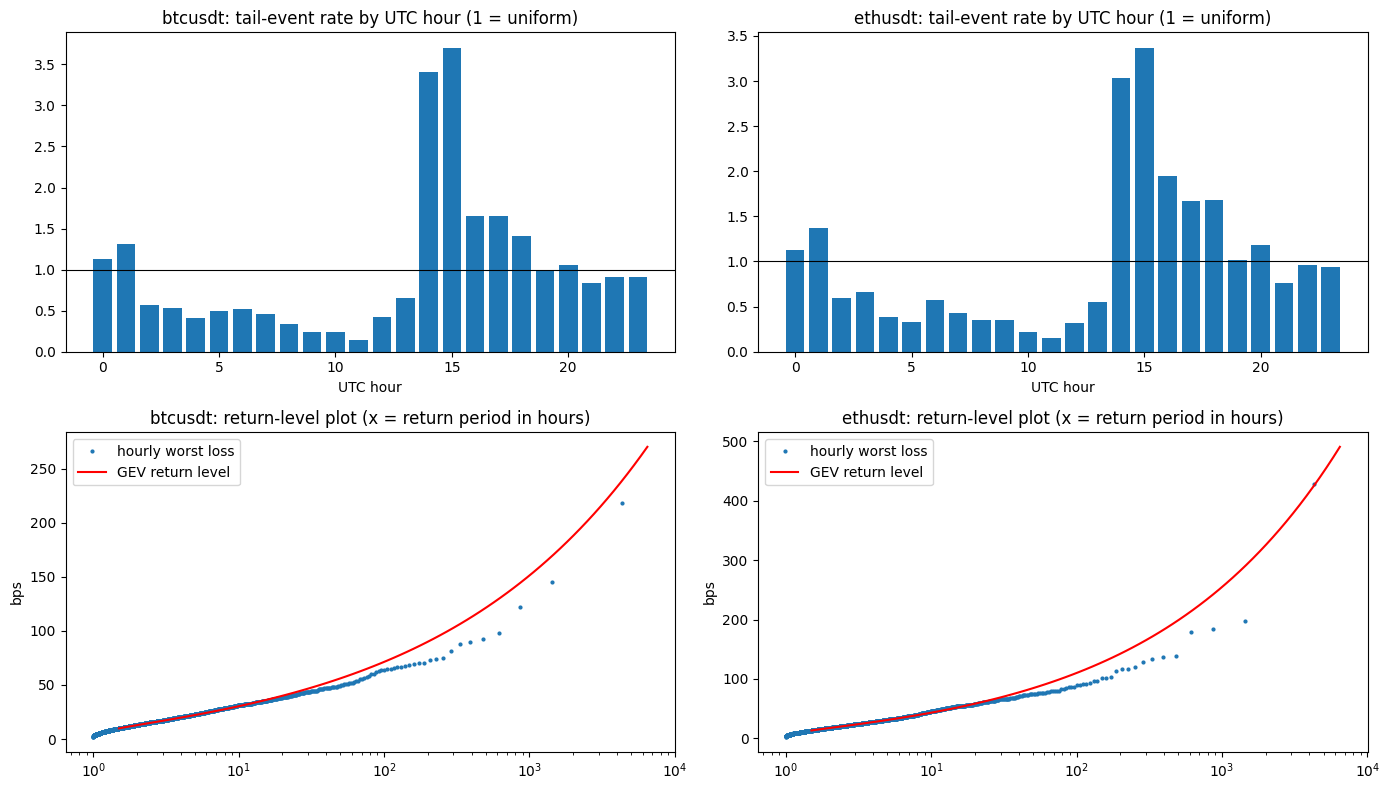

In [33]:
# Block maxima (GEV): hourly, daily, weekly blocks of the worst loss / gain per block
def block_max(R, kind, sign):
    nd, nb = R.shape; X = np.full((nd, 1440), np.nan); X[:, :nb] = sign * R; H = X.reshape(nd, 24, 60)
    if kind == "hour": m = np.nanmax(np.where(np.isfinite(H).sum(2, keepdims=True) >= 30, H, np.nan), axis=2).ravel()
    elif kind == "day": m = np.nanmax(np.where(np.isfinite(X).sum(1, keepdims=True) >= 720, X, np.nan), axis=1)
    else: m = np.array([np.nanmax(X[i:i + 7]) for i in range(0, nd - 6, 7)])
    return m[np.isfinite(m)]
BM, BMD = [], {}
for s in SYMS:
    for kind, rp in (("hour", [24, 24 * 30]), ("day", [30, 365]), ("week", [52])):
        for tail, sgn in (("loss", -1.0), ("gain", 1.0)):
            m = block_max(RB[s]["R"], kind, sgn)
            if len(m) < 8: continue
            try: c, loc, sc = genextreme.fit(m)
            except Exception: continue
            ksp = sps.kstest(m, "genextreme", args=(c, loc, sc)).pvalue; BMD[(s, kind, tail)] = (m, c, loc, sc)
            for T in rp: BM.append(dict(sym=s, block=kind, tail=tail, n_blocks=len(m), xi=float(-c), loc=float(loc), scale=float(sc), ks_p=float(ksp), return_period_blocks=T, return_level_bps=float(genextreme.ppf(1 - 1 / T, c, loc, sc)), worst_observed_bps=float(m.max())))
BMT = pl.DataFrame(BM) if BM else None
if BMT is not None:
    BMT.write_csv(WORK / "g3_block_maxima_gev.csv"); print("GEV block maxima (xi>0 Frechet heavy tail; weekly/daily fits have few blocks -> wide uncertainty)"); print(BMT)
    for s in SYMS:
        d = BMT.filter((pl.col("sym") == s) & (pl.col("block") == "hour") & (pl.col("tail") == "loss") & (pl.col("return_period_blocks") == 24))
        if d.height: say(f"{s}: hourly-block GEV xi={d['xi'][0]:.2f}; the worst 1-min loss expected once a day is about {d['return_level_bps'][0]:.1f} bps (largest hourly worst in sample {d['worst_observed_bps'][0]:.1f} bps).")

# Time blocks: where do tail events live in the clock? (|r| above the global 99th percentile)
TB = []
for s in SYMS:
    r, h, d = RB[s]["r"], RB[s]["hour"], RB[s]["day"]; u = np.quantile(np.abs(r), .99); ex = np.abs(r) > u; wk = ((D0 + d + 3) % 7) >= 5
    for hh in range(24):
        m = h == hh; l = -r[m]; TB.append(dict(sym=s, hour=hh, n=int(m.sum()), exceed_lift=float(ex[m].mean() / .01) if m.sum() else np.nan, var99_loss_bps=float(np.quantile(l, .99)) if m.sum() > 100 else np.nan, es99_loss_bps=float(l[l >= np.quantile(l, .99)].mean()) if m.sum() > 100 else np.nan))
    TB.append(dict(sym=s, hour=-1, n=int((~wk).sum()), exceed_lift=float(ex[~wk].mean() / .01), var99_loss_bps=float(np.quantile(-r[~wk], .99)), es99_loss_bps=np.nan)); TB.append(dict(sym=s, hour=-2, n=int(wk.sum()), exceed_lift=float(ex[wk].mean() / .01) if wk.any() else np.nan, var99_loss_bps=float(np.quantile(-r[wk], .99)) if wk.sum() > 100 else np.nan, es99_loss_bps=np.nan))
TBT = pl.DataFrame(TB); TBT.write_csv(WORK / "g3_tail_time_blocks.csv")
for s in SYMS:
    t = TBT.filter((pl.col("sym") == s) & (pl.col("hour") >= 0)).sort("exceed_lift", descending=True); wd = TBT.filter((pl.col("sym") == s) & (pl.col("hour") == -1))["exceed_lift"][0]; we = TBT.filter((pl.col("sym") == s) & (pl.col("hour") == -2))["exceed_lift"][0]
    say(f"{s}: extreme 1-min moves concentrate in UTC hours {t['hour'].head(3).to_list()} (lift x{t['exceed_lift'][0]:.1f} vs uniform); weekend/weekday tail-rate ratio {we / wd:.2f} -> " + ("tails are time-of-day dependent: scale risk by hour and avoid quoting through those blocks." if t["exceed_lift"][0] > 1.5 else "tail risk is roughly uniform across the day."))
fig, ax = plt.subplots(2, len(SYMS), figsize=(7 * len(SYMS), 8)); ax = np.atleast_2d(ax).reshape(2, len(SYMS))
for j, s in enumerate(SYMS):
    t = TBT.filter((pl.col("sym") == s) & (pl.col("hour") >= 0)); ax[0, j].bar(t["hour"], t["exceed_lift"], color="C0"); ax[0, j].axhline(1, c="k", lw=.8); ax[0, j].set_title(f"{s}: tail-event rate by UTC hour (1 = uniform)"); ax[0, j].set_xlabel("UTC hour")
    if (s, "hour", "loss") in BMD:
        m, c, loc, sc = BMD[(s, "hour", "loss")]; ms = np.sort(m); pp = (np.arange(1, len(ms) + 1) - .5) / len(ms); ax[1, j].semilogx(1 / (1 - pp), ms, "o", ms=2, label="hourly worst loss"); T = np.geomspace(1.5, len(ms) * 3, 80); ax[1, j].semilogx(T, genextreme.ppf(1 - 1 / T, c, loc, sc), "r-", label="GEV return level"); ax[1, j].set_title(f"{s}: return-level plot (x = return period in hours)"); ax[1, j].set_ylabel("bps"); ax[1, j].legend()
fig.tight_layout(); show(fig, "g3_block_maxima_time_blocks.png")

## G4. Joint distribution and copulas (BTC vs ETH, simple returns)
The copula separates **dependence** from the margins. Compared: Gaussian (no tail dependence), Student-t (symmetric tail dependence), Clayton (lower tail: joint crashes), survival-Clayton and Gumbel (upper tail: joint rallies).
The empirical 5x5 quintile table shows the joint distribution directly: a cell value of 1 = independence, the corner cells (Q1,Q1) and (Q5,Q5) >> 1 = co-crashes / co-rallies.

Joint btcusdt/ethusdt simple returns, 60s: pearson=0.864 spearman=0.824 kendall=0.638
shape: (4, 4)
┌───────────┬────────┬──────────┬──────────┐
│ horizon_s ┆ n      ┆ pearson  ┆ spearman │
│ ---       ┆ ---    ┆ ---      ┆ ---      │
│ i64       ┆ i64    ┆ f64      ┆ f64      │
╞═══════════╪════════╪══════════╪══════════╡
│ 60        ┆ 129484 ┆ 0.864277 ┆ 0.824185 │
│ 30        ┆ 259069 ┆ 0.853275 ┆ 0.802113 │
│ 120       ┆ 64695  ┆ 0.872566 ┆ 0.831447 │
│ 300       ┆ 25821  ┆ 0.879034 ┆ 0.834897 │
└───────────┴────────┴──────────┴──────────┘

Joint quintile lift (rows btcusdt Q1=worst..Q5=best, cols ethusdt); 1 = independence
[[3.68 0.95 0.21 0.11 0.05]
 [0.97 2.29 1.17 0.45 0.13]
 [0.2  1.18 2.22 1.19 0.21]
 [0.11 0.47 1.17 2.27 0.98]
 [0.05 0.11 0.23 0.98 3.63]]

Copula fits (lower AIC = better; lam = asymptotic tail dependence)
shape: (5, 7)
┌───────────────────────────────┬─────────────────┬──────────────┬─────┬──────────┬──────────┬────────────────┐
│ copula                     

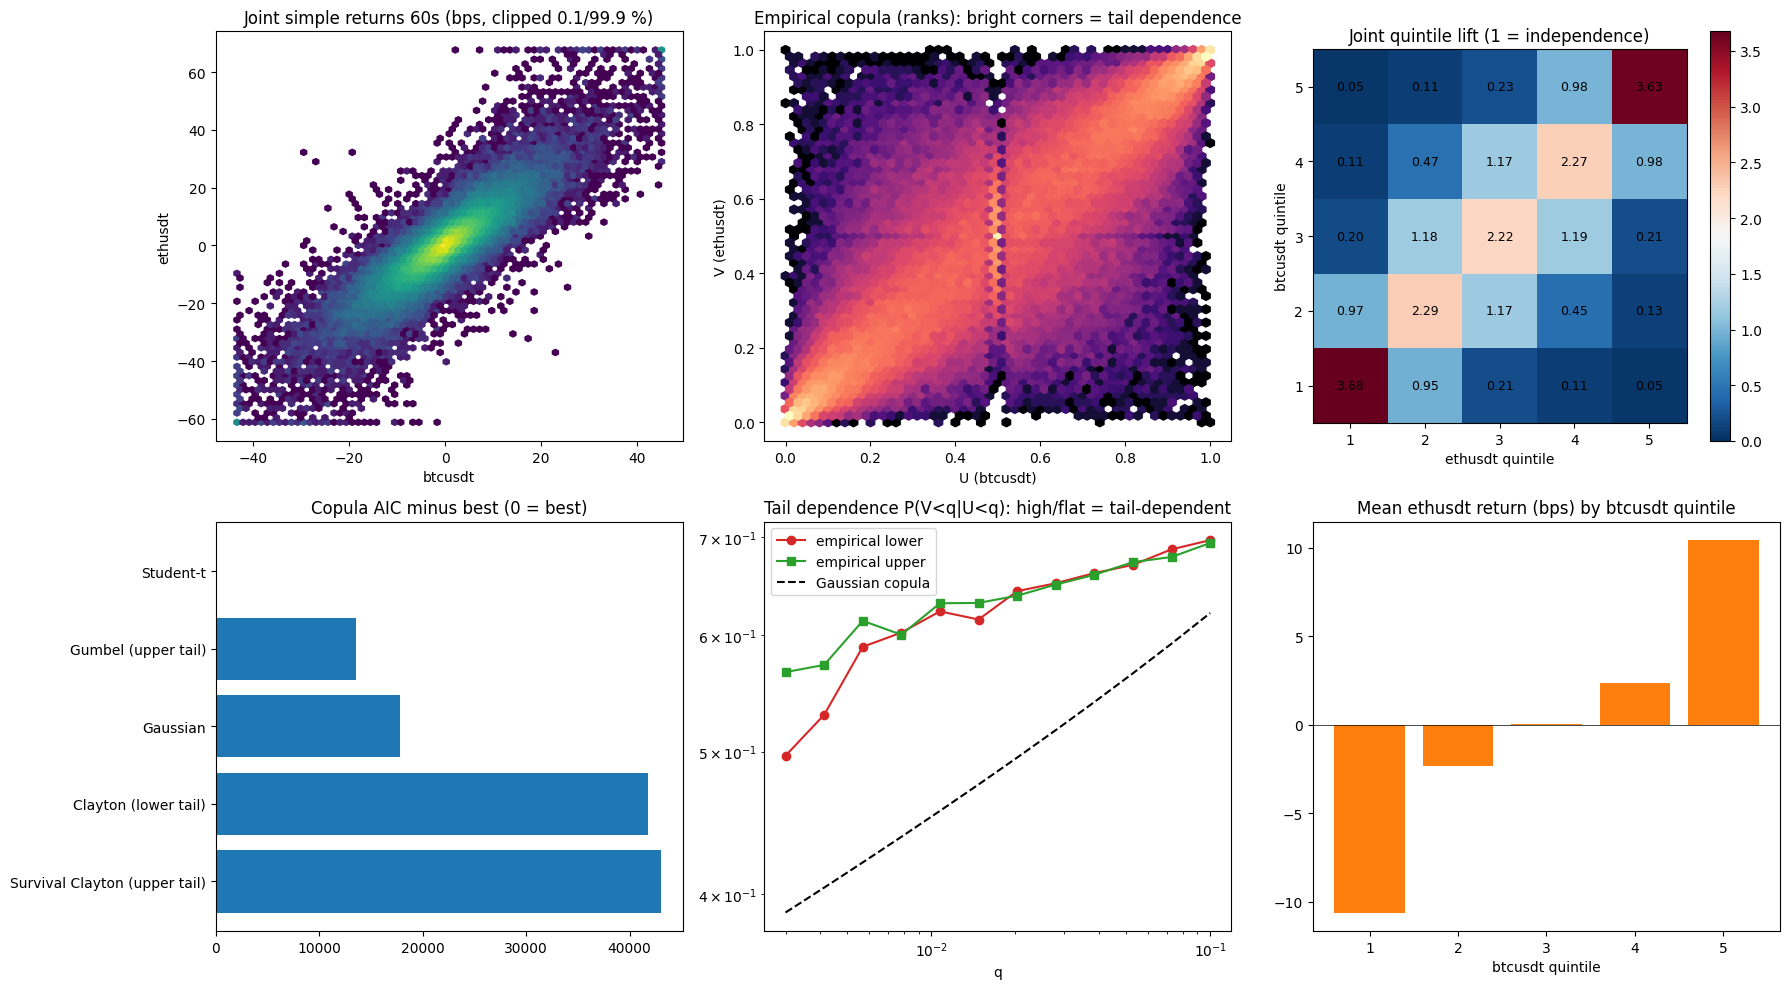

In [34]:
A_, B_ = SYMS[0], SYMS[-1]
if len(SYMS) == 2:
    Rb, Re = RB[A_]["R"].ravel(), RB[B_]["R"].ravel(); okk = np.isfinite(Rb) & np.isfinite(Re); xb, xe = Rb[okk], Re[okk]; nj = len(xb)
    pear = float(np.corrcoef(xb, xe)[0, 1]); spr = float(spearmanr(xb, xe)[0]); kt = float(kendalltau(xb[:60000], xe[:60000])[0])
    DEP = []
    for h in [BAR_S] + TAUS:
        a, b = ret_matrix(A_, h).ravel(), ret_matrix(B_, h).ravel(); ok = np.isfinite(a) & np.isfinite(b); DEP.append(dict(horizon_s=h, n=int(ok.sum()), pearson=float(np.corrcoef(a[ok], b[ok])[0, 1]), spearman=float(spearmanr(a[ok][:200000], b[ok][:200000])[0])))
    DEPT = pl.DataFrame(DEP); DEPT.write_csv(WORK / "g4_dependence_by_horizon.csv"); print(f"Joint {A_}/{B_} simple returns, {BAR_S}s: pearson={pear:.3f} spearman={spr:.3f} kendall={kt:.3f}"); print(DEPT)
    sub = np.random.default_rng(0).choice(nj, min(nj, 150000), replace=False); u = rankdata(xb[sub]) / (len(sub) + 1); v = rankdata(xe[sub]) / (len(sub) + 1); u, v = np.clip(u, 1e-9, 1 - 1e-9), np.clip(v, 1e-9, 1 - 1e-9)
    qi = np.minimum((u * 5).astype(int), 4); qj = np.minimum((v * 5).astype(int), 4); LIFT = np.zeros((5, 5))
    for i in range(5):
        for j in range(5): LIFT[i, j] = ((qi == i) & (qj == j)).mean() / .04
    cond = [float(xe[sub][qi == i].mean()) for i in range(5)]
    print(f"\nJoint quintile lift (rows {A_} Q1=worst..Q5=best, cols {B_}); 1 = independence"); print(np.round(LIFT, 2))

    def cop_gauss(u, v, r): x, y = norm.ppf(u), norm.ppf(v); return -0.5 * np.log(1 - r * r) - (r * r * (x * x + y * y) - 2 * r * x * y) / (2 * (1 - r * r))
    def cop_t(u, v, r, nu): x, y = tdist.ppf(u, nu), tdist.ppf(v, nu); return multivariate_t(loc=[0, 0], shape=[[1, r], [r, 1]], df=nu).logpdf(np.column_stack([x, y])) - tdist.logpdf(x, nu) - tdist.logpdf(y, nu)
    def cop_clay(u, v, th): return np.log1p(th) - (1 + th) * (np.log(u) + np.log(v)) - (2 + 1 / th) * np.log(u ** -th + v ** -th - 1)
    def cop_gum(u, v, th): a, b = -np.log(u), -np.log(v); A = a ** th + b ** th; Ap = A ** (1 / th); return -Ap + a + b + (th - 1) * (np.log(a) + np.log(b)) + (1 / th - 2) * np.log(A) + np.log(Ap + th - 1)
    def fit1(f, lo, hi): r = minimize_scalar(lambda th: -f(th).sum(), bounds=(lo, hi), method="bounded"); return float(r.x), float(-r.fun)
    tau_k = float(kendalltau(u[:60000], v[:60000])[0]); rho0 = float(np.sin(np.pi * tau_k / 2)); CF = []
    rg, llg = fit1(lambda r: cop_gauss(u, v, r), -.99, .99); CF.append(dict(copula="Gaussian", param=f"rho={rg:.3f}", loglik=llg, k=1, lam_L=0.0, lam_U=0.0))
    best = max(((nu, cop_t(u, v, rho0, nu).sum()) for nu in [2.5, 3, 4, 5, 6, 8, 10, 15, 30]), key=lambda z: z[1]); nu = best[0]; rt, llt = fit1(lambda r: cop_t(u, v, r, nu), max(rho0 - .15, -.99), min(rho0 + .15, .99))
    lt = float(2 * tdist.cdf(-np.sqrt((nu + 1) * (1 - rt) / (1 + rt)), nu + 1)); CF.append(dict(copula="Student-t", param=f"rho={rt:.3f}, nu={nu}", loglik=llt, k=2, lam_L=lt, lam_U=lt))
    if tau_k > 0:
        th, ll = fit1(lambda t_: cop_clay(u, v, t_), .01, 30); CF.append(dict(copula="Clayton (lower tail)", param=f"theta={th:.3f}", loglik=ll, k=1, lam_L=float(2 ** (-1 / th)), lam_U=0.0))
        th2, ll2 = fit1(lambda t_: cop_clay(1 - u, 1 - v, t_), .01, 30); CF.append(dict(copula="Survival Clayton (upper tail)", param=f"theta={th2:.3f}", loglik=ll2, k=1, lam_L=0.0, lam_U=float(2 ** (-1 / th2))))
        th3, ll3 = fit1(lambda t_: cop_gum(u, v, t_), 1.0001, 30); CF.append(dict(copula="Gumbel (upper tail)", param=f"theta={th3:.3f}", loglik=ll3, k=1, lam_L=0.0, lam_U=float(2 - 2 ** (1 / th3))))
    CFT = pl.DataFrame(CF).with_columns((2 * pl.col("k") - 2 * pl.col("loglik")).alias("AIC")).sort("AIC"); CFT.write_csv(WORK / "g4_copula_fits.csv"); print("\nCopula fits (lower AIC = better; lam = asymptotic tail dependence)"); print(CFT)
    qg = np.geomspace(.003, .10, 12); lamL = [float(((u < q) & (v < q)).mean() / q) for q in qg]; lamU = [float(((u > 1 - q) & (v > 1 - q)).mean() / q) for q in qg]
    lamG = [float(multivariate_normal(mean=[0, 0], cov=[[1, rg], [rg, 1]]).cdf([norm.ppf(q)] * 2) / q) for q in qg]
    TDEP = pl.DataFrame(dict(q=qg, empirical_lower=lamL, empirical_upper=lamU, gaussian_model=lamG)); TDEP.write_csv(WORK / "g4_tail_dependence.csv")
    b = CFT.row(0, named=True); say(f"{A_}/{B_}: Pearson {pear:.2f}, Spearman {spr:.2f}, Kendall {kt:.2f} at {BAR_S}s; correlation by horizon " + ", ".join(f"{r['horizon_s']}s={r['pearson']:.2f}" for r in DEP) + " (rising with horizon = Epps effect: asynchronous quotes and noise hide dependence at short horizons).")
    say(f"Best copula by AIC: {b['copula']} ({b['param']}). Empirical lower-tail dependence at q=1 % is {lamL[4]:.2f} and upper {lamU[4]:.2f} versus {lamG[4]:.2f} implied by a Gaussian copula -> " + ("extremes co-move far more than correlation suggests: a BTC/ETH hedge works worst exactly when the move is largest." if max(lamL[4], lamU[4]) > 1.5 * lamG[4] else "tail co-movement is close to the Gaussian benchmark."))
    say(f"Joint quintile table: both in worst 20 % occurs x{LIFT[0, 0]:.1f} (and both in best 20 % x{LIFT[4, 4]:.1f}) as often as under independence; opposite corners x{LIFT[0, 4]:.2f}/x{LIFT[4, 0]:.2f}. Mean {B_} return by {A_} quintile: " + ", ".join(f"{c:+.2f}" for c in cond) + " bps.")
    fig, ax = plt.subplots(2, 3, figsize=(18, 10)); lo = np.quantile(xb, [.001, .999]); lo2 = np.quantile(xe, [.001, .999]); ax[0, 0].hexbin(np.clip(xb, *lo), np.clip(xe, *lo2), gridsize=70, bins="log", cmap="viridis"); ax[0, 0].set_title(f"Joint simple returns {BAR_S}s (bps, clipped 0.1/99.9 %)"); ax[0, 0].set_xlabel(A_); ax[0, 0].set_ylabel(B_)
    ax[0, 1].hexbin(u, v, gridsize=50, bins="log", cmap="magma"); ax[0, 1].set_title("Empirical copula (ranks): bright corners = tail dependence"); ax[0, 1].set_xlabel(f"U ({A_})"); ax[0, 1].set_ylabel(f"V ({B_})")
    im = ax[0, 2].imshow(LIFT, origin="lower", cmap="RdBu_r", vmin=0, vmax=max(2, LIFT.max())); [ax[0, 2].text(j, i, f"{LIFT[i, j]:.2f}", ha="center", va="center", fontsize=9) for i in range(5) for j in range(5)]; ax[0, 2].set_xticks(range(5), range(1, 6)); ax[0, 2].set_yticks(range(5), range(1, 6)); ax[0, 2].set_title("Joint quintile lift (1 = independence)"); ax[0, 2].set_xlabel(f"{B_} quintile"); ax[0, 2].set_ylabel(f"{A_} quintile"); fig.colorbar(im, ax=ax[0, 2])
    ax[1, 0].barh(CFT["copula"], CFT["AIC"] - CFT["AIC"].min(), color="C0"); ax[1, 0].set_title("Copula AIC minus best (0 = best)"); ax[1, 0].invert_yaxis()
    ax[1, 1].loglog(qg, lamL, "o-", c="C3", label="empirical lower"); ax[1, 1].loglog(qg, lamU, "s-", c="C2", label="empirical upper"); ax[1, 1].loglog(qg, lamG, "k--", label="Gaussian copula"); ax[1, 1].set_title("Tail dependence P(V<q|U<q): high/flat = tail-dependent"); ax[1, 1].set_xlabel("q"); ax[1, 1].legend()
    ax[1, 2].bar(range(1, 6), cond, color="C1"); ax[1, 2].axhline(0, c="k", lw=.5); ax[1, 2].set_title(f"Mean {B_} return (bps) by {A_} quintile"); ax[1, 2].set_xlabel(f"{A_} quintile")
    fig.tight_layout(); show(fig, "g4_joint_copula.png")

## G5. Strategy tests at tau = 30 / 120 / 300 s on simple returns
Trade at the mid at `t` for `tau` seconds (**gross**, then net of an assumed taker round-trip cost = 2×(half-spread + fee)). Signals use only information up to `t`; thresholds, percentile levels and the rule choice are fitted on **train** and judged on **val**.
1. **Time-series momentum / mean reversion**: sign of the past tau-return vs the next tau-return (correlation, regression t-stat, Lo-MacKinlay variance ratio, quintile sort, rule grid on |signal| percentile).
2. **Liquidation-pressure signal** (from part D, causal): does the signed liquidation flow predict continuation (momentum) or reversal?
3. **Lead-lag** BTC→ETH (cross-correlation, strategy) and **statistical arbitrage** on the BTC–ETH spread (cointegration, half-life, z-score mean reversion). True cross-venue arbitrage cannot be tested: the data has Binance prices only (Bybit has liquidations only).

In [35]:
SPREAD_MED = {s: float(HS.filter(pl.col("sym") == s)["spread_med_bps"].median()) for s in SYMS}; RT_COST = {s: 2 * (SPREAD_MED[s] / 2 + TAKER_FEE_BPS) for s in SYMS}
print("median quoted spread (bps):", {k: round(v, 3) for k, v in SPREAD_MED.items()}, "| assumed taker round-trip cost (bps):", {k: round(v, 2) for k, v in RT_COST.items()})
TRM = (SPLIT_ROW == "train")[:, None]; VAM = (SPLIT_ROW == "val")[:, None]
if not TRM.any(): TRM = np.ones_like(TRM)     # no train/val split inside the data window -> everything is "train"
def pnl_stats(p, ndays):
    p = p[np.isfinite(p)]; n = len(p)
    if n < 20: return dict(n=n, mean_bps=np.nan, t=np.nan, hit=np.nan, sharpe=np.nan)
    sd = p.std(ddof=1); return dict(n=n, mean_bps=float(p.mean()), t=float(p.mean() / (sd / np.sqrt(n))) if sd > 0 else np.nan, hit=float((p > 0).mean()), sharpe=float(p.mean() / sd * np.sqrt(n / max(ndays, 1) * 365)) if sd > 0 else np.nan)
PCT_GRID = [0.0, .5, .8, .9, .95]
def rule_grid(sig, y, label, cost, extra):
    """trade only if |signal| > train p-th percentile; mode +1 follows the signal (momentum), -1 fades it (mean reversion); pick the best on TRAIN, report VAL."""
    rows = []; ntr = int(TRM[:, 0].sum()); nva = int(VAM[:, 0].sum()); trs = np.broadcast_to(TRM, sig.shape); vas = np.broadcast_to(VAM, sig.shape); ok = np.isfinite(sig) & np.isfinite(y) & (sig != 0)
    for mode, mn in ((1, "follow (momentum)"), (-1, "fade (mean reversion)")):
        for p in PCT_GRID:
            c = np.quantile(np.abs(sig[ok & trs]), p) if p > 0 and (ok & trs).any() else 0.0; act = ok & (np.abs(sig) > c); pnl = np.where(act, mode * np.sign(sig) * y, np.nan)
            a, b = pnl_stats(pnl[trs], ntr), pnl_stats(pnl[vas], nva); rows.append(dict(**extra, rule=mn, pct=p, thr=float(c), **{f"tr_{k}": v for k, v in a.items()}, **{f"va_{k}": v for k, v in b.items()}, rt_cost_bps=cost, tr_net_bps=a["mean_bps"] - cost, va_net_bps=b["mean_bps"] - cost, _pnl=pnl))
    T = pl.DataFrame([{k: v for k, v in r.items() if k != "_pnl"} for r in rows]); cand = [i for i, r in enumerate(rows) if r["tr_n"] >= 100 and np.isfinite(r["tr_t"])]
    bi = max(cand, key=lambda i: rows[i]["tr_t"]) if cand else None; return T, (rows[bi] if bi is not None else None)

def vr_lm(sym, q, base=5):
    R = ret_matrix(sym, base) / 1e4; keep = np.isfinite(R).mean(1) > .995; R = np.where(np.isfinite(R[keep]), R[keep], 0.0)
    if R.shape[0] == 0: return np.nan, np.nan
    e = R - R.mean(); sig2 = (e ** 2).mean(); S = np.cumsum(e, axis=1); Sq = S[:, q:] - S[:, :-q]; vr = float((Sq ** 2).mean() / (q * sig2)); e2 = e ** 2; den = (e2.sum()) ** 2; th = 0.0
    for j in range(1, q): th += (2 * (q - j) / q) ** 2 * (e2[:, j:] * e2[:, :-j]).sum() / den * e2.size
    return vr, float((vr - 1) / np.sqrt(th / e2.size)) if th > 0 else np.nan
VRR = [dict(sym=s, tau=t, **dict(zip(("VR", "z_robust"), vr_lm(s, t // 5)))) for s in SYMS for t in TAUS]; VRT = pl.DataFrame(VRR); VRT.write_csv(WORK / "g5_variance_ratio.csv")
print("Lo-MacKinlay variance ratio (simple returns, 5s base; VR>1 momentum, VR<1 mean reversion; |z|>2 significant)"); print(VRT)

median quoted spread (bps): {'btcusdt': 0.011, 'ethusdt': 0.034} | assumed taker round-trip cost (bps): {'btcusdt': 9.01, 'ethusdt': 9.03}
Lo-MacKinlay variance ratio (simple returns, 5s base; VR>1 momentum, VR<1 mean reversion; |z|>2 significant)
shape: (6, 4)
┌─────────┬─────┬──────────┬───────────┐
│ sym     ┆ tau ┆ VR       ┆ z_robust  │
│ ---     ┆ --- ┆ ---      ┆ ---       │
│ str     ┆ i64 ┆ f64      ┆ f64       │
╞═════════╪═════╪══════════╪═══════════╡
│ btcusdt ┆ 30  ┆ 1.05716  ┆ 8.726525  │
│ btcusdt ┆ 120 ┆ 1.050249 ┆ 3.798044  │
│ btcusdt ┆ 300 ┆ 1.036063 ┆ 1.836559  │
│ ethusdt ┆ 30  ┆ 0.986041 ┆ -0.77392  │
│ ethusdt ┆ 120 ┆ 0.959395 ┆ -1.252152 │
│ ethusdt ┆ 300 ┆ 0.941527 ┆ -1.322281 │
└─────────┴─────┴──────────┴───────────┘


Does the past tau-return predict the next tau-return?
shape: (6, 8)
┌─────────┬─────┬────────┬──────────────────┬───────────┬───────────┬───────────┬────────────────┐
│ sym     ┆ tau ┆ n      ┆ corr_past_future ┆ spearman  ┆ ols_beta  ┆ t_stat    ┆ regime         │
│ ---     ┆ --- ┆ ---    ┆ ---              ┆ ---       ┆ ---       ┆ ---       ┆ ---            │
│ str     ┆ i64 ┆ i64    ┆ f64              ┆ f64       ┆ f64       ┆ f64       ┆ str            │
╞═════════╪═════╪════════╪══════════════════╪═══════════╪═══════════╪═══════════╪════════════════╡
│ btcusdt ┆ 30  ┆ 258980 ┆ -0.011728        ┆ -0.009299 ┆ -0.011727 ┆ -5.968805 ┆ mean reversion │
│ btcusdt ┆ 120 ┆ 64603  ┆ -0.012674        ┆ -0.030487 ┆ -0.012659 ┆ -3.221627 ┆ mean reversion │
│ btcusdt ┆ 300 ┆ 25733  ┆ 0.003            ┆ -0.040125 ┆ 0.002994  ┆ 0.481162  ┆ random walk    │
│ ethusdt ┆ 30  ┆ 258976 ┆ -0.019012        ┆ -0.024574 ┆ -0.019011 ┆ -9.676933 ┆ mean reversion │
│ ethusdt ┆ 120 ┆ 64601  ┆ -0.022456     

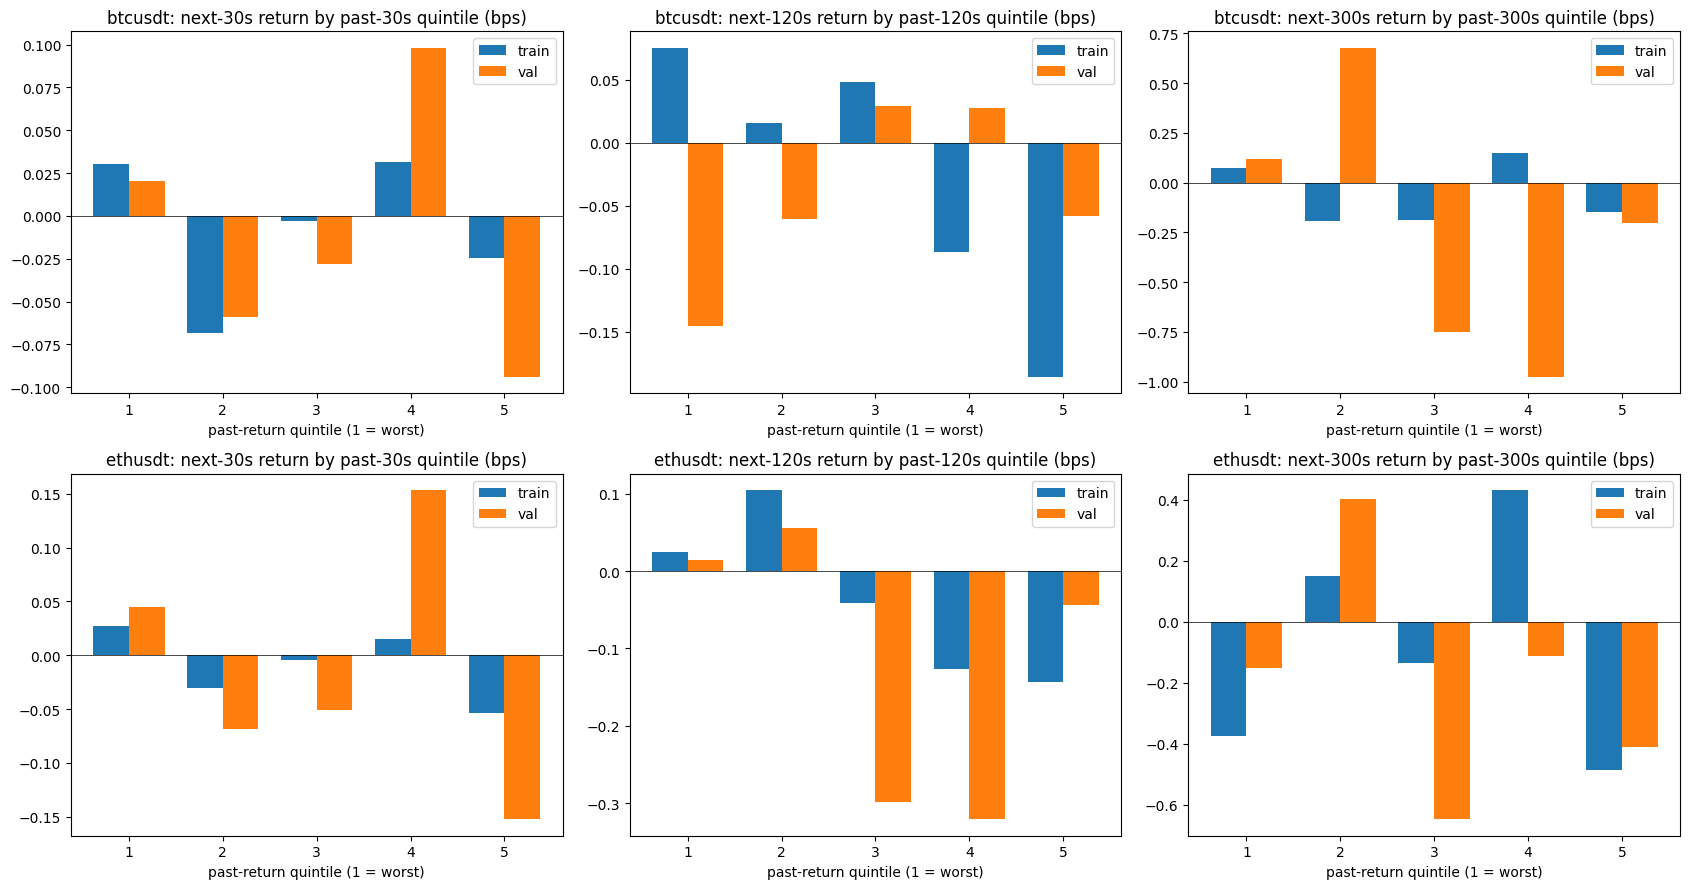

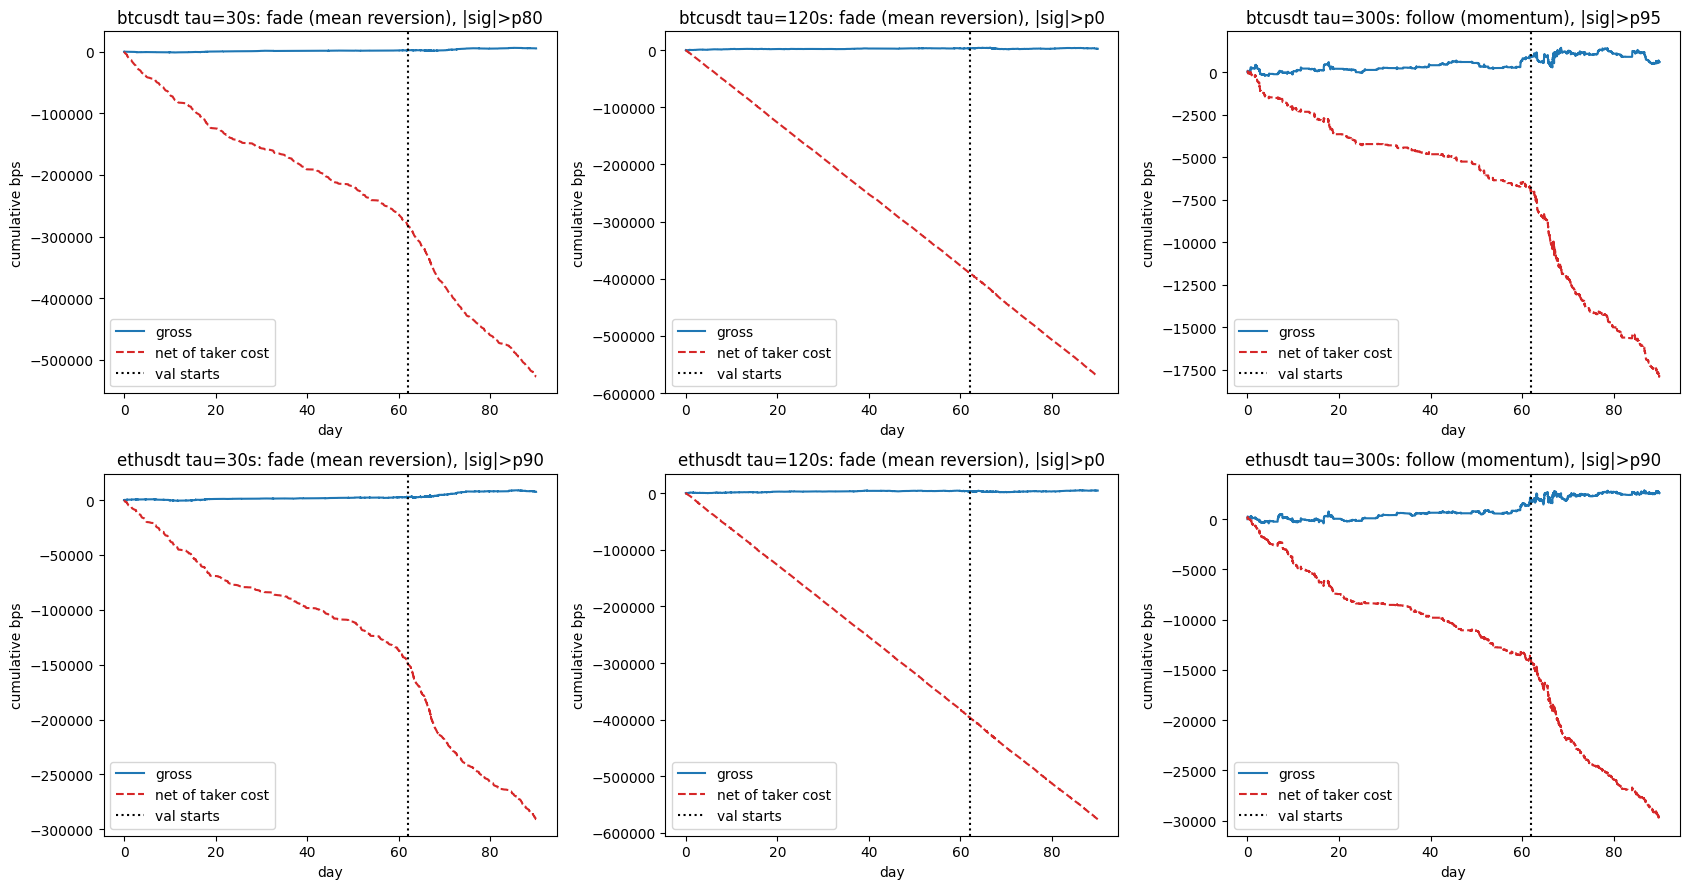

In [36]:
GRIDS, BEST, CORRT, QN = [], {}, [], {}
for s in SYMS:
    for tau in TAUS:
        X = MM[s][:, ::tau]; x = (X[:, 1:-1] / X[:, :-2] - 1) * 1e4; y = (X[:, 2:] / X[:, 1:-1] - 1) * 1e4; ok = np.isfinite(x) & np.isfinite(y); n = int(ok.sum()); xx, yy = x[ok], y[ok]
        r = float(np.corrcoef(xx, yy)[0, 1]); tt = r * np.sqrt((n - 2) / max(1 - r * r, 1e-12)); rs = float(spearmanr(xx[:200000], yy[:200000])[0]); beta = r * yy.std() / xx.std()
        CORRT.append(dict(sym=s, tau=tau, n=n, corr_past_future=r, spearman=rs, ols_beta=beta, t_stat=tt, regime="momentum" if tt > 2 else "mean reversion" if tt < -2 else "random walk"))
        T, best = rule_grid(x, y, "ts", RT_COST[s], dict(strategy="past-return", sym=s, tau=tau)); GRIDS.append(T); BEST[("ts", s, tau)] = (best, x, y)
        e = np.quantile(x[ok & TRM[:, [0] * x.shape[1]]], [.2, .4, .6, .8]) if (ok & TRM[:, [0] * x.shape[1]]).any() else np.quantile(xx, [.2, .4, .6, .8]); qb = np.where(ok, np.digitize(x, e), -1)
        QN[(s, tau)] = {nm: [float(y[(qb == i) & m & ok].mean()) if ((qb == i) & m & ok).any() else np.nan for i in range(5)] for nm, m in (("train", np.broadcast_to(TRM, x.shape)), ("val", np.broadcast_to(VAM, x.shape)))}
CT = pl.DataFrame(CORRT); CT.write_csv(WORK / "g5_momentum_meanrev_corr.csv"); GR = pl.concat(GRIDS); GR.write_csv(WORK / "g5_rule_grid_past_return.csv"); print("Does the past tau-return predict the next tau-return?"); print(CT)
SB = []
for s in SYMS:
    for tau in TAUS:
        b = BEST[("ts", s, tau)][0]
        if b is None: continue
        SB.append({k: v for k, v in b.items() if k != "_pnl"})
        c = CT.filter((pl.col("sym") == s) & (pl.col("tau") == tau)).row(0, named=True); v = VRT.filter((pl.col("sym") == s) & (pl.col("tau") == tau)).row(0, named=True)
        say(f"{s} tau={tau}s: corr(past,next)={c['corr_past_future']:+.3f} (t={c['t_stat']:+.1f}) -> {c['regime']}; variance ratio {v['VR']:.3f} (z={v['z_robust']:+.1f}).")
        say(f"   best train rule '{b['rule']}' on |signal|>p{b['pct']*100:g}: train {b['tr_mean_bps']:+.3f} bps/trade (t={b['tr_t']:+.1f}, n={b['tr_n']}), val {b['va_mean_bps']:+.3f} (t={b['va_t']:+.1f}, n={b['va_n']}); taker round-trip cost {b['rt_cost_bps']:.2f} bps -> "
            + ("no rule has a significant edge even on train (t<=2): no tradable signal at this horizon." if b["tr_t"] <= 2 else "survives costs and holds out-of-sample" if (b["va_net_bps"] > 0 and b["va_t"] > 2 and b["va_n"] >= 100) else "gross edge is below execution cost or not confirmed on validation: usable only as a signal for maker quoting (the 0.5 bps rebate regime), not for taker trading."))
SBT = pl.DataFrame(SB); SBT.write_csv(WORK / "g5_best_rule_per_horizon.csv"); print("\nBest rule per symbol and horizon (selected on train)"); print(SBT.drop([c for c in SBT.columns if c.startswith("tr_hit") or c.startswith("va_hit")]))

fig, ax = plt.subplots(len(SYMS), 3, figsize=(17, 4.5 * len(SYMS))); ax = np.atleast_2d(ax).reshape(len(SYMS), 3)
for i, s in enumerate(SYMS):
    for j, tau in enumerate(TAUS):
        q = QN[(s, tau)]; w = .38; ax[i, j].bar(np.arange(1, 6) - w / 2, q["train"], w, label="train", color="C0")
        if np.isfinite(q["val"]).any(): ax[i, j].bar(np.arange(1, 6) + w / 2, q["val"], w, label="val", color="C1")
        ax[i, j].axhline(0, c="k", lw=.5); ax[i, j].set_title(f"{s}: next-{tau}s return by past-{tau}s quintile (bps)"); ax[i, j].set_xlabel("past-return quintile (1 = worst)"); ax[i, j].legend()
fig.tight_layout(); show(fig, "g5_quintile_sort.png")
fig, ax = plt.subplots(len(SYMS), 3, figsize=(17, 4.5 * len(SYMS))); ax = np.atleast_2d(ax).reshape(len(SYMS), 3)
for i, s in enumerate(SYMS):
    for j, tau in enumerate(TAUS):
        b = BEST[("ts", s, tau)][0]
        if b is None: continue
        p = np.nan_to_num(b["_pnl"]).ravel(); c = np.cumsum(p); n_tr = np.broadcast_to(TRM, b["_pnl"].shape).ravel(); k = np.arange(len(p)); trades = np.cumsum(np.isfinite(b["_pnl"]).ravel())
        ax[i, j].plot(k / b["_pnl"].shape[1], c, label="gross", c="C0"); ax[i, j].plot(k / b["_pnl"].shape[1], c - trades * b["rt_cost_bps"], label="net of taker cost", c="C3", ls="--")
        if (~n_tr).any(): ax[i, j].axvline(np.flatnonzero(~n_tr)[0] / b["_pnl"].shape[1], c="k", ls=":", label="val starts")
        ax[i, j].set_title(f"{s} tau={tau}s: {b['rule']}, |sig|>p{b['pct']*100:g}"); ax[i, j].set_xlabel("day"); ax[i, j].set_ylabel("cumulative bps"); ax[i, j].legend()
fig.tight_layout(); show(fig, "g5_cumulative_pnl_past_return.png")

In [37]:
# 2) Liquidation-pressure signal (causal: events strictly before t; sign = side of forced order, buy => upward pressure)
LQ = []
for s in SYMS:
    ev_ts, cs = EV[s]
    for tau in TAUS:
        X = MM[s][:, ::tau]; K = X.shape[1]; tt = ((D0 + np.arange(X.shape[0]))[:, None].astype(np.int64) * DAY_US + (np.arange(K)[None, :] * tau * US)); y = (X[:, 1:] / X[:, :-1] - 1) * 1e4
        for W in CFG["STATE_WINDOWS_S"]:
            S = roll_net(tt.ravel(), ev_ts, cs, W * US).reshape(tt.shape)[:, :-1]; thr = THR[s][W]; act = (np.abs(S) > thr) & np.isfinite(y)
            for nm, m in (("train", np.broadcast_to(TRM, y.shape)), ("val", np.broadcast_to(VAM, y.shape))):
                a = pnl_stats(np.where(act & m, np.sign(S) * y, np.nan), int(m[:, 0].sum())); LQ.append(dict(sym=s, tau=tau, W_s=W, split=nm, n_active=a["n"], mean_signed_fwd_bps=a["mean_bps"], t=a["t"], hit=a["hit"], rt_cost_bps=RT_COST[s]))
LQT = pl.DataFrame(LQ); LQT.write_csv(WORK / "g5_liquidation_signal.csv"); print("Forward tau-return signed by liquidation pressure (>0 continuation/momentum, <0 reversal/fade)"); print(LQT)
for r in LQT.filter(pl.col("split") == "train").iter_rows(named=True):
    if r["n_active"] >= 30 and r["W_s"] == CFG["STATE_WINDOWS_S"][-1]:
        say(f"{r['sym']} tau={r['tau']}s after strong {r['W_s']}s liquidation pressure: signed forward return {r['mean_signed_fwd_bps']:+.2f} bps (t={r['t']:+.1f}, n={r['n_active']}) -> " + ("continuation (momentum): follow the cascade or widen / pull maker quotes on the exposed side." if r["t"] > 2 else "reversal (liquidity premium): fade the overshoot." if r["t"] < -2 else "no significant drift."))

Forward tau-return signed by liquidation pressure (>0 continuation/momentum, <0 reversal/fade)
shape: (24, 9)
┌─────────┬─────┬─────┬───────┬──────────┬─────────────────────┬───────────┬──────────┬─────────────┐
│ sym     ┆ tau ┆ W_s ┆ split ┆ n_active ┆ mean_signed_fwd_bps ┆ t         ┆ hit      ┆ rt_cost_bps │
│ ---     ┆ --- ┆ --- ┆ ---   ┆ ---      ┆ ---                 ┆ ---       ┆ ---      ┆ ---         │
│ str     ┆ i64 ┆ i64 ┆ str   ┆ i64      ┆ f64                 ┆ f64       ┆ f64      ┆ f64         │
╞═════════╪═════╪═════╪═══════╪══════════╪═════════════════════╪═══════════╪══════════╪═════════════╡
│ btcusdt ┆ 30  ┆ 10  ┆ train ┆ 683      ┆ -0.915292           ┆ -1.50198  ┆ 0.418741 ┆ 9.011363    │
│ btcusdt ┆ 30  ┆ 10  ┆ val   ┆ 457      ┆ -2.721204           ┆ -3.4905   ┆ 0.459519 ┆ 9.011363    │
│ btcusdt ┆ 30  ┆ 60  ┆ train ┆ 2242     ┆ -0.27459            ┆ -1.02549  ┆ 0.46521  ┆ 9.011363    │
│ btcusdt ┆ 30  ┆ 60  ┆ val   ┆ 1573     ┆ -0.6473             ┆ -1.645221

  >> Lead-lag at 1s: strongest cross-correlation at lag +0s (+0.740); corr at lag 0 = +0.740. contemporaneous: no usable lead-lag.

Predictive power of past btcusdt return for next ethusdt return
shape: (3, 8)
┌─────┬─────────────┬───────────┬─────────────┬───────────────────────────┬─────────────┬─────────────┬───────────┐
│ tau ┆ corr_A_to_B ┆ t         ┆ corr_B_to_A ┆ best_rule                 ┆ tr_mean_bps ┆ va_mean_bps ┆ va_t      │
│ --- ┆ ---         ┆ ---       ┆ ---         ┆ ---                       ┆ ---         ┆ ---         ┆ ---       │
│ i64 ┆ f64         ┆ f64       ┆ f64         ┆ str                       ┆ f64         ┆ f64         ┆ f64       │
╞═════╪═════════════╪═══════════╪═════════════╪═══════════════════════════╪═════════════╪═════════════╪═══════════╡
│ 30  ┆ -0.009248   ┆ -4.706291 ┆ 0.003215    ┆ fade (mean reversion) p80 ┆ 0.082094    ┆ 0.07032     ┆ 0.937471  │
│ 120 ┆ -0.010961   ┆ -2.786196 ┆ -0.00986    ┆ fade (mean reversion) p80 ┆ 0.146338    ┆ -0.1

/tmp/ipykernel_16/3872515251.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  try: k = kpss(x, regression="c", nlags="auto")[1]



BTC-ETH spread (train) {'hedge_beta': 1.4981464471156545, 'alpha': -9.065253241665292, 'engle_granger_t': -3.763445406440389, 'engle_granger_p': 0.01515434223200823, 'adf_p_spread': 0.0033044851825346556, 'kpss_p_spread': np.float64(0.01), 'half_life_min': 1744.1452007273579}
  >> Spread ethusdt - 1.50*btcusdt: Engle-Granger p=0.0152, ADF p=0.0033, KPSS p=0.01, OU half-life 1744 min -> cointegrated and mean-reverting: relative-value (stat-arb) trading is statistically supported.
  >> pair tau=30s: best 'fade (mean reversion)' when |z|>p0 of train |z| (0.00 sd): train +0.034 bps (t=+4.2), val +0.056 bps (t=+3.1), two-leg taker cost 22.5 bps -> edge too small for taker execution; informative for maker pricing only.
  >> pair tau=120s: best 'fade (mean reversion)' when |z|>p0 of train |z| (0.00 sd): train +0.112 bps (t=+3.7), val +0.193 bps (t=+2.8), two-leg taker cost 22.5 bps -> edge too small for taker execution; informative for maker pricing only.
  >> pair tau=300s: best 'fade (mean

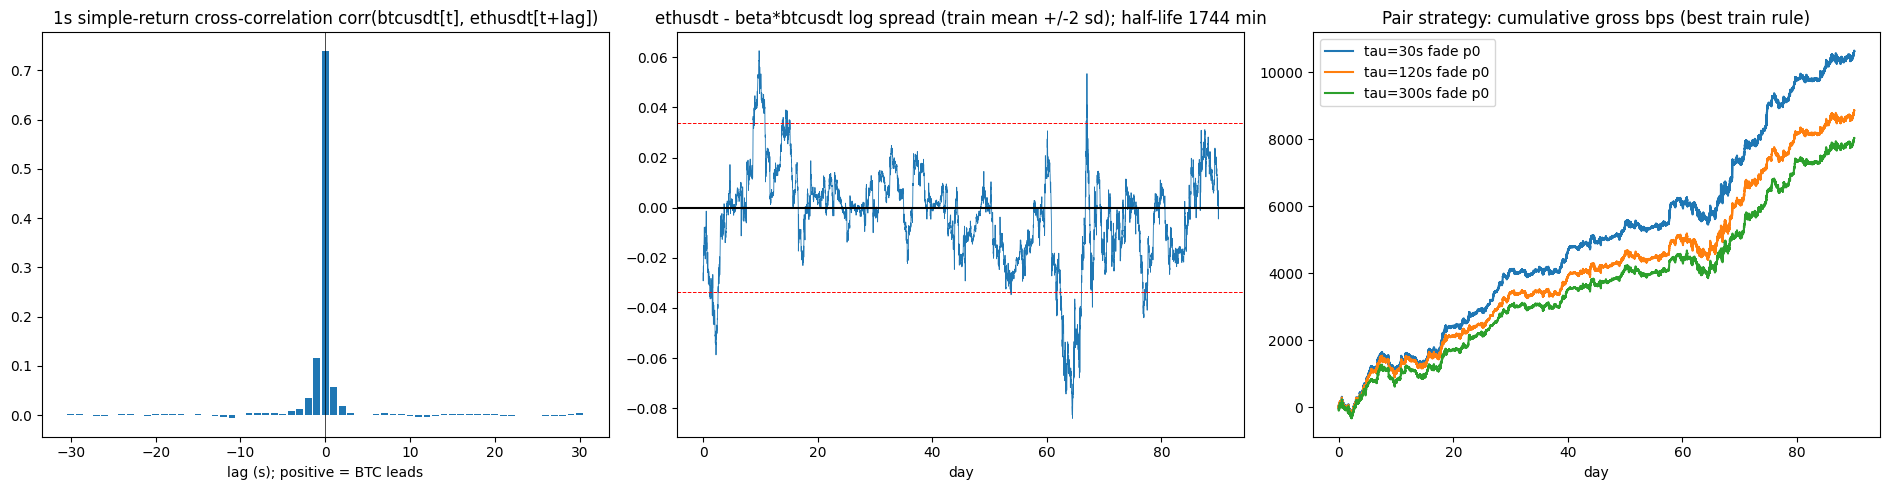

In [38]:
# 3) Lead-lag BTC <-> ETH and statistical arbitrage on the cointegrated spread
if len(SYMS) == 2:
    r1, r2 = ret_matrix(A_, 1) / 1e4, ret_matrix(B_, 1) / 1e4; Nn = r1.shape[1]; LAGS = list(range(-30, 31)); CC = []
    m1, m2 = np.nanmean(r1), np.nanmean(r2)
    for k in LAGS:
        a, b = (r1[:, :Nn - k], r2[:, k:]) if k >= 0 else (r1[:, -k:], r2[:, :Nn + k]); ok = np.isfinite(a) & np.isfinite(b); aa, bb = a[ok] - m1, b[ok] - m2; CC.append(float((aa * bb).sum() / np.sqrt((aa ** 2).sum() * (bb ** 2).sum())))
    LL = pl.DataFrame(dict(lag_s=LAGS, corr=CC)); LL.write_csv(WORK / "g5_leadlag_corr.csv"); kmax = LAGS[int(np.argmax(np.abs(CC)))]
    say(f"Lead-lag at 1s: strongest cross-correlation at lag {kmax:+d}s ({max(CC, key=abs):+.3f}); corr at lag 0 = {CC[30]:+.3f}. " + ("positive lag: " + A_ + " leads " + B_ + " by about that many seconds (exploitable only if quotes can be hit faster than the follower reprices)." if kmax > 0 else "negative lag: " + B_ + " leads " + A_ + "." if kmax < 0 else "contemporaneous: no usable lead-lag."))
    LEAD = []
    for tau in TAUS:
        Xa, Xb = MM[A_][:, ::tau], MM[B_][:, ::tau]; xa = (Xa[:, 1:-1] / Xa[:, :-2] - 1) * 1e4; yb = (Xb[:, 2:] / Xb[:, 1:-1] - 1) * 1e4; ok = np.isfinite(xa) & np.isfinite(yb); r = float(np.corrcoef(xa[ok], yb[ok])[0, 1]); n = int(ok.sum())
        xb_ = (Xb[:, 1:-1] / Xb[:, :-2] - 1) * 1e4; ya = (Xa[:, 2:] / Xa[:, 1:-1] - 1) * 1e4; ok2 = np.isfinite(xb_) & np.isfinite(ya); r2_ = float(np.corrcoef(xb_[ok2], ya[ok2])[0, 1])
        T, best = rule_grid(xa, yb, "lead", RT_COST[B_], dict(strategy=f"{A_} past -> {B_} next", sym=B_, tau=tau)); GRIDS.append(T)
        LEAD.append(dict(tau=tau, corr_A_to_B=r, t=r * np.sqrt((n - 2) / (1 - r * r)), corr_B_to_A=r2_, best_rule=(best["rule"] + f" p{best['pct']*100:g}") if best else None, tr_mean_bps=best["tr_mean_bps"] if best else np.nan, va_mean_bps=best["va_mean_bps"] if best else np.nan, va_t=best["va_t"] if best else np.nan))
    LEADT = pl.DataFrame(LEAD); print(f"\nPredictive power of past {A_} return for next {B_} return"); print(LEADT)
    for r in LEAD: say(f"tau={r['tau']}s: past {A_} -> next {B_} corr {r['corr_A_to_B']:+.3f} (t={r['t']:+.1f}) vs reverse {r['corr_B_to_A']:+.3f}; " + ("BTC leads ETH (forward predictability exceeds the reverse direction)." if (r["t"] > 2 and r["corr_A_to_B"] - r["corr_B_to_A"] > 0.02) else "mutual predictability but no clear leader (shared volatility or noise, not a lead-lag edge)." if abs(r["t"]) > 2 else "no significant spillover at this horizon."))
    # --- statistical arbitrage: Engle-Granger on 60s log prices (levels only for the cointegration test), trade with simple returns
    pa, pb = MM[A_][:, ::BAR_S].ravel(), MM[B_][:, ::BAR_S].ravel(); okp = np.isfinite(pa) & np.isfinite(pb); la, lb = np.log(pa[okp]), np.log(pb[okp]); drow = np.repeat(np.arange(NDAYS_RANGE), MM[A_][:, ::BAR_S].shape[1])[okp]; trm = SPLIT_ROW[drow] == "train"
    if not trm.any(): trm = np.ones(len(la), bool)
    bta, alp = np.polyfit(la[trm], lb[trm], 1); sp = lb - bta * la - alp
    try: eg = coint(lb[trm], la[trm], trend="c", maxlag=10, autolag="bic"); eg_t, eg_p = float(eg[0]), float(eg[1])
    except Exception: eg_t, eg_p = np.nan, np.nan
    ap_, kp_ = adf_kpss(sp[trm]); dsp = np.diff(sp[trm]); bl = float(np.cov(dsp, sp[trm][:-1])[0, 1] / np.var(sp[trm][:-1])); hl = float(-np.log(2) / np.log1p(bl)) if -1 < bl < 0 else np.inf
    COI = dict(hedge_beta=float(bta), alpha=float(alp), engle_granger_t=eg_t, engle_granger_p=eg_p, adf_p_spread=ap_, kpss_p_spread=kp_, half_life_min=hl * BAR_S / 60)
    print("\nBTC-ETH spread (train)", COI); pl.DataFrame([COI]).write_csv(WORK / "g5_cointegration.csv")
    say(f"Spread {B_} - {bta:.2f}*{A_}: Engle-Granger p={eg_p:.3g}, ADF p={ap_:.3g}, KPSS p={kp_:.3g}, OU half-life {hl * BAR_S / 60:.0f} min -> " + ("cointegrated and mean-reverting: relative-value (stat-arb) trading is statistically supported." if (eg_p < .05 and ap_ < .05) else "no stable cointegration: the ratio drifts, so fading it is a bet on regime, not an arbitrage."))
    mu_s, sd_s = float(sp[trm].mean()), float(sp[trm].std()); PAIRB = {}
    for tau in TAUS:
        Xa, Xb = MM[A_][:, ::tau], MM[B_][:, ::tau]; z = (np.log(Xb) - bta * np.log(Xa) - alp - mu_s) / sd_s; z = z[:, 1:-1]
        y = ((Xb[:, 2:] / Xb[:, 1:-1] - 1) - bta * (Xa[:, 2:] / Xa[:, 1:-1] - 1)) * 1e4; cost = 2 * (SPREAD_MED[B_] / 2 + TAKER_FEE_BPS) + abs(bta) * 2 * (SPREAD_MED[A_] / 2 + TAKER_FEE_BPS)
        T, best = rule_grid(z, y, "pair", cost, dict(strategy="BTC-ETH z-score", sym="pair", tau=tau)); GRIDS.append(T); PAIRB[tau] = (best, z)
        if best: say(f"pair tau={tau}s: best '{best['rule']}' when |z|>p{best['pct']*100:g} of train |z| ({best['thr']:.2f} sd): train {best['tr_mean_bps']:+.3f} bps (t={best['tr_t']:+.1f}), val {best['va_mean_bps']:+.3f} bps (t={best['va_t']:+.1f}), two-leg taker cost {cost:.1f} bps -> " + ("tradable after costs" if (best["va_net_bps"] > 0 and best["va_t"] > 2 and best["va_n"] >= 100) else "edge too small for taker execution; informative for maker pricing only."))
    pl.concat(GRIDS, how="diagonal_relaxed").write_csv(WORK / "g5_all_rule_grids.csv")
    fig, ax = plt.subplots(1, 3, figsize=(19, 5)); ax[0].bar(LAGS, CC, color="C0"); ax[0].axvline(0, c="k", lw=.5); ax[0].set_title(f"1s simple-return cross-correlation corr({A_}[t], {B_}[t+lag])"); ax[0].set_xlabel("lag (s); positive = BTC leads")
    ax[1].plot(np.arange(len(sp))[::15] / (1440 * 60 / BAR_S), sp[::15], lw=.6); ax[1].axhline(mu_s, c="k"); [ax[1].axhline(mu_s + k * sd_s, c="r", ls="--", lw=.7) for k in (-2, 2)]; ax[1].set_title(f"{B_} - beta*{A_} log spread (train mean +/-2 sd); half-life {hl * BAR_S / 60:.0f} min"); ax[1].set_xlabel("day")
    for tau, c in zip(TAUS, ("C0", "C1", "C2")):
        b, z = PAIRB[tau]
        if b is None: continue
        p = np.nan_to_num(b["_pnl"]).ravel(); ax[2].plot(np.arange(len(p)) / b["_pnl"].shape[1], np.cumsum(p), c=c, label=f"tau={tau}s {b['rule'].split(' ')[0]} p{b['pct']*100:g}")
    ax[2].set_title("Pair strategy: cumulative gross bps (best train rule)"); ax[2].set_xlabel("day"); ax[2].legend(); fig.tight_layout(); show(fig, "g5_leadlag_pairs.png")

In [39]:
(WORK / "interpretation_stats.txt").write_text("\n".join(INTERP)); print(f"\nSaved {len(INTERP)} interpretation lines to interpretation_stats.txt")
mark("G time-series/tails/copulas/strategies")


Saved 65 interpretation lines to interpretation_stats.txt
[stage G time-series/tails/copulas/strategies] 57.6s peak_rss=11.41GB


# H. Which distribution fits the simple returns? (statistical selection with justification)
**Protocol.** Candidates are fitted by maximum likelihood on a random sample of the *fit* days and judged **out of sample** (validation days; if the data has no split, odd days) so that a flexible model is not rewarded for over-fitting.
Criteria, each answering a different question:
* **BIC** (fit sample) - parsimony; **mean log-likelihood** (held-out) - overall predictive density; **KS distance** - largest CDF gap (the p-value is meaningless at n~10^5, only the distance is used); **Anderson-Darling distance** - weights the tails;
* **tail quantile error** - mean |log(model/empirical)| of the 0.1/0.5/1 % and 99/99.5/99.9 % quantiles, and a **Kupiec** test of the 0.1 % / 99.9 % exceedance counts - what a risk number actually needs;
* **PIT histogram** - a calibrated model gives a flat histogram.
Two further tests of *why* returns are heavy-tailed: **standardise by a causal EWMA volatility** (if heavy tails are just volatility clustering the standardised returns become much closer to normal and the t degrees of freedom jump), and **aggregation across horizons** (nu should rise towards normality).
Execution time of every fit is recorded; slow four-parameter families are fitted on a smaller sample (`FIT_N`).

In [40]:
import numba
FIT_N = CFG["FIT_N"]; SLOW_N = min(FIT_N, 40_000); EVAL_N = 300_000; PQ = [.001, .005, .01, .05, .95, .99, .995, .999]; TAILP = [.001, .005, .01, .99, .995, .999]
rng = np.random.default_rng(7)

class M:                                         # tiny uniform interface for every candidate
    def __init__(s, name, k, logpdf, cdf, ppf, params, fit_s, n_fit): s.name, s.k, s.logpdf, s.cdf, s.ppf, s.params, s.fit_s, s.n_fit = name, k, logpdf, cdf, ppf, params, fit_s, n_fit
def fit_scipy(name, dist, z, n):
    zz = z if len(z) <= n else rng.choice(z, n, replace=False); t0 = time.time(); p = dist.fit(zz); fr = dist(*p)
    return M(name, len(p), fr.logpdf, fr.cdf, fr.ppf, np.round(p, 4).tolist(), time.time() - t0, len(zz))
def fit_gmm2(z, n, iters=300):
    zz = z if len(z) <= n else rng.choice(z, n, replace=False); t0 = time.time(); w, m1, m2, s1, s2 = .8, 0., 0., .6 * zz.std(), 2. * zz.std()
    for _ in range(iters):
        p1 = w * norm.pdf(zz, m1, s1); p2 = (1 - w) * norm.pdf(zz, m2, s2); r = p1 / (p1 + p2 + 1e-300); wn = r.mean(); m1 = (r * zz).sum() / r.sum(); m2 = ((1 - r) * zz).sum() / (1 - r).sum()
        s1n = np.sqrt((r * (zz - m1) ** 2).sum() / r.sum()); s2n = np.sqrt(((1 - r) * (zz - m2) ** 2).sum() / (1 - r).sum()); done = abs(wn - w) < 1e-7 and abs(s1n - s1) < 1e-7 and abs(s2n - s2) < 1e-7; w, s1, s2 = wn, s1n, s2n
        if done: break
    grid = np.linspace(zz.min() * 1.5 - 1, zz.max() * 1.5 + 1, 40001); cg = w * norm.cdf(grid, m1, s1) + (1 - w) * norm.cdf(grid, m2, s2)
    return M("Normal mixture (2)", 5, lambda x: np.log(w * norm.pdf(x, m1, s1) + (1 - w) * norm.pdf(x, m2, s2) + 1e-300), lambda x: w * norm.cdf(x, m1, s1) + (1 - w) * norm.cdf(x, m2, s2),
             lambda p: np.interp(p, cg, grid), [round(w, 3), round(m1, 3), round(m2, 3), round(s1, 3), round(s2, 3)], time.time() - t0, len(zz))
CANDS = [("Normal", sps.norm, FIT_N), ("Laplace", sps.laplace, FIT_N), ("Logistic", sps.logistic, FIT_N), ("Student-t", sps.t, FIT_N), ("Generalised normal", sps.gennorm, SLOW_N),
         ("Johnson SU", sps.johnsonsu, SLOW_N), ("NIG (normal-inverse Gaussian)", sps.norminvgauss, SLOW_N), ("Cauchy", sps.cauchy, FIT_N)]
def fit_all(z):
    out = []
    for name, dist, n in CANDS:
        try: out.append(fit_scipy(name, dist, z, n))
        except Exception as e: print("  fit failed:", name, str(e)[:60])
    try: out.append(fit_gmm2(z, FIT_N))
    except Exception as e: print("  fit failed: mixture", str(e)[:60])
    return out
def ad_dist(u):
    u = np.clip(np.sort(u), 1e-12, 1 - 1e-12); n = len(u); i = np.arange(1, n + 1); return float(-1 - np.mean((2 * i - 1) / n * (np.log(u) + np.log(1 - u[::-1]))))        # A^2 / n
def kupiec(x_viol, n, p):
    lo = binom.cdf(x_viol, n, p) if x_viol < n * p else 1 - binom.cdf(x_viol - 1, n, p); return float(min(1, 2 * lo))
def evaluate(models, zf, ze, label):
    ze = ze if len(ze) <= EVAL_N else rng.choice(ze, EVAL_N, replace=False); zs = np.sort(ze); emp = np.quantile(ze, TAILP); rows = []
    for m in models:
        ll_fit = float(np.mean(m.logpdf(zf if len(zf) <= m.n_fit else zf[:m.n_fit]))); ll_ev = float(np.mean(m.logpdf(ze))); u = m.cdf(zs); ks = float(np.max(np.maximum(np.arange(1, len(zs) + 1) / len(zs) - u, u - np.arange(0, len(zs)) / len(zs)))); ad = ad_dist(u)
        try: q = m.ppf(np.array(TAILP)); te = float(np.mean(np.abs(np.log(np.abs(q) / np.abs(emp))))); v = [kupiec(int((ze < m.ppf(np.array([p]))[0]).sum()), len(ze), p) if p < .5 else kupiec(int((ze > m.ppf(np.array([p]))[0]).sum()), len(ze), 1 - p) for p in (.001, .999)]
        except Exception: te, v = np.nan, [np.nan, np.nan]
        rows.append(dict(sample=label, model=m.name, k=m.k, n_fit=m.n_fit, fit_seconds=round(m.fit_s, 1), BIC_per_obs=float(m.k * np.log(m.n_fit) / m.n_fit - 2 * ll_fit), ll_heldout=ll_ev, KS_D=ks, AD_per_obs=ad, tail_q_err=te, kupiec_p_0p1pct=v[0], kupiec_p_99p9pct=v[1], params=str(m.params)))
    T = pl.DataFrame(rows)
    for c, asc in (("ll_heldout", False), ("KS_D", True), ("AD_per_obs", True), ("tail_q_err", True), ("BIC_per_obs", True)): T = T.with_columns(pl.col(c).rank("min", descending=not asc).alias(f"rk_{c}"))
    return T.with_columns(((pl.col("rk_ll_heldout") + pl.col("rk_AD_per_obs") + pl.col("rk_tail_q_err") + pl.col("rk_KS_D")) / 4).alias("mean_rank")).sort("mean_rank")

@numba.njit(cache=True)
def _ewma_sigma(r, lam, s0):
    out = np.empty(len(r)); v = s0
    for i in range(len(r)): out[i] = np.sqrt(v); v = lam * v + (1 - lam) * r[i] * r[i]
    return out
def split_fit_eval(sym):
    x, d, sp = RB[sym]["r"], RB[sym]["day"], RB[sym]["split"]
    if (sp == "train").sum() > 5000 and (sp == "val").sum() > 5000: return (sp == "train"), (sp == "val"), "train -> val"
    return (d % 2 == 0), (d % 2 == 1), "even days -> odd days"
FITS, EVALS, H_STORE = [], {}, {}
for s in SYMS:
    x = RB[s]["r"]; fm, em, how = split_fit_eval(s); mu, sd = float(x[fm].mean()), float(x[fm].std())
    sig = _ewma_sigma(x, 0.94, sd); sigma_ok = np.arange(len(x)) >= 120                           # causal EWMA volatility (RiskMetrics lambda=0.94), first 120 bars burn-in
    for lab, zz in (("raw", (x - mu) / sd), ("EWMA-standardised", x / np.where(sig > 0, sig, np.nan))):
        ok = np.isfinite(zz) & sigma_ok if lab != "raw" else np.isfinite(zz); zf, ze = zz[fm & ok], zz[em & ok]
        if lab != "raw": m2, s2 = zf.mean(), zf.std(); zf, ze = (zf - m2) / s2, (ze - m2) / s2
        t0 = time.time(); mods = fit_all(zf); T = evaluate(mods, zf, ze, lab).with_columns(pl.lit(s).alias("sym"), pl.lit(how).alias("split")); FITS.append(T); H_STORE[(s, lab)] = dict(models={m.name: m for m in mods}, zf=zf, ze=ze, T=T)
        print(f"{s} [{lab}] fit {how}: n_fit={len(zf)} n_eval={len(ze)}  ({time.time() - t0:.0f}s)")
HT = pl.concat(FITS).select("sym", "sample", "split", "model", "k", "n_fit", "fit_seconds", "BIC_per_obs", "ll_heldout", "KS_D", "AD_per_obs", "tail_q_err", "kupiec_p_0p1pct", "kupiec_p_99p9pct", "mean_rank", "params"); HT.write_csv(WORK / "h_distribution_fit.csv")
for s in SYMS:
    for lab in ("raw", "EWMA-standardised"):
        print(f"\n{s} - {lab} (rank 1 = best; ll_heldout higher better; others lower better)"); print(HT.filter((pl.col("sym") == s) & (pl.col("sample") == lab)).drop("sym", "sample", "split", "params"))

btcusdt [raw] fit train -> val: n_fit=89207 n_eval=40282  (54s)
btcusdt [EWMA-standardised] fit train -> val: n_fit=89087 n_eval=40282  (47s)
ethusdt [raw] fit train -> val: n_fit=89203 n_eval=40283  (49s)
ethusdt [EWMA-standardised] fit train -> val: n_fit=89083 n_eval=40283  (40s)

btcusdt - raw (rank 1 = best; ll_heldout higher better; others lower better)
shape: (9, 12)
┌───────────────────────────────┬─────┬───────┬─────────────┬─────────────┬────────────┬──────────┬────────────┬────────────┬─────────────────┬──────────────────┬───────────┐
│ model                         ┆ k   ┆ n_fit ┆ fit_seconds ┆ BIC_per_obs ┆ ll_heldout ┆ KS_D     ┆ AD_per_obs ┆ tail_q_err ┆ kupiec_p_0p1pct ┆ kupiec_p_99p9pct ┆ mean_rank │
│ ---                           ┆ --- ┆ ---   ┆ ---         ┆ ---         ┆ ---        ┆ ---      ┆ ---        ┆ ---        ┆ ---             ┆ ---              ┆ ---       │
│ str                           ┆ i64 ┆ i64   ┆ f64         ┆ f64         ┆ f64        ┆ f64      

In [41]:
# Justification: automatic reading of the tables
def best(T, col, asc=True): r = T.sort(col, descending=not asc).row(0, named=True); return r["model"]
for s in SYMS:
    Tr, Ts = H_STORE[(s, "raw")]["T"], H_STORE[(s, "EWMA-standardised")]["T"]; w = Tr.row(0, named=True); nm = Tr.filter(pl.col("model") == "Normal").row(0, named=True); tt = Tr.filter(pl.col("model") == "Student-t").row(0, named=True)
    say(f"{s}: out-of-sample winner (mean of log-lik/KS/AD/tail ranks) = {w['model']}; best held-out log-likelihood = {best(Tr, 'll_heldout', False)}, best tails (AD) = {best(Tr, 'AD_per_obs')}, smallest tail-quantile error = {best(Tr, 'tail_q_err')}, lowest BIC = {best(Tr, 'BIC_per_obs')}.")
    say(f"{s}: the Normal is {'rejected' if nm['mean_rank'] > tt['mean_rank'] else 'NOT clearly beaten'} as a description: held-out log-lik {nm['ll_heldout']:.3f} vs {tt['ll_heldout']:.3f} for Student-t, tail-quantile error {nm['tail_q_err']:.2f} vs {tt['tail_q_err']:.2f} (Kupiec p at 0.1 % tail: normal {nm['kupiec_p_0p1pct']:.3g}, t {tt['kupiec_p_0p1pct']:.3g}).")
    nu = H_STORE[(s, "raw")]["models"]["Student-t"].params[0]; nus = H_STORE[(s, "EWMA-standardised")]["models"]["Student-t"].params[0]; ws = Ts.row(0, named=True)
    say(f"{s}: Student-t degrees of freedom nu = {nu:.1f} for raw returns but {nus:.1f} after dividing by causal EWMA volatility; best model after standardisation = {ws['model']} -> " + ("a large part of the heavy tail is volatility clustering (time-varying scale): model returns as a conditional-scale model (GARCH/EWMA) with t or NIG innovations." if nus > 1.5 * nu else "the tail stays heavy even after removing volatility clustering: jumps/liquidation shocks are a separate tail source, keep a heavy-tailed innovation."))
    nlow = Tr.filter(pl.col("model").is_in(["Normal", "Laplace", "Logistic", "Cauchy"]))["mean_rank"].min(); say(f"{s}: families with a free tail/skew parameter (t, NIG, Johnson SU, generalised normal) rank {'ahead of' if Tr.filter(pl.col('model').is_in(['Student-t','NIG (normal-inverse Gaussian)','Johnson SU','Generalised normal']))['mean_rank'].min() < nlow else 'behind'} the fixed-shape ones (Normal/Laplace/Logistic/Cauchy). Skew: sample skew {sps.skew(H_STORE[(s,'raw')]['ze']):+.2f}.")

  >> btcusdt: out-of-sample winner (mean of log-lik/KS/AD/tail ranks) = Johnson SU; best held-out log-likelihood = Johnson SU, best tails (AD) = Normal, smallest tail-quantile error = Student-t, lowest BIC = Student-t.
  >> btcusdt: the Normal is NOT clearly beaten as a description: held-out log-lik -2.225 vs -1.863 for Student-t, tail-quantile error 0.87 vs 0.26 (Kupiec p at 0.1 % tail: normal 0, t 0.00791).
  >> btcusdt: Student-t degrees of freedom nu = 2.1 for raw returns but 4.0 after dividing by causal EWMA volatility; best model after standardisation = Student-t -> a large part of the heavy tail is volatility clustering (time-varying scale): model returns as a conditional-scale model (GARCH/EWMA) with t or NIG innovations.
  >> btcusdt: families with a free tail/skew parameter (t, NIG, Johnson SU, generalised normal) rank ahead of the fixed-shape ones (Normal/Laplace/Logistic/Cauchy). Skew: sample skew +0.36.
  >> ethusdt: out-of-sample winner (mean of log-lik/KS/AD/tail ranks) 

In [42]:
# Tail-only model: POT/GPD vs the parametric bodies (from G3) - evaluated on the same held-out sample
TQ = []
for s in SYMS:
    x = RB[s]["r"]; fm, em, _ = split_fit_eval(s); xe = x[em]
    for tail, sg in (("loss", -1.0), ("gain", 1.0)):
        y_fit, y_ev = sg * x[fm], sg * xe
        try: fits, f = choose_u(y_fit)
        except Exception: continue
        for p in (.99, .999):
            v, e = pot_risk(f, p); emp = float(np.quantile(y_ev, p)); zf_ = (y_fit.mean(), y_fit.std()); mt = H_STORE[(s, "raw")]["models"]["Student-t"]; mu_, sd_ = float(x[fm].mean()), float(x[fm].std())
            qt = (-1 if tail == "loss" else 1) * 0 + (sg * (mu_ + sd_ * mt.ppf(p if sg > 0 else 1 - p)))
            TQ.append(dict(sym=s, tail=tail, p=p, empirical_heldout_bps=emp, POT_GPD_bps=v, Student_t_bps=float(qt), Normal_bps=float(y_fit.mean() + y_fit.std() * norm.ppf(p)), err_POT=v / emp - 1, err_t=qt / emp - 1, err_normal=(y_fit.mean() + y_fit.std() * norm.ppf(p)) / emp - 1))
TQT = pl.DataFrame(TQ); TQT.write_csv(WORK / "h_tail_quantiles_pot_vs_parametric.csv"); print("Held-out tail quantiles (bps): empirical vs POT-GPD vs Student-t vs Normal; err = model/empirical - 1"); print(TQT)
for r in TQ:
    if r["p"] == .999: say(f"{r['sym']} {r['tail']} 99.9 % quantile on held-out data: empirical {r['empirical_heldout_bps']:.1f} bps; POT-GPD {r['POT_GPD_bps']:.1f} ({r['err_POT']*100:+.0f} %), Student-t {r['Student_t_bps']:.1f} ({r['err_t']*100:+.0f} %), Normal {r['Normal_bps']:.1f} ({r['err_normal']*100:+.0f} %).")

Held-out tail quantiles (bps): empirical vs POT-GPD vs Student-t vs Normal; err = model/empirical - 1
shape: (8, 10)
┌─────────┬──────┬───────┬───────────────────────┬─────────────┬───────────────┬────────────┬───────────┬───────────┬────────────┐
│ sym     ┆ tail ┆ p     ┆ empirical_heldout_bps ┆ POT_GPD_bps ┆ Student_t_bps ┆ Normal_bps ┆ err_POT   ┆ err_t     ┆ err_normal │
│ ---     ┆ ---  ┆ ---   ┆ ---                   ┆ ---         ┆ ---           ┆ ---        ┆ ---       ┆ ---       ┆ ---        │
│ str     ┆ str  ┆ f64   ┆ f64                   ┆ f64         ┆ f64           ┆ f64        ┆ f64       ┆ f64       ┆ f64        │
╞═════════╪══════╪═══════╪═══════════════════════╪═════════════╪═══════════════╪════════════╪═══════════╪═══════════╪════════════╡
│ btcusdt ┆ loss ┆ 0.99  ┆ 28.965479             ┆ 17.343662   ┆ 19.005549     ┆ 14.070672  ┆ -0.40123  ┆ -0.343855 ┆ -0.514226  │
│ btcusdt ┆ loss ┆ 0.999 ┆ 51.04688              ┆ 34.818085   ┆ 58.092937     ┆ 18.686331  ┆ -0.

In [43]:
# Aggregational Gaussianity: Student-t nu and excess kurtosis versus horizon
HZ = [60, 120, 300, 900, 3600]; HR = []
for s in SYMS:
    for h in HZ:
        x = ret_matrix(s, h).ravel(); x = x[np.isfinite(x)]
        if len(x) < 500: continue
        z = (x - x.mean()) / x.std(); zz = z if len(z) <= 100_000 else rng.choice(z, 100_000, replace=False); p = sps.t.fit(zz); HR.append(dict(sym=s, horizon_s=h, n=len(x), t_nu=float(p[0]), ex_kurt=float(sps.kurtosis(x)), skew=float(sps.skew(x)), jb_p=float(sps.jarque_bera(x).pvalue)))
HRT = pl.DataFrame(HR); HRT.write_csv(WORK / "h_horizon_scaling.csv"); print("Student-t nu and excess kurtosis by horizon (nu -> infinity and kurtosis -> 0 = Gaussian)"); print(HRT)
for s in SYMS:
    t = HRT.filter(pl.col("sym") == s).sort("horizon_s")
    if t.height > 1: say(f"{s}: Student-t nu goes from {t['t_nu'][0]:.1f} at {t['horizon_s'][0]}s to {t['t_nu'][-1]:.1f} at {t['horizon_s'][-1]}s (excess kurtosis {t['ex_kurt'][0]:.1f} -> {t['ex_kurt'][-1]:.1f}) -> " + ("returns become more Gaussian with aggregation, so the heavy-tail model matters most for short-horizon (tau) risk and the 30-300 s strategies." if t["t_nu"][-1] > t["t_nu"][0] else "tails do not thin out with aggregation: persistent heavy tails (jumps / regime shifts)."))

Student-t nu and excess kurtosis by horizon (nu -> infinity and kurtosis -> 0 = Gaussian)
shape: (10, 7)
┌─────────┬───────────┬────────┬──────────┬───────────┬───────────┬──────┐
│ sym     ┆ horizon_s ┆ n      ┆ t_nu     ┆ ex_kurt   ┆ skew      ┆ jb_p │
│ ---     ┆ ---       ┆ ---    ┆ ---      ┆ ---       ┆ ---       ┆ ---  │
│ str     ┆ i64       ┆ i64    ┆ f64      ┆ f64       ┆ f64       ┆ f64  │
╞═════════╪═══════════╪════════╪══════════╪═══════════╪═══════════╪══════╡
│ btcusdt ┆ 60        ┆ 129489 ┆ 2.032478 ┆ 33.836769 ┆ 0.297392  ┆ 0.0  │
│ btcusdt ┆ 120       ┆ 64698  ┆ 2.048921 ┆ 27.751531 ┆ 0.274304  ┆ 0.0  │
│ btcusdt ┆ 300       ┆ 25825  ┆ 2.112403 ┆ 14.648324 ┆ 0.248266  ┆ 0.0  │
│ btcusdt ┆ 900       ┆ 8545   ┆ 2.144209 ┆ 15.731592 ┆ -0.502952 ┆ 0.0  │
│ btcusdt ┆ 3600      ┆ 2069   ┆ 2.146029 ┆ 7.387585  ┆ -0.503519 ┆ 0.0  │
│ ethusdt ┆ 60        ┆ 129486 ┆ 2.029146 ┆ 94.309763 ┆ 0.642779  ┆ 0.0  │
│ ethusdt ┆ 120       ┆ 64696  ┆ 2.009122 ┆ 74.87215  ┆ 0.72573   ┆ 0.

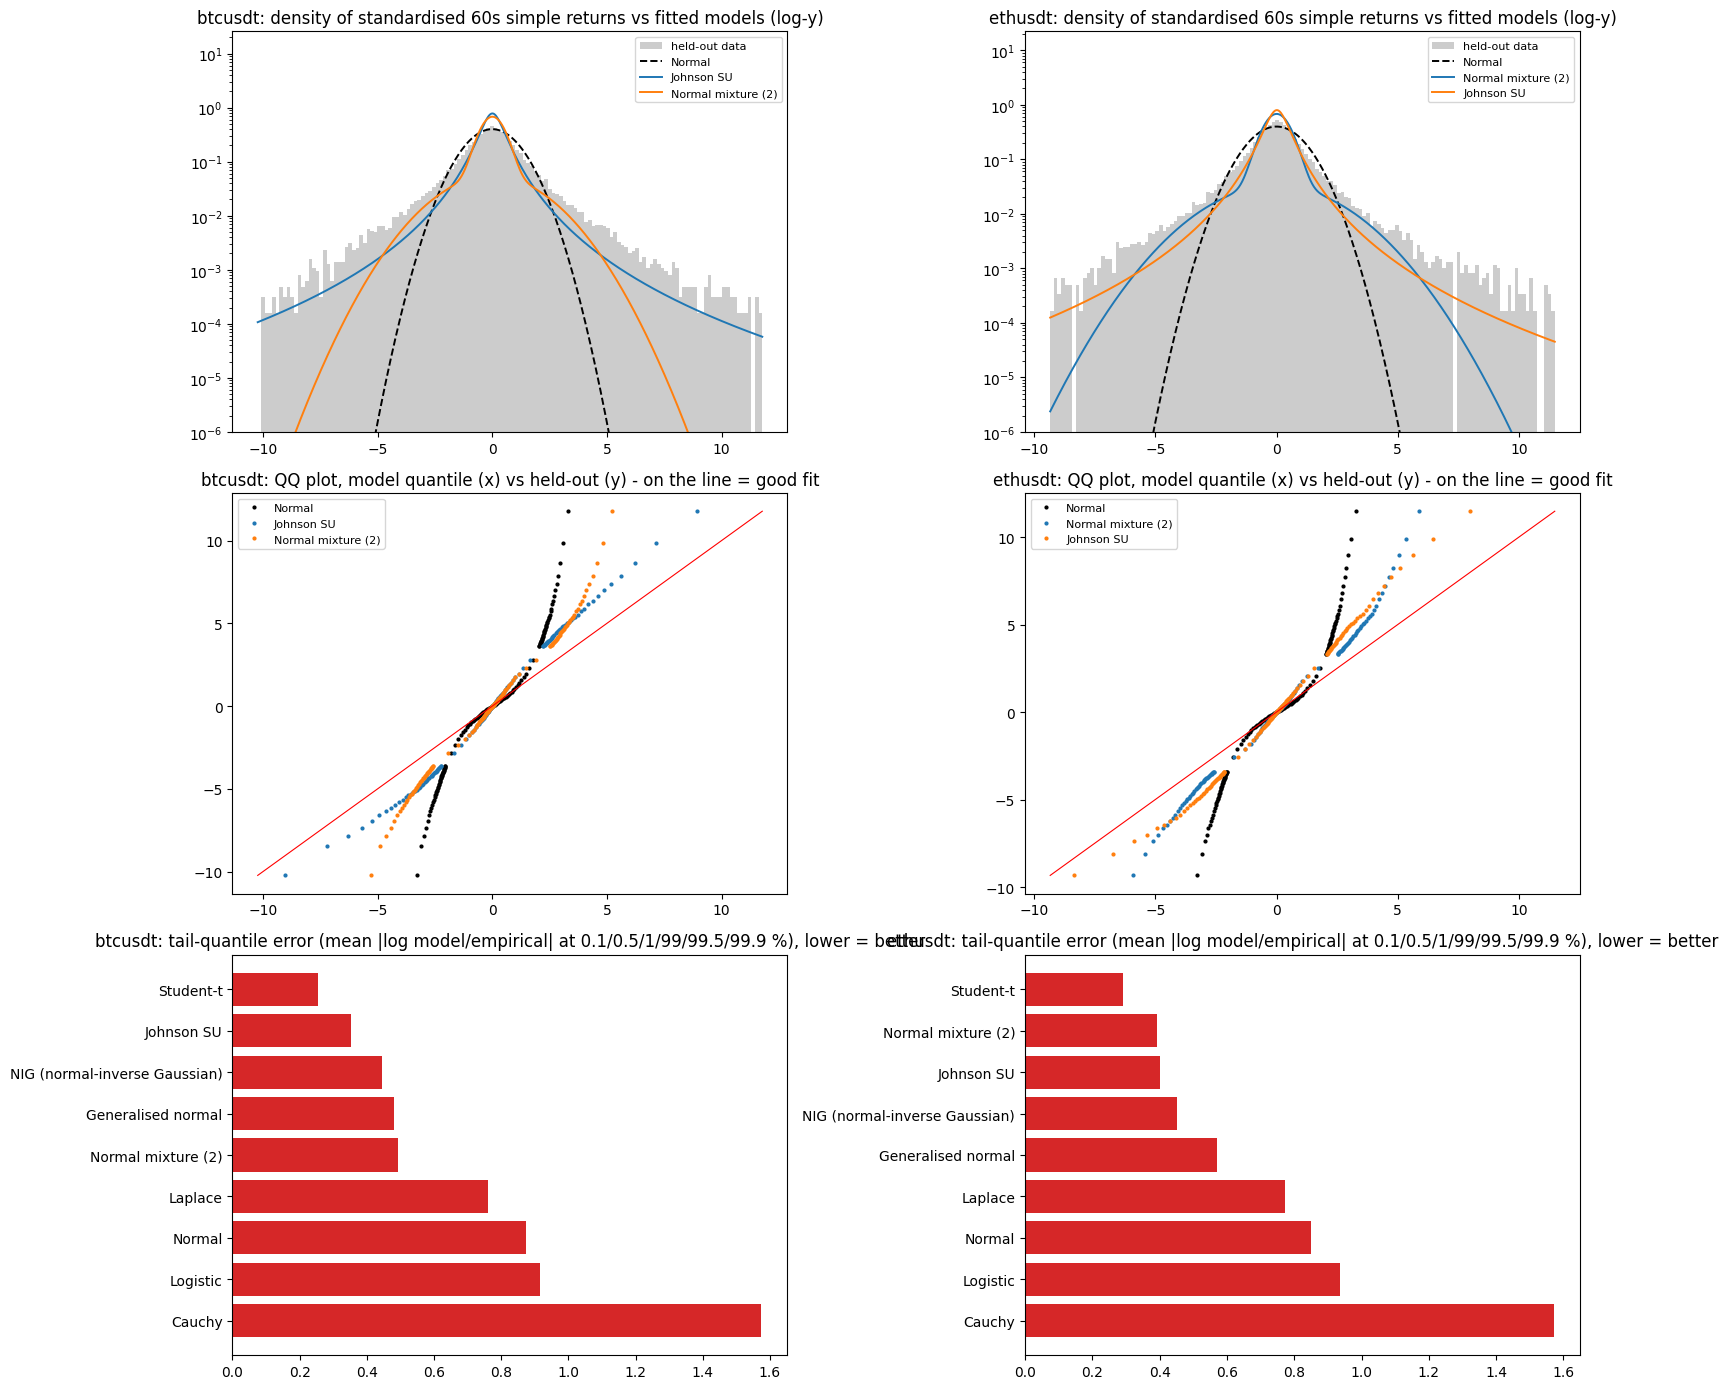

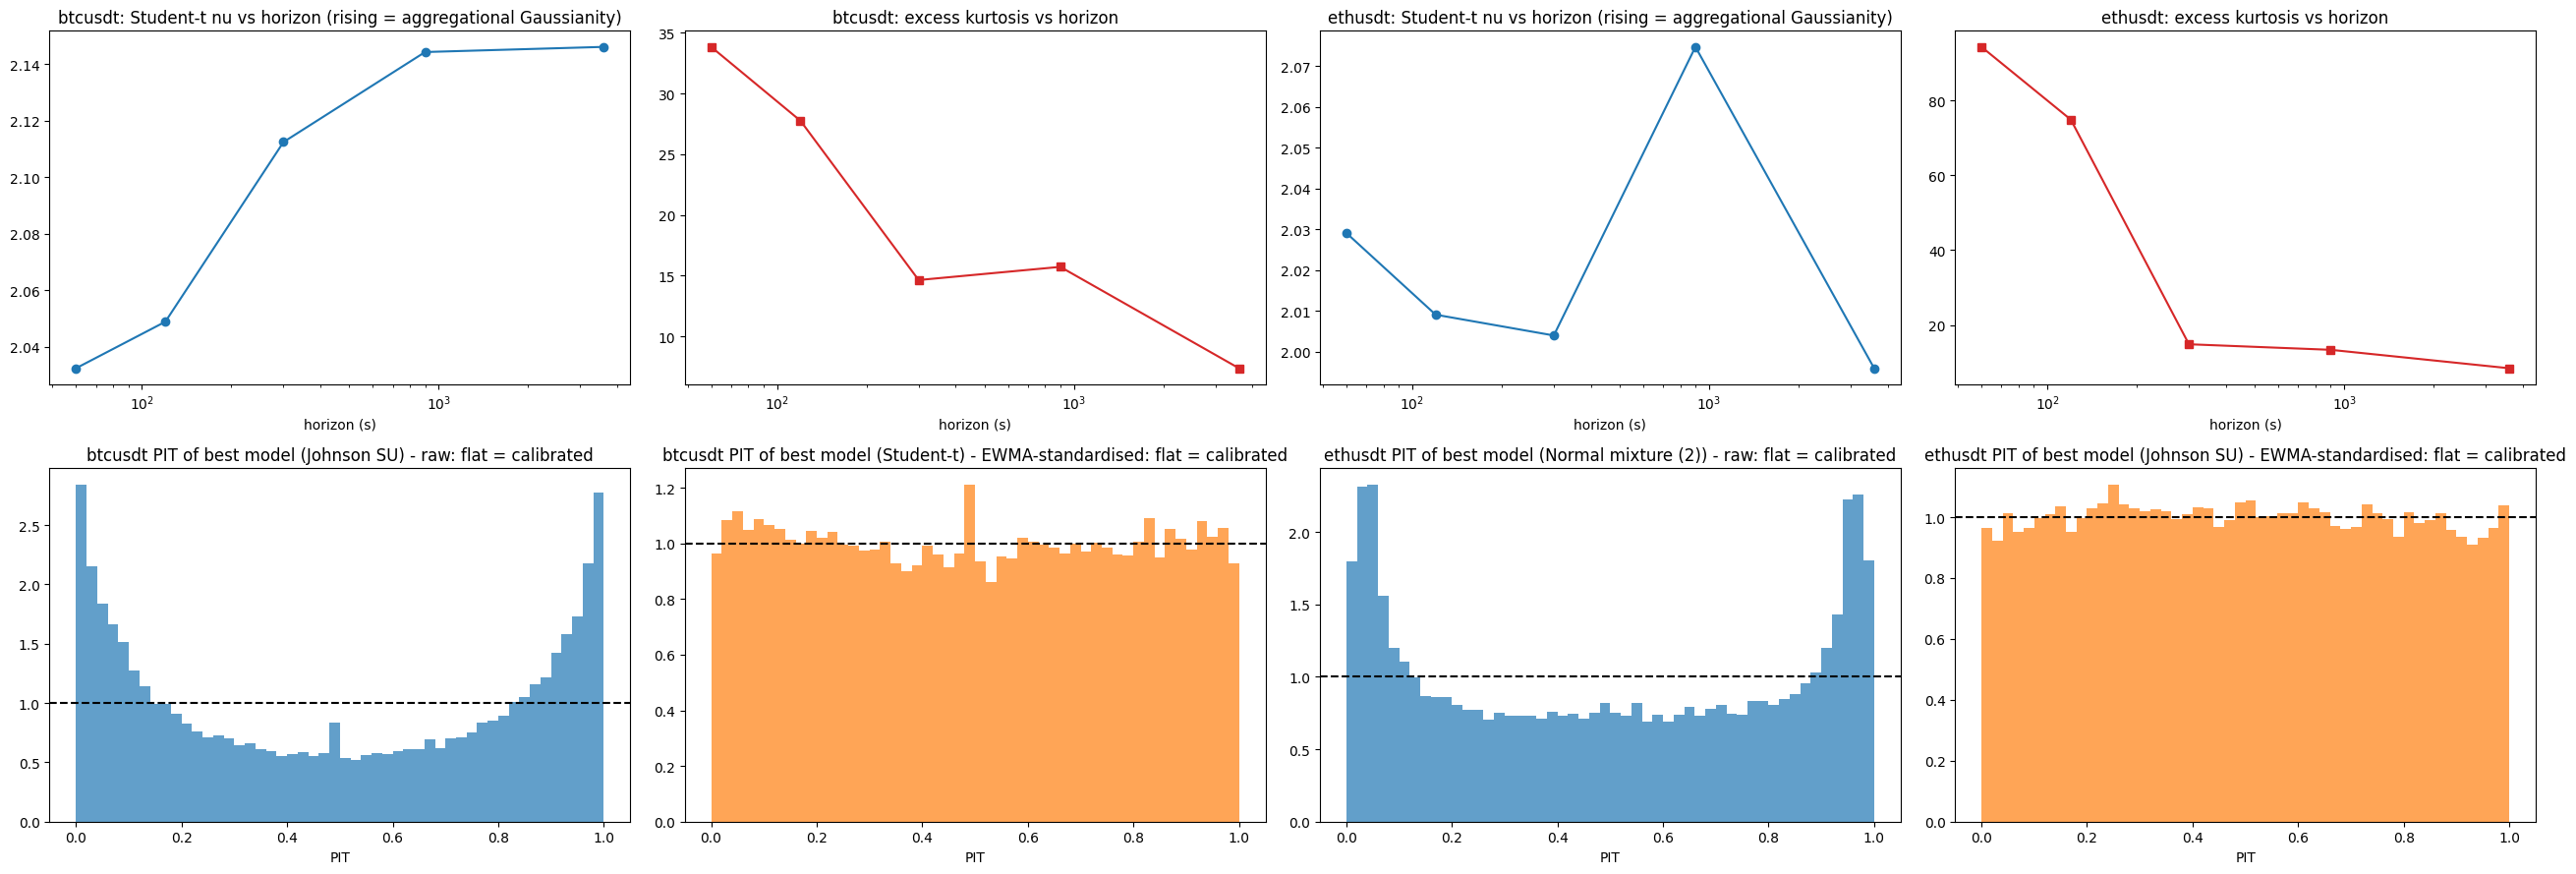

[stage H distribution fitting] 209.5s peak_rss=11.41GB


In [44]:
fig, ax = plt.subplots(3, len(SYMS), figsize=(8 * len(SYMS), 14)); ax = np.atleast_2d(ax).reshape(3, len(SYMS))
for j, s in enumerate(SYMS):
    D = H_STORE[(s, "raw")]; ze = D["ze"]; T = D["T"]; top = T["model"].to_list()[:3]; lo, hi = np.quantile(ze, [.0005, .9995]); gx = np.linspace(lo, hi, 600)
    ax[0, j].hist(ze, bins=np.linspace(lo, hi, 140), density=True, color="0.8", label="held-out data")
    for nm, c in zip(["Normal"] + [m for m in top if m != "Normal"][:3], ["k", "C0", "C1", "C2"]): ax[0, j].plot(gx, np.exp(D["models"][nm].logpdf(gx)), c=c, lw=1.4, ls="--" if nm == "Normal" else "-", label=nm)
    ax[0, j].set_yscale("log"); ax[0, j].set_ylim(1e-6); ax[0, j].set_title(f"{s}: density of standardised {BAR_S}s simple returns vs fitted models (log-y)"); ax[0, j].legend(fontsize=8)
    p = np.concatenate([np.linspace(.0005, .02, 40), np.linspace(.02, .98, 60), np.linspace(.98, .9995, 40)]); eq = np.quantile(ze, p)
    for nm, c in zip(["Normal"] + [m for m in top if m != "Normal"][:3], ["k", "C0", "C1", "C2"]): ax[1, j].plot(D["models"][nm].ppf(p), eq, ".", c=c, ms=4, label=nm)
    a = [eq.min(), eq.max()]; ax[1, j].plot(a, a, "r-", lw=.8); ax[1, j].set_title(f"{s}: QQ plot, model quantile (x) vs held-out (y) - on the line = good fit"); ax[1, j].legend(fontsize=8)
    Tm = T.sort("tail_q_err"); ax[2, j].barh(Tm["model"], Tm["tail_q_err"], color="C3"); ax[2, j].invert_yaxis(); ax[2, j].set_title(f"{s}: tail-quantile error (mean |log model/empirical| at 0.1/0.5/1/99/99.5/99.9 %), lower = better")
fig.tight_layout(); show(fig, "h1_distribution_fit_qq_tails.png")
fig, ax = plt.subplots(2, 2 * len(SYMS) // 1, figsize=(6.5 * 2 * len(SYMS), 9)); ax = np.atleast_2d(ax)
for j, s in enumerate(SYMS):
    t = HRT.filter(pl.col("sym") == s).sort("horizon_s"); a0 = ax[0, 2 * j]; a0.semilogx(t["horizon_s"], t["t_nu"], "o-"); a0.set_title(f"{s}: Student-t nu vs horizon (rising = aggregational Gaussianity)"); a0.set_xlabel("horizon (s)")
    a1 = ax[0, 2 * j + 1]; a1.semilogx(t["horizon_s"], t["ex_kurt"], "s-", c="C3"); a1.set_title(f"{s}: excess kurtosis vs horizon"); a1.set_xlabel("horizon (s)")
    for lab, c, a in (("raw", "C0", ax[1, 2 * j]), ("EWMA-standardised", "C1", ax[1, 2 * j + 1])):
        D = H_STORE[(s, lab)]; nm = D["T"]["model"][0]; u = D["models"][nm].cdf(D["ze"]); a.hist(u, bins=50, density=True, color=c, alpha=.7); a.axhline(1, c="k", ls="--"); a.set_title(f"{s} PIT of best model ({nm}) - {lab}: flat = calibrated"); a.set_xlabel("PIT")
fig.tight_layout(); show(fig, "h2_horizon_scaling_pit_standardised.png")
mark("H distribution fitting")

# F. Turnover constraint (Q4)
Kept clipped turnover must be >= 500,000 USD **per day**. With total clipped turnover `T` over `N` days the smallest admissible kept share is
`500k*N/T`. A single average hides quiet stretches, so the share is also computed for the worst rolling window (1/7/14/28 days) and per split.
Then: the oracle upper bound for Score at that share (from the weighted histograms) and a rule-based filter chosen on train, judged on val.

In [45]:
MINT = CFG["MIN_TURNOVER"]
DT = AGG.group_by("sym", "day").agg(pl.col("w_all").sum().alias("T")).sort("sym", "day")
DTC = DT.group_by("day").agg(pl.col("T").sum()).sort("day").with_columns(pl.lit("both").alias("sym"))
DTA = pl.concat([DT, DTC.select(DT.columns)]).with_columns(pl.col("day").map_elements(split_of_day, return_dtype=pl.String).alias("split"))
rows = []
for sym in sorted(DTA["sym"].unique().to_list()):
    for sp in ("all", "train", "val"):
        d = DTA.filter(pl.col("sym") == sym) if sp == "all" else DTA.filter((pl.col("sym") == sym) & (pl.col("split") == sp))
        if d.height == 0: continue
        T = d["T"].to_numpy(); r = dict(sym=sym, split=sp, n_days=len(T), mean_daily_turnover=T.mean(), min_share_avg=MINT * len(T) / T.sum())
        for L in (1, 7, 14, 28):
            if len(T) >= L: r[f"min_share_worst_{L}d"] = float(MINT * L / np.convolve(T, np.ones(L), "valid").min())
        rows.append(r)
MS = pl.DataFrame(rows); MS.write_csv(WORK / "min_turnover_share.csv")
print("Minimum share of clipped turnover to keep so that kept turnover >= 500k USD/day"); print(MS)
SAFE = 1.2
sel = MS.filter((pl.col("sym") == "both") & (pl.col("split") == "all"))
worst = float(max(v for k, v in sel.row(0, named=True).items() if k.startswith("min_share")))
SHARE_MIN = float(sel["min_share_avg"][0]); SHARE_USE = min(1.0, max(SHARE_MIN, worst) * SAFE)
print(f"\nBinding answer: keep at least {SHARE_MIN:.4%} of turnover on average; worst rolling window needs {worst:.4%}; recommended with x{SAFE} margin: {SHARE_USE:.4%}")

Minimum share of clipped turnover to keep so that kept turnover >= 500k USD/day
shape: (9, 9)
┌─────────┬───────┬────────┬─────────────────────┬───────────────┬────────────────────┬────────────────────┬─────────────────────┬─────────────────────┐
│ sym     ┆ split ┆ n_days ┆ mean_daily_turnover ┆ min_share_avg ┆ min_share_worst_1d ┆ min_share_worst_7d ┆ min_share_worst_14d ┆ min_share_worst_28d │
│ ---     ┆ ---   ┆ ---    ┆ ---                 ┆ ---           ┆ ---                ┆ ---                ┆ ---                 ┆ ---                 │
│ str     ┆ str   ┆ i64    ┆ f64                 ┆ f64           ┆ f64                ┆ f64                ┆ f64                 ┆ f64                 │
╞═════════╪═══════╪════════╪═════════════════════╪═══════════════╪════════════════════╪════════════════════╪═════════════════════╪═════════════════════╡
│ both    ┆ all   ┆ 90     ┆ 2.3651e10           ┆ 0.000021      ┆ 0.000119           ┆ 0.000034           ┆ 0.000032            ┆ 0.000028  

### F0. Turnover guardrail (from the original EDA)
The mathematical minimum share is the break-even point on the public sample; a hidden period with lower turnover would break a filter tuned exactly on it. The original EDA therefore fixed a round **0.01 %** guardrail (about 2x the train minimum). The table shows what that guardrail keeps per day, the buffer over the 500,000 USD requirement, and whether any single day would fall below it.

In [46]:
TARGET_KEEP_SHARE = 1e-4
GR = []
for sym in sorted(DTA["sym"].unique().to_list()):
    for sp in ("train", "val"):
        d = DTA.filter((pl.col("sym") == sym) & (pl.col("split") == sp))
        if d.height == 0: continue
        T = d["T"].to_numpy(); mean = float(T.mean())
        GR.append(dict(sym=sym, split=sp, n_days=len(T), mean_daily_turnover=mean, min_share_avg=MINT / mean, guardrail_share=TARGET_KEEP_SHARE, kept_usd_per_day_at_guardrail=mean * TARGET_KEEP_SHARE,
                       buffer_x=mean * TARGET_KEEP_SHARE / MINT, usd_turnover_per_usd_kept_at_min=mean / MINT, worst_day_kept_usd=float(T.min() * TARGET_KEEP_SHARE), days_below_requirement=int((T * TARGET_KEEP_SHARE < MINT).sum())))
GUARD = pl.DataFrame(GR); GUARD.write_csv(WORK / "eda_turnover_guardrail.csv")
print(f"Guardrail {TARGET_KEEP_SHARE:.2%} of clipped turnover vs the {MINT:,.0f} USD/day requirement:"); print(GUARD)
if GUARD.height: print("Reading: at the minimum share one USD is kept per", f"{GUARD['usd_turnover_per_usd_kept_at_min'].min():,.0f}", "USD of turnover; the constraint is far from binding, so the filter is limited by signal quality, not by volume.")

Guardrail 0.01% of clipped turnover vs the 500,000 USD/day requirement:
shape: (6, 11)
┌─────────┬───────┬────────┬─────────────────────┬───────────────┬─────────────────┬───────────────────────────────┬──────────┬─────────────────────────────────┬────────────────────┬────────────────────────┐
│ sym     ┆ split ┆ n_days ┆ mean_daily_turnover ┆ min_share_avg ┆ guardrail_share ┆ kept_usd_per_day_at_guardrail ┆ buffer_x ┆ usd_turnover_per_usd_kept_at_m… ┆ worst_day_kept_usd ┆ days_below_requirement │
│ ---     ┆ ---   ┆ ---    ┆ ---                 ┆ ---           ┆ ---             ┆ ---                           ┆ ---      ┆ ---                             ┆ ---                ┆ ---                    │
│ str     ┆ str   ┆ i64    ┆ f64                 ┆ f64           ┆ f64             ┆ f64                           ┆ f64      ┆ f64                             ┆ f64                ┆ i64                    │
╞═════════╪═══════╪════════╪═════════════════════╪═══════════════╪═══════════════

In [47]:
# Oracle: keep the best-pnl trades by clipped notional until `share` of valid turnover is kept (cannot be beaten by any filter).
def oracle(sym, tau, share, splits):
    h = hist_merge(sym, tau, splits); mid = 0.5 * (HIST_EDGES[:-1] + HIST_EDGES[1:]); W = h["w"]; tot = W.sum(); allm = h["wp"].sum() / tot
    o = np.argsort(-mid); cw = np.cumsum(W[o]); k = np.searchsorted(cw, share * tot) + 1; take = np.zeros(len(W)); take[o[:k - 1]] = W[o[:k - 1]]; take[o[k - 1]] = share * tot - (cw[k - 2] if k > 1 else 0)
    kept = float((take * mid).sum() / take.sum()); return kept, allm
rows = []
for sym in SYMS:
    for tau in TAUS:
        for sp, spl in (("train", ("train",)), ("val", ("val",))):
            if (tau, sp) not in MO[sym]["hist"]: continue
            kept, allm = oracle(sym, tau, SHARE_USE, spl); rows.append(dict(sym=sym, tau=tau, split=sp, share=SHARE_USE, wmean_all_bps=allm, oracle_wmean_kept_bps=kept, oracle_score_bps=kept - allm))
ORA = pl.DataFrame(rows); ORA.write_csv(WORK / "oracle_score.csv"); print("Oracle (look-ahead) upper bound on Score = PnL_kept - PnL_all, bps per $ of clipped notional"); print(ORA)

Oracle (look-ahead) upper bound on Score = PnL_kept - PnL_all, bps per $ of clipped notional
shape: (12, 7)
┌─────────┬─────┬───────┬──────────┬───────────────┬───────────────────────┬──────────────────┐
│ sym     ┆ tau ┆ split ┆ share    ┆ wmean_all_bps ┆ oracle_wmean_kept_bps ┆ oracle_score_bps │
│ ---     ┆ --- ┆ ---   ┆ ---      ┆ ---           ┆ ---                   ┆ ---              │
│ str     ┆ i64 ┆ str   ┆ f64      ┆ f64           ┆ f64                   ┆ f64              │
╞═════════╪═════╪═══════╪══════════╪═══════════════╪═══════════════════════╪══════════════════╡
│ btcusdt ┆ 30  ┆ train ┆ 0.000143 ┆ -0.104926     ┆ 160.905576            ┆ 161.010501       │
│ btcusdt ┆ 30  ┆ val   ┆ 0.000143 ┆ -0.187706     ┆ 102.414286            ┆ 102.601992       │
│ btcusdt ┆ 120 ┆ train ┆ 0.000143 ┆ 0.00393       ┆ 275.651387            ┆ 275.647457       │
│ btcusdt ┆ 120 ┆ val   ┆ 0.000143 ┆ -0.174254     ┆ 162.750081            ┆ 162.924334       │
│ btcusdt ┆ 300 ┆ train ┆ 0.

In [48]:
# Rule-based filter: rank cells (hour, side, st10, st60) on TRAIN by weighted pnl, keep best cells until the share is reached, evaluate on VAL.
CELL = ["hour", "s", "st10", "st60"]
def cells(A, tau): return A.group_by(CELL).agg(pl.col(f"w_{tau}").sum().alias("w"), pl.col(f"wp_{tau}").sum().alias("wp")).filter(pl.col("w") > 0).with_columns((pl.col("wp") / pl.col("w")).alias("m"))
rows = []
for sym in SYMS + ["both"]:
    A = AGG if sym == "both" else AGG.filter(pl.col("sym") == sym)
    for tau in TAUS:
        tr = cells(A.filter(pl.col("split") == "train"), tau).sort("m", descending=True); va = cells(A.filter(pl.col("split") == "val"), tau)
        if tr.is_empty() or va.is_empty(): continue
        tr = tr.with_columns((pl.col("w").cum_sum() / pl.col("w").sum()).alias("cum")); keep = tr.filter(pl.col("cum").shift(1).fill_null(0) < SHARE_USE).select(CELL)
        v = va.join(keep, on=CELL, how="inner"); vall = va["wp"].sum() / va["w"].sum()
        if v.is_empty(): continue
        rows.append(dict(sym=sym, tau=tau, rule="best train cells", n_cells=keep.height, val_share_kept=float(v["w"].sum() / va["w"].sum()), val_wmean_all=float(vall), val_wmean_kept=float(v["wp"].sum() / v["w"].sum()), val_score_bps=float(v["wp"].sum() / v["w"].sum() - vall)))
        # simple interpretable rule: drop trades taking liquidity WITH an ongoing liquidation burst (st60 == 1 or st10 == 1)
        for nm, expr in (("drop with-liq state", ~((pl.col("st10") == 1) | (pl.col("st60") == 1))),):
            k = va.filter(expr)
            if k.height: rows.append(dict(sym=sym, tau=tau, rule=nm, n_cells=k.height, val_share_kept=float(k["w"].sum() / va["w"].sum()), val_wmean_all=float(vall), val_wmean_kept=float(k["wp"].sum() / k["w"].sum()), val_score_bps=float(k["wp"].sum() / k["w"].sum() - vall)))
if rows:
    RULES = pl.DataFrame(rows).with_columns((pl.col("val_share_kept") >= SHARE_MIN).alias("meets_min_share")); RULES.write_csv(WORK / "rule_filters_val.csv")
    print("Rule filters chosen on train, evaluated on val (kept share must be >= required share)"); print(RULES.sort("sym", "tau", "rule"))
else: print("No validation days present in this data: rule filters not evaluated.")
print("\nCaveat: train-chosen hour x side x state cells are noisy; trust only the score that holds on val and is positive across horizons and symbols.")

Rule filters chosen on train, evaluated on val (kept share must be >= required share)
shape: (18, 9)
┌─────────┬─────┬─────────────────────┬─────────┬────────────────┬───────────────┬────────────────┬───────────────┬─────────────────┐
│ sym     ┆ tau ┆ rule                ┆ n_cells ┆ val_share_kept ┆ val_wmean_all ┆ val_wmean_kept ┆ val_score_bps ┆ meets_min_share │
│ ---     ┆ --- ┆ ---                 ┆ ---     ┆ ---            ┆ ---           ┆ ---            ┆ ---           ┆ ---             │
│ str     ┆ i64 ┆ str                 ┆ i64     ┆ f64            ┆ f64           ┆ f64            ┆ f64           ┆ bool            │
╞═════════╪═════╪═════════════════════╪═════════╪════════════════╪═══════════════╪════════════════╪═══════════════╪═════════════════╡
│ both    ┆ 30  ┆ best train cells    ┆ 4       ┆ 0.000116       ┆ -0.046409     ┆ -15.023385     ┆ -14.976976    ┆ true            │
│ both    ┆ 30  ┆ drop with-liq state ┆ 192     ┆ 0.928725       ┆ -0.046409     ┆ -0.268092   

## F2. Pressure-tier selection rules (improved filter search)
**What the earlier rule search got wrong.** The task keeps a *small* part of the flow (the constraint needs only ~0.01 %) and scores the PnL of what is kept, so the job is to **pick the trades with the best expected markout**, not to remove the worst few. The full-data markout-by-state table shows the profitable group is the trades that go **with** an ongoing liquidation burst (the maker is paid for fading the push, and cascades reverse), while the trades **against** it are the loss-making ones. The rule "drop with-liq state" therefore removes the good trades.

**What is tested here** (all causal: liquidation events strictly before the trade; thresholds from train days only). The pressure tier is how many times the train 95th-percentile pressure threshold the 10 s / 60 s net liquidation flow reaches (1-2x, 2-5x, >= 5x). Rules: keep *with* (60 s, 10 s, either window), keep *with* at tier >= 2 or tier 3, and drop *against*. Each rule is scored as `wmean_kept - wmean_all` (bps) per split, with a day-by-day mean, t-statistic and share of positive days, and a check that the kept turnover reaches the minimum on **every** day. "Selected on train" picks, per symbol and horizon, the rule with the best train score among those with day-level t > 2 and enough turnover, and reports only its validation result. A rule counts as supported only if the validation score is positive, its day-level t is above 2 and no day falls below the turnover requirement.

In [49]:
def _rules_sel():
    st10, st60, l10, l60 = pl.col("st10"), pl.col("st60"), pl.col("lv10"), pl.col("lv60")
    lvw = pl.max_horizontal(pl.when(st10 == 1).then(l10).otherwise(0).cast(pl.Int32), pl.when(st60 == 1).then(l60).otherwise(0).cast(pl.Int32))   # strongest 'with' tier in either window
    return {"keep with (60 s window)": st60 == 1, "keep with (10 s window)": st10 == 1, "keep with (either window)": (st10 == 1) | (st60 == 1),
            "keep with, tier >= 2 (>= 2x threshold)": lvw >= 2, "keep with, tier 3 (>= 5x threshold)": lvw >= 3, "drop against (either window)": ~((st10 == 2) | (st60 == 2))}
RULES_SEL = _rules_sel()
def eval_rule(A, tau, expr):
    w, wp = pl.col(f"w_{tau}"), pl.col(f"wp_{tau}")
    tot = A.select(w.sum().alias("w"), wp.sum().alias("wp")).row(0, named=True)
    if not tot["w"]: return None
    n_days = A["day"].n_unique(); k = A.filter(expr)
    kd = k.group_by("day").agg(w.sum().alias("w"), wp.sum().alias("wp"), pl.col("w_all").sum().alias("w_all")).sort("day")
    kw, kp = float(kd["w"].sum()) if kd.height else 0.0, float(kd["wp"].sum()) if kd.height else 0.0
    x = (kd.filter(pl.col("w") > 0).select(pl.col("wp") / pl.col("w")).to_series().to_numpy()) if kd.height else np.array([])
    allm = tot["wp"] / tot["w"]
    return dict(days=n_days, share_kept=kw / tot["w"], wmean_all_bps=allm, wmean_kept_bps=(kp / kw if kw else np.nan), score_bps=(kp / kw - allm if kw else np.nan), kept_pnl_usd=kp / 1e4,
                kept_turnover_per_day=float(kd["w_all"].sum() / n_days) if kd.height else 0.0, days_below_min=int(n_days - (kd["w_all"] >= MINT).sum()) if kd.height else n_days,
                daily_mean_bps=float(x.mean()) if len(x) else np.nan, daily_t=float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan, share_days_pos=float((x > 0).mean()) if len(x) else np.nan)
SEL_ROWS = []
for sym in SYMS + ["both"]:
    A0 = AGG if sym == "both" else AGG.filter(pl.col("sym") == sym)
    for tau in TAUS:
        for sp in ("train", "val"):
            A = A0.filter(pl.col("split") == sp)
            if A.is_empty(): continue
            for nm, expr in RULES_SEL.items():
                r = eval_rule(A, tau, expr)
                if r: SEL_ROWS.append(dict(sym=sym, tau=tau, split=sp, rule=nm, **r))
if SEL_ROWS:
    SELT = pl.DataFrame(SEL_ROWS); SELT.write_csv(WORK / "rule_selection_val.csv")
    show_cols = ["sym", "tau", "rule", "share_kept", "wmean_all_bps", "wmean_kept_bps", "score_bps", "daily_t", "share_days_pos", "days_below_min"]
    print("Pressure-tier rules, VALIDATION days (score = kept minus all, bps; days_below_min = days with kept turnover < the requirement):")
    print(SELT.filter(pl.col("split") == "val").select(show_cols).sort("sym", "tau", "score_bps", descending=[False, False, True]))
    # selection on train, report validation only
    SEL_PICK = []
    for sym in SYMS + ["both"]:
        for tau in TAUS:
            tr = SELT.filter((pl.col("sym") == sym) & (pl.col("tau") == tau) & (pl.col("split") == "train") & (pl.col("share_kept") >= SHARE_MIN) & (pl.col("daily_t") > 2)).sort("score_bps", descending=True)
            if tr.is_empty(): SEL_PICK.append(dict(sym=sym, tau=tau, rule="(no rule passes on train)")); continue
            b = tr.row(0, named=True); v = SELT.filter((pl.col("sym") == sym) & (pl.col("tau") == tau) & (pl.col("split") == "val") & (pl.col("rule") == b["rule"]))
            r = dict(sym=sym, tau=tau, rule=b["rule"], train_score_bps=b["score_bps"], train_t=b["daily_t"])
            if v.height: vv = v.row(0, named=True); r.update(val_share_kept=vv["share_kept"], val_score_bps=vv["score_bps"], val_t=vv["daily_t"], val_share_days_pos=vv["share_days_pos"], val_days_below_min=vv["days_below_min"], val_kept_pnl_usd=vv["kept_pnl_usd"],
                                                                 supported=bool(vv["score_bps"] > 0 and (vv["daily_t"] or 0) > 2 and vv["days_below_min"] == 0))
            SEL_PICK.append(r)
    SELP = pl.DataFrame(SEL_PICK, infer_schema_length=None); SELP.write_csv(WORK / "rule_selection_picked.csv")
    print("\nSelected on train (day-level t > 2, share >= minimum), reported on validation:"); print(SELP)
    print("\nReading: a rule is supported only if the validation score is positive, its day-level t > 2 and no day falls below the turnover requirement. Rules that are strong on train but weak here are noise.")
else: print("No train/validation data: pressure-tier rules not evaluated.")
mark("F2 pressure-tier rules")

Pressure-tier rules, VALIDATION days (score = kept minus all, bps; days_below_min = days with kept turnover < the requirement):
shape: (54, 10)
┌─────────┬─────┬─────────────────────────────────┬────────────┬───────────────┬────────────────┬───────────┬───────────┬────────────────┬────────────────┐
│ sym     ┆ tau ┆ rule                            ┆ share_kept ┆ wmean_all_bps ┆ wmean_kept_bps ┆ score_bps ┆ daily_t   ┆ share_days_pos ┆ days_below_min │
│ ---     ┆ --- ┆ ---                             ┆ ---        ┆ ---           ┆ ---            ┆ ---       ┆ ---       ┆ ---            ┆ ---            │
│ str     ┆ i64 ┆ str                             ┆ f64        ┆ f64           ┆ f64            ┆ f64       ┆ f64       ┆ f64            ┆ i64            │
╞═════════╪═════╪═════════════════════════════════╪════════════╪═══════════════╪════════════════╪═══════════╪═══════════╪════════════════╪════════════════╡
│ both    ┆ 30  ┆ keep with, tier 3 (>= 5x thres… ┆ 0.020776   ┆ -0.046409  

## R. Reconciliation with the original EDA notebook
Headline numbers reported in `EDA.ipynb` next to the same quantity recomputed in this run. Differences have known causes: the EDA used pandas on the full-resolution files with `amount * price` as the cascade notional and a quote-age rule on the *exact* quote time, while this pipeline uses a 1-second grid for the price-sanity and gap checks (so those rows are approximate and marked `~`).

In [50]:
REC = []
def rec(item, eda, ours, tol=0.02, note=""):
    ok = None
    try:
        if ours is not None and np.isfinite(float(ours)): ok = bool(abs(float(ours) - float(eda)) <= max(tol * abs(float(eda)), 1e-12 if tol else 0))
    except Exception: ok = None
    REC.append(dict(item=item, eda_notebook=eda, this_run=None if ours is None else float(ours), agrees=ok, note=note))
def safe(fn):
    try: return fn()
    except Exception: return None
if RAWPROF is not None:
    for s, e_n, e_ms in (("btcusdt", 63, 22), ("ethusdt", 46, 16)):
        r = RAWPROF.filter(pl.col("file") == f"liq_by_{s}")
        rec(f"Bybit {s[:3].upper()} backward timestamp steps", e_n, safe(lambda: r["out_of_order"][0]), 0.0); rec(f"Bybit {s[:3].upper()} largest backward step (ms)", e_ms, safe(lambda: r["max_backstep_ms"][0]), 0.05)
    for col in ("empty_bbo", "crossed_bbo", "locked_bbo"): rec(f"BBO {col} (both symbols)", 0, safe(lambda: int(RAWPROF[col].sum())), 0.0)
for s, e_o, e_c, e_k, e_l in (("btcusdt", 342_910, 109_798, 4_498, 46.4e6), ("ethusdt", 291_983, 126_626, 3_206, 23.3e6)):
    o = EDA_OV.filter(pl.col("sym") == s)
    rec(f"{s[:3].upper()} observed liquidation events (+200 ms Bybit shift)", e_o, safe(lambda: o["observed_events"][0]), 0.0)
    rec(f"{s[:3].upper()} same-side 1 s clusters", e_c, safe(lambda: o["same_side_clusters"][0]), 0.0)
    rec(f"{s[:3].upper()} candidate cascades (>= 3 events, >= 100k USD)", e_k, safe(lambda: o["candidate_cascades"][0]), 0.0)
    rec(f"{s[:3].upper()} largest cascade notional (USD)", e_l, safe(lambda: o["largest_cascade_usd"][0]), 0.02)
for s, e_n in (("btcusdt", 2), ("ethusdt", 11)):
    rec(f"~{s[:3].upper()} Binance liquidation prices > 10 % from a fresh mid", e_n, safe(lambda: PRICE_SANITY.filter((pl.col("sym") == s) & (pl.col("exchange") == "binance"))["flagged_gt_10pct"][0]), 0.0, "grid-resolution quote; small differences expected")
for s, vals in (("btcusdt", (-0.1358, -0.062, -0.037)), ("ethusdt", (0.018, 0.116, 0.199))):
    for tau, v in zip(TAUS, vals): rec(f"{s[:3].upper()} weighted maker PnL tau={tau}s (bps)", v, safe(lambda: OVS.filter((pl.col("sym") == s) & (pl.col("tau") == tau))["wmean_bps"][0]), 0.02, "task definition, forward-filled raw mid")
for s, e_tot in (("btcusdt", (-14.95e6, -6.88e6, -4.03e6)), ("ethusdt", (1.90e6, 11.96e6, 20.48e6))):
    for tau, v in zip(TAUS, e_tot): rec(f"{s[:3].upper()} total weighted PnL tau={tau}s (USD)", v, safe(lambda: OVS.filter((pl.col("sym") == s) & (pl.col("tau") == tau))["total_pnl_usd"][0]), 0.02)
for s, e_sh, e_t in (("btcusdt", 0.0000449, 11.15e9), ("ethusdt", 0.0000458, 10.91e9)):
    g_ = GUARD.filter((pl.col("sym") == s) & (pl.col("split") == "train"))
    rec(f"{s[:3].upper()} minimum keep share, train", e_sh, safe(lambda: g_["min_share_avg"][0]), 0.02); rec(f"{s[:3].upper()} mean clipped turnover per day, train (USD)", e_t, safe(lambda: g_["mean_daily_turnover"][0]), 0.02)
for s, st, e_g in (("btcusdt", "bbo", 199), ("ethusdt", "bbo", 354), ("btcusdt", "trd", 46.6)):
    rec(f"~longest {st} silence {s[:3].upper()} (s)", e_g, safe(lambda: GAPS.filter((pl.col("sym") == s) & (pl.col("stream") == st))["dur_s"].max()), 0.05, "1-second grid; EDA used exact timestamps")
RECON = pl.DataFrame(REC, schema_overrides=dict(eda_notebook=pl.Float64, this_run=pl.Float64)); RECON.write_csv(WORK / "eda_reconciliation.csv")
print(RECON); n_ok = int(RECON["agrees"].sum()); n_tot = int(RECON["agrees"].is_not_null().sum())
print(f"\n{n_ok} of {n_tot} comparable headline numbers agree within tolerance; rows marked False are listed above and explained in the note column or by the definition differences stated in the heading.")

shape: (36, 5)
┌─────────────────────────────────┬──────────────┬───────────┬────────┬─────────────────────────────────┐
│ item                            ┆ eda_notebook ┆ this_run  ┆ agrees ┆ note                            │
│ ---                             ┆ ---          ┆ ---       ┆ ---    ┆ ---                             │
│ str                             ┆ f64          ┆ f64       ┆ bool   ┆ str                             │
╞═════════════════════════════════╪══════════════╪═══════════╪════════╪═════════════════════════════════╡
│ Bybit BTC backward timestamp s… ┆ 63.0         ┆ 63.0      ┆ true   ┆                                 │
│ Bybit BTC largest backward ste… ┆ 22.0         ┆ 22.0      ┆ true   ┆                                 │
│ Bybit ETH backward timestamp s… ┆ 46.0         ┆ 46.0      ┆ true   ┆                                 │
│ Bybit ETH largest backward ste… ┆ 16.0         ┆ 16.0      ┆ true   ┆                                 │
│ BBO empty_bbo (both symbols) 

# Z. Report with interpretation (report.md) and runtime profile
Every statement below is generated from the CSVs of **this** run, so the numbers always match the tables and figures. Output: `report.md` (+ `runtime_profile.csv`); stage P then builds the PowerPoint from the same material.

In [51]:
mark("F turnover")
RTP = pl.DataFrame(STAGE_LOG); RTP.write_csv(WORK / "runtime_profile.csv"); print(RTP, f"\nTotal {sum(r['seconds'] for r in STAGE_LOG) / 60:.1f} min, profile={PROFILE_NAME}")
def rd(n):
    f = WORK / n; return pl.read_csv(f) if f.exists() else None
def g(x, f=".3g"): return "n/a" if x is None or (isinstance(x, float) and not np.isfinite(x)) else format(x, f)
NARR, K = {}, {}
def section(name):
    def deco(fn):
        try: NARR[name] = [x for x in fn() if x]
        except Exception as e: NARR[name] = [f"(interpretation for this section is unavailable: {type(e).__name__}: {e})"]
        return fn
    return deco
def said(*keys): return [m for m in INTERP if any(k in m for k in keys)]

@section("data")
def _():
    n_rows = int(INV["rows"].sum()); t0, t1 = date_of_day(int(INV["ts_min"].min() // DAY_US)), date_of_day(int(INV["ts_max"].max() // DAY_US)); K["days"] = NDAYS_RANGE; K["rows"] = n_rows
    return [f"{INV.height} parquet files, {n_rows:,} rows in total, covering {t0} to {t1} ({NDAYS_RANGE} UTC days). Timestamps are int64 microseconds (checked: all within 2014-2036 as microseconds).",
            f"Memory design: DuckDB streams each file once into per-day shards; afterwards one UTC day is in RAM at a time and only 1-second grids and small aggregates persist. Profile `{PROFILE_NAME}` "
            f"(DuckDB {CFG['DUCK_MEM']}, {CFG['THREADS']} threads, trade chunk {CFG['TRADE_CHUNK']:,}). Total run time {sum(r['seconds'] for r in STAGE_LOG) / 60:.1f} min, peak RSS {max(r['peak_rss_gb'] for r in STAGE_LOG):.1f} GB.",
            "Definitions: simple return R = P_t/P_{t-h} - 1 (bps) on the clean 1-second mid grid; maker PnL (bps) = -s*(m(t+tau)-p)/p*1e4 + 0.5 with m the forward-filled BBO mid; weights w = min(notional, 100,000 USD); Bybit liquidations shifted +200 ms; `side` = taker side for trades, side of the forced order for liquidations."]

@section("q1")
def _():
    out = []; v = rd("verdict_market_vs_data.csv"); gp = rd("gaps_classified.csv"); an = rd("anomaly_vs_volatility.csv")
    if v is not None:
        di = v.filter(pl.col("verdict").str.contains("DATA ISSUE") & (pl.col("count") > 0)).sort("count", descending=True); mf = v.filter(pl.col("verdict").str.contains("MARKET") & (pl.col("count") > 0)); K["n_data_issue_items"] = di.height
        if di.height: out.append(f"{di.height} audit checks show a non-zero count classified as DATA ISSUE; the largest are " + "; ".join(f"{r['sym']} {r['item']} = {r['count']:,} ({r['share']:.2e} of rows)" for r in di.head(5).iter_rows(named=True)) + f". Worst relative frequency is {di['share'].max():.2e}, i.e. these defects are rare and are removed from the clean mid (the markout uses the specification's raw mid).")
        if mf.height: out.append("Classified as market features (they follow volatility or liquidity): " + "; ".join(f"{r['sym']} {r['item']} = {r['count']:,}" for r in mf.head(5).iter_rows(named=True)) + ".")
    if gp is not None and gp.height:
        c = gp.group_by("verdict").agg(pl.len().alias("n"), pl.col("dur_s").max().alias("longest_s")).sort("n", descending=True); K["n_gaps"] = gp.height
        out.append(f"{gp.height} time gaps longer than {CFG['GAP_S']} s were found: " + "; ".join(f"{r['n']} x '{r['verdict']}' (longest {r['longest_s']:.0f} s)" for r in c.iter_rows(named=True)) + ". A gap is called a market feature only if the Poisson probability of such silence at that hour-of-week rate is plausible (ln p > -20.7) and other streams/symbols keep trading; silence of every stream and both symbols, or quotes silent while trades flow, is a collector/feed issue.")
        big = gp.sort("dur_s", descending=True).row(0, named=True); out.append(f"Largest gap: {big['sym']} {big['stream']} starting {big['start']} for {big['dur_s']:.0f} s, ln p = {big['ln_p_quiet']:.0f}, {big['n_trades_inside']} trades and {big['n_quotes_inside']} quotes inside -> {big['verdict']}.")
    if an is not None:
        for r in an.filter(pl.col("lift").is_not_null() & pl.col("lift").is_not_nan()).iter_rows(named=True): out.append(f"{r['sym']} {r['anomaly']}: rate in the 5 % most volatile minutes is {r['lift']:.2f}x the calm rate (Spearman with |return| {g(r['spearman_rate_vs_absret'], '.2f')}) -> {r['reading']}.")
    out.append("Rule of thumb used: an anomaly whose rate does not rise with volatility (lift ~ 1, rho ~ 0) cannot be a market reaction and is a data-quality defect; one with lift >> 1 is a market feature (stress, jumps) and must be kept.")
    return out

@section("returns")
def _():
    out = []; r = rd("return_stats.csv"); vr = rd("g5_variance_ratio.csv"); st = rd("g1_stationarity_adf_kpss.csv"); dp = rd("g4_dependence_by_horizon.csv")
    for s in SYMS:
        a = r.filter((pl.col("sym") == s) & (pl.col("h_s") == 1)).row(0, named=True); b = r.filter((pl.col("sym") == s) & (pl.col("h_s") == 60)).row(0, named=True)
        out.append(f"{s}: 1 s simple returns have std {a['std_bps']:.2f} bps (annualised vol {a['vol_ann_pct']:.0f} %), excess kurtosis {a['ex_kurt']:.0f}, lag-1 autocorrelation {a['acf1']:+.3f}; at 60 s std {b['std_bps']:.2f} bps, excess kurtosis {b['ex_kurt']:.1f}, lag-1 ACF {b['acf1']:+.3f}, ACF of |r| {b['acf1_abs']:.2f}, Ljung-Box p on r^2 = {b['ljung_box10_r2_p']:.2g}.")
        out.append(f"{s}: Jarque-Bera p = {a['jb_p']:.2g} -> normality rejected; Hill index (top 1 %) {a['hill_alpha_1pct']:.2f} -> " + ("moments above order 4 do not exist (very heavy tail)." if a['hill_alpha_1pct'] < 4 else "finite fourth moment."))
        if st is not None:
            p = st.filter((pl.col("sym") == s) & (pl.col("series") == "price level")).row(0, named=True); q = st.filter((pl.col("sym") == s) & (pl.col("series") == "simple return")).row(0, named=True)
            out.append(f"{s}: price level ADF p = {p['adf_p']:.3g}, KPSS p = {p['kpss_p']:.3g} -> {p['verdict']}; simple returns ADF p = {q['adf_p']:.3g}, KPSS p = {q['kpss_p']:.3g} -> {q['verdict']}. Prices are modelled through returns; mean reversion in a price level needs a cointegrated spread.")
        if vr is not None: out.append(f"{s}: variance ratios VR(30/120/300 s) = " + ", ".join(f"{x['VR']:.2f} (z={x['z_robust']:+.1f})" for x in vr.filter(pl.col("sym") == s).sort("tau").iter_rows(named=True)) + " (VR>1 persistence/momentum, VR<1 mean reversion, |z|>2 significant).")
    if dp is not None and dp.height > 1: out.append("Cross-asset correlation by horizon: " + ", ".join(f"{x['horizon_s']}s = {x['pearson']:.2f}" for x in dp.iter_rows(named=True)) + "; a rise with horizon is the Epps effect (asynchronous quotes and noise hide dependence at short horizons).")
    return out

@section("ar")
def _():
    return said(" AR:", "AR trade check", "residuals:", "after seasonality", "GARCH-t:", "variance loss", "next-bar variance", "Granger")

@section("dist")
def _():
    out = []; h = rd("h_distribution_fit.csv"); hz = rd("h_horizon_scaling.csv")
    for s in SYMS:
        t = h.filter((pl.col("sym") == s) & (pl.col("sample") == "raw")).sort("mean_rank"); ts = h.filter((pl.col("sym") == s) & (pl.col("sample") == "EWMA-standardised")).sort("mean_rank"); w = t.row(0, named=True); K[f"best_dist_{s}"] = w["model"]
        out.append(f"{s}: ranking by mean of (held-out log-likelihood, KS, Anderson-Darling, tail-quantile error) puts {', '.join(t['model'].head(3).to_list())} first. Winner {w['model']}: held-out log-lik {w['ll_heldout']:.3f}, KS D {w['KS_D']:.4f}, tail-quantile error {w['tail_q_err']:.3f}, parameters {w['params']}.")
        nm = t.filter(pl.col("model") == "Normal").row(0, named=True); tt = t.filter(pl.col("model") == "Student-t").row(0, named=True)
        out.append(f"{s}: Normal has held-out log-lik {nm['ll_heldout']:.3f} vs {tt['ll_heldout']:.3f} for Student-t, KS D {nm['KS_D']:.3f} vs {tt['KS_D']:.3f} and fails the 0.1 % Kupiec test (p = {nm['kupiec_p_0p1pct']:.2g}); Student-t p = {tt['kupiec_p_0p1pct']:.2g}.")
        nu = float(tt["params"].strip("[]").split(",")[0]); nus = float(ts.filter(pl.col("model") == "Student-t")["params"][0].strip("[]").split(",")[0]); K[f"nu_{s}"] = (nu, nus)
        out.append(f"{s}: Student-t degrees of freedom {nu:.1f} (raw) -> {nus:.1f} after dividing by causal EWMA volatility; best model after standardisation: {ts['model'][0]}. " + ("Most of the heavy tail is time-varying volatility; use a conditional-scale model with t/NIG innovations." if nus > 1.5 * nu else "Heavy tails persist after removing volatility clustering: jump/liquidation shocks add a genuine tail."))
    out += said("99.9 % quantile on held-out")
    if hz is not None:
        for s in SYMS:
            t = hz.filter(pl.col("sym") == s).sort("horizon_s")
            if t.height > 1: out.append(f"{s}: Student-t nu {t['t_nu'][0]:.1f} at {t['horizon_s'][0]} s -> {t['t_nu'][-1]:.1f} at {t['horizon_s'][-1]} s; excess kurtosis {t['ex_kurt'][0]:.1f} -> {t['ex_kurt'][-1]:.1f}.")
    out.append("Justification of the selection: Normal is rejected by every tail-aware criterion; KS p-values are not used (n ~ 10^5 rejects everything), only distances and out-of-sample likelihood; four-parameter families (NIG, Johnson SU) are accepted only if they beat the three-parameter Student-t out of sample, otherwise parsimony (BIC) favours Student-t.")
    return out

@section("tails")
def _():
    out = []; t = rd("g3_tail_risk_hill_pot.csv"); tb = rd("g3_tail_time_blocks.csv"); gv = rd("g3_block_maxima_gev.csv")
    for r in t.filter(pl.col("horizon") == f"{BAR_S}s").iter_rows(named=True):
        out.append(f"{r['sym']} {r['tail']} tail ({r['horizon']}): Hill alpha {r['hill_alpha']:.2f} (k={r['hill_k']}); POT threshold p{r['pot_q']*100:g} = {r['pot_u_bps']:.1f} bps, GPD xi {r['pot_xi']:.2f} +/- {r['pot_xi_se']:.2f} (1/alpha = {1/r['hill_alpha']:.2f}); 99.9 % VaR {r['VaR0.999_pot']:.1f} bps, ES {r['ES0.999_pot']:.1f} bps versus {r['VaR0.999_normal']:.1f} bps under normality (x{r['VaR0.999_pot'] / max(r['VaR0.999_normal'], 1e-9):.1f}).")
    for s in SYMS:
        a = t.filter((pl.col("sym") == s) & (pl.col("tail") == "loss")).sort("horizon"); out.append(f"{s}: loss-tail GPD xi by horizon " + ", ".join(f"{x['horizon']}: {x['pot_xi']:.2f}" for x in a.iter_rows(named=True)) + " (decay with horizon = aggregational Gaussianity).")
    if gv is not None and gv.height:
        for r in gv.filter((pl.col("block") == "hour") & (pl.col("tail") == "loss") & (pl.col("return_period_blocks") == 24)).iter_rows(named=True): out.append(f"{r['sym']}: GEV on hourly worst losses, xi {r['xi']:.2f}; the worst 1-minute loss expected once a day is {r['return_level_bps']:.1f} bps (largest observed hourly worst {r['worst_observed_bps']:.1f} bps; KS p {r['ks_p']:.2f}).")
    if tb is not None:
        for s in SYMS:
            x = tb.filter((pl.col("sym") == s) & (pl.col("hour") >= 0)).sort("exceed_lift", descending=True); out.append(f"{s}: extreme 1-minute moves concentrate in UTC hours {x['hour'].head(3).to_list()} (rate x{x['exceed_lift'][0]:.1f}, x{x['exceed_lift'][1]:.1f}, x{x['exceed_lift'][2]:.1f} the uniform rate): tail risk is time-of-day dependent.")
    out.append("Method choice: Hill is quick but sensitive to k (plateau rule used); POT uses all exceedances and is declustered because volatility clustering makes exceedances arrive in bursts; block maxima use less data but are insensitive to the threshold - agreement between the three (xi ~ 1/alpha) is the evidence that the tail estimate is trustworthy.")
    return out

@section("dep")
def _():
    out = []; cf = rd("g4_copula_fits.csv"); td = rd("g4_tail_dependence.csv"); dp = rd("g4_dependence_by_horizon.csv")
    if dp is not None: r = dp.row(0, named=True); out.append(f"At {BAR_S} s the BTC/ETH correlation is Pearson {r['pearson']:.2f}, Spearman {r['spearman']:.2f}.")
    if cf is not None: b = cf.sort("AIC").row(0, named=True); out.append("Copula ranking by AIC: " + "; ".join(f"{x['copula']} ({x['AIC']:.0f})" for x in cf.sort("AIC").iter_rows(named=True)) + f". Best: {b['copula']} ({b['param']}), asymptotic tail dependence lower {b['lam_L']:.2f} / upper {b['lam_U']:.2f}."); K["best_copula"] = b["copula"]
    if td is not None:
        q = td.sort((pl.col("q") - 0.01).abs()).row(0, named=True); out.append(f"Empirical tail dependence at q = {q['q']:.3f}: lower {q['empirical_lower']:.2f}, upper {q['empirical_upper']:.2f}, versus {q['gaussian_model']:.2f} implied by a Gaussian copula -> " + ("joint crashes/rallies are far more frequent than correlation implies; BTC hedges of ETH fail when the move is largest." if max(q['empirical_lower'], q['empirical_upper']) > 1.5 * q['gaussian_model'] else "tail co-movement close to Gaussian."))
    out += said("Joint quintile")
    return out

@section("liq")
def _():
    out = []; sel = rd("cascade_gap_selection.csv")
    for s in SYMS:
        c = rd(f"cascades_{s}.csv")
        if sel is not None:
            x = sel.filter(pl.col("sym") == s); ok = x.filter(pl.col("null_ok") & (pl.col("rel_change_to_next").abs() <= .1)); Gs = int(ok["G_s"].min()) if ok.height else int(x.sort("z_excess", descending=True)["G_s"][0]); K[f"G_{s}"] = Gs
            r = x.filter(pl.col("G_s") == Gs).row(0, named=True); out.append(f"{s}: gap threshold G = {Gs} s chosen where the cluster count stops changing (plateau) and an hour-preserving Poisson null explains <= 10 % of the clustered events; at that G there are {r['clusters_ge_kmin']} clusters of >= {CFG['CASCADE_KMIN']} events against {r['null_clusters_ge_kmin']:.1f} expected by chance, holding {r['share_events_in_big']*100:.0f} % of all liquidation events.")
        if c is not None and c.height:
            K[f"n_casc_{s}"] = c.height; sg = c.with_columns((pl.col("dir") * pl.col("ret_during_bps")).alias("d"), (pl.col("dir") * pl.col("ret_post60_bps")).alias("p60"), (pl.col("dir") * pl.col("ret_post300_bps")).alias("p300"))
            out.append(f"{s}: {c.height} significant one-sided cascades (median {c['n'].median():.0f} events, {c['dur_s'].median():.0f} s, {c['notional'].median() / 1e6:.2f} M USD, {c['one_sided'].mean()*100:.0f} % one-sided on average). Price moves {sg['d'].mean():+.1f} bps in the cascade direction while it runs, then {sg['p60'].mean():+.1f} bps over the next 60 s and {sg['p300'].mean():+.1f} bps over 300 s -> " + ("overshoot then reversal: the cascade is a liquidity shock, fading it after it ends is the candidate edge; during it the maker side facing the cascade is exposed." if sg["p60"].mean() < 0 else "continuation after the cascade ends (momentum)."))
        else: out.append(f"{s}: no cascade passed the significance, one-sidedness and size filters.")
    try:
        for s in SYMS: h = HK[s]; out.append(f"{s}: Hawkes fit mu {h['mu']:.3f}/s, branching ratio {h['branching']:.2f}, half-life {h['half_life_s']:.1f} s -> " + ("self-exciting: a large share of liquidations are triggered by earlier ones, which is the statistical definition of a cascade." if h["branching"] > .3 else "mostly exogenous arrivals."))
    except Exception: pass
    out.append("Detection ladder: (1) time clustering with gap G, (2) significance against a Poisson null at the local rate, (3) one-sidedness >= 60 % and size >= 5 events, (4) Hawkes self-excitation, (5) price-impact check (continuation then reversal). Each step removes false positives of the previous one.")
    return out

@section("markout")
def _():
    out = []; o = rd("markout_overall.csv"); d = rd("markout_distribution.csv"); tl = rd("markout_tails.csv"); st = rd("markout_by_state_w60.csv")
    for s in ["both"] + SYMS:
        x = o.filter(pl.col("sym") == s).sort("tau"); out.append(f"{s}: " + "; ".join(f"tau={r['tau']}s: n {r['n']:,}, mean {r['mean_bps']:.3f} bps, weighted mean {r['wmean_bps']:.3f} bps (before the 0.5 rebate {r['wmean_gross_of_rebate_bps']:+.3f}), total {r['total_pnl_usd']:,.0f} USD, std {r['std_bps']:.1f} bps" for r in x.iter_rows(named=True)))
    b = o.filter(pl.col("sym") == "both").sort("tau"); K["markout_both"] = [(int(r["tau"]), r["wmean_bps"], r["total_pnl_usd"]) for r in b.iter_rows(named=True)]
    gr = b["wmean_gross_of_rebate_bps"].mean(); out.append(f"Reading: the maker PnL is rebate (+0.5 bps) plus the signed markout of the mid after the trade. The weighted markout before rebate averages {gr:+.3f} bps across horizons -> " + ("adverse selection roughly cancels the spread/rebate edge: the rebate is the whole profit and any filter must avoid toxic flow." if abs(gr) < .15 else "negative markout (adverse selection) is large relative to the rebate." if gr < 0 else "positive markout: passive fills are on average favourable."))
    if d is not None:
        for s in SYMS:
            u = d.filter((pl.col("sym") == s) & (pl.col("tau") == 300) & (pl.col("kind") == "unweighted")).row(0, named=True); out.append(f"{s}: markout distribution at 300 s (bps, unweighted) 1 % = {u['q0.01']:.1f}, 25 % = {u['q0.25']:.1f}, median {u['q0.5']:.1f}, 75 % = {u['q0.75']:.1f}, 99 % = {u['q0.99']:.1f}, min {u['min']:.0f}, max {u['max']:.0f}: narrow centre with fat two-sided tails; total PnL is therefore driven by few trades (tail shares below can exceed 100 % in magnitude because the best and worst tails offset each other).")
    if tl is not None and tl.height:
        for r in tl.filter(pl.col("tau") == 300).head(4).iter_rows(named=True): out.append(f"{r['sym']} tail '{r['tail']}': {r['share_of_trades']*100:.2f} % of trades account for {r['share_of_total_pnl']*100:.0f} % of total PnL (mean {r['mean_bps']:.1f} bps).")
    if st is not None:
        for s in SYMS:
            x = st.filter((pl.col("sym") == s) & (pl.col("tau") == 300))
            if x.height: out.append(f"{s}: markout at 300 s by liquidation state (60 s window): " + "; ".join(f"{r['state']}: {r['wmean_bps']:.3f} bps on {r['share_of_valid_turnover_vs_all']*100:.1f} % of turnover" for r in x.iter_rows(named=True)) + " ('with' = taker trades in the liquidation direction, 'against' = opposite).")
            w, n0 = x.filter(pl.col("state") == "with"), x.filter(pl.col("state") == "none")
            if w.height and n0.height:
                dlt = w["wmean_bps"][0] - n0["wmean_bps"][0]; out.append(f"{s}: makers filled by takers trading WITH the liquidation burst earn {dlt:+.2f} bps relative to calm periods -> " + ("they are picked off (price keeps going): quote less / widen on the exposed side while a burst is active - this is the Q4 filter candidate." if dlt < -1 else "price reverses after the burst, so those fills are favourable: the burst is a liquidity shock." if dlt > 1 else "no material difference."))
    return out

@section("strat")
def _():
    out = []; cr = rd("g5_momentum_meanrev_corr.csv"); bs = rd("g5_best_rule_per_horizon.csv"); lq = rd("g5_liquidation_signal.csv"); co = rd("g5_cointegration.csv")
    for r in cr.iter_rows(named=True): out.append(f"{r['sym']} tau={r['tau']}s: corr(past tau-return, next tau-return) {r['corr_past_future']:+.3f} (t {r['t_stat']:+.1f}, n {r['n']:,}) -> {r['regime']}.")
    if bs is not None and bs.height:
        ok = bs.filter((pl.col("va_net_bps") > 0) & (pl.col("va_t") > 2) & (pl.col("va_n") >= 100)); K["n_strat_ok"] = ok.height
        out.append(f"Of {bs.height} train-selected rules (symbol x horizon), {ok.height} are profitable net of the assumed taker cost with t > 2 and >= 100 trades on validation. " + ("Best gross edges stay below the round-trip cost of about " + f"{bs['rt_cost_bps'].mean():.1f} bps: past-return signals cannot be traded with taker orders and are useful only to skew maker quotes." if ok.height == 0 else "These are listed in the table; check them for stability before use."))
        for r in bs.iter_rows(named=True): out.append(f"{r['sym']} tau={r['tau']}s best train rule '{r['rule']}' on |signal| > p{r['pct']*100:g}: train {r['tr_mean_bps']:+.2f} bps (t {r['tr_t']:+.1f}, n {r['tr_n']:,}), validation {g(r['va_mean_bps'], '+.2f')} bps (t {g(r['va_t'], '+.1f')}, n {r['va_n']}), cost {r['rt_cost_bps']:.1f} bps.")
    if lq is not None: out += said("after strong")
    if co is not None: c = co.row(0, named=True); out.append(f"BTC-ETH spread: hedge ratio {c['hedge_beta']:.2f}, Engle-Granger p {c['engle_granger_p']:.3g}, ADF p {c['adf_p_spread']:.3g}, KPSS p {c['kpss_p_spread']:.3g}, half-life {c['half_life_min']:.0f} min -> " + ("cointegrated: relative-value mean reversion is supported statistically." if (c['engle_granger_p'] < .05 and c['adf_p_spread'] < .05) else "not cointegrated over the sample: no statistical-arbitrage case."))
    out += said("Lead-lag at 1s", "pair tau=")
    out.append("Cross-venue arbitrage was not testable (Bybit data are liquidations only); momentum, mean reversion, lead-lag and relative-value tests are reported instead.")
    return out

@section("turn")
def _():
    out = []; m = rd("min_turnover_share.csv"); o = rd("oracle_score.csv"); r = rd("rule_filters_val.csv")
    b = m.filter((pl.col("sym") == "both") & (pl.col("split") == "all")).row(0, named=True); K["min_share"] = b["min_share_avg"]; K["share_use"] = SHARE_USE
    out.append(f"Mean clipped turnover is {b['mean_daily_turnover'] / 1e6:,.0f} M USD/day (both symbols). The constraint of {MINT:,.0f} USD/day therefore needs a kept share of at least {b['min_share_avg']:.4%} on average; the worst rolling window (1/7/14/28 days) needs {max(v for k, v in b.items() if k.startswith('min_share')):.4%}; recommended with a x{SAFE} margin: {SHARE_USE:.4%}.")
    for x in m.filter(pl.col("split") != "all").iter_rows(named=True): out.append(f"{x['sym']} {x['split']}: {x['n_days']} days, minimum share {x['min_share_avg']:.4%}.")
    if o is not None and o.height: out.append(f"Oracle (look-ahead) upper bound at that share: " + "; ".join(f"{x['sym']} tau={x['tau']} {x['split']}: {x['oracle_score_bps']:.1f} bps" for x in o.head(6).iter_rows(named=True)) + ". It shows the constraint is very loose: only a tiny fraction of turnover must be kept, so the filter can be extremely selective - the real question is whether any causal rule picks those trades out of sample.")
    if r is not None and r.height: out.append("Causal rules chosen on train and evaluated on validation: " + "; ".join(f"{x['sym']} tau={x['tau']} '{x['rule']}': score {x['val_score_bps']:+.2f} bps at {x['val_share_kept']:.2%} kept" for x in r.head(6).iter_rows(named=True)) + ". Trust only rules that are positive on validation and keep at least the minimum share.")
    p = rd("rule_selection_picked.csv")
    if p is not None and p.height and "val_score_bps" in p.columns:
        ok = p.filter(pl.col("supported") == True) if "supported" in p.columns else p.head(0)
        out.append(f"Pressure-tier rules (F2), rule chosen on train and judged on validation: {ok.height} of {p.height} symbol/horizon cells are supported (validation score > 0, day-level t > 2, every day above the turnover requirement)" + ("; " + "; ".join(f"{x['sym']} tau={x['tau']} '{x['rule']}': {x['val_score_bps']:+.2f} bps at {x['val_share_kept']:.1%} kept (t={x['val_t']:.1f})" for x in ok.head(6).iter_rows(named=True)) if ok.height else "; none qualifies, so no liquidation-state rule is recommended") + ". Trades that go with a liquidation burst are the profitable group, so removing them (the earlier 'drop with-liq state' rule) lowers the score.")
    return out

@section("eda")
def _():
    out = []; raw = rd("raw_file_profile.csv"); ps = rd("liq_price_sanity.csv"); ov = rd("eda_cascade_overview.csv"); sd = rd("eda_cascades_side_summary.csv"); gd = rd("eda_turnover_guardrail.csv"); rc = rd("eda_reconciliation.csv")
    if raw is not None:
        lb = raw.filter(pl.col("out_of_order") > 0)
        out.append("Raw per-file profile (all eight files, streaming): " + (f"zero nulls and zero non-finite values everywhere ({int(raw['nulls'].sum())} / {int(raw['non_finite'].sum())}); " if raw['nulls'].sum() + raw['non_finite'].sum() == 0 else f"nulls {int(raw['nulls'].sum())}, non-finite {int(raw['non_finite'].sum())}; ")
                   + f"empty / crossed / locked quotes = {int(raw['empty_bbo'].sum())} / {int(raw['crossed_bbo'].sum())} / {int(raw['locked_bbo'].sum())}; "
                   + ("timestamp reversals only in " + ", ".join(f"{r['file']} ({r['out_of_order']} steps, max {r['max_backstep_ms']:.0f} ms)" for r in lb.iter_rows(named=True)) + " - a stable sort removes them and they are far below the 200 ms Bybit delay." if lb.height else "every file is time-ordered."))
        lg = raw.filter(pl.col("file").str.starts_with("liq")).sort("max_gap_s", descending=True).head(1)
        if lg.height: r = lg.row(0, named=True); out.append(f"Longest liquidation silence: {r['file']} {r['max_gap_s'] / 3600:.1f} h starting {r['gap_start']} - sparse event streams may be quiet for hours without any feed problem, so liquidation gaps are not filtered.")
    if ps is not None and ps.height:
        out.append("Liquidation price vs a fresh mid: " + "; ".join(f"{r['sym']} {r['exchange']}: {r['flagged_gt_10pct']} of {r['with_fresh_quote']:,} rows more than 10 % away ({r['flagged_but_not_bad']} not caught by the 300 bps rule)" for r in ps.iter_rows(named=True)) + ". Notional is built from amount x mid, so a corrupt price field cannot inflate cascade size.")
    if ov is not None and ov.height:
        for r in ov.iter_rows(named=True):
            out.append(f"{r['sym']}: baseline definition (same-side clusters, gap <= 1 s, >= {EDA_MIN_EVENTS} events, >= {EDA_MIN_USD:,.0f} USD) gives {r['candidate_cascades']:,} cascades out of {r['same_side_clusters']:,} clusters ({r['share_clusters_that_are_cascades']:.1%}); they hold {r['share_events_in_cascades']:.1%} of events and {r['share_notional_in_cascades']:.1%} of notional, largest {r['largest_cascade_usd'] / 1e6:.1f} M USD; {r['cascades_with_bad_rows']} contain a price the pipeline rejects. "
                       f"Against the Poisson-validated cascades of D3: {r['validated_overlapping_baseline']:.0%} of validated cascades fall inside a baseline cascade, while {r['baseline_overlapping_validated']:.0%} of baseline cascades are validated - the rest are bursts that a Poisson process with the same hourly rate would also produce.")
    if sd is not None and sd.height: out.append("Side asymmetry of baseline cascades: " + "; ".join(f"{r['sym']} {r['side'].split(' ')[0]} {r['cascades']:,} cascades / {r['notional_usd'] / 1e9:.2f} bn USD" for r in sd.iter_rows(named=True)) + ".")
    if gd is not None and gd.height:
        t = gd.filter(pl.col("split") == "train")
        if t.height: out.append(f"Turnover guardrail {TARGET_KEEP_SHARE:.2%}: keeps " + ", ".join(f"{r['sym']} {r['kept_usd_per_day_at_guardrail'] / 1e6:.2f} M USD/day (x{r['buffer_x']:.1f} the requirement)" for r in t.iter_rows(named=True)) + f"; days below the requirement: {int(gd['days_below_requirement'].sum())}.")
    if rc is not None and rc.height:
        okn, tot = int(rc["agrees"].sum()), int(rc["agrees"].is_not_null().sum()); bad = rc.filter(pl.col("agrees") == False)
        out.append(f"Reconciliation with EDA.ipynb: {okn} of {tot} headline numbers agree within tolerance" + (". Differences: " + "; ".join(f"{r['item']} (EDA {r['eda_notebook']:.4g}, here {r['this_run']:.4g})" for r in bad.head(6).iter_rows(named=True)) + "." if bad.height else "."))
    return out

@section("summary")
def _():
    out = []
    if "n_data_issue_items" in K: out.append(f"Data quality: {K['n_data_issue_items']} defect types found (NaN/non-positive/crossed quotes etc.) and {K.get('n_gaps', 0)} time gaps classified by the Poisson and cross-stream tests; defects are rare and unrelated to volatility, so they are cleaned rather than modelled.")
    for s in SYMS:
        if f"best_dist_{s}" in K: out.append(f"{s}: best-fitting return law is {K[f'best_dist_{s}']}; Student-t nu = {K[f'nu_{s}'][0]:.1f} raw vs {K[f'nu_{s}'][1]:.1f} after volatility standardisation; Gaussian risk numbers understate extreme quantiles.")
    for s in SYMS:
        if f"n_casc_{s}" in K: out.append(f"{s}: {K[f'n_casc_{s}']} liquidation cascades detected with gap G = {K.get(f'G_{s}', 'n/a')} s.")
    if "markout_both" in K: out.append("Markout (both symbols, weighted): " + ", ".join(f"tau {t}s = {w:.3f} bps (total {p:,.0f} USD)" for t, w, p in K["markout_both"]) + ".")
    if "min_share" in K: out.append(f"Turnover constraint: keep at least {K['min_share']:.4%} of clipped turnover (recommended {K['share_use']:.4%} with margin).")
    if "n_strat_ok" in K: out.append(f"Strategy tests: {K['n_strat_ok']} train-selected rules survive costs and validation.")
    return out

FIGS_BY = {"data": [], "q1": [], "returns": [("c_paths_vol_intraday.png", "Mid price, daily realised volatility, intraday volatility and spread"), ("g1_distribution_percentiles.png", "Distribution with percentiles and normal QQ plot"), ("g2_acf_correlogram.png", "ACF correlograms of r, |r| and r^2"), ("c_distribution_acf.png", "Return histograms at 1 s and 60 s and ACF")],
           "dist": [("h1_distribution_fit_qq_tails.png", "Fitted densities, QQ plots, tail-quantile errors"), ("h2_horizon_scaling_pit_standardised.png", "nu and kurtosis by horizon; PIT before/after volatility standardisation")],
           "tails": [("g3_tail_hill_pot.png", "Hill plot, mean excess, GPD shape stability, GPD QQ"), ("g3_block_maxima_time_blocks.png", "Tail events by UTC hour; GEV return levels")], "dep": [("g4_joint_copula.png", "Joint distribution, quintile lift, copulas, tail dependence")],
           "liq": [("d_cluster_vs_null.png", "Clustering vs Poisson null: choice of G")], "markout": [("e_markout_distribution.png", "Markout distribution"), ("e_markout_daily.png", "Daily markout stability")],
           "strat": [("g5_quintile_sort.png", "Next-tau return by past-return quintile"), ("g5_cumulative_pnl_past_return.png", "Cumulative PnL of train-selected rules (gross vs net)"), ("g5_leadlag_pairs.png", "Lead-lag, BTC-ETH spread, pair strategy")], "turn": [], "summary": []}
TABS_BY = {"data": [("runtime_profile.csv", None, 12, "Stage wall time and peak RAM")], "q1": [("verdict_market_vs_data.csv", ["sym", "item", "count", "share", "verdict"], 40, "Audit verdicts"), ("gaps_classified.csv", ["sym", "stream", "start", "dur_s", "ln_p_quiet", "n_trades_inside", "n_quotes_inside", "verdict"], 15, "Time gaps"), ("anomaly_vs_volatility.csv", ["sym", "anomaly", "total", "rate_hi_vol", "rate_normal", "lift", "spearman_rate_vs_absret", "reading"], 16, "Anomaly rate vs volatility")],
           "returns": [("return_stats.csv", ["sym", "h_s", "n", "mean_bps", "std_bps", "vol_ann_pct", "skew", "ex_kurt", "hill_alpha_1pct", "acf1", "acf1_abs", "ljung_box10_r2_p"], 12, "Return statistics (simple returns, bps)"), ("g1_return_percentiles.csv", None, 4, "Percentiles of 60 s simple returns (bps)"), ("g1_quintiles_vs_normal.csv", None, 4, "Quintile variance shares and normal percentiles"), ("g1_stationarity_adf_kpss.csv", None, 6, "ADF / KPSS"), ("g2_acf_summary.csv", None, 12, "ACF summary"), ("g5_variance_ratio.csv", None, 6, "Lo-MacKinlay variance ratios")],
           "dist": [("h_distribution_fit.csv", ["sym", "sample", "model", "k", "fit_seconds", "BIC_per_obs", "ll_heldout", "KS_D", "AD_per_obs", "tail_q_err", "kupiec_p_0p1pct", "mean_rank"], 40, "Distribution selection (out of sample)"), ("h_tail_quantiles_pot_vs_parametric.csv", None, 8, "Held-out tail quantiles"), ("h_horizon_scaling.csv", None, 12, "Student-t nu by horizon")],
           "tails": [("g3_tail_risk_hill_pot.csv", ["sym", "horizon", "tail", "hill_alpha", "pot_q", "pot_u_bps", "pot_xi", "VaR0.999_pot", "ES0.999_pot", "VaR0.999_normal"], 16, "Hill / POT tail risk (bps)"), ("g3_block_maxima_gev.csv", None, 12, "GEV block maxima"), ("g3_tail_time_blocks.csv", None, 12, "Tail rate and VaR by UTC hour (first rows)")],
           "dep": [("g4_dependence_by_horizon.csv", None, 6, "Dependence by horizon"), ("g4_copula_fits.csv", None, 6, "Copula fits"), ("g4_tail_dependence.csv", None, 12, "Empirical tail dependence")], "liq": [("cascade_gap_selection.csv", None, 14, "Choice of cascade gap G"), ("cascades_btcusdt.csv", ["start_utc", "n", "dur_s", "notional", "dir", "one_sided", "ln_p_poisson", "ret_during_bps", "ret_post60_bps", "ret_post300_bps"], 10, "Cascades (first symbol)")],
           "markout": [("markout_overall.csv", ["sym", "tau", "n", "mean_bps", "std_bps", "wmean_bps", "wmean_gross_of_rebate_bps", "total_pnl_usd", "share_stale_at_tau"], 9, "Markout per horizon"), ("markout_distribution.csv", None, 12, "Markout quantiles (bps)"), ("markout_tails.csv", None, 12, "Tail attribution"), ("markout_by_state_w60.csv", ["sym", "state", "tau", "n", "wmean_bps", "total_pnl_usd", "share_of_valid_turnover_vs_all"], 18, "Markout by liquidation state")],
           "strat": [("g5_momentum_meanrev_corr.csv", None, 6, "Past vs next return"), ("g5_best_rule_per_horizon.csv", ["strategy", "sym", "tau", "rule", "pct", "tr_n", "tr_mean_bps", "tr_t", "va_n", "va_mean_bps", "va_t", "rt_cost_bps", "va_net_bps"], 8, "Best rules (train-selected)"), ("g5_liquidation_signal.csv", None, 12, "Liquidation-pressure signal"), ("g5_cointegration.csv", None, 1, "BTC-ETH cointegration")],
           "eda": [("raw_file_profile.csv", ["file", "rows", "nulls", "non_finite", "empty_bbo", "crossed_bbo", "locked_bbo", "out_of_order", "max_backstep_ms", "same_timestamp", "gaps_over_1s", "max_gap_s", "gap_start"], 10, "Raw per-file profile (all eight files)"), ("liq_price_sanity.csv", None, 6, "Liquidation price vs fresh mid"), ("eda_cascade_overview.csv", None, 4, "Baseline cascade definition (per-side 1 s clusters, >= 3 events, >= 100k USD)"), ("eda_cascades_side_summary.csv", None, 6, "Baseline cascades by side"), ("eda_cluster_quantiles.csv", None, 8, "Cluster size / notional / duration quantiles"), ("eda_turnover_guardrail.csv", None, 6, "Turnover guardrail"), ("eda_reconciliation.csv", ["item", "eda_notebook", "this_run", "agrees", "note"], 40, "Reconciliation with the original EDA notebook")],
           "turn": [("min_turnover_share.csv", None, 8, "Minimum share of turnover"), ("oracle_score.csv", None, 8, "Oracle upper bound"), ("rule_filters_val.csv", None, 10, "Causal rule filters on validation"), ("rule_selection_picked.csv", None, 12, "Pressure-tier rules: chosen on train, judged on validation")], "summary": []}
FIGS_BY["eda"] = [("d6_eda_cascade_scatter.png", "Baseline cascades: duration vs liquidation notional")]
FIGS_BY["ar"] = [("g2b_ar_order_coef.png", "AR order search (AIC/BIC) and AR(11) coefficients"), ("g2b_residual_acf_seasonality.png", "Residual ACF before/after the variance model and intraday scale"), ("g2b_variance_benchmark.png", "Out-of-sample 5-minute variance benchmark")]
TABS_BY["ar"] = [("g2b_ar_summary.csv", ["sym", "p_aic", "p_bic", "r2_in", "r2_oos", "wald_all_lags_p", "hit_rate_val", "gross_bps_per_bar_val", "taker_roundtrip_bps"], 4, "AR(11) fit (train) and validation"), ("g2b_residual_diagnostics.csv", None, 20, "Residual diagnostics by stage (p-values)"), ("g2b_variance_models.csv", ["sym", "model", "section", "persistence", "nu", "gauss_loss", "qlike", "dm_p_vs_har", "exc_rate", "kupiec_p"], 40, "Variance models and benchmarks"), ("g2b_std_residuals.csv", None, 4, "Tails before/after modelling")]
TITLES = {"summary": "Executive summary", "data": "1. Data, definitions and execution design", "q1": "2. Q1 - NaNs, empty books, time gaps and anomalies: market feature or data issue?", "returns": "3. Return statistics (simple returns)", "dist": "4. Which distribution fits the returns?", "tails": "5. Tail risk: Hill, POT and block maxima",
          "dep": "6. Joint distribution and copulas (BTC vs ETH)", "liq": "7. Q3 - Liquidations and liquidation cascades", "markout": "8. Q2 - Markout analysis", "strat": "9. Momentum, mean reversion, lead-lag and arbitrage tests", "ar": "3b. Return model workflow: AR(11), residual tests, seasonality, GARCH-t / HAR-RV benchmarks", "turn": "10. Q4 - Minimum share of turnover", "eda": "10b. Cross-check with the original EDA notebook: raw file profile, price sanity, baseline cascades, guardrail"}
def md_table(f, cols, n, cap):
    d = rd(f)
    if d is None: return ""
    d = d.select([c for c in cols if c in d.columns]) if cols else d; d = d.head(n); fmt = lambda v: (f"{v:.4g}" if isinstance(v, float) else str(v)[:60])
    return f"**{cap}** (`{f}`)\n\n| " + " | ".join(d.columns) + " |\n|" + "---|" * len(d.columns) + "\n" + "\n".join("| " + " | ".join(fmt(v) for v in r) + " |" for r in d.iter_rows()) + "\n"
L = [("> **" + os.environ.get("LIQ_PPT_WATERMARK", "") + "**\n\n" if os.environ.get("LIQ_PPT_WATERMARK") else "") + f"# Signal from Liquidations - statistical analysis report\n\nData: Binance BTCUSDT / ETHUSDT perpetual trades and best bid/ask, Binance and Bybit liquidations. All returns are **simple returns**. Every number below is produced by the notebook run (tables in `{WORK.name}/*.csv`, figures in `figs/`); the interpretation text is generated from those numbers.\n"]
for k in ["summary", "data", "q1", "returns", "ar", "dist", "tails", "dep", "liq", "markout", "strat", "turn", "eda"]:
    L.append(f"\n## {TITLES[k]}\n")
    if k != "summary":
        for f, cols, n, cap in TABS_BY.get(k, []): L.append(md_table(f, cols, n, cap))
        for f, cap in FIGS_BY.get(k, []):
            if (FIGS / f).exists(): L.append(f"![{cap}](figs/{f})\n\n*Figure: {cap} (`figs/{f}`)*\n")
    L.append("**Interpretation and analysis**\n\n" + "\n".join(f"- {b}" for b in NARR.get(k, [])) + "\n")
L.append("\n## 11. Conclusions\n\n" + "\n".join(f"- {b}" for b in NARR["summary"]) + "\n- Implication for quoting: widen/pull quotes on the exposed side when a one-sided liquidation burst is active, scale risk with recent volatility and by UTC hour, and use heavy-tailed (t/NIG/GPD) risk numbers, not Gaussian ones.\n")
L.append("\n## 12. Limitations\n\n- The taker cost in the strategy tests is an assumption (`TAKER_FEE_BPS`); markouts follow the task definition (fill at the trade price, forward-filled mid).\n- ~90 days: daily/weekly GEV fits, copula parameters and any rule with |t| < 3 on validation are weak evidence; many rules were tried (multiple-testing risk).\n- Cointegration/copula use 60 s data; Hill/POT assume stationarity of the tail within the sample.\n- Cross-venue arbitrage not testable (Bybit has liquidations only).\n- Bar size choice (60 s) trades microstructure noise against sample size; results at 1 s differ (see return statistics).\n\n## 13. Reproducibility and runtime\n\n" + md_table("runtime_profile.csv", None, 20, "Runtime and peak RAM per stage") + f"\nProfile `{PROFILE_NAME}`; set `LIQ_PROFILE=fast|balanced|lowmem` to trade time against memory.\n")
(WORK / "report.md").write_text("\n".join(L)); print("wrote", WORK / "report.md", f"({sum(len(x) for x in L) / 1e3:.0f} kB)")

[stage F turnover] 0.7s peak_rss=11.41GB
shape: (12, 3)
┌─────────────────────────────────┬─────────┬─────────────┐
│ stage                           ┆ seconds ┆ peak_rss_gb │
│ ---                             ┆ ---     ┆ ---         │
│ str                             ┆ f64     ┆ f64         │
╞═════════════════════════════════╪═════════╪═════════════╡
│ A shard+inventory               ┆ 557.4   ┆ 2.17        │
│ B0 raw profile                  ┆ 122.7   ┆ 2.17        │
│ B audit                         ┆ 404.6   ┆ 8.73        │
│ C return stats                  ┆ 35.8    ┆ 8.73        │
│ D liquidations/cascades         ┆ 23.8    ┆ 8.73        │
│ D6 baseline cascades + price s… ┆ 1.7     ┆ 8.73        │
│ E markouts                      ┆ 1162.1  ┆ 11.41       │
│ G2b returns->AR->residuals->va… ┆ 69.0    ┆ 11.41       │
│ G time-series/tails/copulas/st… ┆ 57.6    ┆ 11.41       │
│ H distribution fitting          ┆ 209.5   ┆ 11.41       │
│ F2 pressure-tier rules          ┆ 2.7     

# P. PowerPoint deck (`signal_from_liquidations.pptx`)
Built from the same CSVs, figures and interpretation text as `report.md`: one slide per result with the key statistics, the chart and the reading. Full interpretation sits in the speaker notes.

In [52]:
try: import pptx
except ImportError:
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-pptx"], check=False)
from pptx import Presentation
from pptx.util import Inches, Pt, Emu
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN, MSO_ANCHOR
from PIL import Image
NAVY, TEAL, GREY, RED, LIGHT = RGBColor(0x1F, 0x2A, 0x44), RGBColor(0x0E, 0x7C, 0x86), RGBColor(0x5B, 0x65, 0x73), RGBColor(0xC0, 0x39, 0x2B), RGBColor(0xF1, 0xF4, 0xF7)
WATERMARK = os.environ.get("LIQ_PPT_WATERMARK", "")
prs = Presentation(); prs.slide_width, prs.slide_height = Inches(13.333), Inches(7.5); BLANK = prs.slide_layouts[6]; SN = [0]
def shorten(t, n=250):
    t = " ".join(str(t).split())
    if len(t) <= n: return t
    cut = max(t.rfind(". ", 0, n), t.rfind("; ", 0, n)); return (t[:cut + 1] if cut > 90 else t[:n - 1].rstrip() + "…")
def tb(sl, x, y, w, h, text="", size=14, bold=False, color=NAVY, align=PP_ALIGN.LEFT, anchor=MSO_ANCHOR.TOP):
    b = sl.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h)); tf = b.text_frame; tf.word_wrap = True; tf.vertical_anchor = anchor
    for m in ("margin_left", "margin_right", "margin_top", "margin_bottom"): setattr(tf, m, Inches(.04))
    p = tf.paragraphs[0]; p.alignment = align; r = p.add_run(); r.text = text; r.font.size = Pt(size); r.font.bold = bold; r.font.color.rgb = color; r.font.name = "Calibri"; return b
def new_slide(title, notes=None):
    sl = prs.slides.add_slide(BLANK); SN[0] += 1; tb(sl, .5, .28, 12.3, .8, title, 26, True, NAVY, anchor=MSO_ANCHOR.MIDDLE)
    ln = sl.shapes.add_shape(1, Inches(.5), Inches(1.08), Inches(1.4), Inches(.06)); ln.fill.solid(); ln.fill.fore_color.rgb = TEAL; ln.line.fill.background()
    tb(sl, .5, 7.08, 9, .3, "Signal from Liquidations - statistical analysis", 10, False, GREY); tb(sl, 12.2, 7.08, .7, .3, str(SN[0]), 10, False, GREY, PP_ALIGN.RIGHT)
    if WATERMARK: tb(sl, 6.2, 7.05, 6, .3, WATERMARK, 10, True, RED, PP_ALIGN.RIGHT)
    if notes: sl.notes_slide.notes_text_frame.text = "\n".join("- " + n for n in notes)
    return sl
def bullets(sl, items, x, y, w, h, size=13, maxn=6, cap=250):
    items = [shorten(i, cap) for i in items[:maxn]]
    if not items: return
    tot = sum(len(i) for i in items); size = size if tot < 900 else max(10, size - 1) if tot < 1300 else max(10, size - 2) if tot < 1700 else 10
    b = sl.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h)); tf = b.text_frame; tf.word_wrap = True
    for k, t in enumerate(items):
        p = tf.paragraphs[0] if k == 0 else tf.add_paragraph(); p.space_after = Pt(6); r = p.add_run(); r.text = "• " + t; r.font.size = Pt(size); r.font.color.rgb = RGBColor(0x22, 0x2B, 0x38); r.font.name = "Calibri"
def picture(sl, f, x, y, w, h):
    p = FIGS / f
    if not p.exists(): return False
    iw, ih = Image.open(p).size; sc = min(w / iw, h / ih) * 1.0; ww, hh = iw * sc, ih * sc; sl.shapes.add_picture(str(p), Inches(x + (w - ww) / 2), Inches(y + (h - hh) / 2), Inches(ww), Inches(hh)); return True
def table(sl, f, cols, n, x, y, w, h, size=9, filt=None, cap=None):
    d = rd(f)
    if d is None: return False
    if filt is not None: d = d.filter(filt)
    d = (d.select([c for c in cols if c in d.columns]) if cols else d).head(n); d = d.select(d.columns[:10])
    fmt = lambda v: "" if v is None else (f"{v:.3g}" if isinstance(v, float) else str(v)[:26])
    rows, ncol = d.height + 1, d.width; shp = sl.shapes.add_table(rows, ncol, Inches(x), Inches(y), Inches(w), Inches(min(h, .3 * rows))); t = shp.table
    for j, c in enumerate(d.columns):
        cell = t.cell(0, j); cell.text = c; cell.fill.solid(); cell.fill.fore_color.rgb = NAVY
        for p in cell.text_frame.paragraphs:
            for r in p.runs: r.font.size = Pt(size); r.font.bold = True; r.font.color.rgb = RGBColor(255, 255, 255)
    for i, row in enumerate(d.iter_rows(), 1):
        for j, v in enumerate(row):
            cell = t.cell(i, j); cell.text = fmt(v); cell.fill.solid(); cell.fill.fore_color.rgb = LIGHT if i % 2 else RGBColor(255, 255, 255)
            for p in cell.text_frame.paragraphs:
                for r in p.runs: r.font.size = Pt(size); r.font.color.rgb = RGBColor(0x22, 0x2B, 0x38)
    if cap: tb(sl, x, y - .3, w, .3, cap, 10, True, GREY)
    return True
def N(k, *keys):
    L = NARR.get(k, []); return [m for m in L if all(q in m for q in keys)] if keys else L

# --- title
sl = prs.slides.add_slide(BLANK); SN[0] += 1; bg = sl.shapes.add_shape(1, 0, 0, prs.slide_width, prs.slide_height); bg.fill.solid(); bg.fill.fore_color.rgb = NAVY; bg.line.fill.background()
tb(sl, .8, 2.2, 11.5, 1.2, "Signal from Liquidations", 44, True, RGBColor(255, 255, 255)); tb(sl, .8, 3.4, 11.5, .9, "Statistical analysis of BTCUSDT / ETHUSDT perpetuals: data quality, return distribution, tail risk, liquidation cascades, markouts and strategy tests", 20, False, RGBColor(0xC9, 0xD6, 0xE2))
tb(sl, .8, 5.6, 11.5, .5, f"Binance trades / book tickers / liquidations + Bybit liquidations · {date_of_day(D0)} to {date_of_day(D1)} · simple returns", 14, False, RGBColor(0x9F, 0xB3, 0xC8))
if WATERMARK: tb(sl, .8, 6.4, 11.5, .5, WATERMARK, 16, True, RGBColor(0xFF, 0x8A, 0x7A))
# --- problem & questions
s_ = new_slide("Task, data and questions", NARR["data"]); bullets(s_, NARR["data"][:1] + ["Q1  Are there NaNs, empty order books, time gaps or other anomalies - market feature or data-quality issue?", "Q2  Markout (average, total, distribution) at tau = 30 / 120 / 300 s for maker fills.", "Q3  Do liquidations and liquidation cascades exist, and how can they be detected (time clustering, then better)?", "Q4  What minimum share of turnover must be kept so that kept clipped turnover is at least 500,000 USD per day?"], .6, 1.4, 12.1, 4.8, 17, cap=330)
# --- pipeline
s_ = new_slide("Out-of-memory-safe pipeline and execution profile", NARR["data"]); bullets(s_, NARR["data"][1:] + ["Stages: shard (DuckDB) -> audit -> return statistics -> liquidations/cascades -> markouts -> time-series statistics, tails, copulas, strategies -> distribution fitting -> turnover -> report and deck.", "Why it cannot run out of memory: raw files are never loaded whole; one UTC day in RAM; row-level chunking; checkpoints; profiles fast / balanced / lowmem."], .6, 1.4, 6.0, 5.4, 13, cap=330)
table(s_, "runtime_profile.csv", None, 12, 6.9, 1.7, 6.0, 4.5, 11, cap="Wall time and peak RAM per stage")
# --- Q1
s_ = new_slide("Q1 - Data quality: market feature or data issue?", NARR["q1"]); table(s_, "verdict_market_vs_data.csv", ["sym", "item", "count", "share", "verdict"], 8, .6, 1.75, 6.6, 4.6, 9, filt=pl.col("count") > 0, cap="Audit verdicts (non-zero items)"); bullets(s_, N("q1")[:5], 7.5, 1.4, 5.4, 5.5, 12, cap=300)
s_ = new_slide("Q1 - Time gaps and anomaly-vs-volatility test", NARR["q1"]); table(s_, "gaps_classified.csv", ["sym", "stream", "start", "dur_s", "ln_p_quiet", "n_trades_inside", "n_quotes_inside", "verdict"], 9, .6, 1.75, 12.1, 3.0, 9, cap="Gaps > 5 s with Poisson and cross-stream classification"); table(s_, "anomaly_vs_volatility.csv", ["sym", "anomaly", "total", "lift", "spearman_rate_vs_absret", "reading"], 6, .6, 4.95, 12.1, 1.9, 9, cap="Anomaly rate in volatile vs calm minutes (lift ~ 1 = unrelated to volatility = data issue)")
# --- returns
s_ = new_slide("Return statistics: price, volatility, intraday pattern", NARR["returns"]); picture(s_, "c_paths_vol_intraday.png", .5, 1.3, 8.2, 5.7); bullets(s_, N("returns")[:4], 8.9, 1.4, 4.1, 5.5, 12, cap=260)
s_ = new_slide("Distribution of simple returns: percentiles and QQ plot", NARR["returns"]); picture(s_, "g1_distribution_percentiles.png", .5, 1.3, 7.6, 5.7); table(s_, "g1_quintiles_vs_normal.csv", ["sym", "var_share_Q1", "var_share_Q5", "mean_bps_Q1", "mean_bps_Q5", "normal_p0.1"], 2, 8.3, 1.7, 4.7, 1.0, 9, cap="Quintile variance shares"); table(s_, "g1_return_percentiles.csv", ["sym", "p0.1", "p1", "p5", "p50", "p95", "p99", "p99.9", "ex_kurt"], 2, 8.3, 3.1, 4.7, 1.0, 9, cap="Percentiles of 60 s returns (bps)"); bullets(s_, N("returns")[1:3], 8.3, 4.2, 4.7, 2.7, 11, cap=230)
s_ = new_slide("ACF correlogram: direction vs volatility memory", NARR["returns"]); picture(s_, "g2_acf_correlogram.png", .5, 1.3, 7.6, 5.7); bullets(s_, said("ACF")[:4] + N("returns")[-1:], 8.3, 1.4, 4.7, 5.5, 12, cap=260)
s_ = new_slide("Stationarity (ADF + KPSS) and variance ratios", NARR["returns"]); table(s_, "g1_stationarity_adf_kpss.csv", None, 6, .6, 1.75, 6.4, 2.2, 10, cap="ADF (H0 unit root) and KPSS (H0 stationary)"); table(s_, "g5_variance_ratio.csv", None, 6, .6, 4.4, 6.4, 2.2, 10, cap="Lo-MacKinlay variance ratio (robust z)"); bullets(s_, [m for m in N("returns") if "ADF" in m or "variance ratios" in m][:4], 7.3, 1.4, 5.7, 5.5, 12, cap=300)
# --- distribution fitting
s_ = new_slide("Which distribution fits? Model selection out of sample", NARR["dist"]); table(s_, "h_distribution_fit.csv", ["model", "k", "BIC_per_obs", "ll_heldout", "KS_D", "tail_q_err", "mean_rank"], 9, .6, 1.75, 6.3, 4.0, 9, filt=(pl.col("sym") == SYMS[0]) & (pl.col("sample") == "raw"), cap=f"{SYMS[0]} raw returns (rank 1 = best)"); bullets(s_, N("dist")[:4], 7.2, 1.4, 5.8, 5.5, 12, cap=300)
s_ = new_slide("Fitted densities, QQ plots and tail-quantile errors", NARR["dist"]); picture(s_, "h1_distribution_fit_qq_tails.png", .5, 1.25, 8.0, 5.8); bullets(s_, N("dist")[1:3] + N("dist", "99.9 %")[:2], 8.7, 1.4, 4.3, 5.5, 11, cap=250)
s_ = new_slide("Why heavy tails? Volatility standardisation and horizon scaling", NARR["dist"]); picture(s_, "h2_horizon_scaling_pit_standardised.png", .5, 1.3, 8.3, 5.7); bullets(s_, [m for m in N("dist") if "degrees of freedom" in m or "nu " in m or "Justification" in m][:4], 9.0, 1.4, 4.0, 5.5, 11, cap=300)
# --- tails
s_ = new_slide("Tail risk (1): Hill, mean-excess and POT / GPD", NARR["tails"]); picture(s_, "g3_tail_hill_pot.png", .4, 1.25, 6.6, 5.8); table(s_, "g3_tail_risk_hill_pot.csv", ["sym", "tail", "hill_alpha", "pot_q", "pot_xi", "VaR0.999_pot", "ES0.999_pot", "VaR0.999_normal"], 4, 7.2, 1.7, 5.8, 1.6, 9, filt=pl.col("horizon") == f"{BAR_S}s", cap="60 s tails (bps)"); bullets(s_, N("tails")[:3], 7.2, 3.7, 5.8, 3.3, 11, cap=300)
s_ = new_slide("Tail risk (2): block maxima (GEV) and time blocks", NARR["tails"]); picture(s_, "g3_block_maxima_time_blocks.png", .5, 1.3, 7.4, 5.7); bullets(s_, [m for m in N("tails") if "GEV" in m or "concentrate" in m or "Method" in m][:5], 8.1, 1.4, 4.9, 5.5, 11, cap=300)
# --- dependence
s_ = new_slide("Joint distribution and copulas: BTC vs ETH", NARR["dep"]); picture(s_, "g4_joint_copula.png", .4, 1.25, 8.4, 5.8); bullets(s_, N("dep")[:4], 9.0, 1.4, 4.0, 5.5, 11, cap=300)
# --- liquidations
s_ = new_slide("Q3 - Liquidation clustering vs Poisson null", NARR["liq"]); picture(s_, "d_cluster_vs_null.png", .5, 1.3, 7.0, 3.3); table(s_, "cascade_gap_selection.csv", ["sym", "G_s", "clusters_ge_kmin", "null_clusters_ge_kmin", "share_events_in_big", "null_ok"], 5, .6, 5.0, 6.8, 1.8, 9, filt=pl.col("sym") == SYMS[0]); bullets(s_, N("liq")[:3], 7.8, 1.4, 5.2, 5.5, 11, cap=300)
s_ = new_slide("Q3 - Cascades: size, Hawkes self-excitation, price impact", NARR["liq"]); table(s_, f"cascades_{SYMS[0]}.csv", ["start_utc", "n", "dur_s", "notional", "dir", "ln_p_poisson", "ret_during_bps", "ret_post60_bps", "ret_post300_bps"], 8, .6, 1.75, 12.1, 2.8, 9, cap=f"{SYMS[0]} cascades (ret_* in bps, signed by the market)"); bullets(s_, N("liq")[3:7] + N("liq")[-1:], .6, 4.7, 12.1, 2.3, 11, maxn=5, cap=330)
# --- markout
s_ = new_slide("Q2 - Markout: average and total by horizon", NARR["markout"]); table(s_, "markout_overall.csv", ["sym", "tau", "n", "mean_bps", "wmean_bps", "wmean_gross_of_rebate_bps", "total_pnl_usd", "std_bps"], 9, .6, 1.75, 12.1, 2.9, 10, cap="Maker PnL in bps (pnl = signed markout + 0.5 rebate); weighted by min(notional, 100k)"); bullets(s_, [m for m in N("markout") if m.startswith("Reading")][:1] + N("markout")[1:2], .6, 4.9, 12.1, 2.0, 12, cap=330)
s_ = new_slide("Q2 - Markout distribution and tails", NARR["markout"]); picture(s_, "e_markout_distribution.png", .5, 1.3, 7.8, 5.7); bullets(s_, [m for m in N("markout") if "distribution at 300" in m or "tail '" in m][:5], 8.5, 1.4, 4.5, 5.5, 11, cap=260)
s_ = new_slide("Q2 - Daily stability and liquidation state", NARR["markout"]); picture(s_, "e_markout_daily.png", .5, 1.3, 6.4, 3.5); table(s_, "markout_by_state_w60.csv", ["sym", "state", "tau", "n", "wmean_bps", "share_of_valid_turnover_vs_all"], 8, 7.1, 1.75, 5.9, 3.0, 9, filt=pl.col("tau") == 300, cap="Markout at 300 s by 60 s liquidation state"); bullets(s_, [m for m in N("markout") if "liquidation state" in m or "WITH" in m][:4], .6, 5.0, 12.4, 2.0, 11, cap=330)
# --- strategies
s_ = new_slide("Momentum / mean reversion at tau = 30, 120, 300 s", NARR["strat"]); picture(s_, "g5_quintile_sort.png", .5, 1.3, 7.6, 5.7); table(s_, "g5_momentum_meanrev_corr.csv", ["sym", "tau", "corr_past_future", "t_stat", "regime"], 6, 8.3, 1.75, 4.7, 2.2, 9, cap="Past vs next tau-return"); bullets(s_, [m for m in N("strat") if m.startswith("Of ")][:1], 8.3, 4.4, 4.7, 2.5, 11, cap=330)
s_ = new_slide("Rule selection on train, test on validation, net of costs", NARR["strat"]); table(s_, "g5_best_rule_per_horizon.csv", ["sym", "tau", "rule", "pct", "tr_n", "tr_mean_bps", "tr_t", "va_n", "va_mean_bps", "va_t", "rt_cost_bps"], 8, .6, 1.75, 12.1, 2.7, 9, cap="Best train rule per symbol and horizon (|signal| > train percentile)"); picture(s_, "g5_cumulative_pnl_past_return.png", .5, 4.5, 6.2, 2.5); bullets(s_, N("strat", "best train rule")[:2], 6.9, 4.6, 6.1, 2.4, 11, cap=330)
s_ = new_slide("Lead-lag, liquidation signal and BTC-ETH statistical arbitrage", NARR["strat"]); picture(s_, "g5_leadlag_pairs.png", .4, 1.3, 12.5, 3.2); bullets(s_, [m for m in N("strat") if "spread" in m.lower() or "Lead-lag" in m or "after strong" in m or "Cross-venue" in m][:5], .6, 4.7, 12.1, 2.3, 11, cap=330)
# --- Q4
s_ = new_slide("Q4 - Minimum share of turnover to keep (>= 500,000 USD/day)", NARR["turn"]); table(s_, "min_turnover_share.csv", None, 8, .6, 1.75, 6.4, 3.0, 10, cap="Minimum share = 500k x days / total clipped turnover"); table(s_, "oracle_score.csv", ["sym", "tau", "split", "share", "wmean_all_bps", "oracle_wmean_kept_bps", "oracle_score_bps"], 6, .6, 5.0, 6.4, 1.9, 9, cap="Oracle upper bound at the recommended share"); bullets(s_, N("turn")[:4], 7.3, 1.4, 5.7, 5.5, 12, cap=330)
# --- conclusions
s_ = new_slide("Conclusions", NARR["summary"]); bullets(s_, NARR["summary"][:7] + ["Quoting implication: pull / widen quotes on the exposed side during a one-sided liquidation burst, size by recent volatility and UTC hour, and use heavy-tailed (t / NIG / GPD) risk numbers."], .6, 1.4, 12.1, 5.6, 14, maxn=8, cap=300)
s_ = new_slide("Limitations and next steps", ["see report.md section 12"]); bullets(s_, ["Taker cost in the strategy tests is an assumption; markouts follow the task definition (fill at trade price, forward-filled mid).", "About 90 days: GEV/copula fits and any rule with |t| < 3 on validation are weak evidence; many rules were tried (multiple-testing risk).", "Cross-venue arbitrage is not testable: Bybit contributes liquidations only.", "Next: conditional-scale (GARCH / EWMA) model with t or NIG innovations; Hawkes-intensity filter for quote skewing; evaluate on the hidden test period with the frozen thresholds."], .6, 1.4, 12.1, 5.5, 16, cap=330)
PPT = WORK / "signal_from_liquidations.pptx"; prs.save(PPT); print("saved", PPT, f"({SN[0]} slides)"); mark("P deck")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.9 MB/s eta 0:00:00
saved /kaggle/working/signal_from_liquidations.pptx (26 slides)
[stage P deck] 6.7s peak_rss=11.41GB


In [53]:
# FINAL CELL: optionally copy the small outputs (report, deck, figures, summary CSVs) into your GitHub repo.
# Off by default so Run All never touches GitHub by accident. Set PUSH = True, and add a Kaggle secret named GITHUB_TOKEN (repo write access).
PUSH = False

def push_outputs():
    import os, shutil, subprocess, base64
    from pathlib import Path
    from kaggle_secrets import UserSecretsClient

    REPO   = "sumalya41/W39.HFT_T_5120300"
    URL    = os.environ.get("LIQ_GIT_URL", f"https://github.com/{REPO}.git")
    BRANCH = "main"
    DEST   = "outputs"                      # folder inside the repo
    WORK   = Path("/kaggle/working")
    CLONE  = Path("/kaggle/temp/repo_push")

    tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
    hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{tok}".encode()).decode()

    def git(*a, cwd=None):
        r = subprocess.run(["git", "-c", f"http.extraheader={hdr}", *a],
                           cwd=cwd, capture_output=True, text=True)
        if r.returncode:
            raise RuntimeError((r.stderr or r.stdout).replace(tok, "***")[-600:])
        return r.stdout

    shutil.rmtree(CLONE, ignore_errors=True)
    git("clone", "--depth", "1", "-b", BRANCH, URL, str(CLONE))

    out = CLONE / DEST
    out.mkdir(exist_ok=True)

    # small deliverables only: no raw data, no shards
    for name in ["report.md", "signal_from_liquidations.pptx", "runtime_profile.csv"]:
        if (WORK / name).exists():
            shutil.copy(WORK / name, out / name)
    if (WORK / "figs").exists():
        shutil.copytree(WORK / "figs", out / "figs", dirs_exist_ok=True)
    for c in WORK.glob("*.csv"):
        if c.stat().st_size < 5_000_000:    # skip anything large
            shutil.copy(c, out / c.name)

    git("config", "user.name", "sumalya", cwd=CLONE)
    git("config", "user.email", "sumalya27000@gmail.com", cwd=CLONE)
    git("add", "-A", cwd=CLONE)
    if git("status", "--porcelain", cwd=CLONE).strip():
        git("commit", "-m", "Add analysis outputs (report, deck, figures)", cwd=CLONE)
        git("push", "origin", BRANCH, cwd=CLONE)
        print("pushed to", f"{REPO}/{DEST}")
    else:
        print("nothing new to push")

if PUSH:
    try: push_outputs()
    except Exception as e: print('push failed (the analysis itself is unaffected):', str(e)[:400])
else: print('GitHub push is off (PUSH = False). Outputs are in /kaggle/working.')


GitHub push is off (PUSH = False). Outputs are in /kaggle/working.
